In [49]:
import os
import json
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
import seaborn as sns

from scipy.stats import kde, kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import fdrcorrection
from scikit_posthocs import posthoc_dunn
from statannotations.Annotator import Annotator

import random
import warnings
import operator

import pickle

import sys 
sys.path.append('/root/capsule/code/figures') 
from core_utils import get_seaad_colors, get_tx_order, format_box_plot

plt.rcParams['pdf.fonttype'] = 42 # ensures that the text is editable when imported into Illustrator


Data prep

In [2]:
#HANN mapping
class_col = 'class_label_Hierarchical'
subclass_col = 'subclass_label_Hierarchical'
cluster_col = 'cluster_label_Hierarchical'

In [3]:
#load data# Save root 
output_dir = Path('/root/capsule/scratch') / '20260807' / 'ephys'
os.makedirs(output_dir, exist_ok=True)

# Data paths
DATA_ROOT = Path('/root/capsule/data')

metadata_path =              DATA_ROOT / 'human'            / 'metadata'   / '20260807' / 'human_metadata.csv'
data_path =                  DATA_ROOT / 'human' / 'electrophysiology' / 'features' / '20260807' / 'ephys_features_imputed.csv'

ephys_feature_rename_file =  DATA_ROOT / 'formatting_dicts' / 'ephys_feature_rename.csv'
l23_ttype_rename_file =      DATA_ROOT / 'formatting_dicts' / 'L23_ttype_rename.json'
ttype_layer_file =           DATA_ROOT / 'formatting_dicts' / 'ttype_layer_dict.json'

lobe_color_file =            DATA_ROOT / 'colors'           / 'lobe_colors.json'
paradigm_color_file =        DATA_ROOT / 'colors'           / 'paradigm_colors.json'
layer_color_file =           DATA_ROOT / 'colors'           / 'layer_colors.json'



In [4]:

# Load data
ephys_feature_rename_df = pd.read_csv(ephys_feature_rename_file)
ephys_feature_rename_dict = dict(zip(ephys_feature_rename_df.old_feature_name, ephys_feature_rename_df.new_feature_name))

with open(l23_ttype_rename_file, "r") as f:
    L23_ttype_rename_dict = json.load(f)

with open(ttype_layer_file, "r") as f:
    ttype_to_layer_dict = json.load(f)

features = pd.read_csv(data_path, index_col='specimen_id')
features = features.rename(columns=ephys_feature_rename_dict)
feature_cols = [x for x in features.columns if not x in ['subclass_label_Hierarchical', 'cluster_label_Hierarchical', 'Normalized depth from pia']]

metadata = pd.read_csv(metadata_path)
metadata = metadata[metadata.cell_id.isin(features.index)]
metadata = metadata.rename(columns={'cell_id' : 'specimen_id', cluster_col: "t_type", subclass_col:'subclass_label'}).set_index('specimen_id')
metadata["layer"] = metadata["t_type"].map(ttype_to_layer_dict)

#split Layer 2 and 3 subclass
metadata["layer_subclass"] = metadata.apply(
    lambda row: "L2 IT" if row["layer"] == 'Layer 2'
                else ("L3 IT" if row["layer"] == 'Layer 3'
                    else row["subclass_label"]),
    axis=1
)
metadata_cols = ['t_type', 'subclass_label', 'layer_subclass', 'layer', 'lobe', 'paradigm']
metadata = metadata[metadata_cols]
metadata['lobe_group'] = metadata['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')
metadata['subclass_label'] = metadata['subclass_label'].fillna('TBD')  #remove vals without a seaad mapping
metadata['t_type'] = metadata['t_type'].fillna('TBD')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET_ME', 'L5 ET')
metadata['subclass_label'] = metadata['subclass_label'].replace('L5 ET(ME)', 'L5 ET')
metadata['t_type'] = metadata['t_type'].replace('L5 ET_ME', 'L5 ET(ME)')
metadata['t_type'] = metadata['t_type'].apply(lambda x: L23_ttype_rename_dict.get(x, x))
metadata['layer'] = metadata["t_type"].map(ttype_to_layer_dict)

sorted_clean_data = metadata.merge(features[feature_cols], how='inner', left_index=True, right_index=True)

In [5]:
#Get color dicts
color_dict = get_seaad_colors()
with open(layer_color_file, "r") as f: layer_color_dict = json.load(f)
with open(lobe_color_file, "r") as f: lobe_color_dict = json.load(f)
with open(paradigm_color_file, "r") as f: paradigm_color_dict = json.load(f)

color_dicts = {
    't_type' : color_dict, 
    'subclass_label' : color_dict, 
    'lobe' : lobe_color_dict, 
    'lobe_group' : lobe_color_dict,
    'paradigm' : paradigm_color_dict,
    'layer' : layer_color_dict  
}


#Get custom transcriptomic order
ttype_order, subclass_order = get_tx_order()
group_order = {
    'subclass_label' : subclass_order,
    't_type' :  ttype_order,
    'lobe' : ['TemL', 'FroL'],
    'lobe_group' : ['TemL', 'Other'],
    'paradigm' : ['acute', 'culture'],
    'layer' : sorted(list(set(ttype_to_layer_dict.values())))
}

Subclass x feature box plots with stats

In [6]:
# subclass x feature stats
x_var = 'subclass_label' #what to do box plots on 
x_var_order = group_order[x_var]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_1094812/1564626365.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:4.239e-40
L4 IT vs. L5 IT: Custom statistical test, P_val:1.243e-38
L6 IT vs. L6 CT: Custom statistical test, P_val:1.005e-02
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:1.966e-03
L4 IT vs. L5/6 NP: Custom statistical test, P_val:3.564e-20
L4 IT vs. L5 ET: Custom statistical test, P_val:1.060e-05
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:2.907e-02
L5 IT vs. L6 IT Car3: Custom statistical test, P_val:6.517e-03
L4 IT vs. L6 IT Car3: Custom statistical test, P_val:1.076e-19
L5 IT vs. L6 CT: Custom statistical test, P_val:4.562e-02
L4 IT vs. L6 IT: Custom statistical test, P_val:5.082e-06
L2/3 IT vs. L6 IT Car3: Custom statistical test, P_val:2.134e-04
L4 IT vs. L6 CT: Custom statistical test, P_val:2.404e-15
L2/3 IT vs. L6 CT: Custo

/tmp/ipykernel_1094812/1564626365.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:2.646e-07
L5 IT vs. L5/6 NP: Custom statistical test, P_val:1.791e-02
L2/3 IT vs. L5 IT: Custom statistical test, P_val:8.556e-07
L4 IT vs. L5/6 NP: Custom statistical test, P_val:1.791e-02


/tmp/ipykernel_1094812/1564626365.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L5 IT: Custom statistical test, P_val:1.425e-02


... (38 outputs left out)

/tmp/ipykernel_1094812/1564626365.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:2.085e-86
L5/6 NP vs. L5 ET: Custom statistical test, P_val:1.530e-10
L5 IT vs. L5/6 NP: Custom statistical test, P_val:8.503e-04
L6 IT vs. L6 CT: Custom statistical test, P_val:3.252e-03
L5 ET vs. L6 IT Car3: Custom statistical test, P_val:9.123e-10
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:3.596e-07
L2/3 IT vs. L5 IT: Custom statistical test, P_val:2.056e-77
L5 IT vs. L5 ET: Custom statistical test, P_val:9.503e-20
L4 IT vs. L5/6 NP: Custom statistical test, P_val:1.704e-03
L4 IT vs. L5 ET: Custom statistical test, P_val:2.273e-19
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:2.434e-12
L5 ET vs. L6 CT: Custom statistical test, P_val:1.375e-05
L5/6 NP vs. L6 IT: Custom statistical test, P_val:4.593e-08
L5 IT vs. L6 IT Car3: Custom

/tmp/ipykernel_1094812/1564626365.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT vs. L4 IT: Custom statistical test, P_val:7.761e-22
L4 IT vs. L5 IT: Custom statistical test, P_val:8.045e-20
L5/6 NP vs. L5 ET: Custom statistical test, P_val:4.065e-10
L5 IT vs. L5/6 NP: Custom statistical test, P_val:9.743e-05
L5 ET vs. L6 IT Car3: Custom statistical test, P_val:2.171e-17
L6 IT Car3 vs. L6 IT: Custom statistical test, P_val:3.071e-16
L5 IT vs. L5 ET: Custom statistical test, P_val:6.876e-06
L5/6 NP vs. L6 IT Car3: Custom statistical test, P_val:1.773e-04
L6 IT Car3 vs. L6 CT: Custom statistical test, P_val:9.953e-12
L4 IT vs. L5 ET: Custom statistical test, P_val:6.202e-15
L2/3 IT vs. L5/6 NP: Custom statistical test, P_val:4.639e-04
L5 ET vs. L6 CT: Custom statistical test, P_val:1.323e-02
L5/6 NP vs. L6 IT: Custom statistical test, P_val:4.299e-08
L5 IT vs. L6 IT Car3

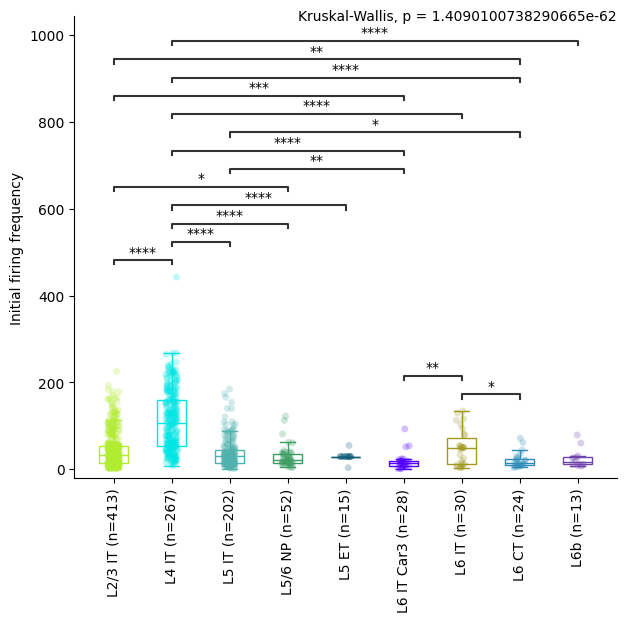

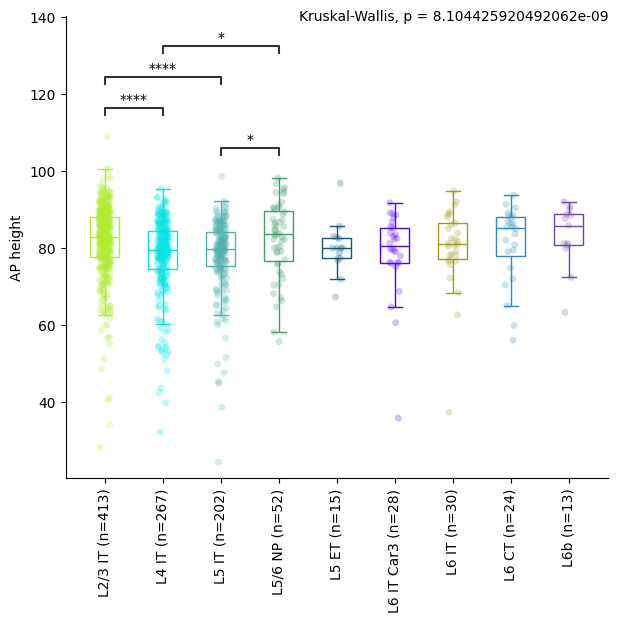

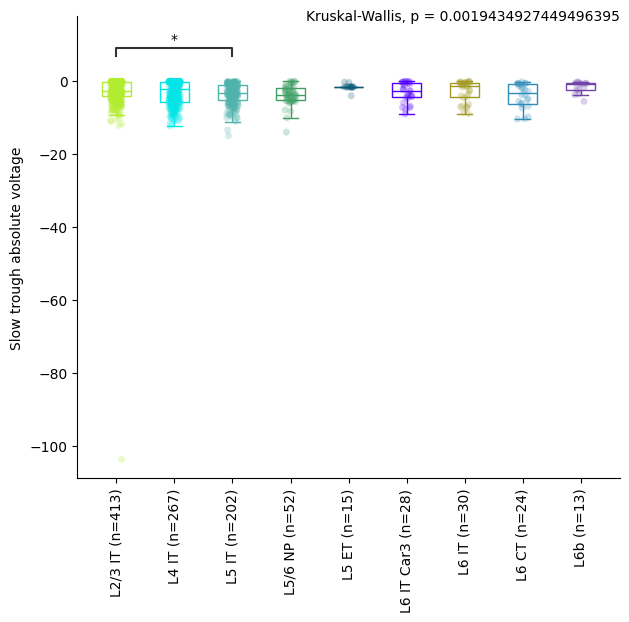

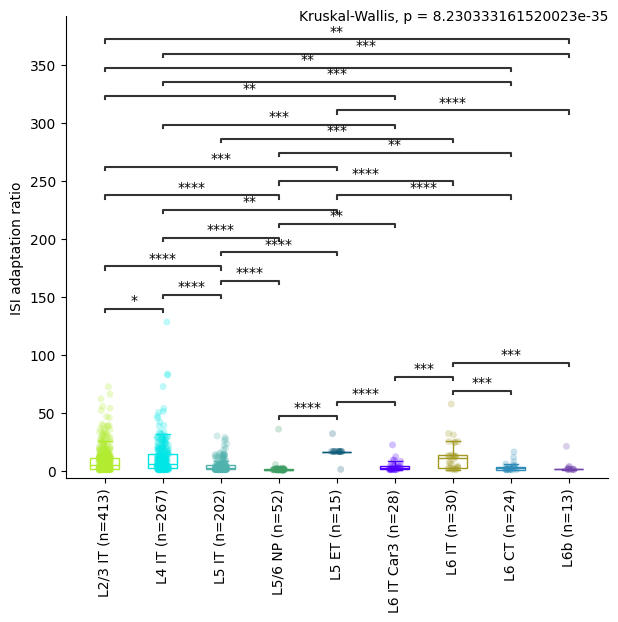

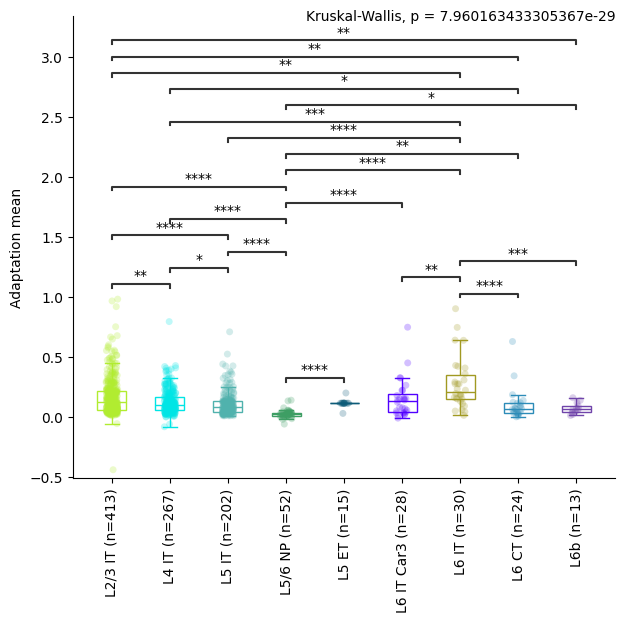

...

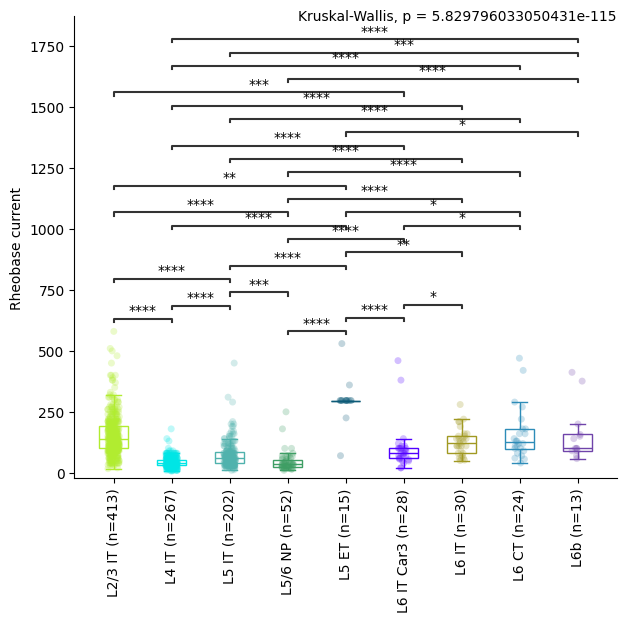

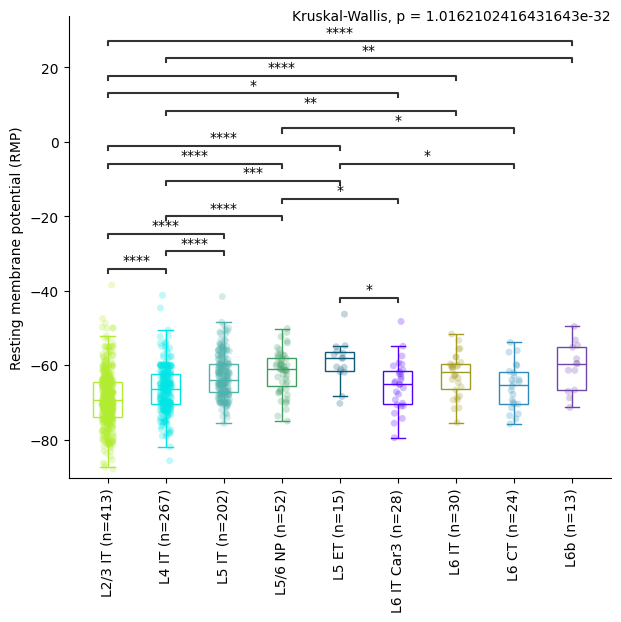

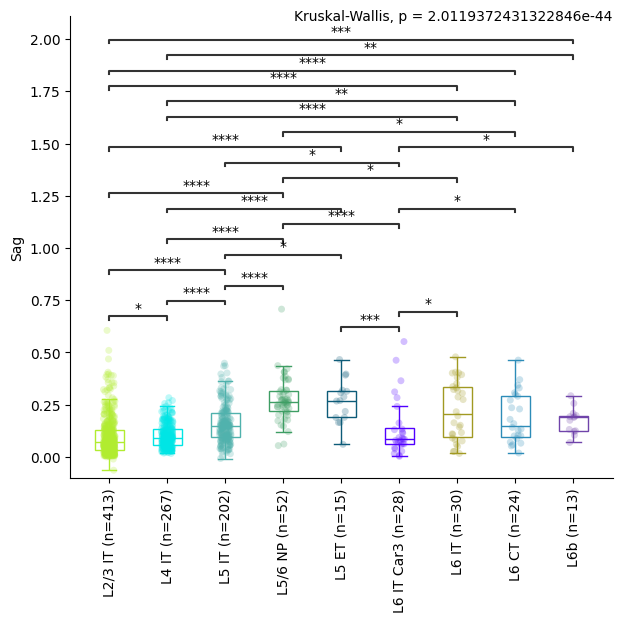

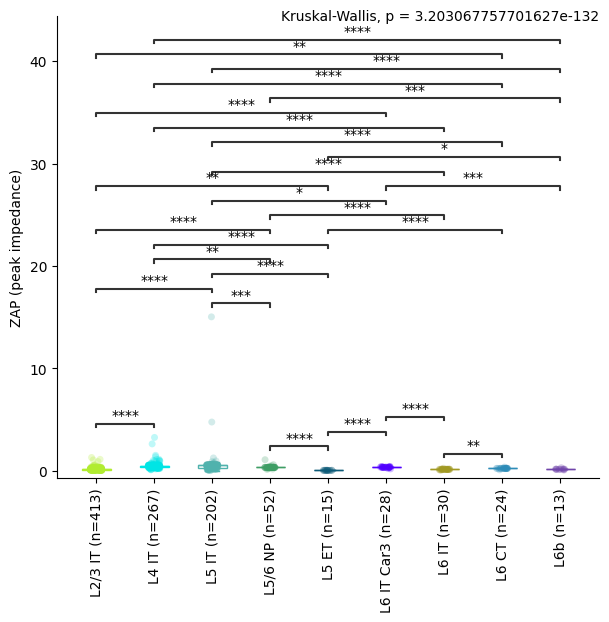

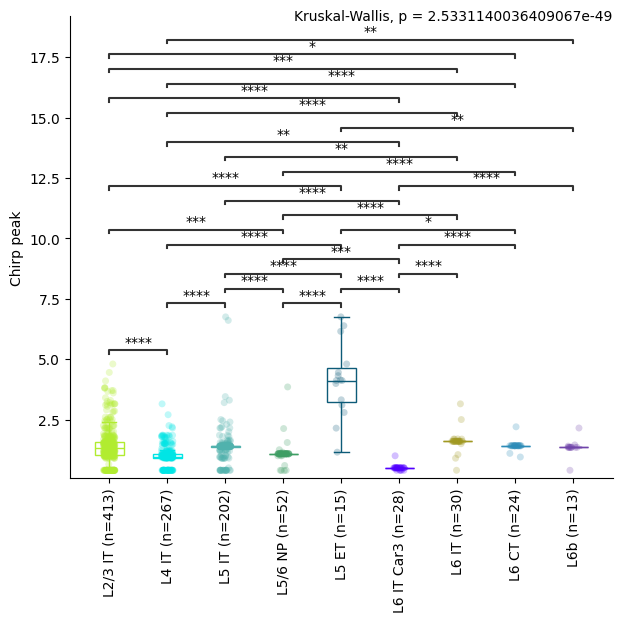

<Figure size 640x480 with 0 Axes>

In [7]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_bySubclass.pdf'

color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



T-type x feature box plots with stats

In [8]:
# ttype x feature stats

x_var = 't_type'  # what to do box plots on
x_var_order = [x for x in group_order[x_var] if x in sorted_clean_data[x_var].tolist()]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

/tmp/ipykernel_1094812/4152111602.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:6.083e-03
L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:6.192e-06
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.075e-05
L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.889e-03
L4 IT_1 vs. L5 IT_6: Custom statistical test, P_val:3.468e-03
L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:5.207e-04
L6 IT_1 vs. L6 CT_3: Custom statistical test, P_val:1.519e-02
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:2.098e-04
L4 IT_1 vs. L5 IT_5: Custom statistical test, P_val:2.311e-03
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:5.607e-04
L4 IT_2 vs. L5 IT_6: Custom statistical test, P_val:9.968e-20
L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:4.309e-02
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:1.452

/tmp/ipykernel_1094812/4152111602.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:2.341e-02
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:7.012e-07
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:2.296e-02
L3 IT_5 vs. L4 IT_2: Custom statistical test, P_val:1.425e-07
L4 IT_4 vs. L5 IT_2: Custom statistical test, P_val:3.967e-03
L5 IT_1 vs. L5/6 NP_1: Custom statistical test, P_val:4.549e-02
L3 IT_10 vs. L4 IT_2: Custom statistical test, P_val:4.545e-03
L5 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:7.903e-03
L3 IT_12 vs. L4 IT_2: Custom statistical test, P_val:3.362e-07
L3 IT_5 vs. L5 IT_2: Custom statistical test, P_val:3.140e-04
L2 IT_2 vs. L4 IT_2: Custom statistical test, P_val:4.049e-02
L3 IT_5 vs. L5 IT_1: Custom statistical test, P_val:2.341e-02
L3 IT_12 vs. L5 IT_5: Custom statistical test, P_val:2.5

/tmp/ipykernel_1094812/4152111602.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.637e-10
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.133e-02
L4 IT_4 vs. L5 IT_6: Custom statistical test, P_val:3.824e-08
L3 IT_5 vs. L4 IT_2: Custom statistical test, P_val:5.406e-04
L3 IT_13 vs. L4 IT_4: Custom statistical test, P_val:2.328e-02
L4 IT_4 vs. L5 IT_5: Custom statistical test, P_val:1.200e-04
L4 IT_3 vs. L5 IT_6: Custom statistical test, P_val:7.994e-03
L4 IT_4 vs. L5 IT_2: Custom statistical test, P_val:6.257e-04
L3 IT_5 vs. L5 IT_6: Custom statistical test, P_val:5.406e-04
L3 IT_5 vs. L5 IT_5: Custom statistical test, P_val:2.680e-02
L4 IT_4 vs. L5 IT_7: Custom statistical test, P_val:2.540e-02
L2 IT_2 vs. L4 IT_4: Custom statistical test, P_val:2.412e-02
L3 IT_12 vs. L5 IT_6: Custom statistical test, P_val:4.491e-02


... (38 outputs left out)

/tmp/ipykernel_1094812/4152111602.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:3.257e-02
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.053e-02
L5/6 NP_4 vs. L5 ET_1: Custom statistical test, P_val:2.886e-03
L5 ET_2 vs. L6 IT Car3_1: Custom statistical test, P_val:3.764e-03
L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:4.719e-02
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:3.656e-02
L3 IT_5 vs. L4 IT_3: Custom statistical test, P_val:2.550e-04
L3 IT_3 vs. L4 IT_4: Custom statistical test, P_val:1.992e-04
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:4.207e-02
L5/6 NP_4 vs. L5 ET_2: Custom statistical test, P_val:1.478e-04
L5 ET_1 vs. L6 IT Car3_1: Custom statistical test, P_val:1.381e-02
L5 ET_2 vs. L6 IT Car3_3: Custom statistical test, P_val:8.972e-07
L6 IT Car3_3 vs. L6 IT_2: Custom statis

/tmp/ipykernel_1094812/4152111602.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.379e-03
L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:4.863e-02
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:4.180e-02
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:7.663e-04
L4 IT_1 vs. L5 IT_6: Custom statistical test, P_val:7.149e-04
L5/6 NP_4 vs. L5 ET_1: Custom statistical test, P_val:1.532e-03
L5 ET_2 vs. L6 IT Car3_1: Custom statistical test, P_val:1.004e-05
L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:9.006e-04
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:2.055e-05
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:1.007e-03
L3 IT_5 vs. L4 IT_3: Custom statistical test, P_val:1.942e-04
L3 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.899e-02
L4 IT_4 vs. L4 IT_1: Custom statistical test, P

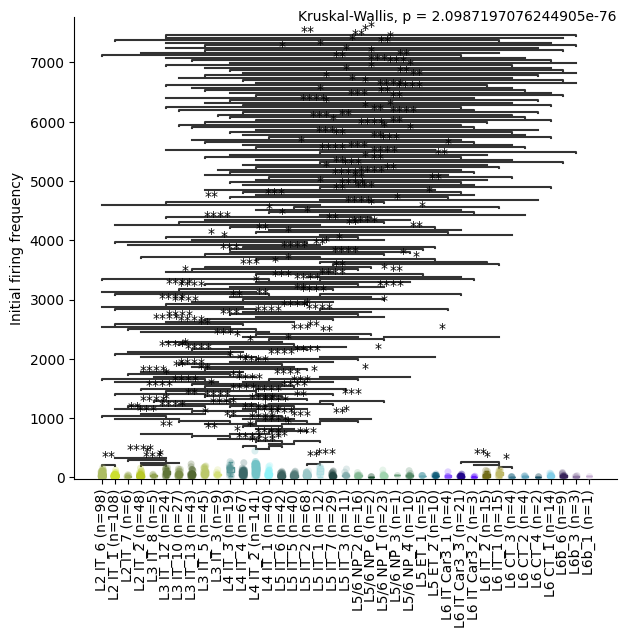

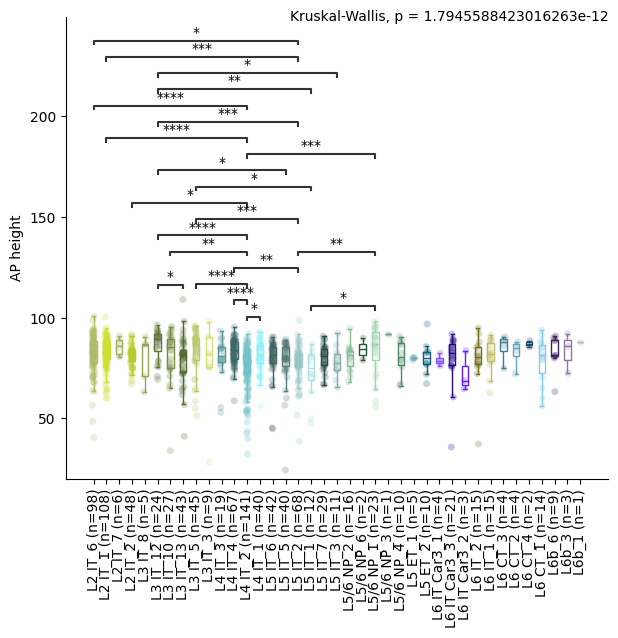

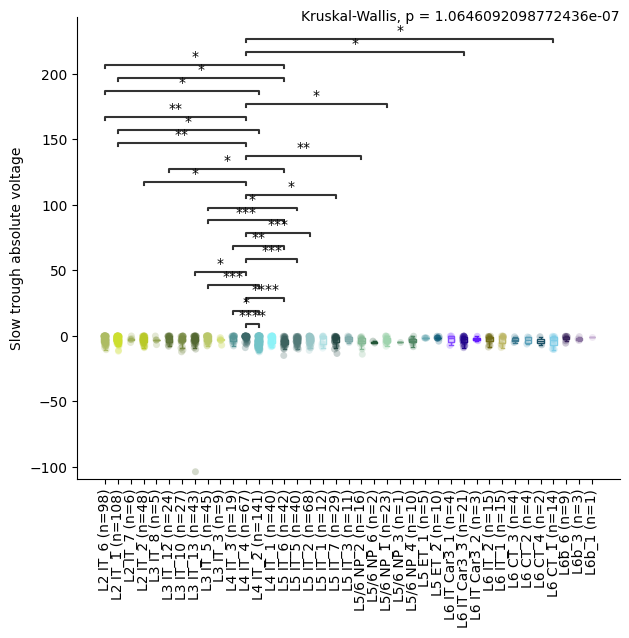

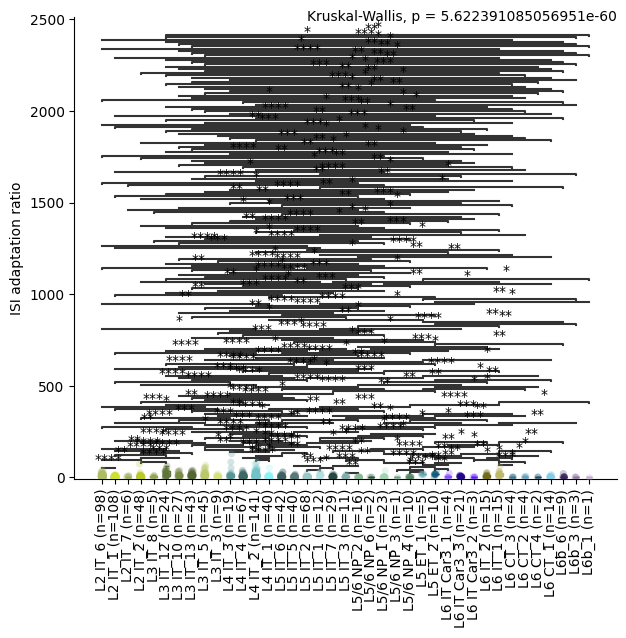

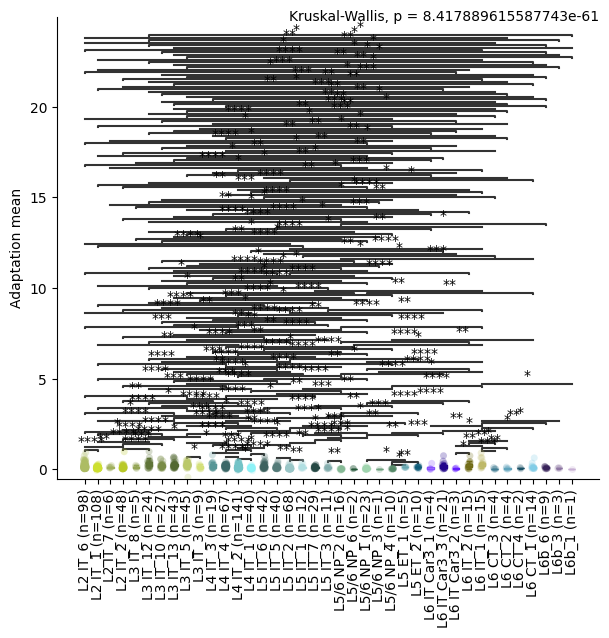

...

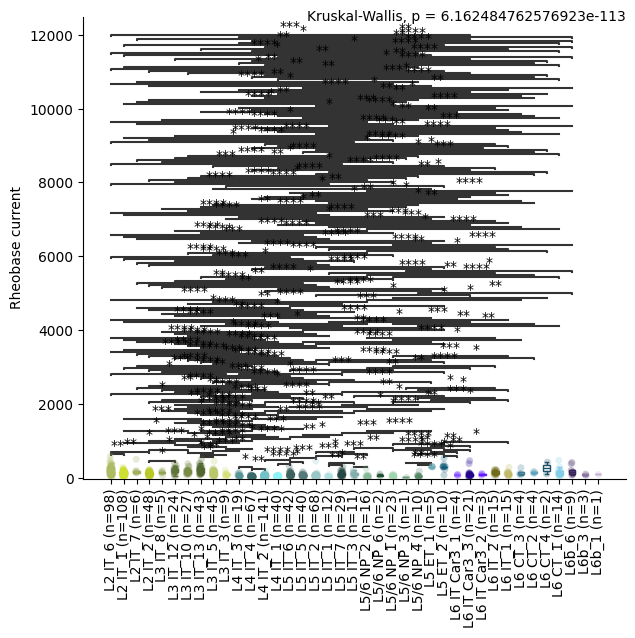

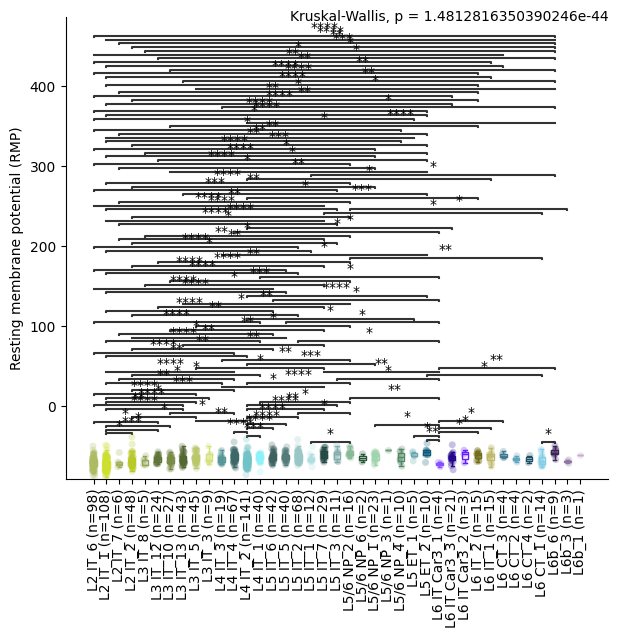

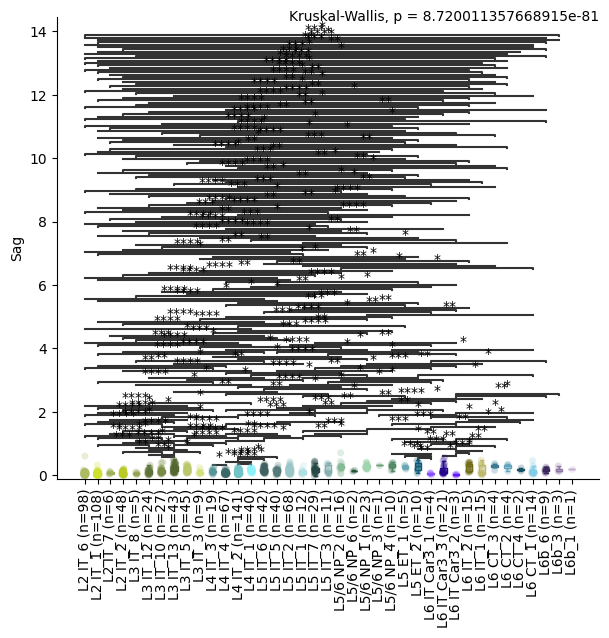

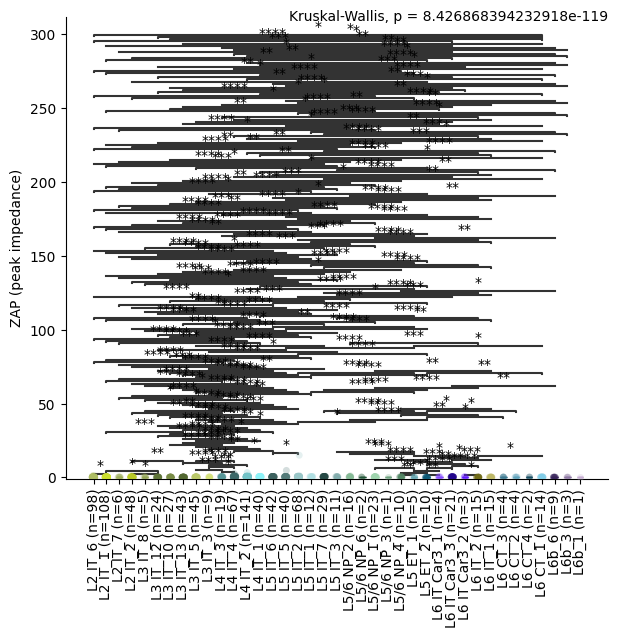

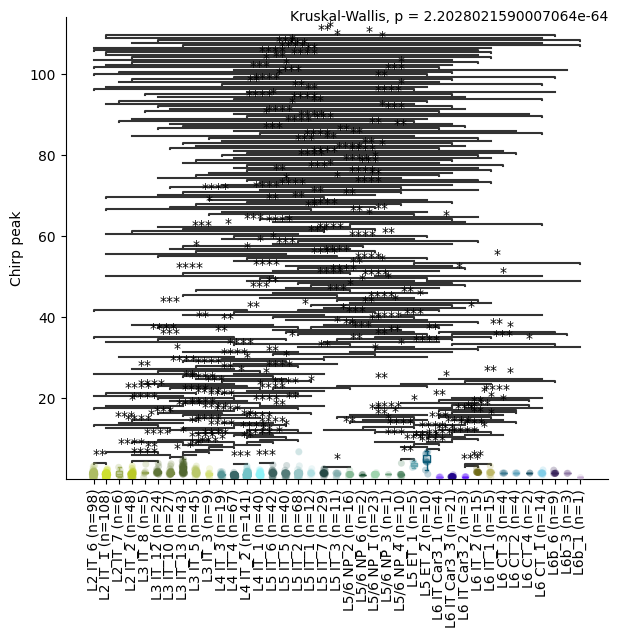

<Figure size 640x480 with 0 Axes>

In [9]:
# ttype x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_byTtype.pdf'
color_palette = color_dict #colors for x_var
hue_var = 't_type' #seperate strip plots into these categories 
hue_color_palette = color_dicts[hue_var] #color palette for hue_var
##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

#######################

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
            # sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=hue_color_palette, alpha=0.25, 
            #                   hue=hue_var, dodge=True, jitter=False) #TODO figure out how to do this with no legend
            # ax.legend_.remove()
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
            format_box_plot(ax) #color line not fill of boxplot


            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



Layer x feature box plots with stats

In [10]:
# subclass x feature stats
x_var = 'layer' #what to do box plots on 
x_var_order = group_order[x_var]

# Kruskal-Wallis H test on all features
kw_pvals = dict()
kw_hvals = dict()
for f in feature_cols:
    # Create a list of groups dynamically
    groups = [sorted_clean_data.loc[sorted_clean_data[x_var] == x][f].dropna() for x in x_var_order]
    
    # Only include groups that have data
    groups = [group for group in groups if not group.empty]

    if len(groups) < 2:
        print(f"Not enough groups with data for feature {f}")
        continue
    try:
        hvalue, pvalue = kruskal(*groups, nan_policy='omit')
        kw_hvals[f] = hvalue
        kw_pvals[f] = pvalue
    except ValueError as e:
        print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

# FDR correction
kw_pvals_list = list(kw_pvals.values())
kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

# Post Hoc Dunn test for significant KW features, with FDR correction
dunn_pvals_fdr = dict()
for k, v in kw_rejected.items():
    if v:  # if null hypothesis was rejected, calculate Dunn post hoc
        dunn_pvals_fdr[k] = posthoc_dunn(sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)


/tmp/ipykernel_1094812/2502680099.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 2 vs. Layer 3: Custom statistical test, P_val:6.259e-17
Layer 3 vs. Layer 4: Custom statistical test, P_val:4.491e-07
Layer 4 vs. Layer 5: Custom statistical test, P_val:1.980e-48
Layer 2 vs. Layer 4: Custom statistical test, P_val:1.306e-55
Layer 3 vs. Layer 5: Custom statistical test, P_val:1.584e-13
Layer 4 vs. Layer 6: Custom statistical test, P_val:1.165e-35
Layer 3 vs. Layer 6: Custom statistical test, P_val:1.121e-13


/tmp/ipykernel_1094812/2502680099.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 3 vs. Layer 4: Custom statistical test, P_val:5.447e-06
Layer 2 vs. Layer 4: Custom statistical test, P_val:5.447e-06
Layer 3 vs. Layer 5: Custom statistical test, P_val:9.294e-05
Layer 4 vs. Layer 6: Custom statistical test, P_val:1.594e-02
Layer 2 vs. Layer 5: Custom statistical test, P_val:1.820e-04


/tmp/ipykernel_1094812/2502680099.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 4 vs. Layer 5: Custom statistical test, P_val:2.852e-02
Layer 3 vs. Layer 5: Custom statistical test, P_val:8.199e-03
Layer 2 vs. Layer 5: Custom statistical test, P_val:1.634e-02


... (38 outputs left out)

/tmp/ipykernel_1094812/2502680099.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 2 vs. Layer 3: Custom statistical test, P_val:4.131e-03
Layer 3 vs. Layer 4: Custom statistical test, P_val:9.970e-66
Layer 4 vs. Layer 5: Custom statistical test, P_val:2.483e-02
Layer 5 vs. Layer 6: Custom statistical test, P_val:3.030e-15
Layer 2 vs. Layer 4: Custom statistical test, P_val:1.597e-61
Layer 3 vs. Layer 5: Custom statistical test, P_val:9.279e-53
Layer 4 vs. Layer 6: Custom statistical test, P_val:2.177e-21
Layer 2 vs. Layer 5: Custom statistical test, P_val:6.420e-47
Layer 3 vs. Layer 6: Custom statistical test, P_val:4.862e-06
Layer 2 vs. Layer 6: Custom statistical test, P_val:1.150e-02


/tmp/ipykernel_1094812/2502680099.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Layer 2 vs. Layer 3: Custom statistical test, P_val:4.624e-23
Layer 3 vs. Layer 4: Custom statistical test, P_val:5.380e-44
Layer 4 vs. Layer 5: Custom statistical test, P_val:3.833e-21
Layer 2 vs. Layer 4: Custom statistical test, P_val:4.613e-06
Layer 3 vs. Layer 5: Custom statistical test, P_val:5.825e-09
Layer 4 vs. Layer 6: Custom statistical test, P_val:2.399e-09
Layer 2 vs. Layer 5: Custom statistical test, P_val:1.661e-06
Layer 3 vs. Layer 6: Custom statistical test, P_val:1.614e-07
Layer 2 vs. Layer 6: Custom statistical test, P_val:7.017e-03


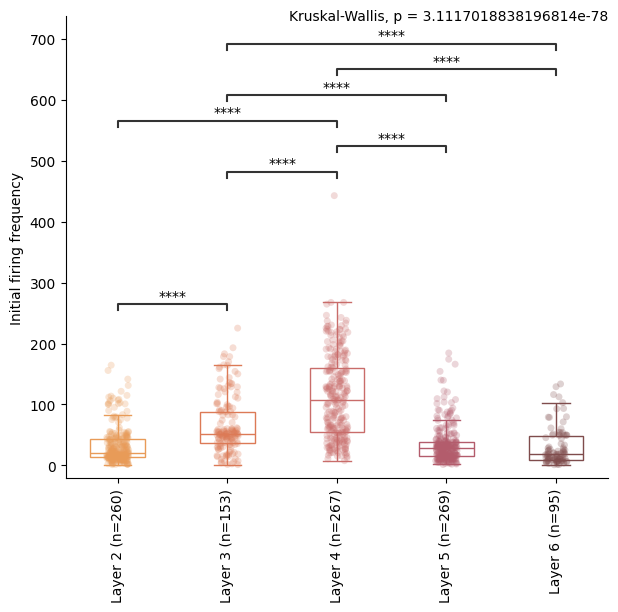

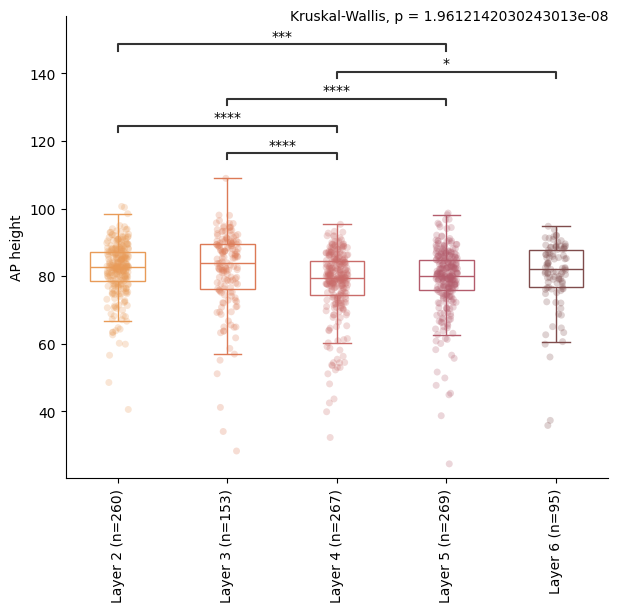

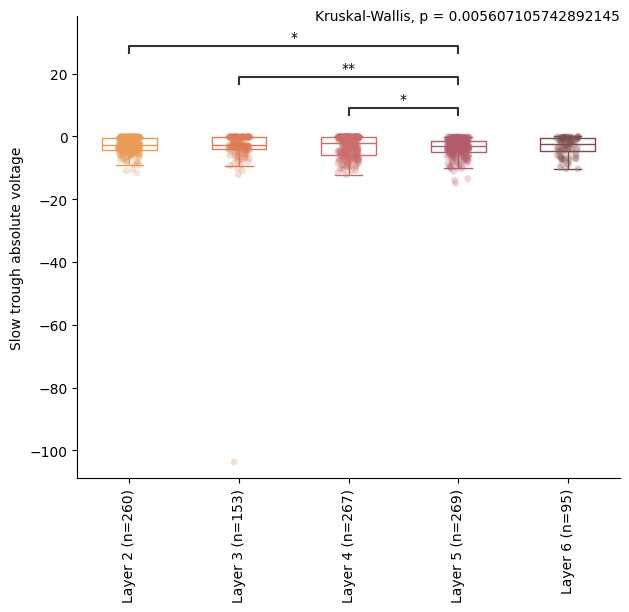

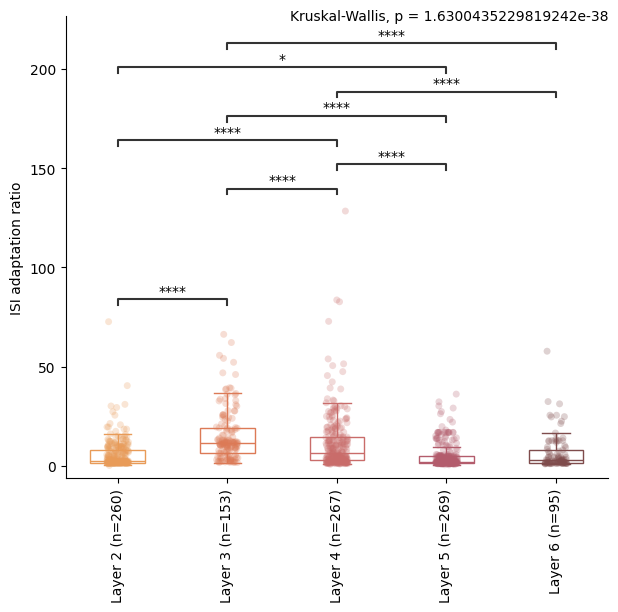

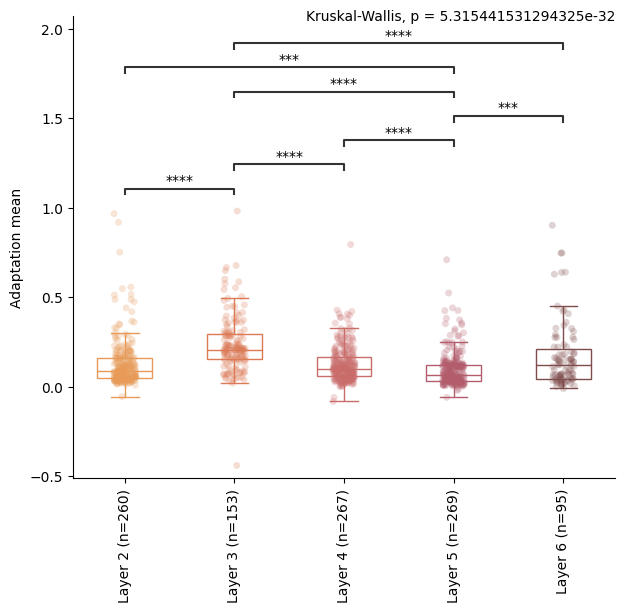

...

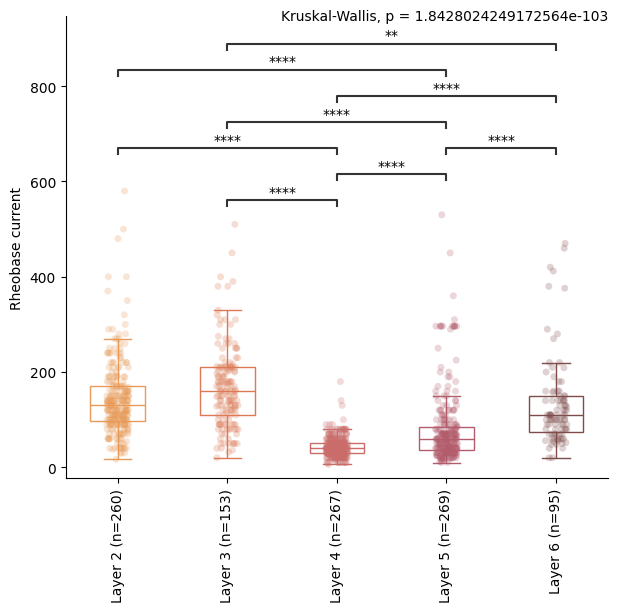

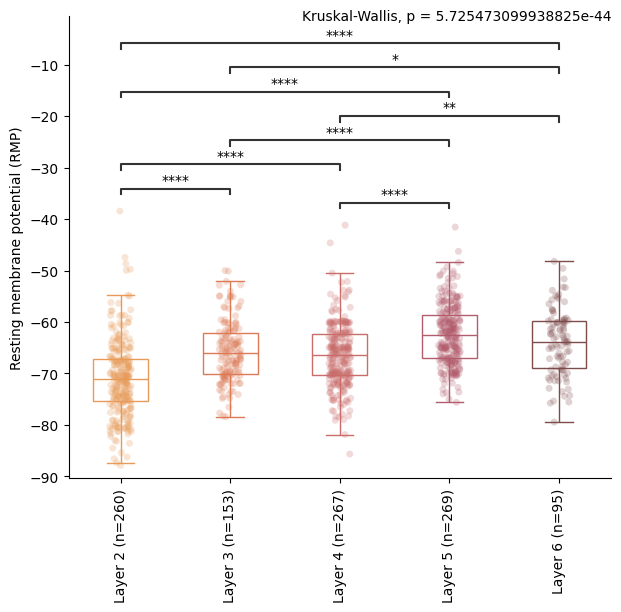

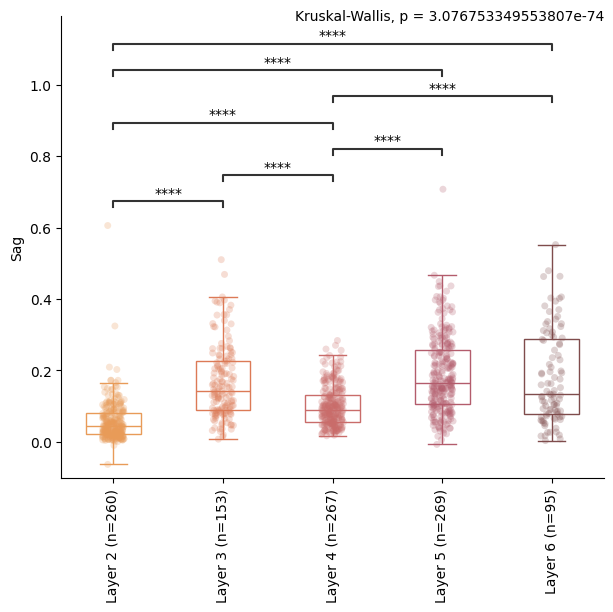

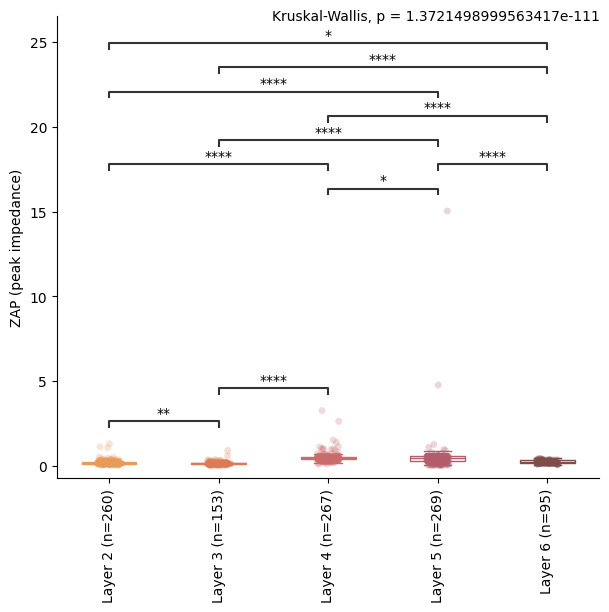

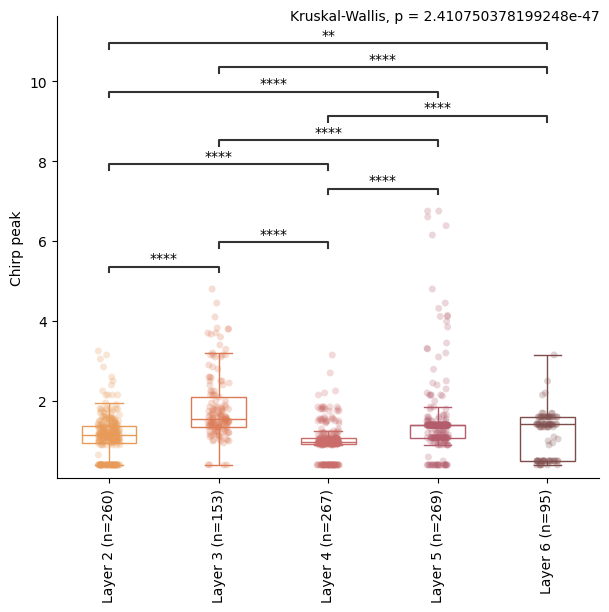

<Figure size 640x480 with 0 Axes>

In [11]:
# subclass x feature box plots

#ADJUST VARS
fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_byLayer.pdf'

hue_var = 'layer' #seperate strip plots into these categories 
color_palette = color_dicts[hue_var] #colors for x_var

#######################

ephys_features = feature_cols.copy()

fig_path = os.path.join(output_dir, fig_name)

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        while ephys_features != []:
            
            #one fig per page, each has page (fig) has 4 rows. 
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
            # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
            
            y_var = ephys_features.pop()
            
            sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25) 
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, ax=ax, order=x_var_order, saturation=1, palette=color_palette, showfliers = False, width=0.5) 
            format_box_plot(ax) #color line not fill of boxplot

            #add num observations per x_var
            nobs = []
            for t in x_var_order:
                n = len(sorted_clean_data[sorted_clean_data[x_var] == t])
                nobs.append(" (n=%s)" % str(n))
            new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
            ax.set_xticklabels(new_x_tick_labels)

            # add stats (KW w/ Dunn post hoc FDR corrected)

            #plot signif dunn fdr p-vals 
            if y_var in dunn_pvals_fdr.keys(): 
                #kw fdr val was signif so there are dunn fdr vals to plot
                
                this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                this_dunn_pvals_fdr[remove] = np.nan
                dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                #set insignificant pvals to nan 
                p_thresh = 0.05 #threshold for plotting p vals 
                dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                #plot bar for all signif fdr corrected dunn p vals 
                pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                if len(pairs): 
                    #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                    p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                    annotator = Annotator(ax=ax, pairs=pairs, data=sorted_clean_data, x=x_var, y=y_var, order=x_var_order)
                    annotator.configure(text_format="star", loc="inside") #text_format="simple"
                    annotator.set_pvalues_and_annotate(p_values)
                    
            #plot Kruskal-Wallis fdr p-vals
            if y_var in kw_pvals_fdr.keys():
                xlimit = ax.get_xlim()
                ylimit = ax.get_ylim()
                p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

            #rotate and format x_var labels 
            ax.set(xlabel=None)
            ax.tick_params(axis='x', rotation=90)
            ax.set_ylabel(y_var.replace("_", " "), rotation=90)
            ax.spines[['right', 'top']].set_visible(False)

            fig.subplots_adjust(wspace=0, hspace=0.0)
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf()
        print()



T-Types within each Layer x feature box plots with stats

In [12]:
#ttypes within each layer

ttype_order = group_order['t_type']

# layer x feature stats
layer_var = 'layer' #what to do box plots on 
layer_var_order = group_order[layer_var]

kw_pvals_fdr_layer = dict()
dunn_pvals_fdr_layer = dict()
for layer in layer_var_order:
    print(layer)
    layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]

    #now run stats on the ttypes in this layer 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in feature_cols:
        # Create a list of groups dynamically
        groups = [layer_data.loc[layer_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(layer_data[layer_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_layer[layer] = kw_pvals_fdr
    dunn_pvals_fdr_layer[layer] = dunn_pvals_fdr

Layer 2
Layer 3
Layer 4
Layer 5


Layer 6


In [13]:
#Save stats
rows = []

for layer in layer_var_order:
    kw_dict = kw_pvals_fdr_layer.get(layer, {})
    dunn_dict = dunn_pvals_fdr_layer.get(layer, {})
    
    for feature, kw_p in kw_dict.items():
        # if Dunn exists for this feature
        if feature in dunn_dict:
            dunn_df = dunn_dict[feature]
            # Flatten Dunn results: pairwise comparisons
            for i in dunn_df.index:
                for j in dunn_df.columns:
                    if i != j:  # skip self-comparison
                        rows.append({
                            'layer': layer,
                            'feature': feature,
                            'kw_pval_fdr': kw_p,
                            'group1': i,
                            'group2': j,
                            'dunn_pval_fdr': dunn_df.loc[i, j]
                        })
        else:
            # No post-hoc, just KW
            rows.append({
                'layer': layer,
                'feature': feature,
                'kw_pval_fdr': kw_p,
                'group1': None,
                'group2': None,
                'dunn_pval_fdr': None
            })

# Convert to DataFrame
stats_df = pd.DataFrame(rows)
stats_df.to_csv(os.path.join(output_dir, r'ephys_feature_box_plot_stats_supertypes_within_layer.csv'), index=False)
stats_df

,layer,feature,kw_pval_fdr,group1,group2,dunn_pval_fdr
0,Layer 2,Chirp peak,0.005183,L2 IT_1,L2 IT_2,0.235676
1,Layer 2,Chirp peak,0.005183,L2 IT_1,L2 IT_6,0.001489
2,Layer 2,Chirp peak,0.005183,L2 IT_1,L2 IT_7,0.235676
3,Layer 2,Chirp peak,0.005183,L2 IT_2,L2 IT_1,0.235676
4,Layer 2,Chirp peak,0.005183,L2 IT_2,L2 IT_6,0.235676
...,...,...,...,...,...,...
5952,Layer 6,ISI adaptation ratio,0.001703,L6b_6,L6b_1,0.570373
5953,Layer 6,ISI adaptation ratio,0.001703,L6b_6,L6b_3,0.710420
5954,Layer 6,Slow trough absolute voltage,0.859259,None,None,NaN
5955,Layer 6,AP height,0.723971,None,None,NaN


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:1.685e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.078e-08
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:4.916e-04


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:1.866e-11
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:1.672e-03


... (18 outputs left out)

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:6.266e-06
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:4.117e-05


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:1.489e-03


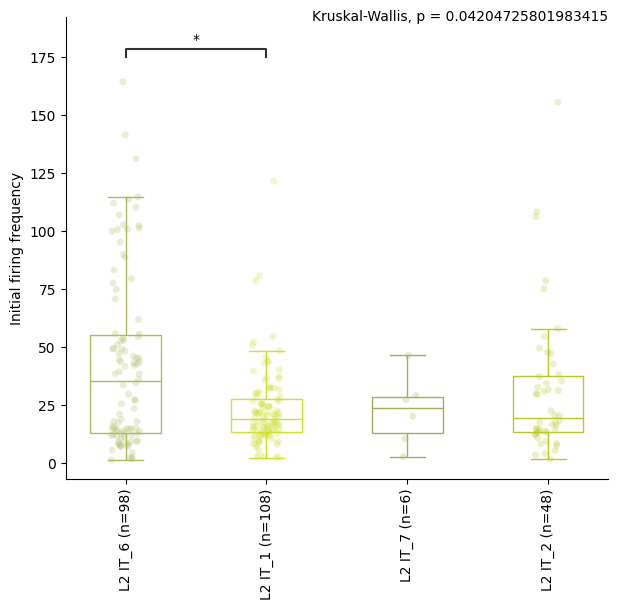

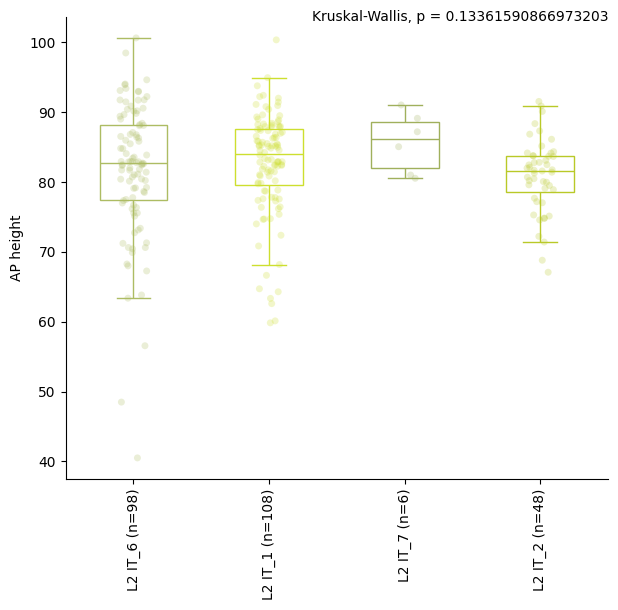

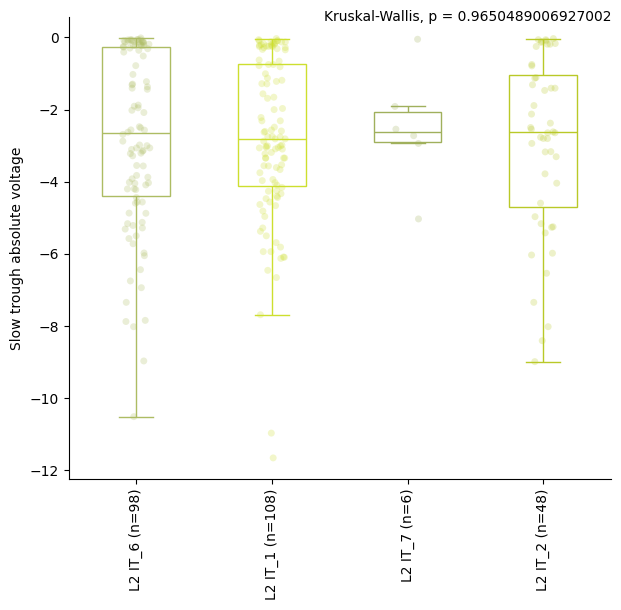

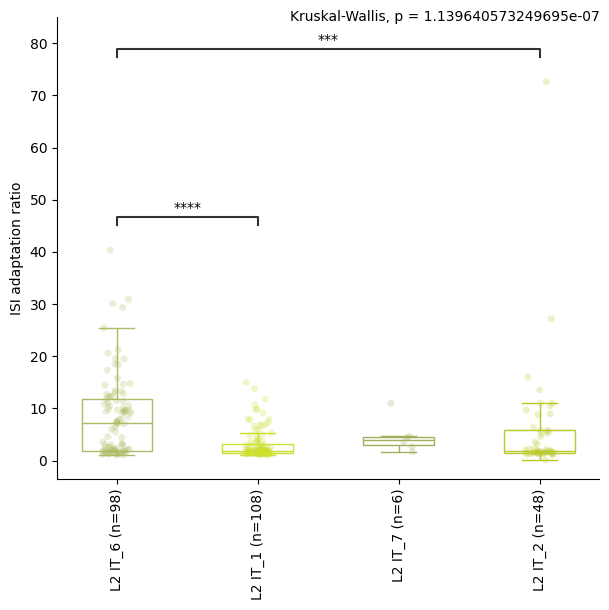

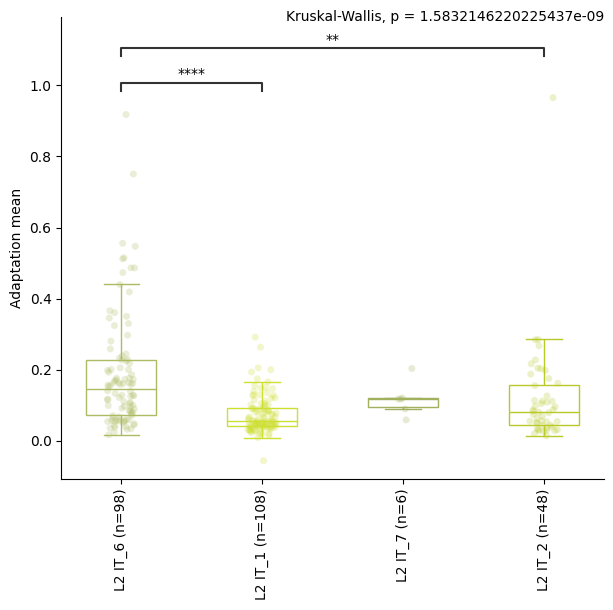

...

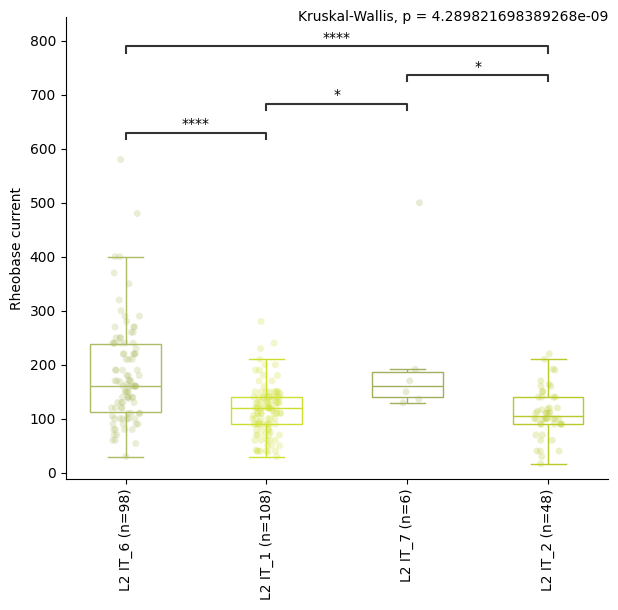

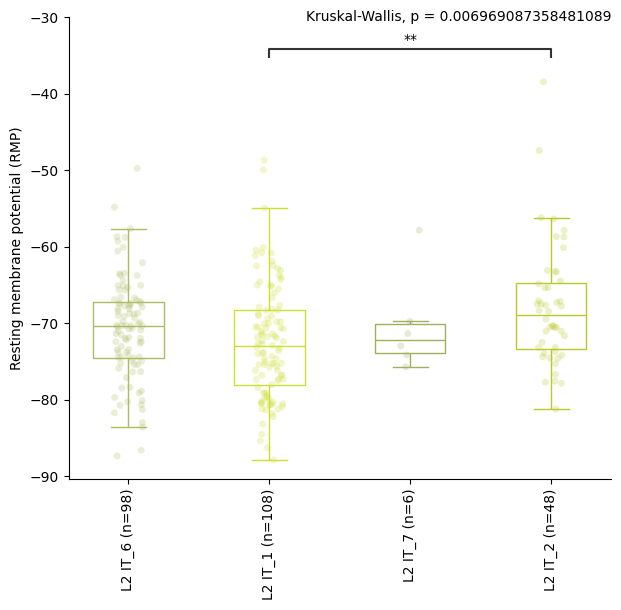

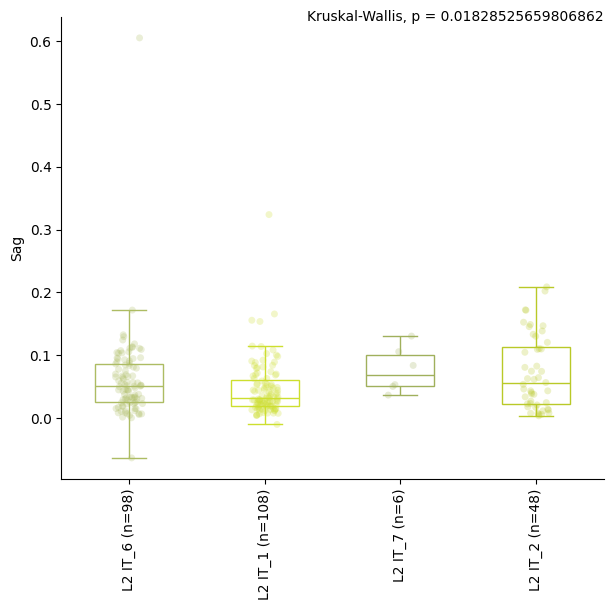

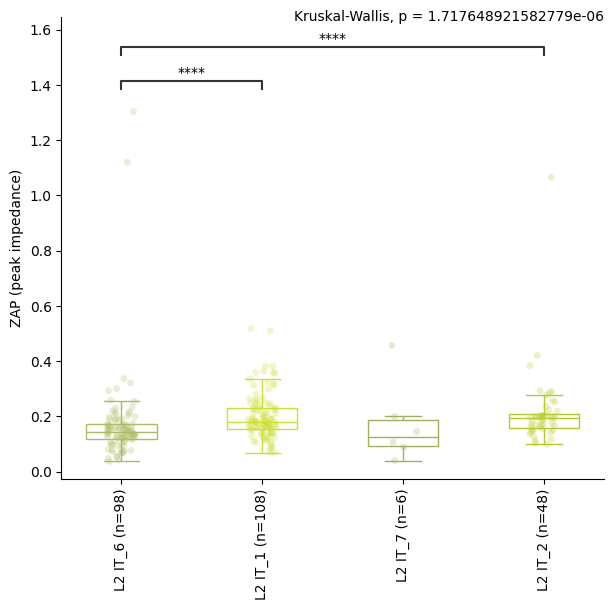

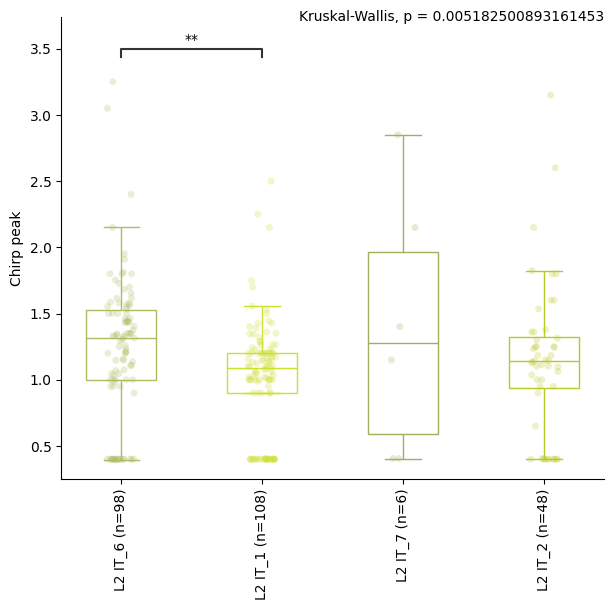

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:1.823e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_5 vs. L3 IT_3: Custom statistical test, P_val:2.661e-02
L3 IT_12 vs. L3 IT_3: Custom statistical test, P_val:2.661e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:7.173e-04
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:4.288e-03
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:4.288e-03


... (15 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:4.073e-04
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:8.459e-04
L3 IT_10 vs. L3 IT_3: Custom statistical test, P_val:4.368e-02
L3 IT_12 vs. L3 IT_5: Custom statistical test, P_val:4.368e-02
L3 IT_12 vs. L3 IT_3: Custom statistical test, P_val:1.797e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:8.661e-04
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:8.661e-04
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:2.659e-04
L3 IT_12 vs. L3 IT_3: Custom statistical test, P_val:1.972e-02


<Figure size 640x480 with 0 Axes>

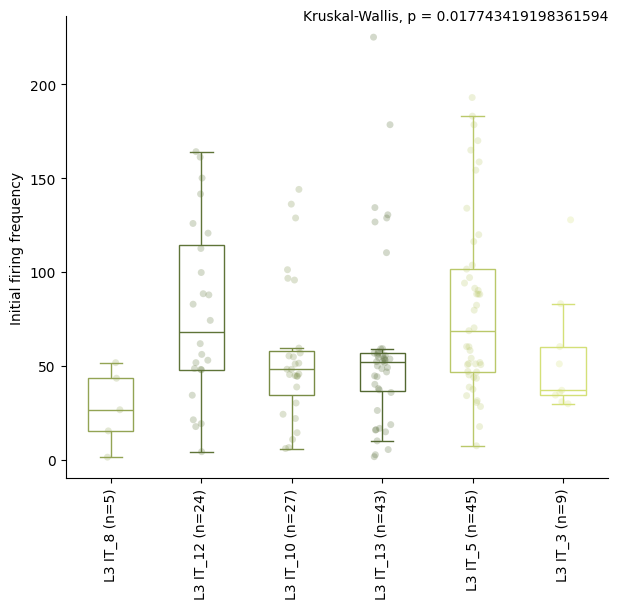

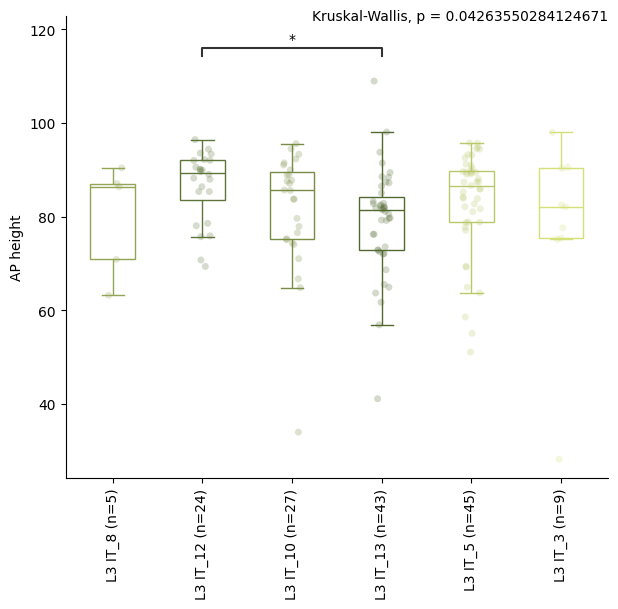

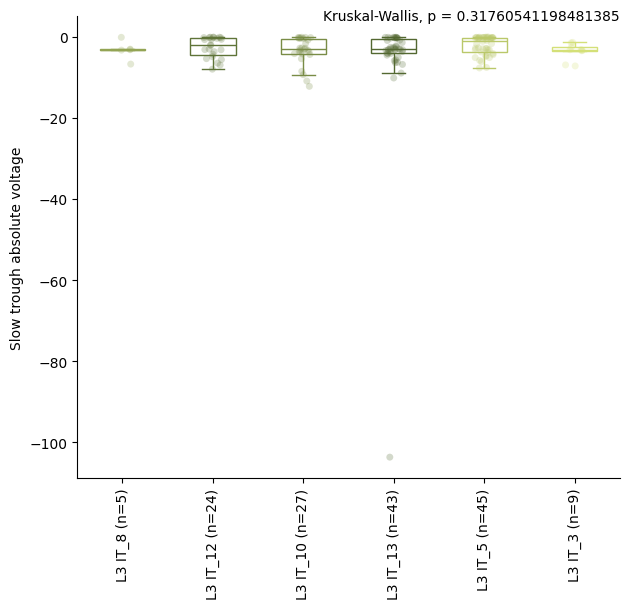

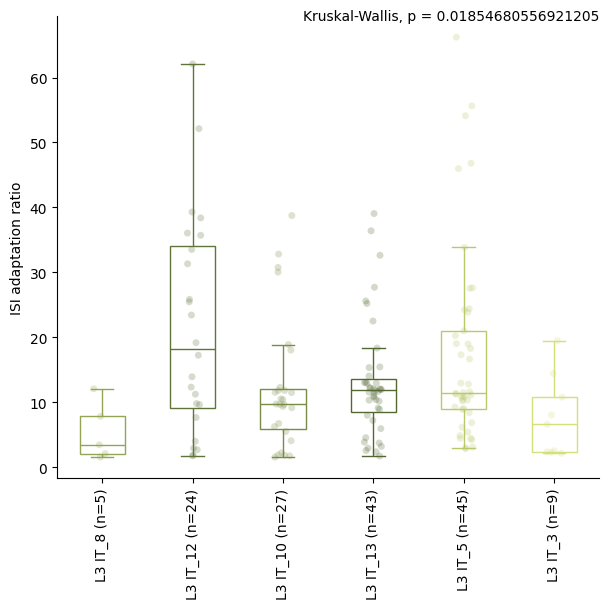

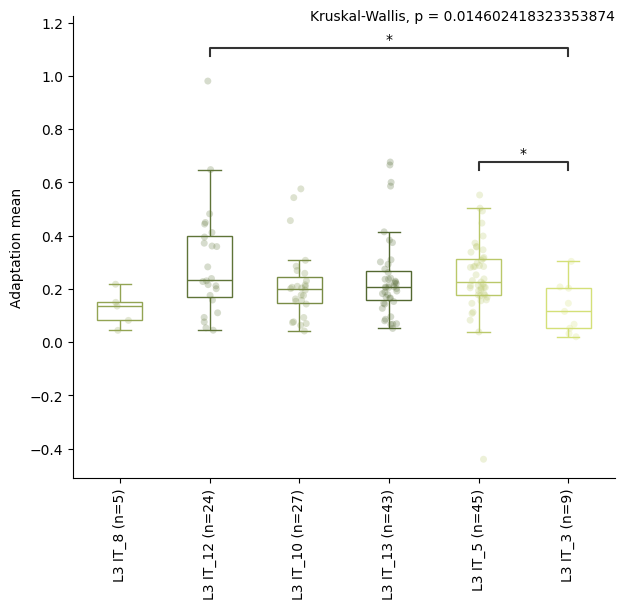

...

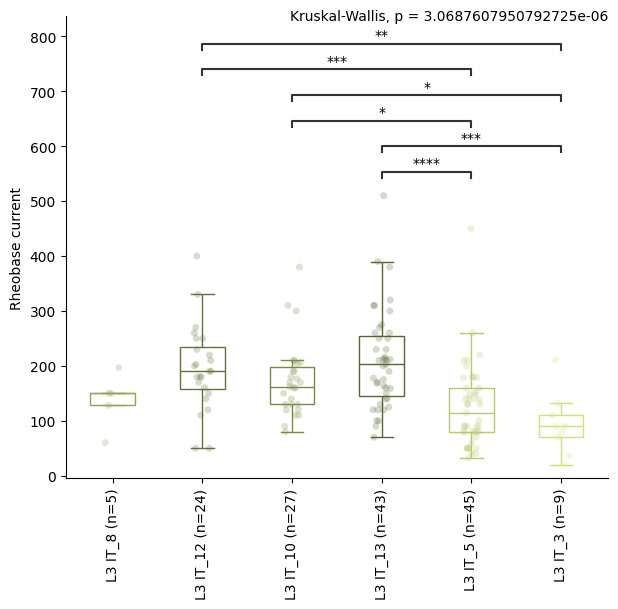

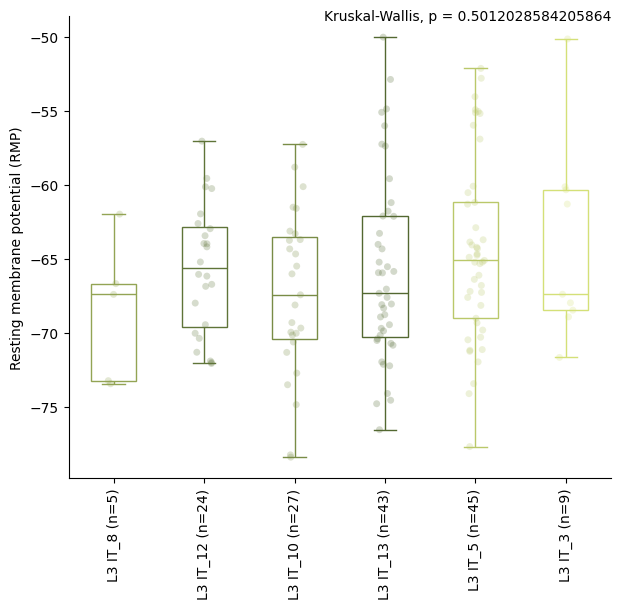

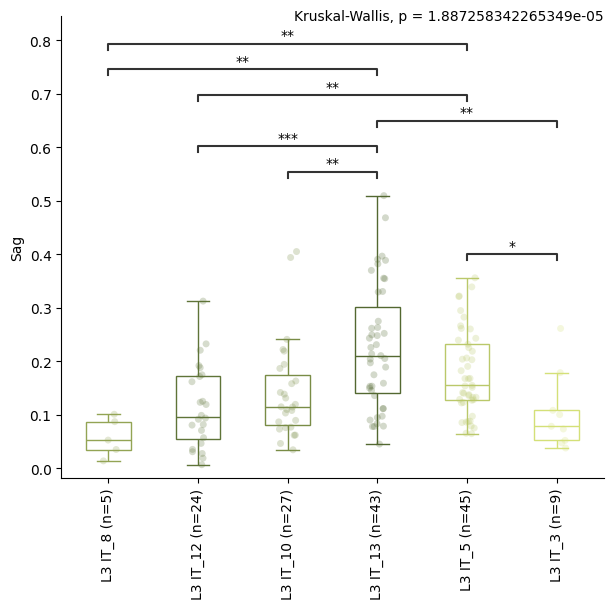

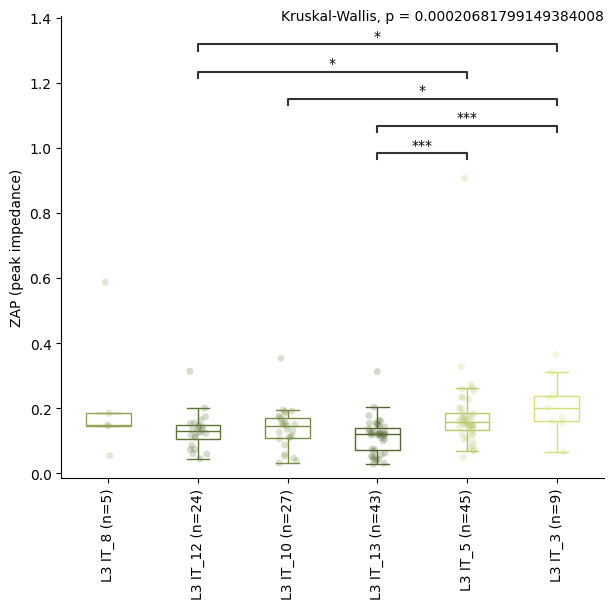

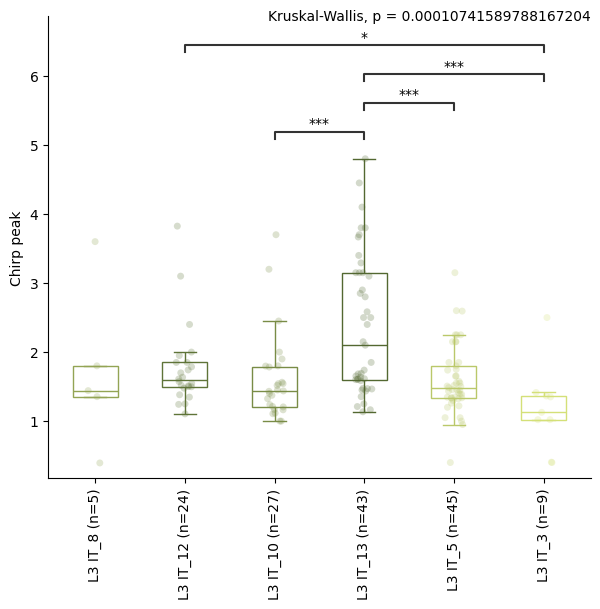

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.157e-12
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.301e-13
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.491e-04
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:7.251e-05


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:8.821e-04
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.169e-09
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.748e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:4.511e-02
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:8.335e-08
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:3.648e-03
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:4.511e-02


... (31 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.717e-07
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:1.107e-05
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:1.512e-02
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:2.447e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:3.890e-08
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.921e-03
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:2.830e-04


<Figure size 640x480 with 0 Axes>

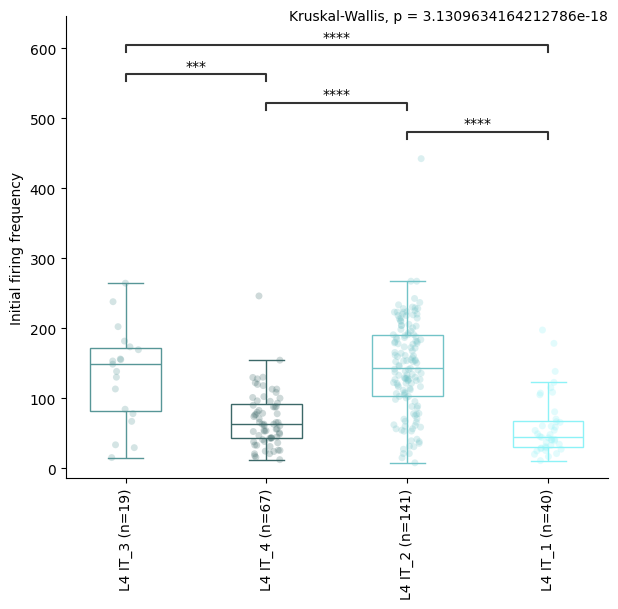

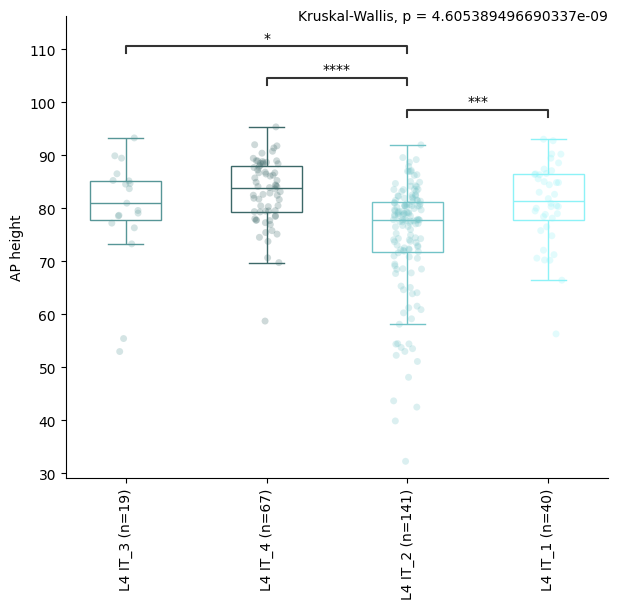

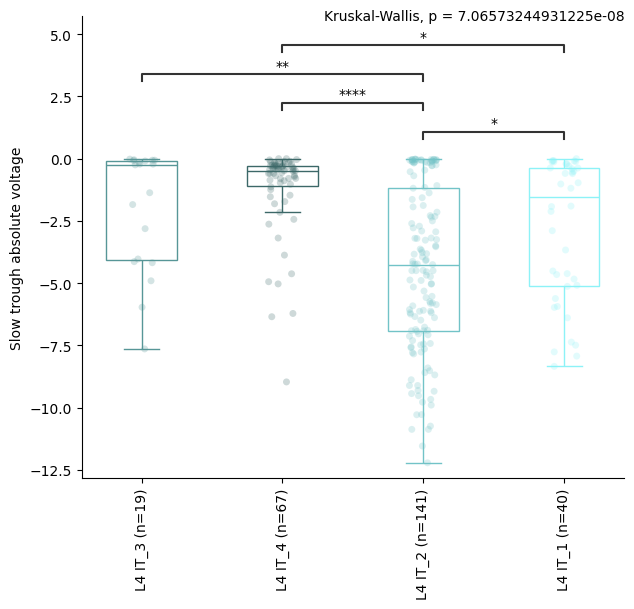

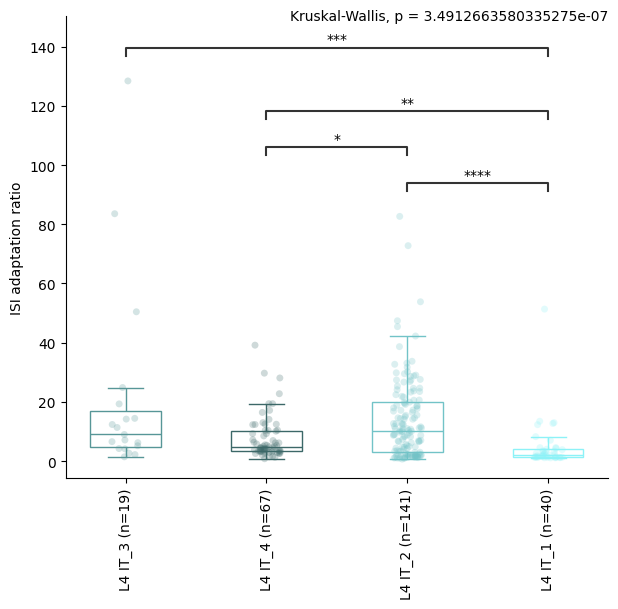

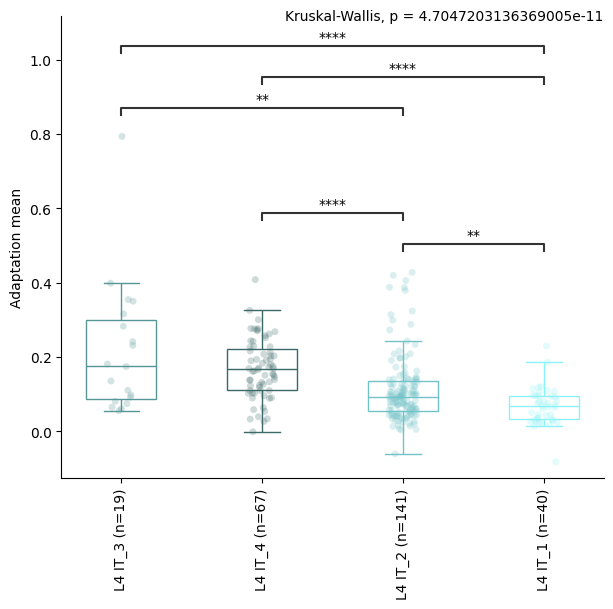

...

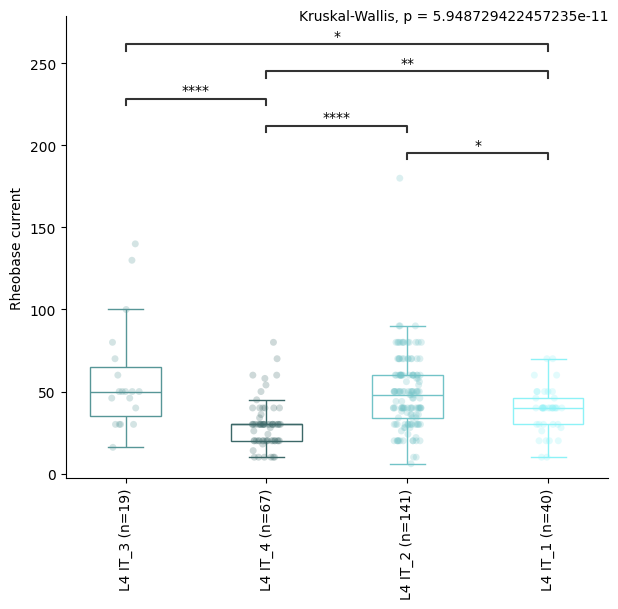

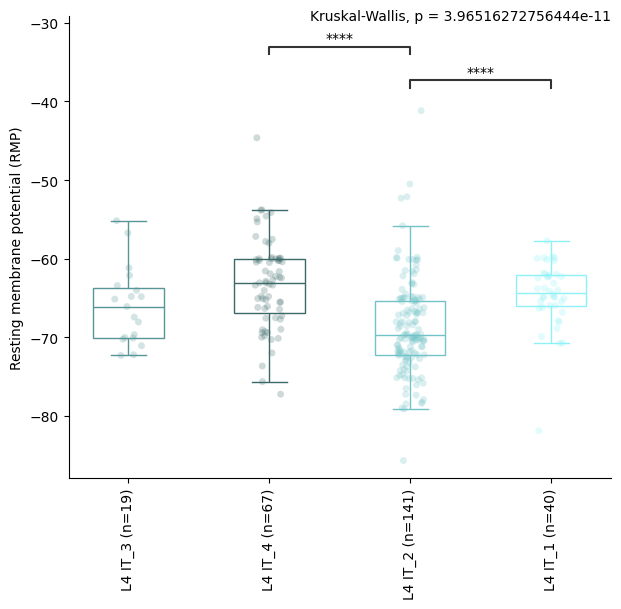

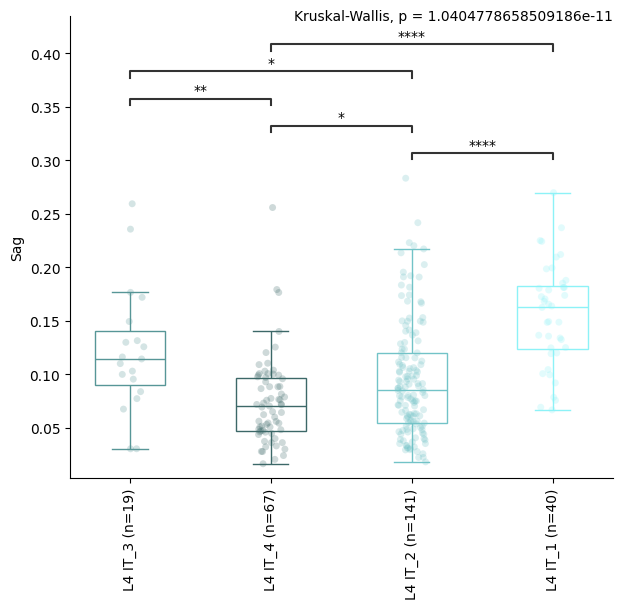

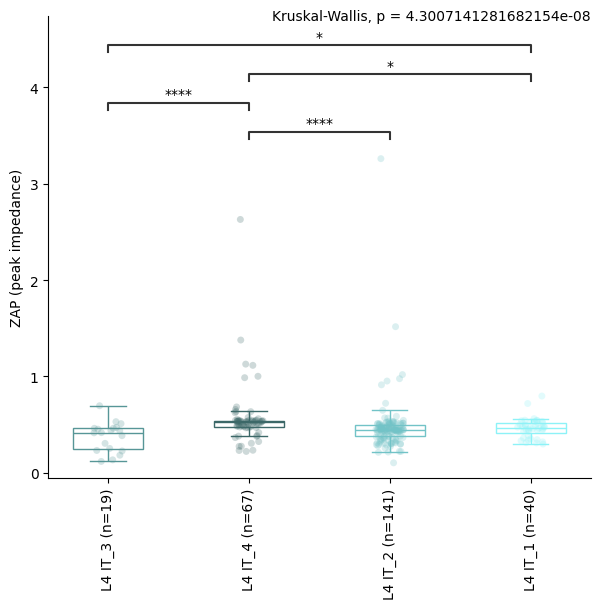

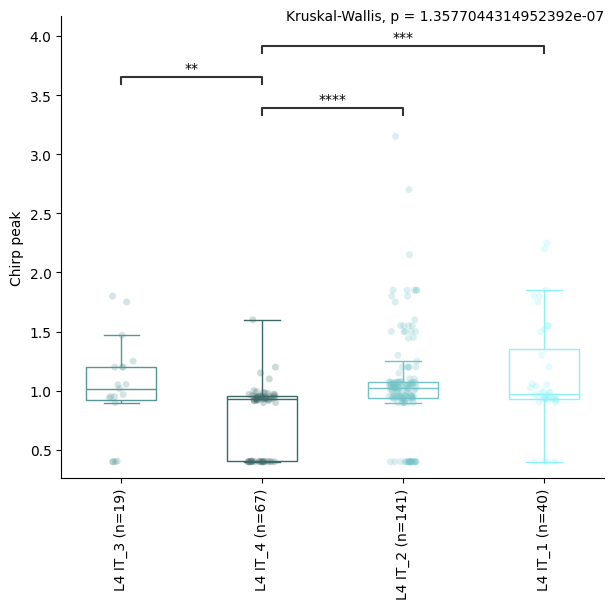

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:1.119e-02
L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:1.377e-03
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:1.377e-03
L5 IT_6 vs. L5 IT_1: Custom statistical test, P_val:1.377e-03
L5 IT_1 vs. L5/6 NP_2: Custom statistical test, P_val:4.213e-03
L5 IT_1 vs. L5/6 NP_6: Custom statistical test, P_val:1.569e-02
L5 IT_1 vs. L5/6 NP_1: Custom statistical test, P_val:1.377e-03


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:2.263e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.323e-04
L5 IT_3 vs. L5/6 NP_2: Custom statistical test, P_val:8.032e-05
L5/6 NP_4 vs. L5 ET_1: Custom statistical test, P_val:3.418e-04
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:1.704e-02
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:3.418e-04
L5 IT_2 vs. L5 IT_7: Custom statistical test, P_val:2.525e-02
L5 IT_7 vs. L5/6 NP_2: Custom statistical test, P_val:8.963e-06
L5/6 NP_3 vs. L5 ET_1: Custom statistical test, P_val:3.484e-02
L5/6 NP_4 vs. L5 ET_2: Custom statistical test, P_val:8.032e-05
L5 IT_2 vs. L5 IT_3: Custom statistical test, P_val:4.298e-02
L5/6 NP_1 vs. L5 ET_1: Custom statistical test, P_val:5.906e-06
L5 IT_3 vs. L5/6 NP_1: Custom statistical test, P_val:4.607e-04
L5 IT_1 vs. L5/6 NP_2: Custom statistical test, P_

... (31 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_1 vs. L5 ET_2: Custom statistical test, P_val:6.777e-03
L5 IT_7 vs. L5/6 NP_1: Custom statistical test, P_val:7.966e-03
L5 IT_2 vs. L5/6 NP_2: Custom statistical test, P_val:2.794e-02
L5/6 NP_2 vs. L5 ET_1: Custom statistical test, P_val:4.418e-02
L5 IT_3 vs. L5 ET_1: Custom statistical test, P_val:7.966e-03
L5 IT_2 vs. L5/6 NP_1: Custom statistical test, P_val:2.356e-03
L5/6 NP_2 vs. L5 ET_2: Custom statistical test, P_val:5.087e-03
L5 IT_7 vs. L5/6 NP_4: Custom statistical test, P_val:2.381e-02
L5 IT_3 vs. L5 ET_2: Custom statistical test, P_val:5.713e-04
L5 IT_7 vs. L5 ET_1: Custom statistical test, P_val:2.398e-04
L5 IT_1 vs. L5 ET_1: Custom statistical test, P_val:3.085e-03
L5 IT_7 vs. L5 ET_2: Custom statistical test, P_val:3.700e-07
L5 IT_2 vs. L5/6 NP_4: Custom statistical test, P_

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_4 vs. L5 ET_1: Custom statistical test, P_val:1.120e-04
L5 IT_7 vs. L5/6 NP_2: Custom statistical test, P_val:8.383e-04
L5/6 NP_4 vs. L5 ET_2: Custom statistical test, P_val:1.048e-05
L5/6 NP_1 vs. L5 ET_1: Custom statistical test, P_val:1.048e-05
L5 IT_1 vs. L5/6 NP_2: Custom statistical test, P_val:2.851e-03
L5/6 NP_1 vs. L5 ET_2: Custom statistical test, P_val:7.101e-08
L5 IT_7 vs. L5/6 NP_1: Custom statistical test, P_val:9.865e-05
L5 IT_2 vs. L5/6 NP_2: Custom statistical test, P_val:1.213e-02
L5/6 NP_6 vs. L5 ET_1: Custom statistical test, P_val:5.050e-03
L5 IT_1 vs. L5/6 NP_1: Custom statistical test, P_val:8.900e-04
L5/6 NP_2 vs. L5 ET_1: Custom statistical test, P_val:2.832e-05
L5 IT_5 vs. L5/6 NP_2: Custom statistical test, P_val:3.342e-02
L5/6 NP_6 vs. L5 ET_2: Custom statistica

<Figure size 640x480 with 0 Axes>

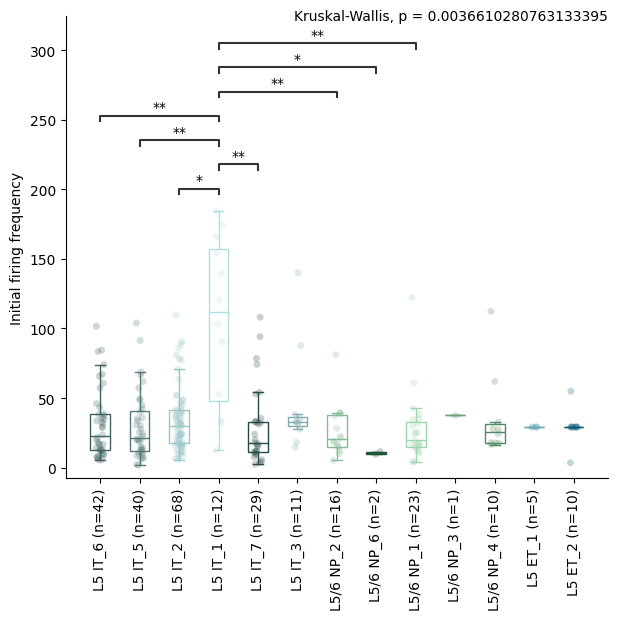

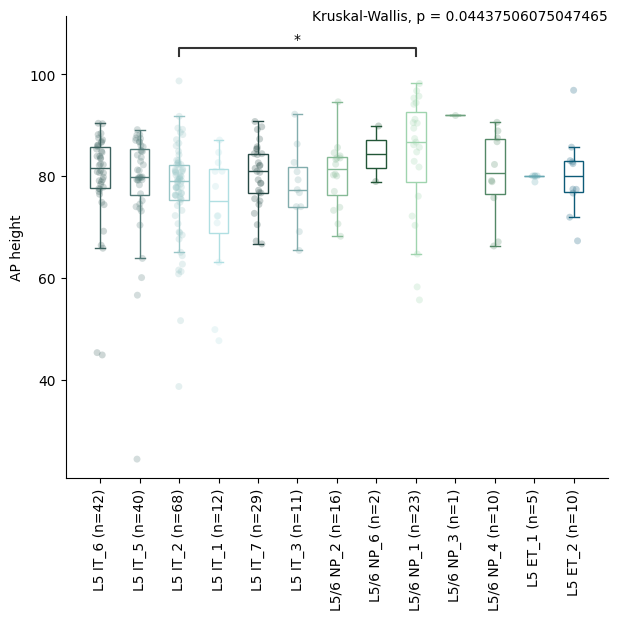

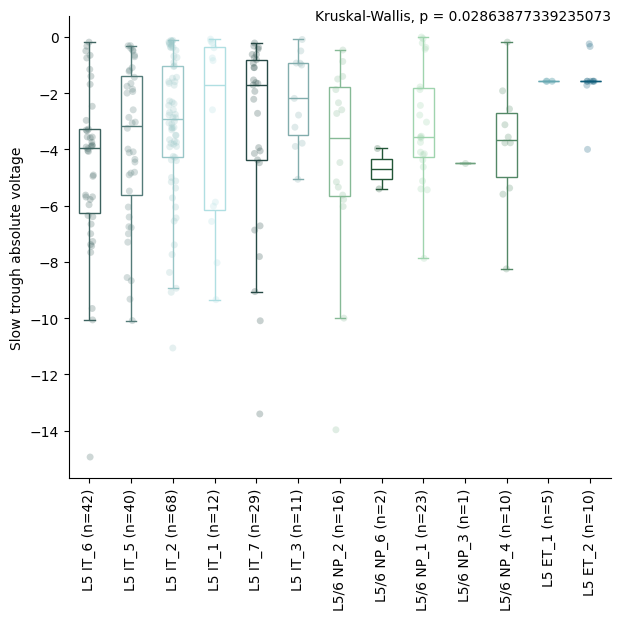

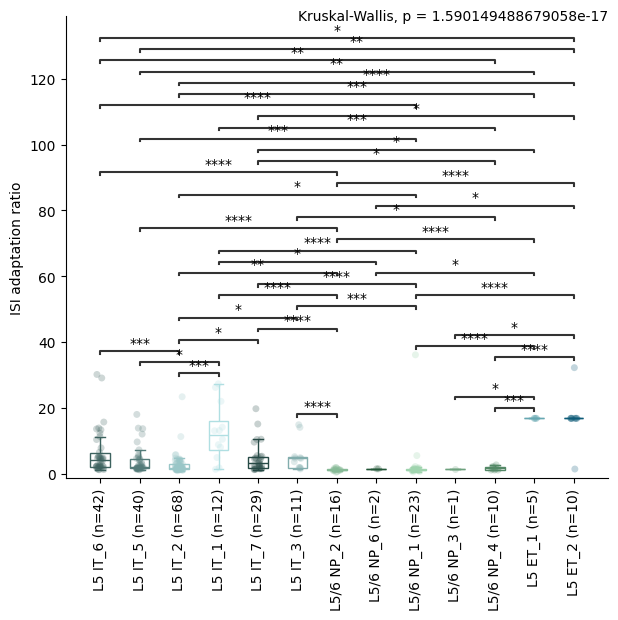

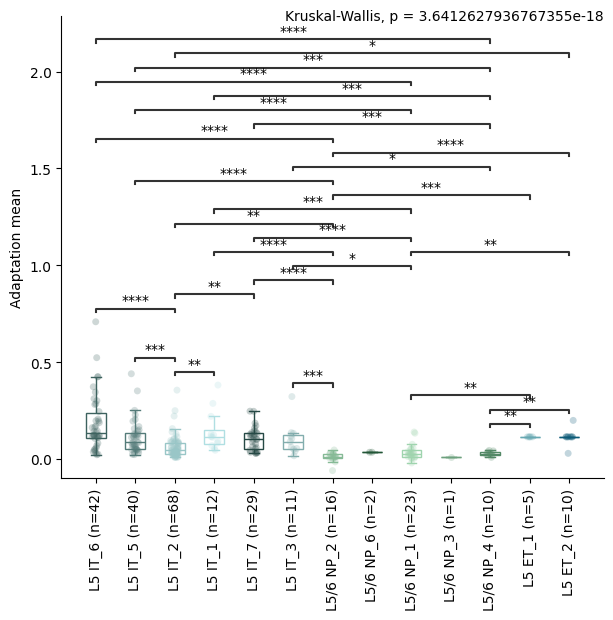

...

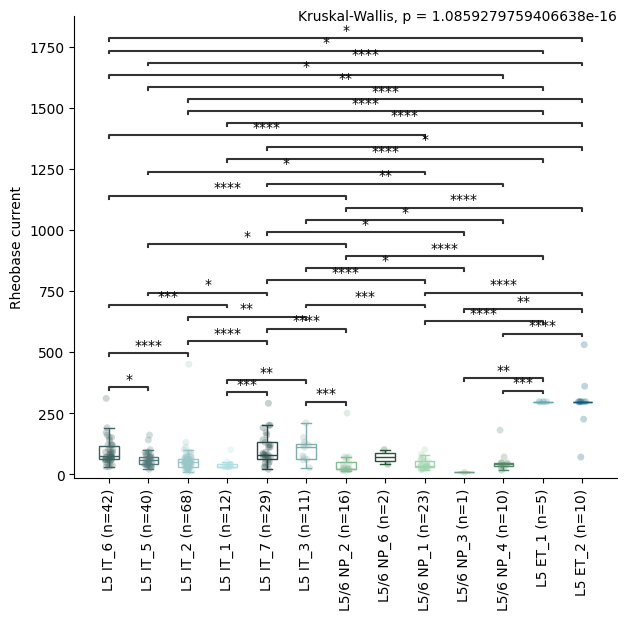

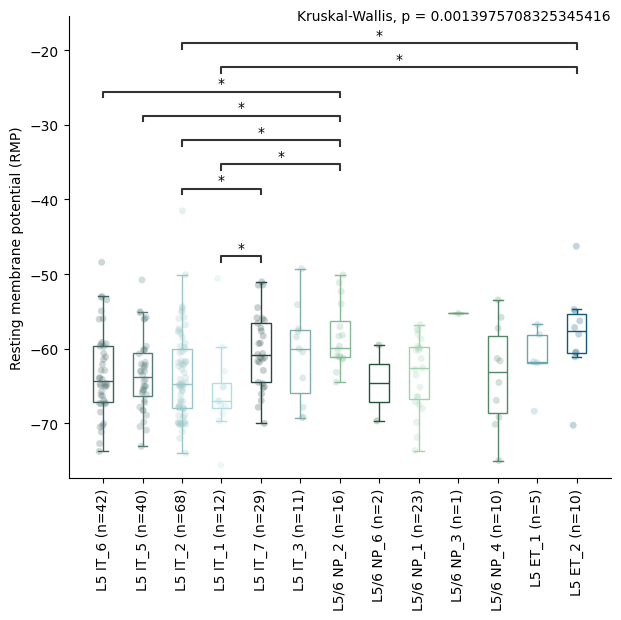

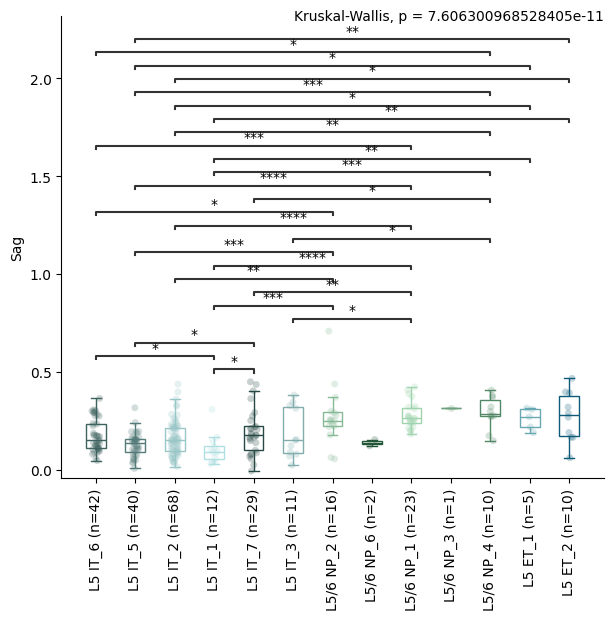

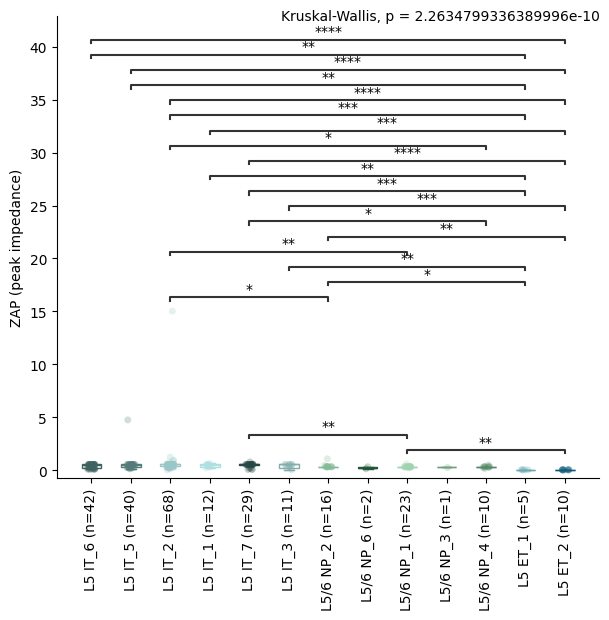

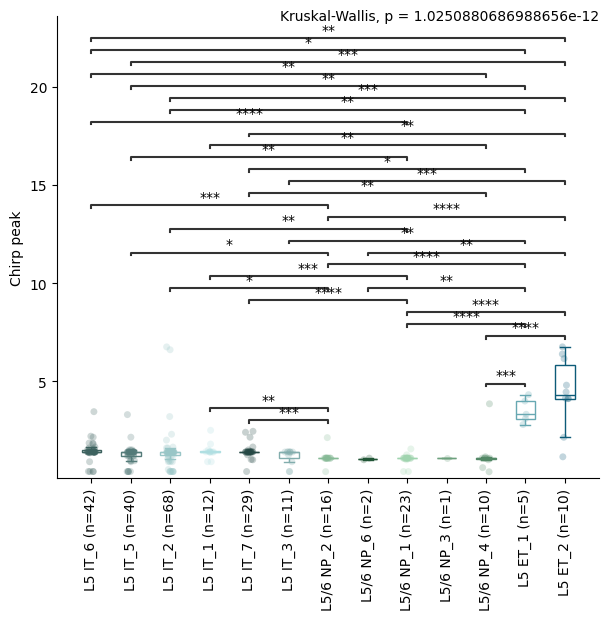

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_1 vs. L6 CT_3: Custom statistical test, P_val:5.282e-03
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:3.111e-02
L6 IT Car3_1 vs. L6 IT_1: Custom statistical test, P_val:4.552e-02
L6 IT_1 vs. L6b_6: Custom statistical test, P_val:3.111e-02
L6 IT_1 vs. L6b_3: Custom statistical test, P_val:4.888e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_1 vs. L6 CT_3: Custom statistical test, P_val:1.497e-02
L6 IT_1 vs. L6 CT_2: Custom statistical test, P_val:3.186e-02
L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:3.718e-02
L6 IT_2 vs. L6 CT_3: Custom statistical test, P_val:3.718e-02
L6 IT Car3_1 vs. L6 IT_1: Custom statistical test, P_val:3.718e-02
L6 IT_1 vs. L6b_6: Custom statistical test, P_val:3.502e-02


/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:2.718e-02
L6 IT Car3_3 vs. L6 IT_2: Custom statistical test, P_val:4.281e-03
L6 IT Car3_2 vs. L6 CT_3: Custom statistical test, P_val:1.579e-02
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:7.414e-04
L6 IT Car3_2 vs. L6 CT_2: Custom statistical test, P_val:3.318e-02
L6 IT Car3_3 vs. L6 CT_3: Custom statistical test, P_val:4.133e-03
L6 IT Car3_3 vs. L6 CT_2: Custom statistical test, P_val:1.579e-02
L6 IT Car3_2 vs. L6 CT_1: Custom statistical test, P_val:2.423e-02
L6 IT Car3_3 vs. L6 CT_1: Custom statistical test, P_val:7.414e-04
L6 IT Car3_2 vs. L6b_6: Custom statistical test, P_val:2.964e-02
L6 IT Car3_3 vs. L6b_6: Custom statistical test, P_val:3.977e-03


... (7 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:1.671e-03
L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:1.383e-02
L6 IT_2 vs. L6 CT_3: Custom statistical test, P_val:3.784e-02
L6 IT Car3_3 vs. L6 IT_2: Custom statistical test, P_val:1.295e-10
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:1.836e-07
L6 IT_2 vs. L6 CT_2: Custom statistical test, P_val:3.784e-02
L6 IT Car3_1 vs. L6 IT_2: Custom statistical test, P_val:5.470e-04
L6 IT_1 vs. L6 CT_1: Custom statistical test, P_val:2.508e-02
L6 IT Car3_1 vs. L6 IT_1: Custom statistical test, P_val:5.794e-03
L6 IT_2 vs. L6 CT_1: Custom statistical test, P_val:8.611e-04
L6 IT Car3_3 vs. L6 CT_1: Custom statistical test, P_val:4.170e-02
L6 IT Car3_2 vs. L6b_6: Custom statistical test, P_val:3.000e-02
L6 IT Car3_3 vs. L6b_6: Cu

/tmp/ipykernel_1094812/4170761183.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT Car3_2 vs. L6 IT_2: Custom statistical test, P_val:2.869e-03
L6 IT Car3_2 vs. L6 IT_1: Custom statistical test, P_val:2.792e-02
L6 IT Car3_3 vs. L6 IT_2: Custom statistical test, P_val:3.282e-10
L6 IT Car3_3 vs. L6 IT_1: Custom statistical test, P_val:1.886e-06
L6 IT Car3_1 vs. L6 IT_2: Custom statistical test, P_val:3.644e-05
L6 IT Car3_1 vs. L6 IT_1: Custom statistical test, P_val:1.254e-03
L6 IT_2 vs. L6 CT_1: Custom statistical test, P_val:4.501e-02
L6 IT_2 vs. L6b_6: Custom statistical test, P_val:2.792e-02
L6 IT Car3_3 vs. L6 CT_1: Custom statistical test, P_val:1.254e-03
L6 IT Car3_1 vs. L6 CT_1: Custom statistical test, P_val:2.364e-02
L6 IT_2 vs. L6b_1: Custom statistical test, P_val:2.792e-02
L6 IT Car3_3 vs. L6b_6: Custom statistical test, P_val:3.240e-02


<Figure size 640x480 with 0 Axes>

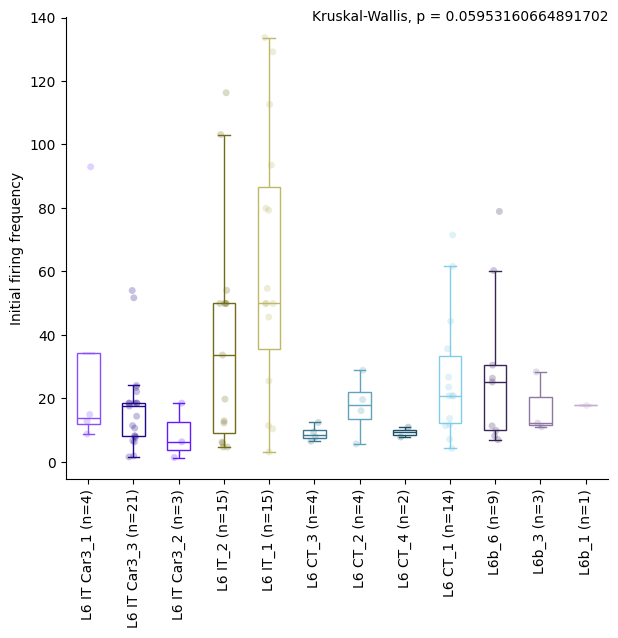

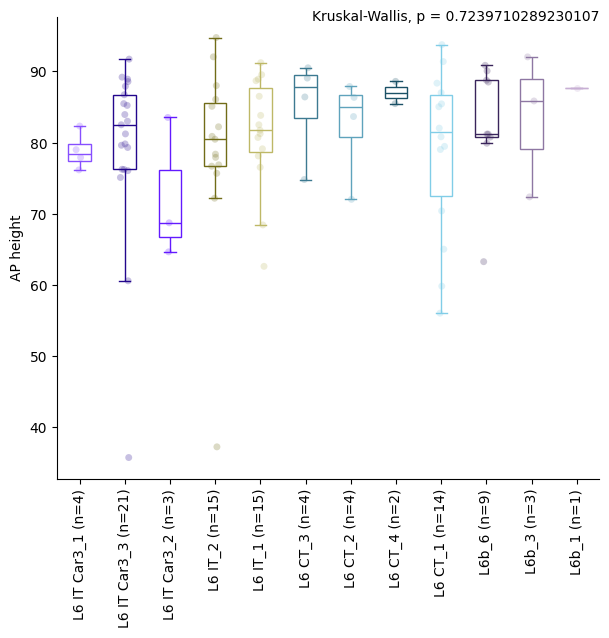

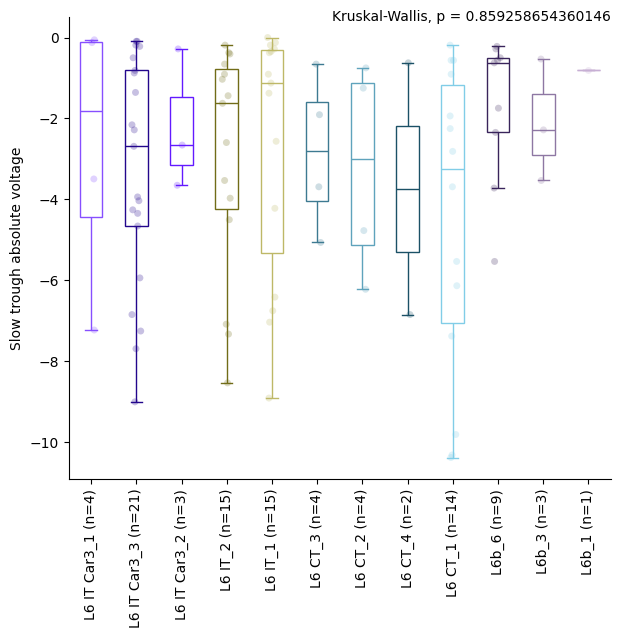

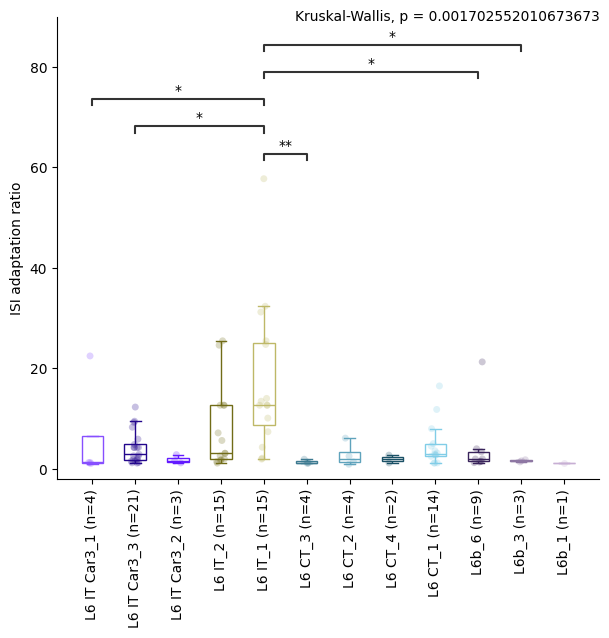

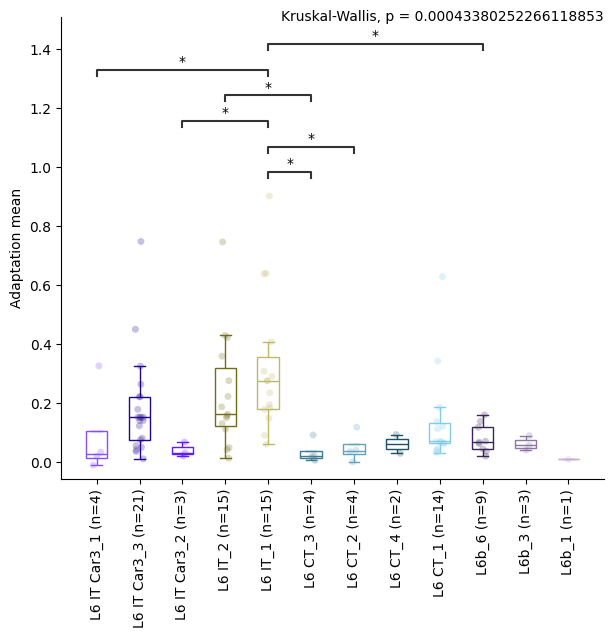

...

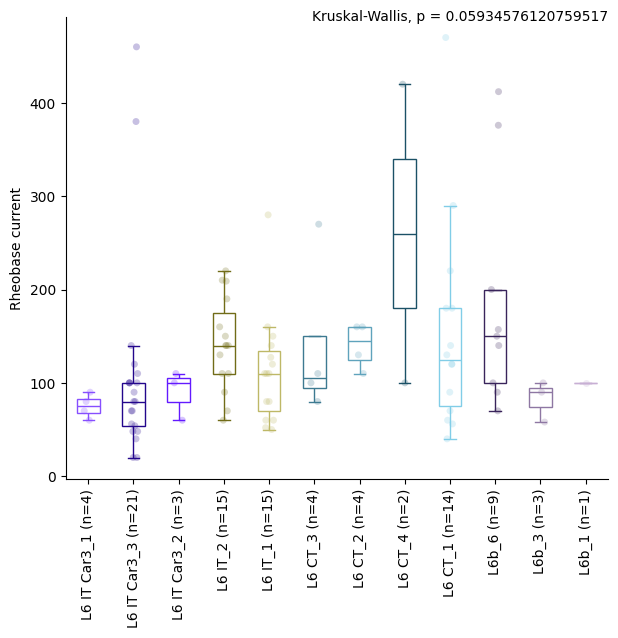

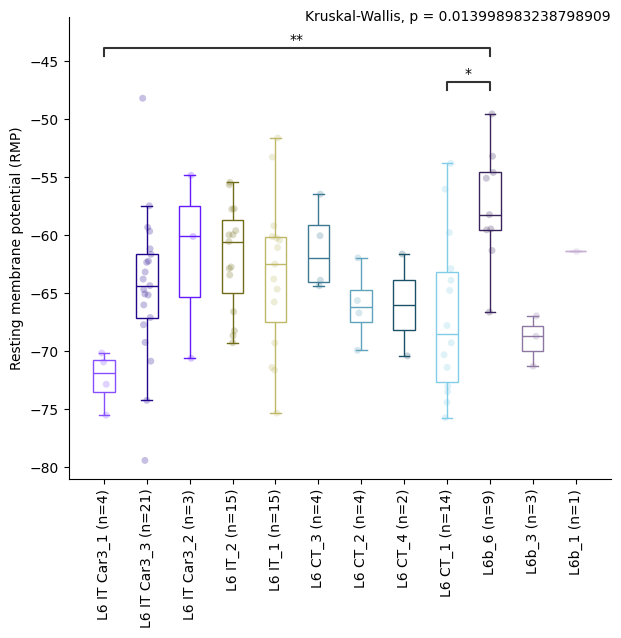

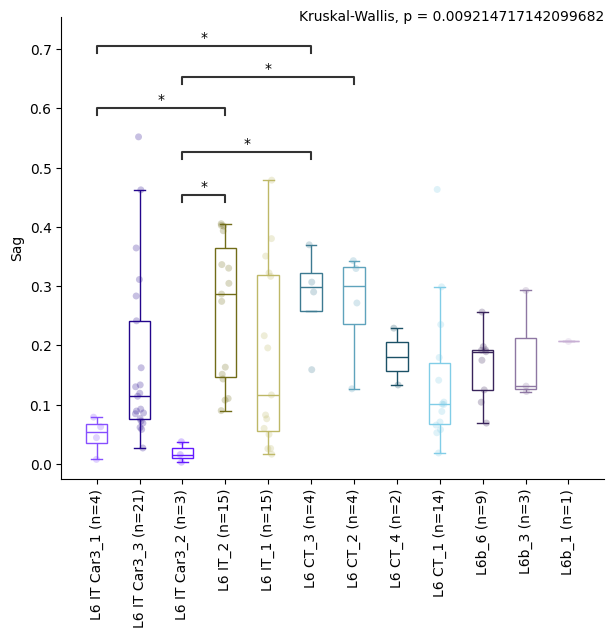

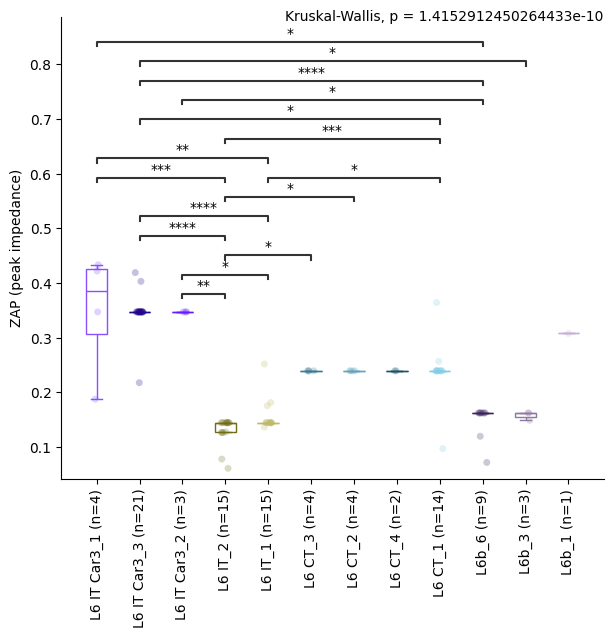

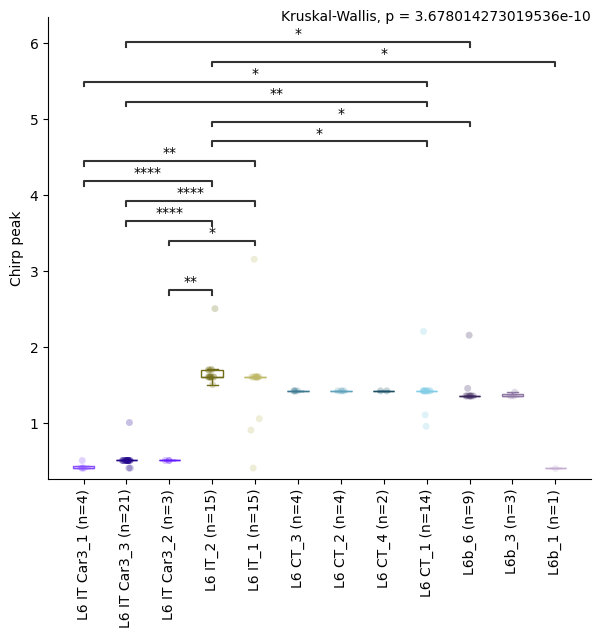

<Figure size 640x480 with 0 Axes>

In [14]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for layer in kw_pvals_fdr_layer.keys():
    if kw_pvals_fdr_layer[layer]:
        #layer has results (there were enough ttypes in the layer, etc.)
        layer_data = sorted_clean_data.loc[sorted_clean_data[layer_var] == layer]
        kw_pvals_fdr = kw_pvals_fdr_layer[layer]  
        dunn_pvals_fdr = dunn_pvals_fdr_layer[layer]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in layer_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(layer.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        ephys_features = feature_cols.copy()

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while ephys_features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = ephys_features.pop()
                    
                    sns.stripplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=layer_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(layer_data[layer_data[x_var] == t])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=layer_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



T-Types within each Subclass x feature box plots with stats

In [15]:
#ttypes within each subclass

ttype_order = group_order['t_type']

# subclass x feature stats
subcalss_var = 'subclass_label' #what to do box plots on 
subclass_var_order = group_order['subclass_label']

kw_pvals_fdr_subclass = dict()
dunn_pvals_fdr_subclass = dict()
for subclass in subclass_var_order:
    print(subclass)
    subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]

    #now run stats on the ttypes in this subclass 
    x_var = 't_type'  # what to do box plots on
    x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

    # Kruskal-Wallis H test on all features
    kw_hvals = dict()
    kw_pvals = dict()
    for f in feature_cols:
        # Create a list of groups dynamically
        groups = [subclass_data.loc[subclass_data[x_var] == x][f].dropna() for x in x_var_order]
        
        # Only include groups that have data
        groups = [group for group in groups if not group.empty]

        if len(groups) < 2:
            print(f"Not enough groups with data for feature {f}")
            continue
        try:
            hvalue, pvalue = kruskal(*groups, nan_policy='omit')
            kw_hvals[f] = hvalue
            kw_pvals[f] = pvalue
        except ValueError as e:
            print(f'Kruskal-Wallis not calculated for {f} because of an error: {e}')

    # FDR correction
    kw_pvals_list = list(kw_pvals.values())
    kw_rejected_list, kw_pvals_fdr_list = fdrcorrection(kw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    kw_pvals_fdr = dict(zip(list(kw_pvals.keys()), list(kw_pvals_fdr_list)))
    kw_rejected = dict(zip(list(kw_pvals.keys()), list(kw_rejected_list)))

    # Post Hoc Dunn test for significant KW features, with FDR correction
    dunn_pvals_fdr = dict()
    for k, v in kw_rejected.items():
        if v:  # if null hypothesis was rejected, calculate Dunn post hoc
            dunn_pvals_fdr[k] = posthoc_dunn(subclass_data[subclass_data[x_var].isin(x_var_order)], val_col=k, group_col=x_var, p_adjust='fdr_bh', sort=True)

    kw_pvals_fdr_subclass[subclass] = kw_pvals_fdr
    dunn_pvals_fdr_subclass[subclass] = dunn_pvals_fdr

L2/3 IT
L4 IT
L5 IT
L5/6 NP
L5 ET
L6 IT Car3
L6 IT
L6 CT
L6b


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.369e-03
L3 IT_8 vs. L3 IT_12: Custom statistical test, P_val:4.949e-02
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:2.239e-05
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:4.198e-03
L2 IT_7 vs. L3 IT_12: Custom statistical test, P_val:9.888e-03
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:3.458e-08
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:7.295e-04
L3 IT_8 vs. L3 IT_5: Custom statistical test, P_val:2.505e-02
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:4.769e-05
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:7.342e-04
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:3.253e-08
L2 IT_1 vs. L3 IT_13: Custom statistical test, P_val:5.463e-07
L2 IT_2 vs. L3 IT_3: Custom statistical test, P_val:4.3

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:3.639e-02
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:9.056e-03
L3 IT_12 vs. L3 IT_13: Custom statistical test, P_val:9.056e-03
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:4.478e-02


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:6.833e-08
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:5.184e-08
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:1.913e-03
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:9.452e-05
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:5.903e-12
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:1.642e-08
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:9.585e-08
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:9.272e-04
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:3.930e-10
L2 IT_1 vs. L3 IT_13: Custom statistical test, P_val:1.819e-14
L2 IT_6 vs. L3 IT_13: Custom statistical test, P_val:1.311e-03
L2 IT_1 vs. L3 IT_5: Custom statistical test, P_val:5.378e-17
L2 IT_1 vs. L3 IT_3: Custom statistical test, P_val:2.86

... (28 outputs left out)

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:2.572e-05
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:3.670e-04
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:5.667e-05
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:3.986e-04
L2 IT_6 vs. L2 IT_2: Custom statistical test, P_val:1.384e-04
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:4.168e-04
L3 IT_10 vs. L3 IT_3: Custom statistical test, P_val:2.736e-02
L3 IT_12 vs. L3 IT_5: Custom statistical test, P_val:4.402e-02
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:4.372e-05
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:1.844e-09
L3 IT_12 vs. L3 IT_3: Custom statistical test, P_val:7.299e-03
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:3.986e-04
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:4.

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6 vs. L2 IT_1: Custom statistical test, P_val:1.277e-03
L3 IT_10 vs. L3 IT_13: Custom statistical test, P_val:1.571e-02
L3 IT_13 vs. L3 IT_5: Custom statistical test, P_val:2.020e-02
L2 IT_2 vs. L3 IT_12: Custom statistical test, P_val:1.657e-05
L3 IT_13 vs. L3 IT_3: Custom statistical test, P_val:6.149e-04
L2 IT_2 vs. L3 IT_10: Custom statistical test, P_val:3.765e-03
L2 IT_1 vs. L3 IT_12: Custom statistical test, P_val:2.635e-09
L2 IT_2 vs. L3 IT_13: Custom statistical test, P_val:5.443e-11
L3 IT_12 vs. L3 IT_3: Custom statistical test, P_val:1.545e-02
L2 IT_1 vs. L3 IT_10: Custom statistical test, P_val:1.193e-05
L2 IT_6 vs. L3 IT_12: Custom statistical test, P_val:2.563e-04
L2 IT_7 vs. L3 IT_13: Custom statistical test, P_val:3.941e-02
L2 IT_2 vs. L3 IT_5: Custom statistical test, P_val:

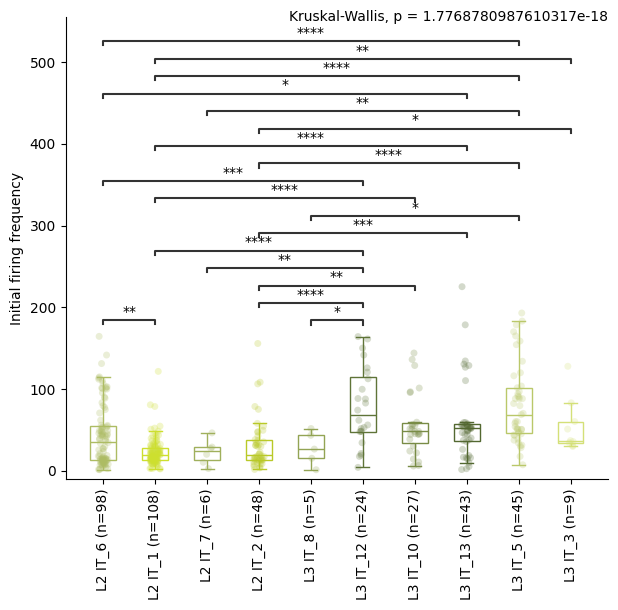

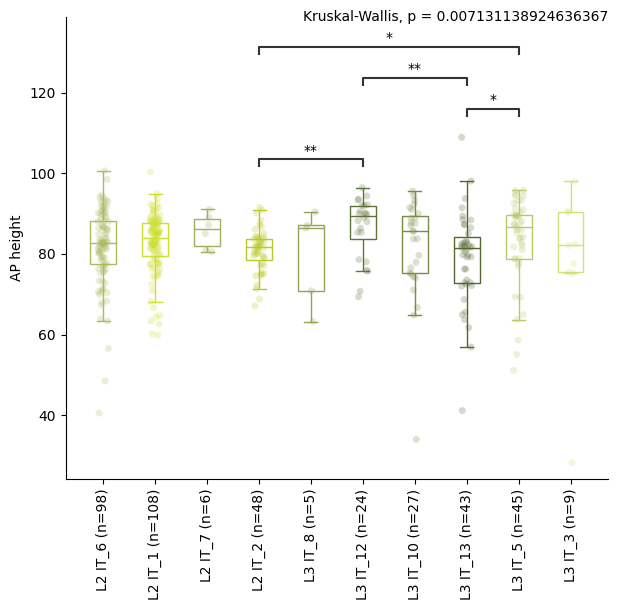

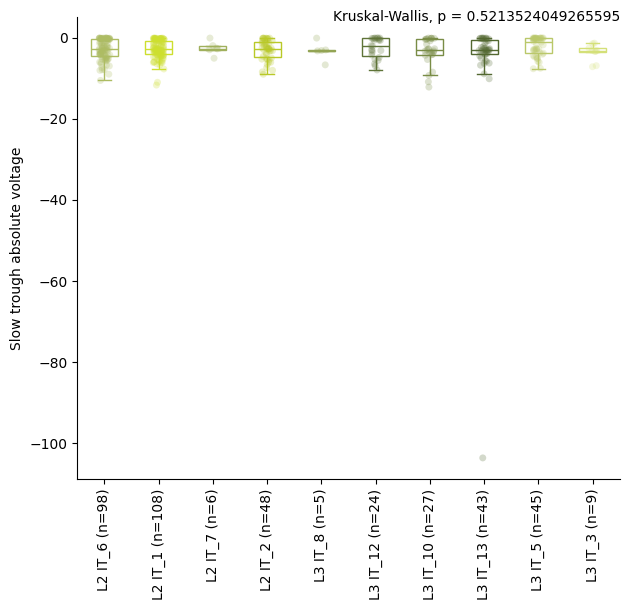

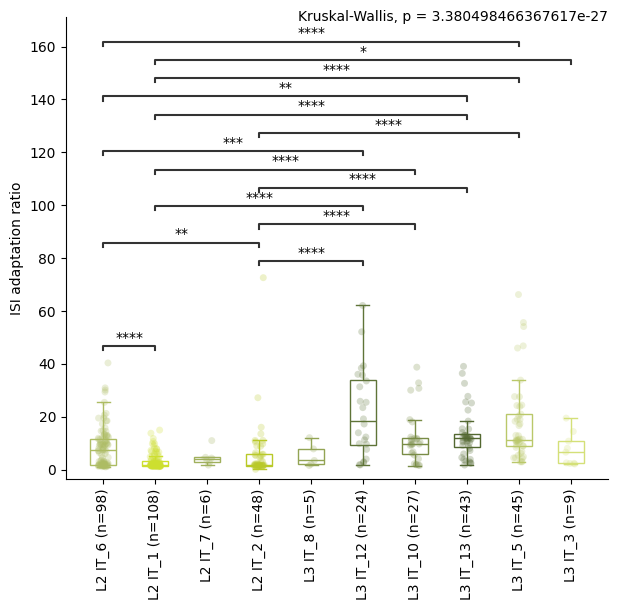

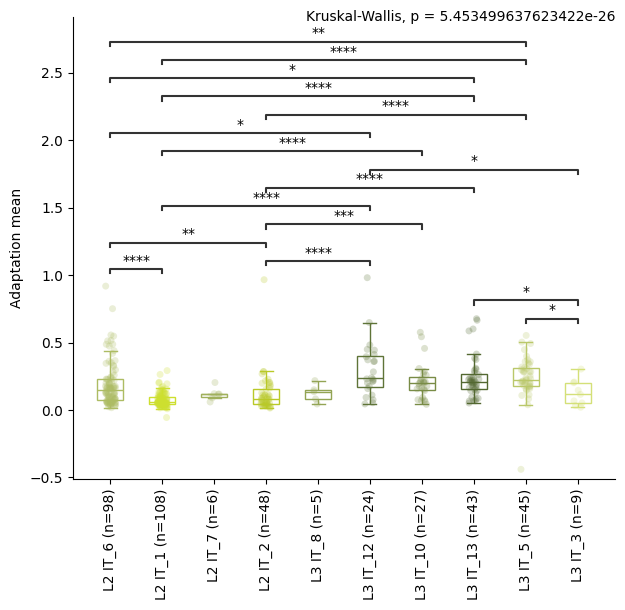

...

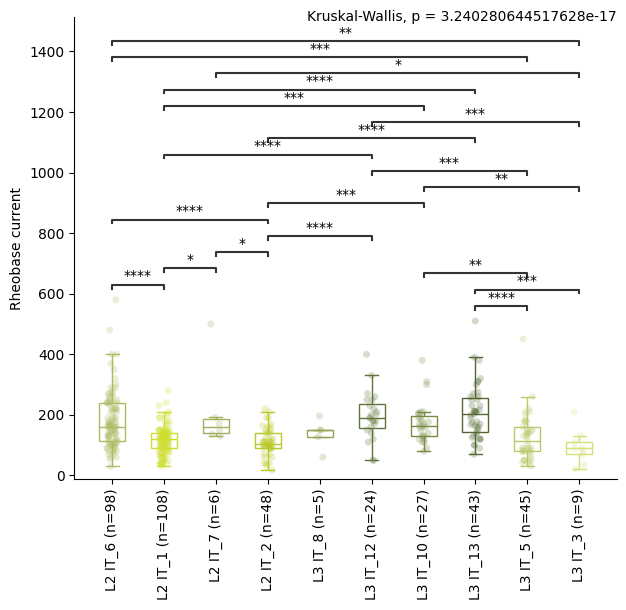

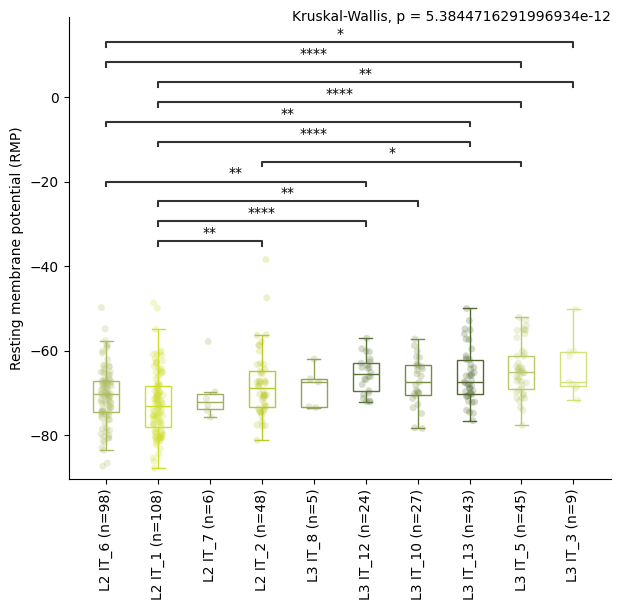

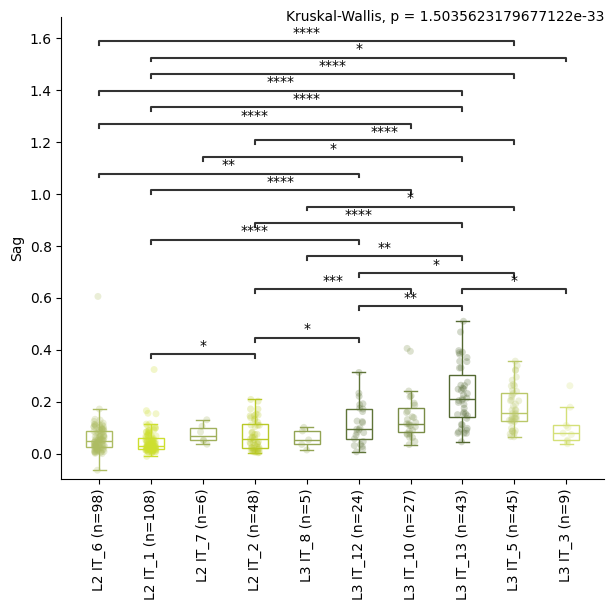

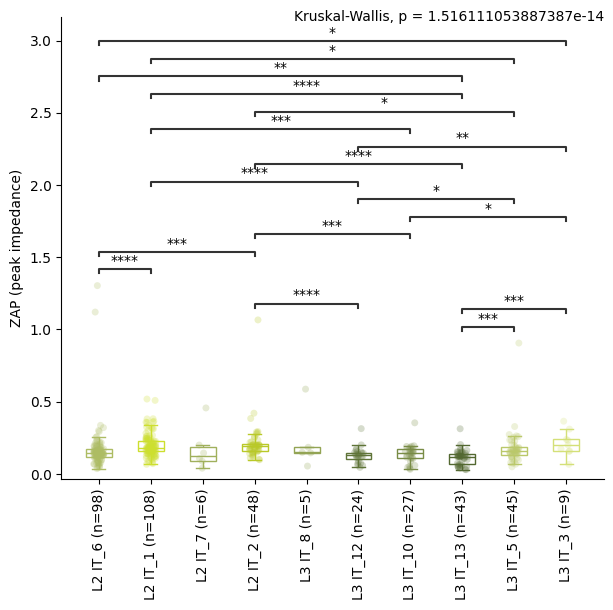

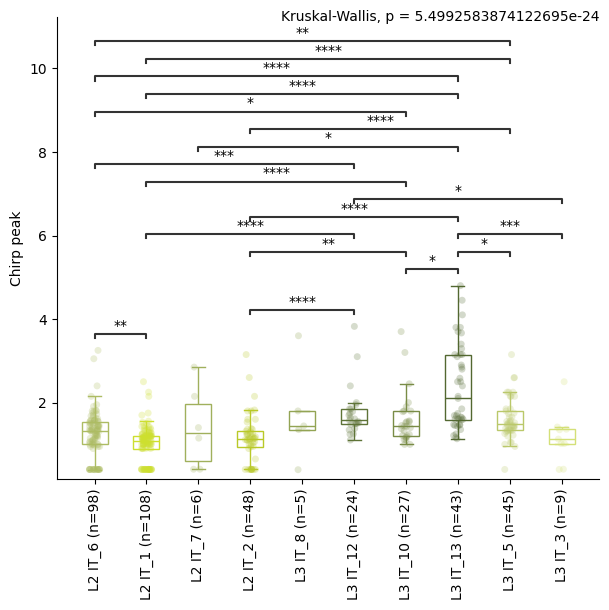

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:1.157e-12
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.301e-13
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.491e-04
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:7.251e-05


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:8.821e-04
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:5.169e-09
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:2.748e-02


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_2 vs. L4 IT_1: Custom statistical test, P_val:4.511e-02
L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:8.335e-08
L4 IT_3 vs. L4 IT_2: Custom statistical test, P_val:3.648e-03
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:4.511e-02


... (31 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:1.717e-07
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:1.107e-05
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:1.512e-02
L4 IT_3 vs. L4 IT_1: Custom statistical test, P_val:2.447e-02


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_4 vs. L4 IT_2: Custom statistical test, P_val:3.890e-08
L4 IT_3 vs. L4 IT_4: Custom statistical test, P_val:3.921e-03
L4 IT_4 vs. L4 IT_1: Custom statistical test, P_val:2.830e-04


<Figure size 640x480 with 0 Axes>

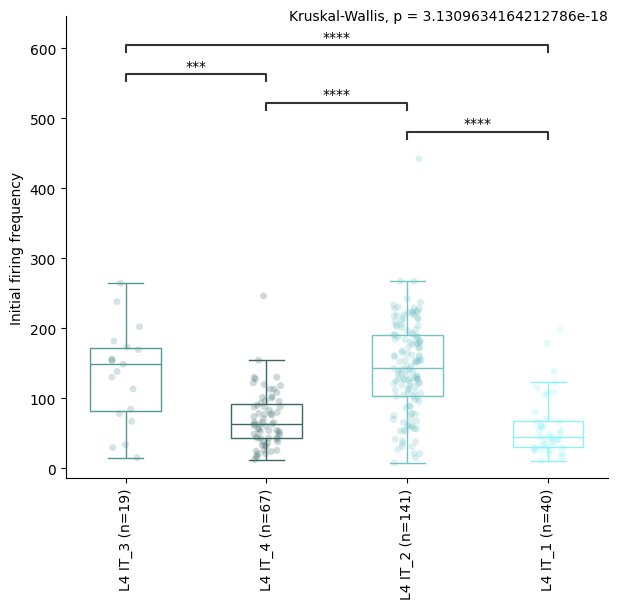

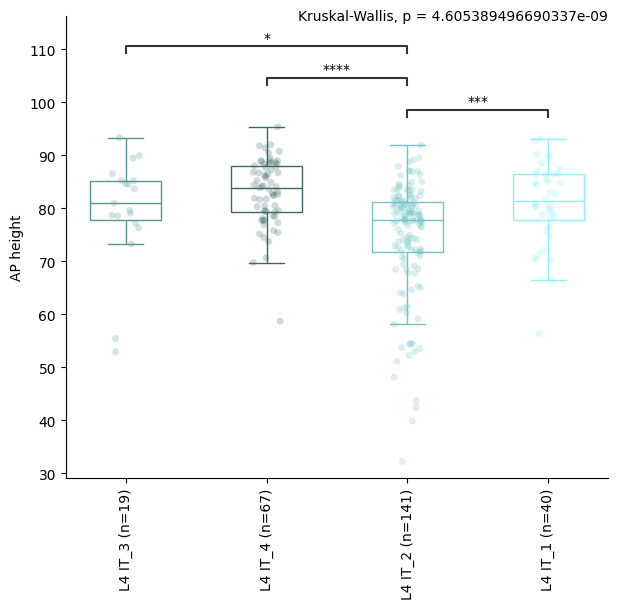

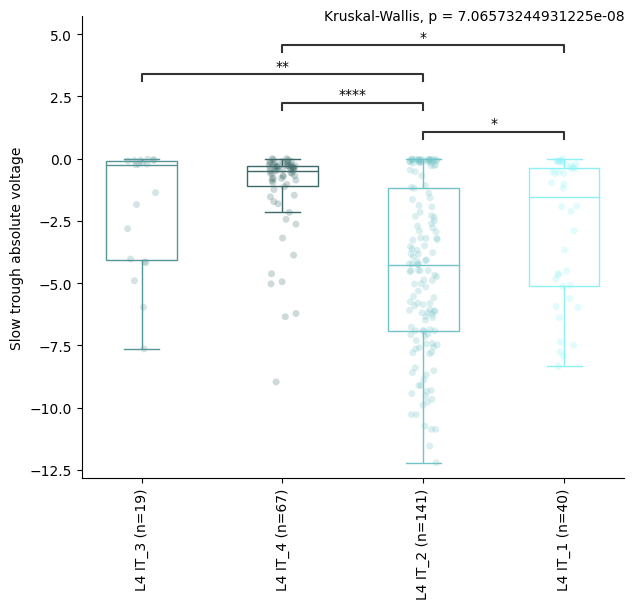

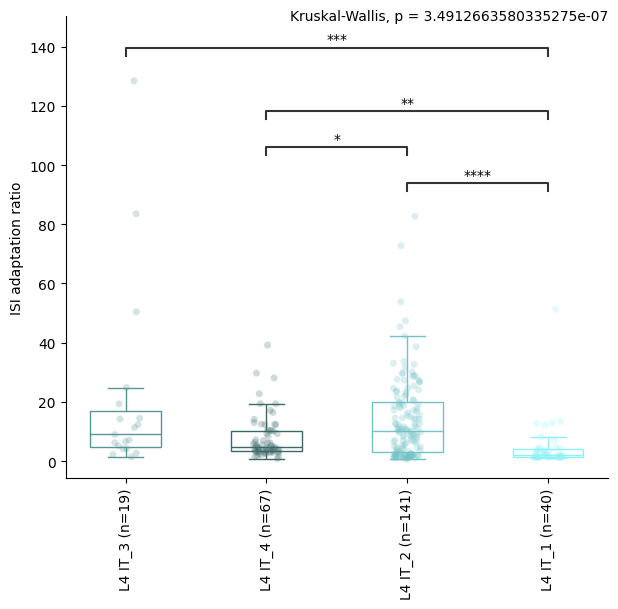

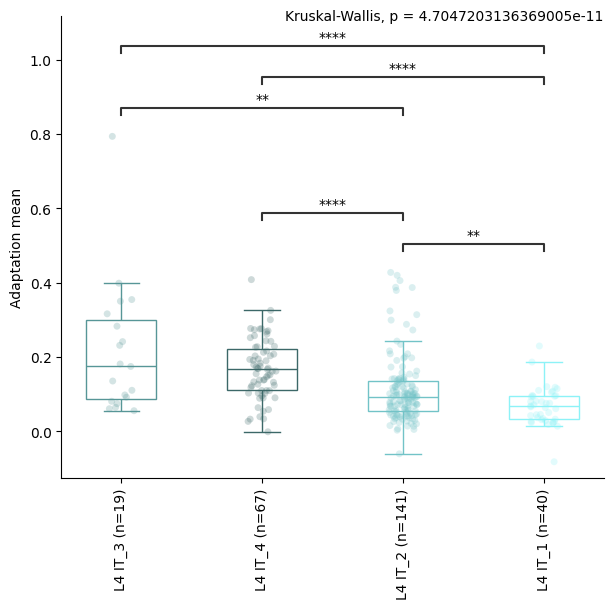

...

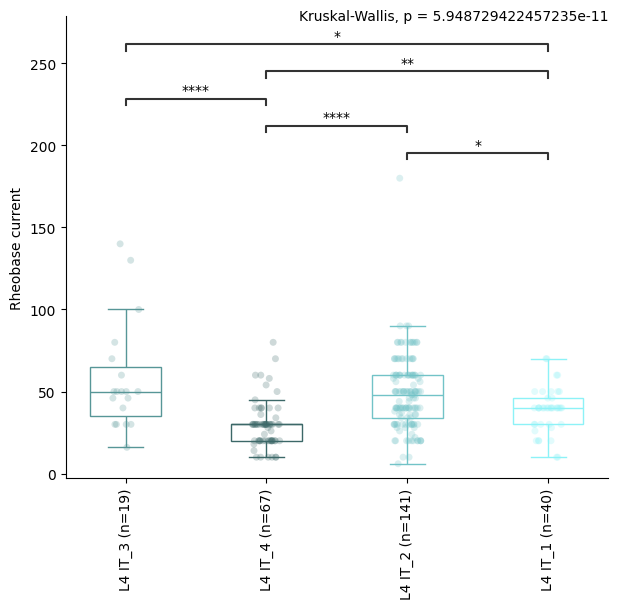

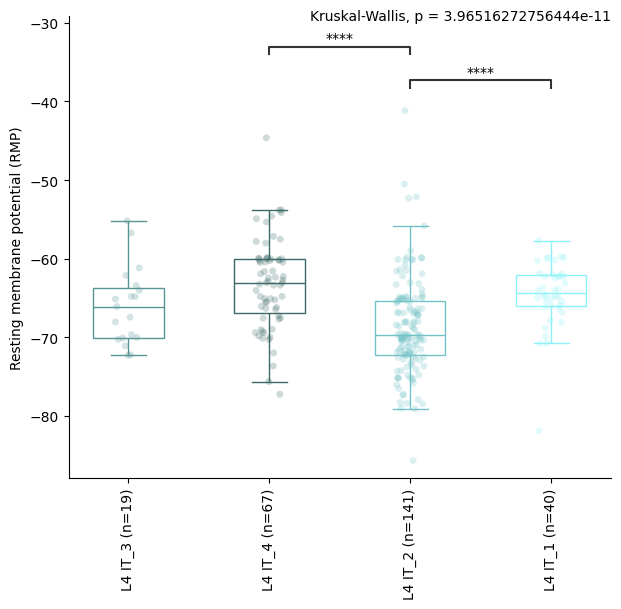

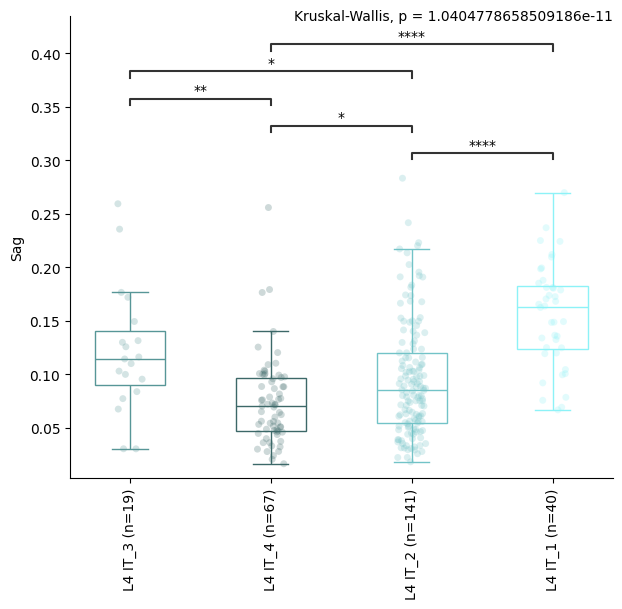

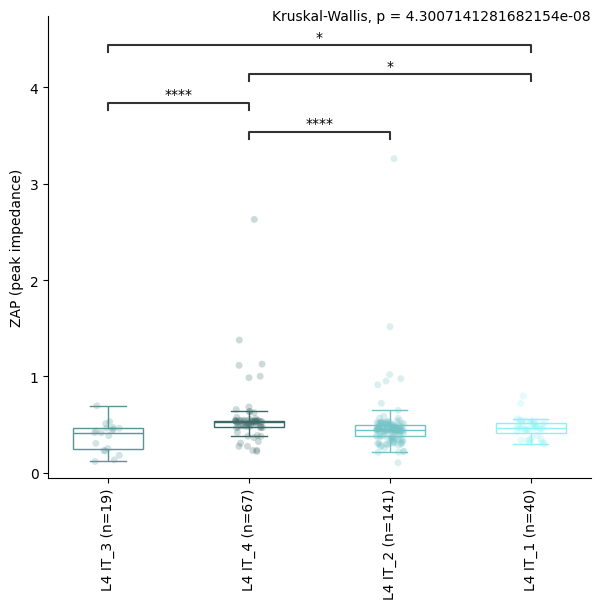

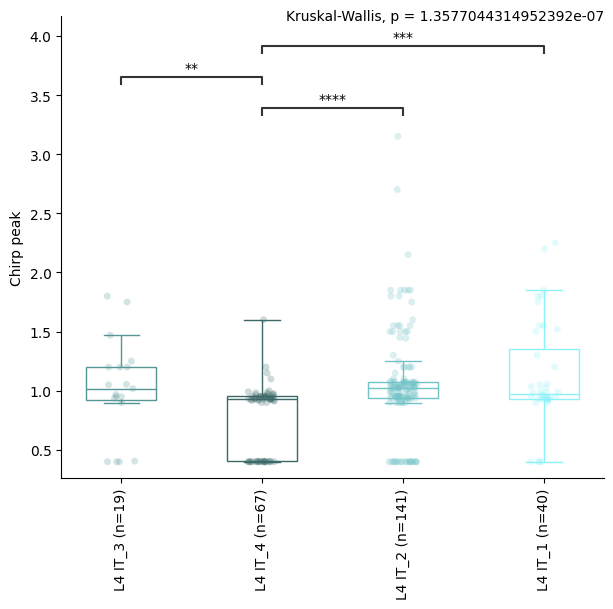

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.618e-03
L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:3.353e-04
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:3.353e-04
L5 IT_6 vs. L5 IT_1: Custom statistical test, P_val:3.523e-04


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.925e-05
L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:3.532e-02
L5 IT_5 vs. L5 IT_1: Custom statistical test, P_val:5.768e-03
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:4.697e-05
L5 IT_2 vs. L5 IT_7: Custom statistical test, P_val:1.312e-02
L5 IT_2 vs. L5 IT_3: Custom statistical test, P_val:2.253e-02


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2 vs. L5 IT_1: Custom statistical test, P_val:2.024e-03
L5 IT_5 vs. L5 IT_2: Custom statistical test, P_val:3.807e-04
L5 IT_6 vs. L5 IT_2: Custom statistical test, P_val:1.500e-09
L5 IT_2 vs. L5 IT_7: Custom statistical test, P_val:1.173e-03


... (22 outputs left out)

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_1 vs. L5 IT_7: Custom statistical test, P_val:4.530e-02
L5 IT_6 vs. L5 IT_1: Custom statistical test, P_val:4.530e-02


/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


<Figure size 640x480 with 0 Axes>

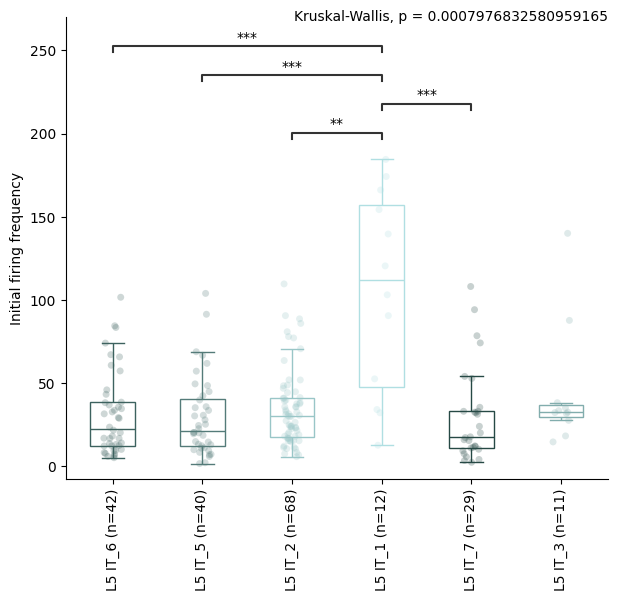

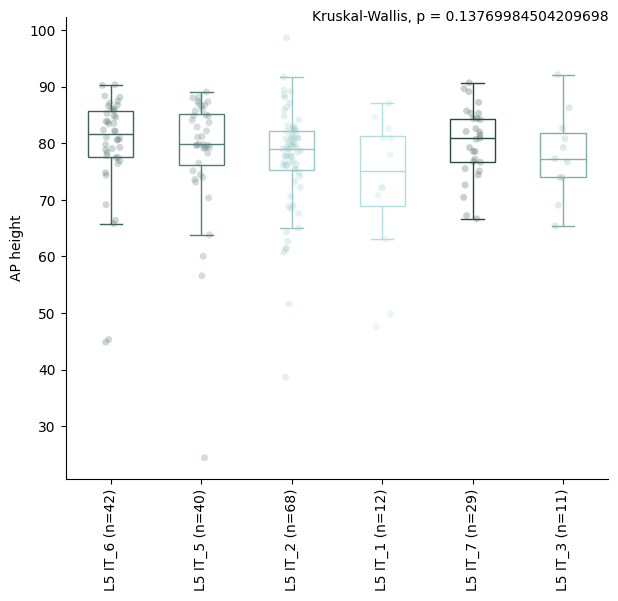

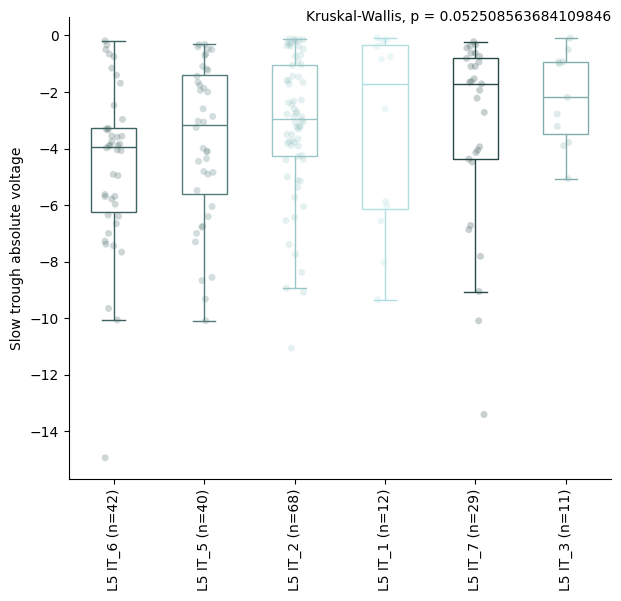

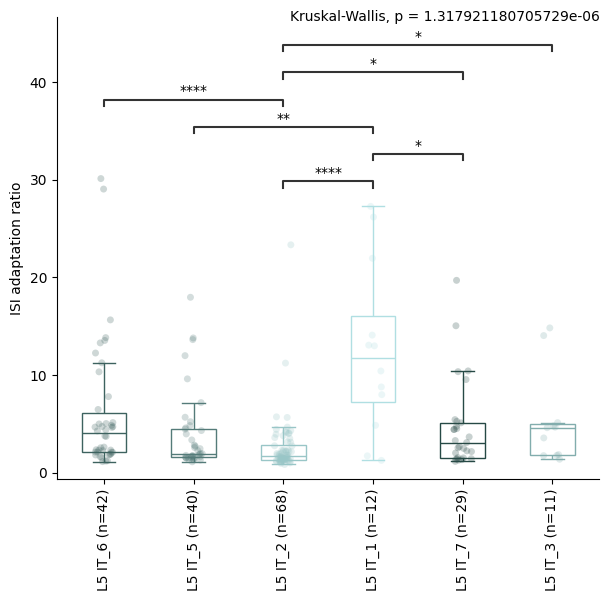

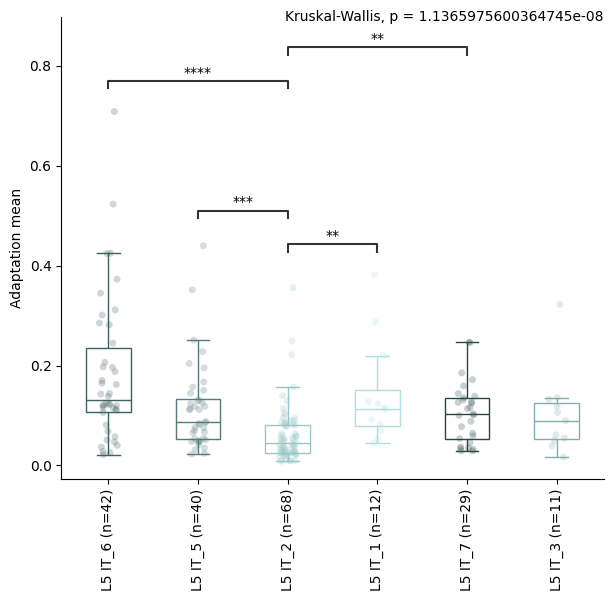

...

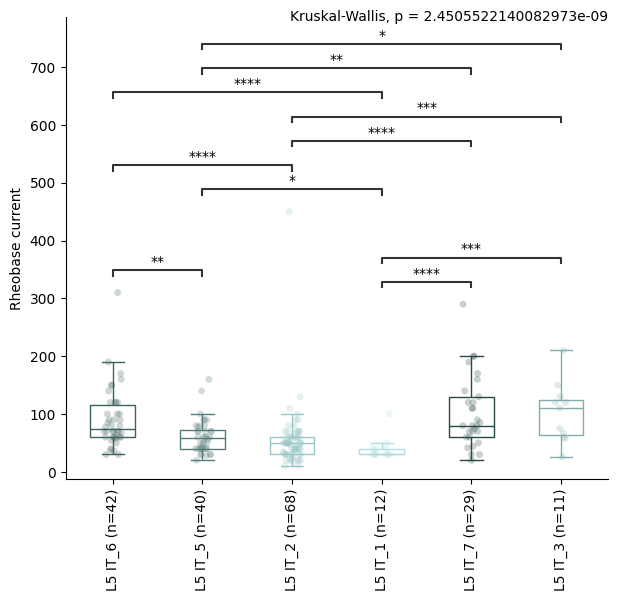

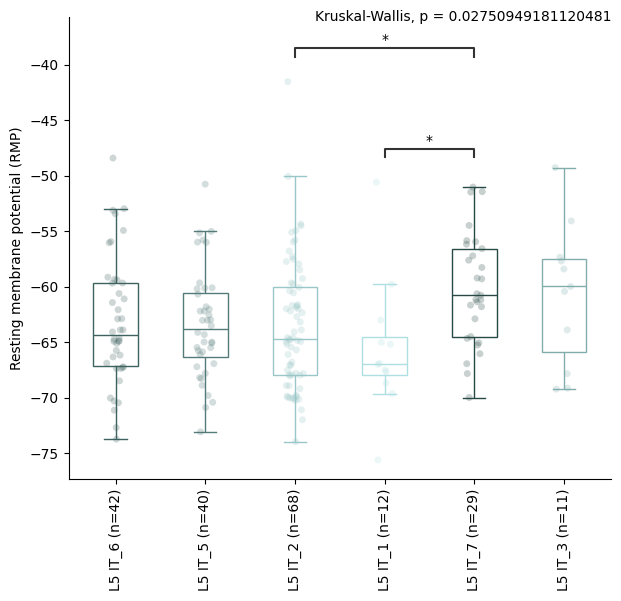

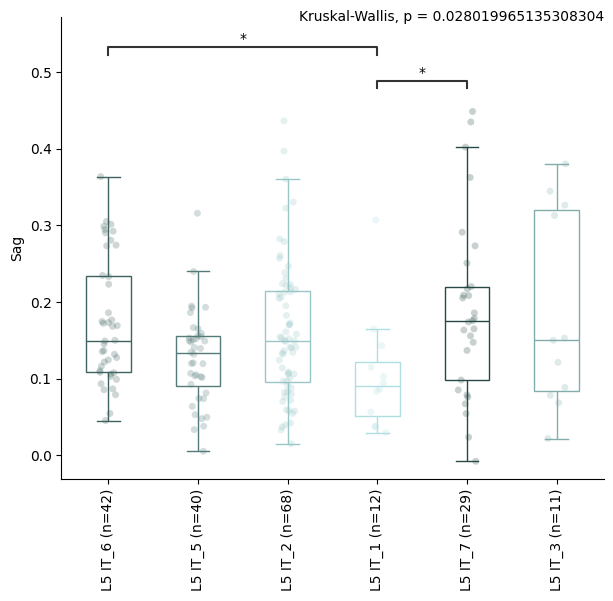

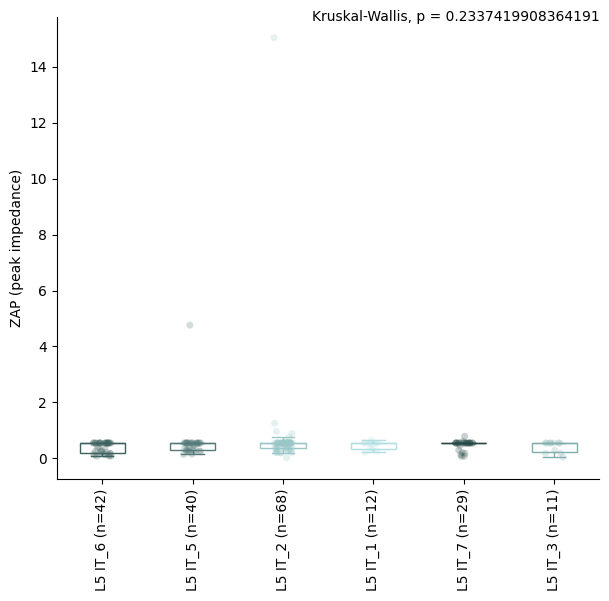

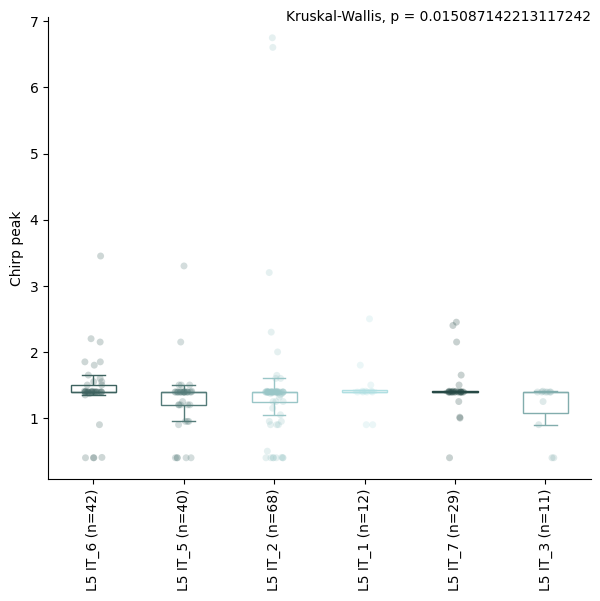

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

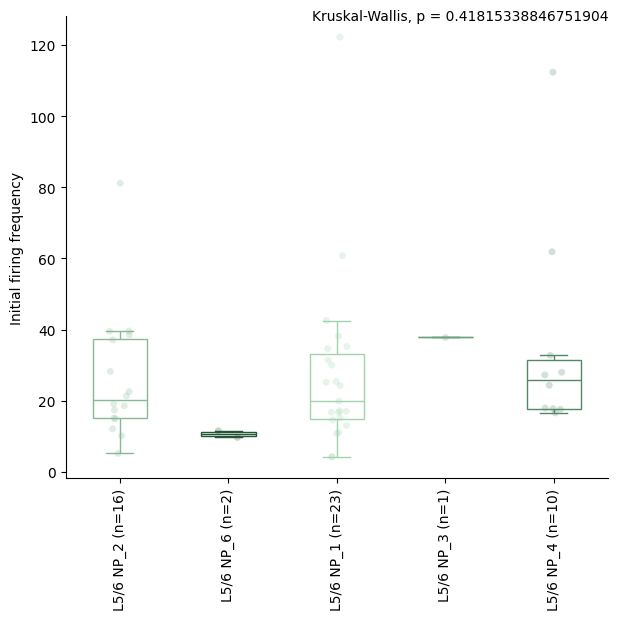

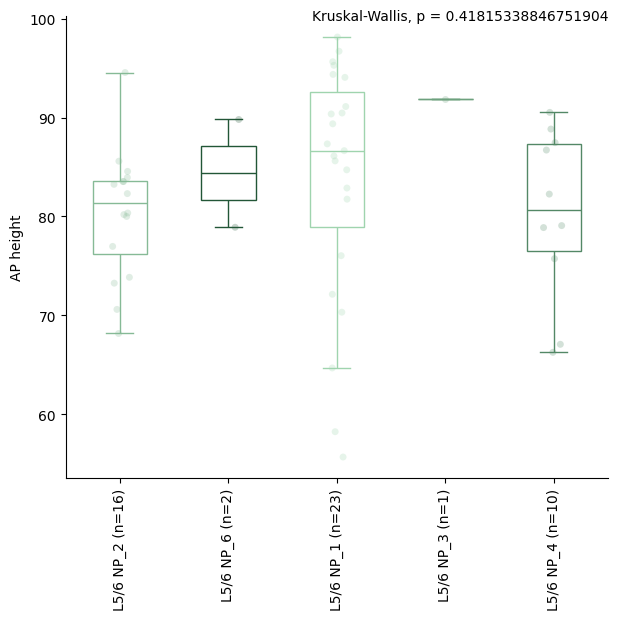

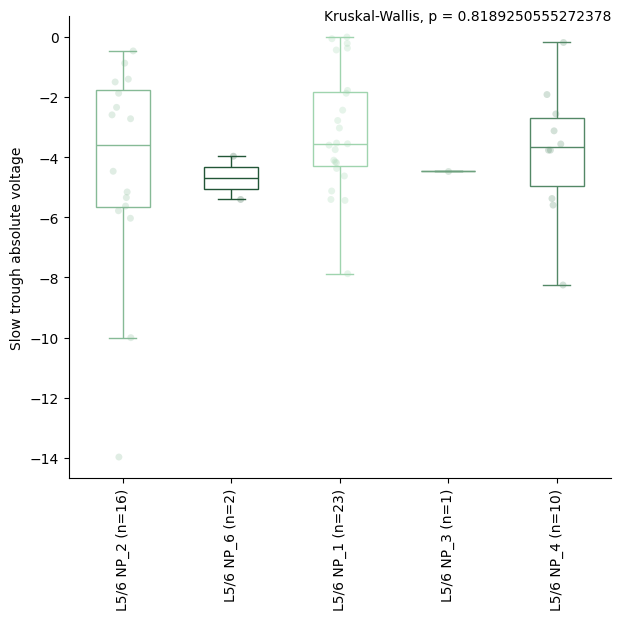

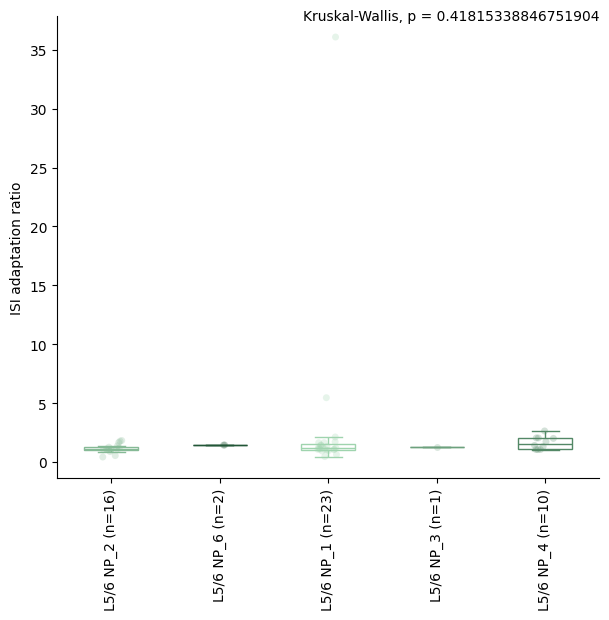

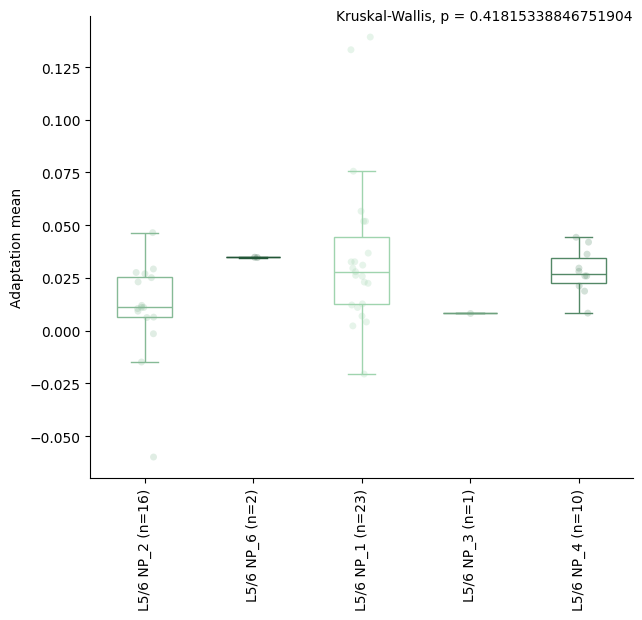

...

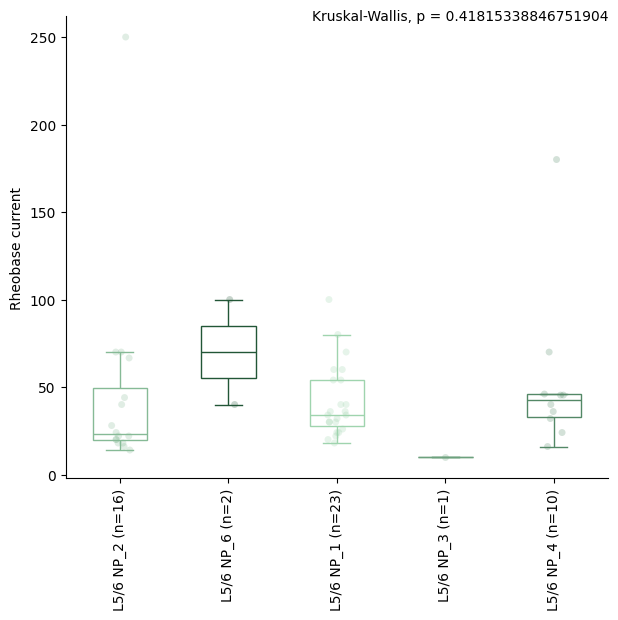

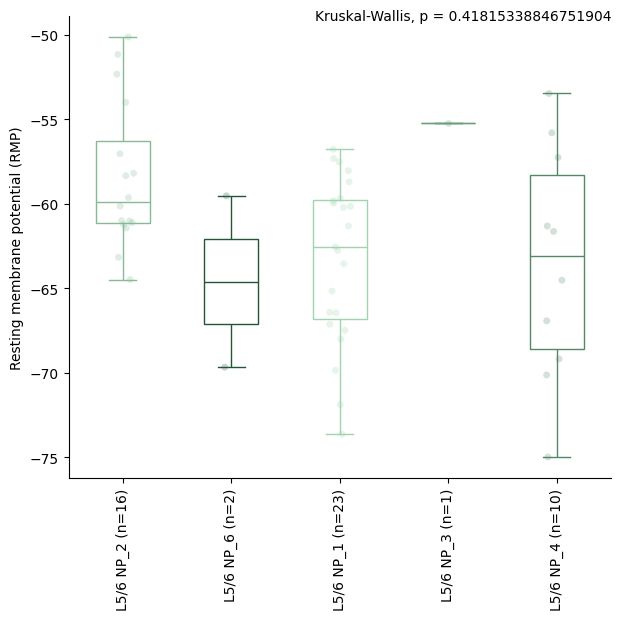

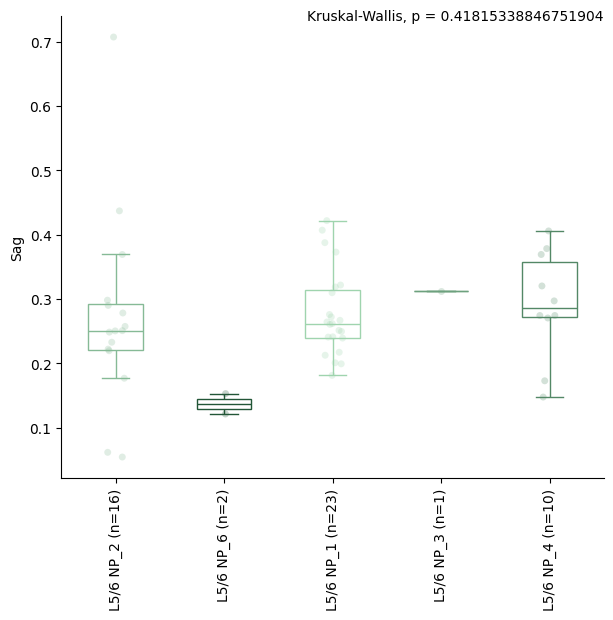

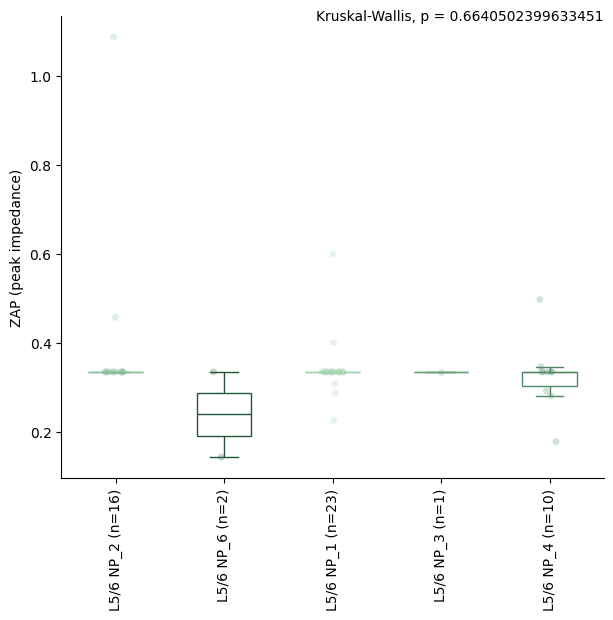

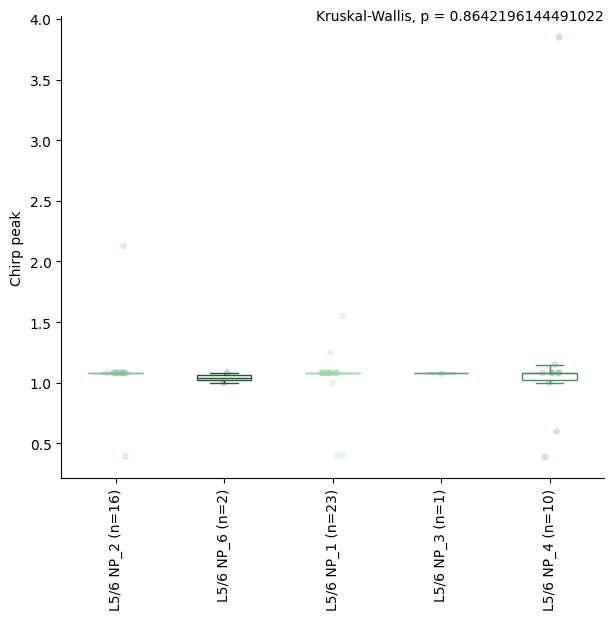

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

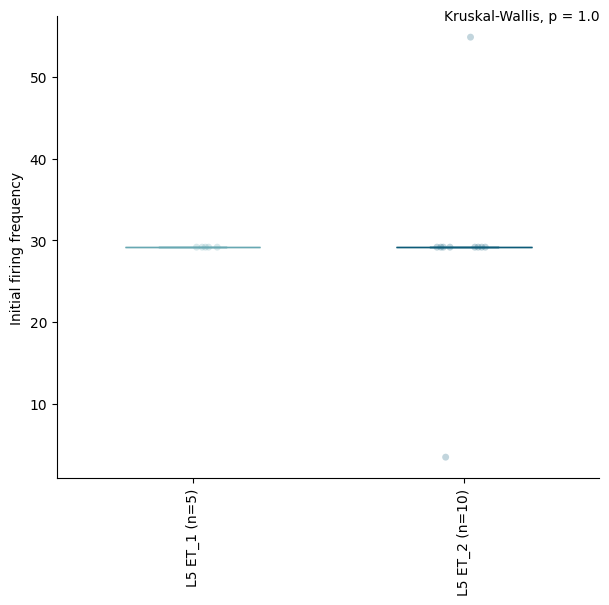

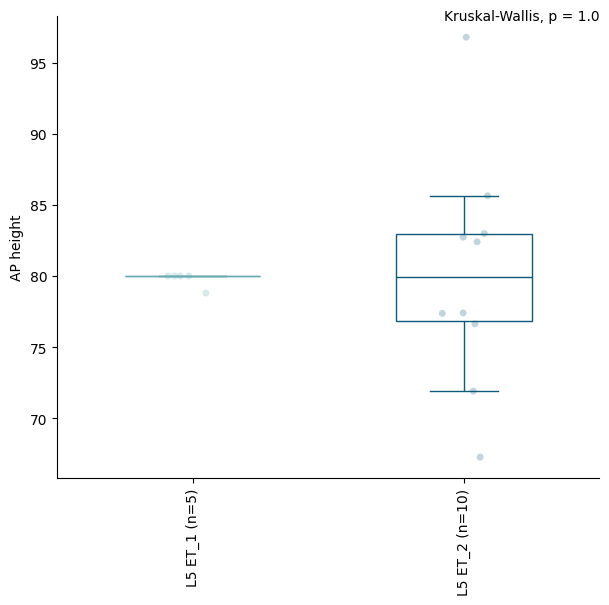

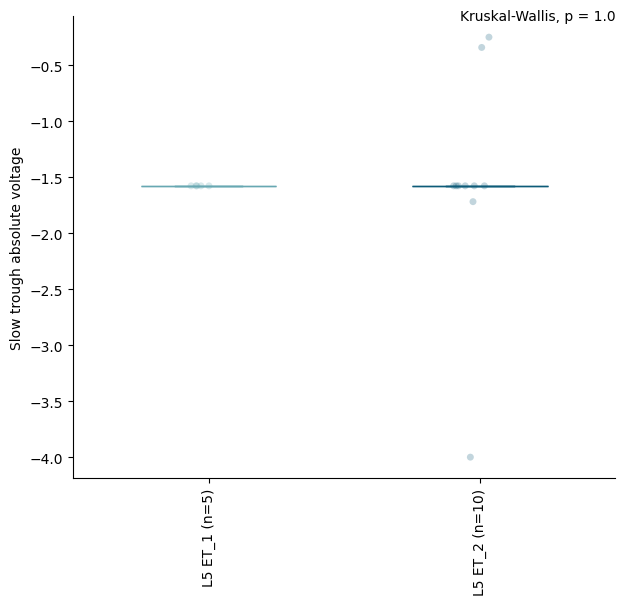

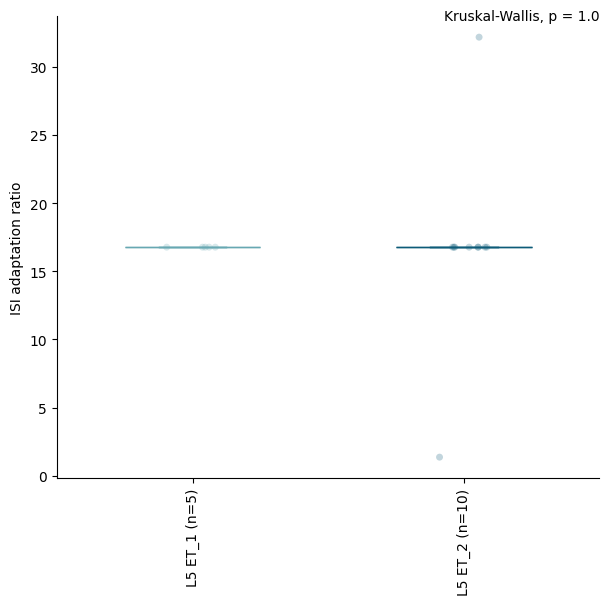

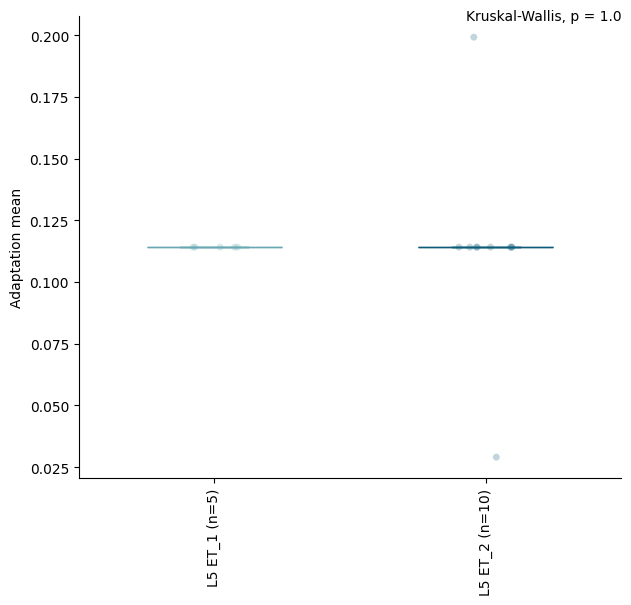

...

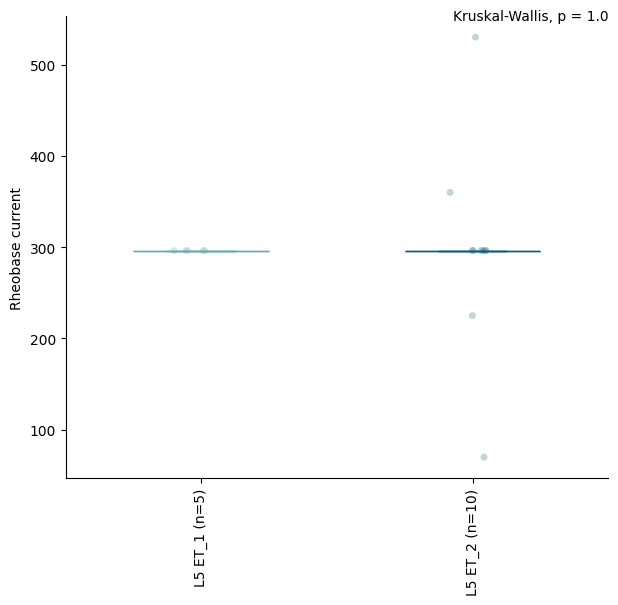

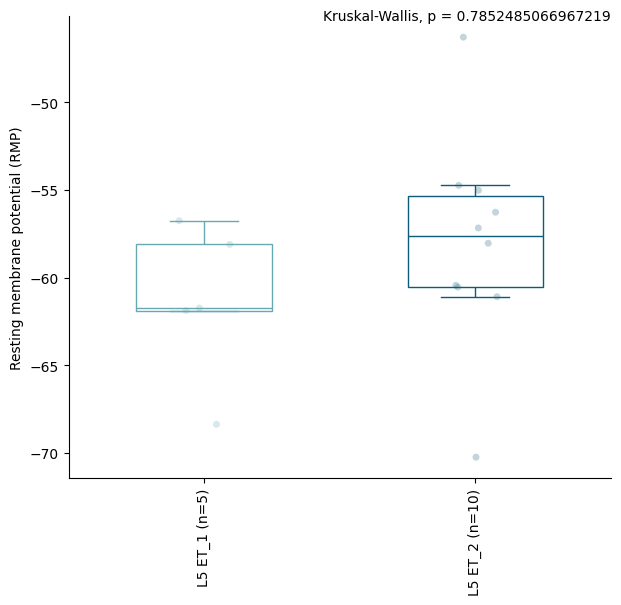

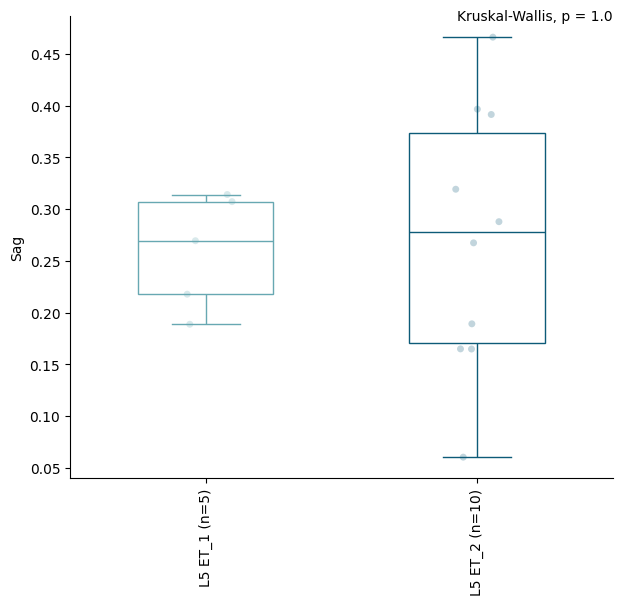

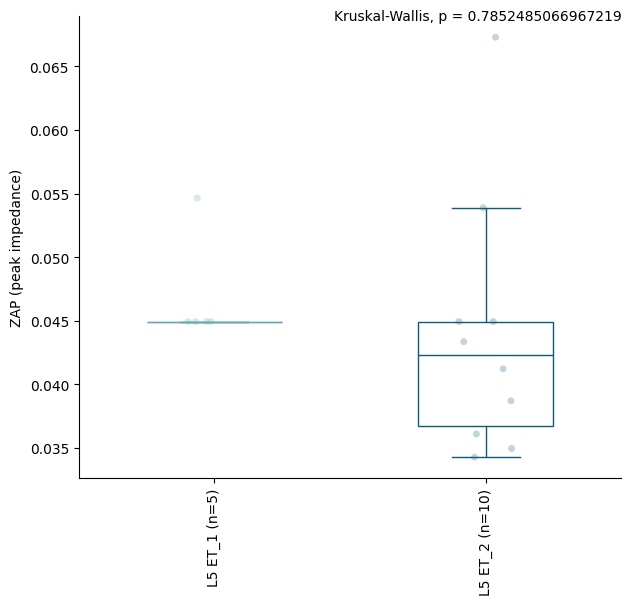

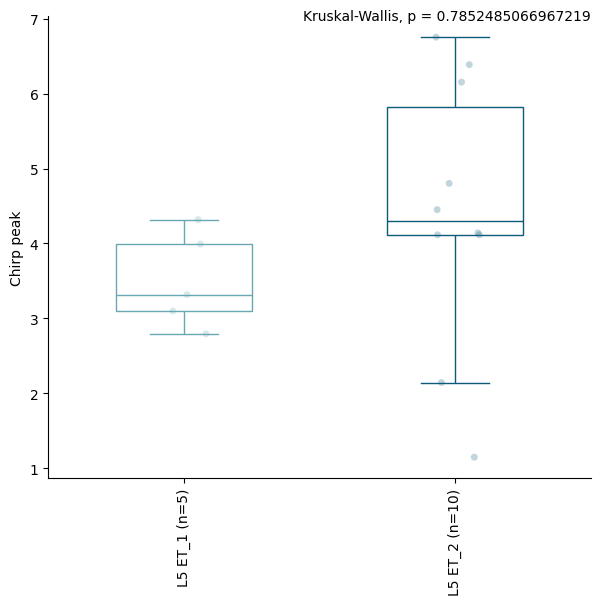

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

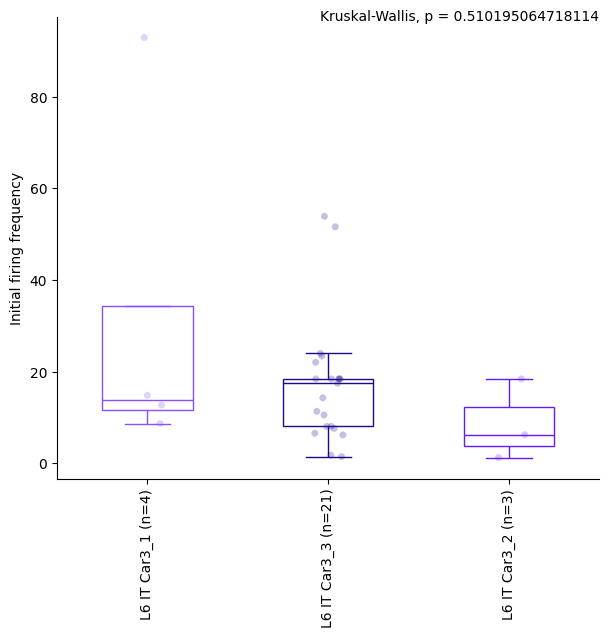

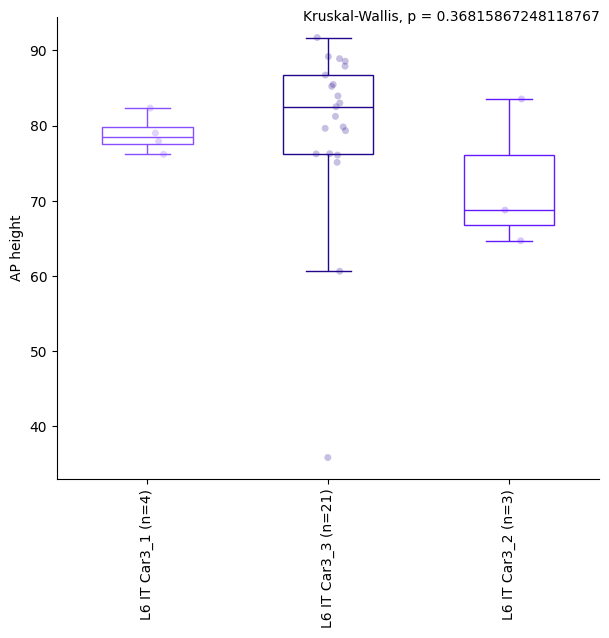

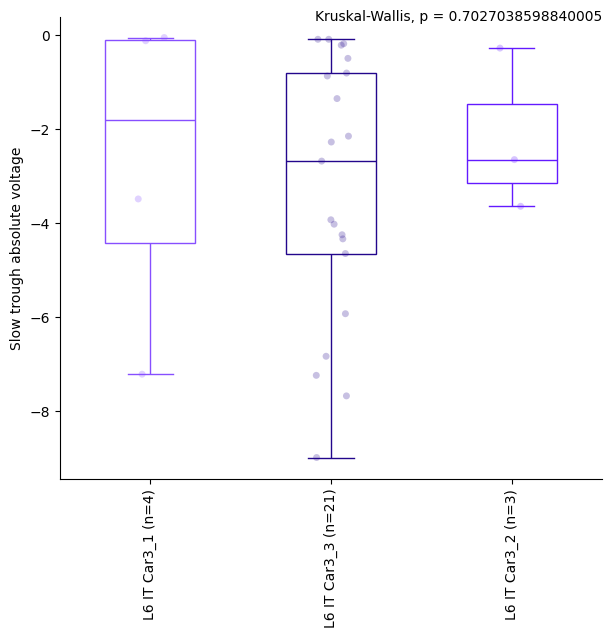

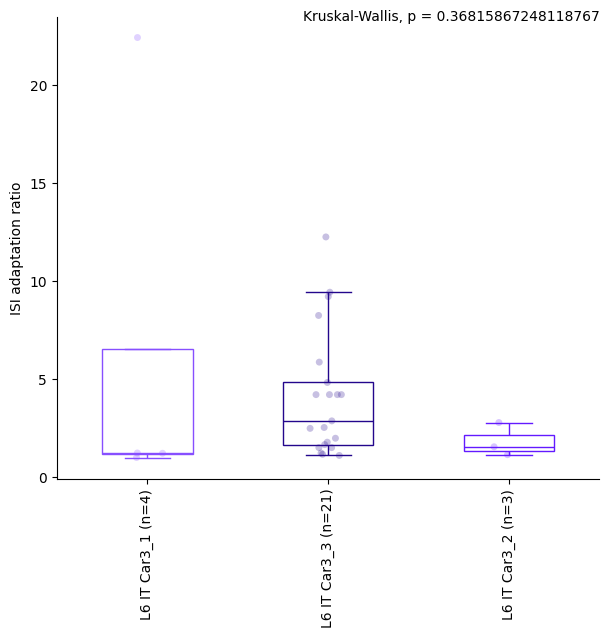

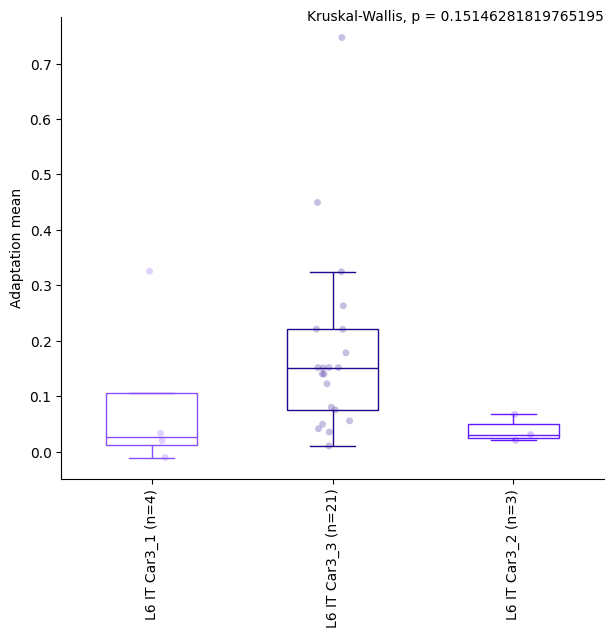

...

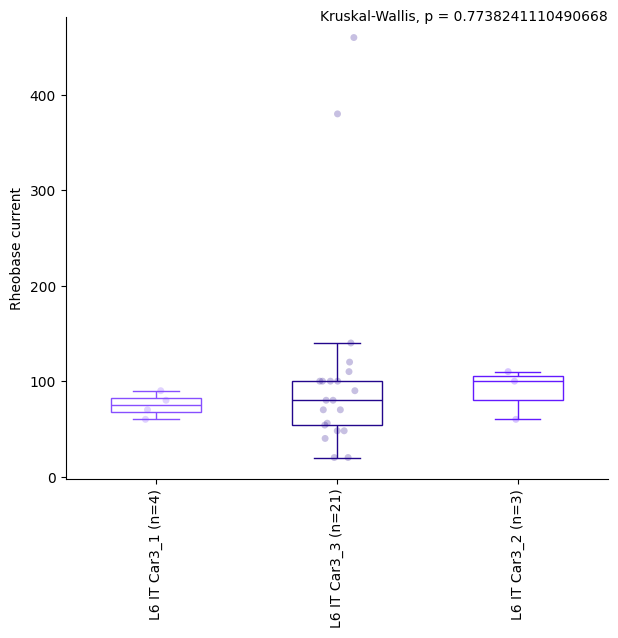

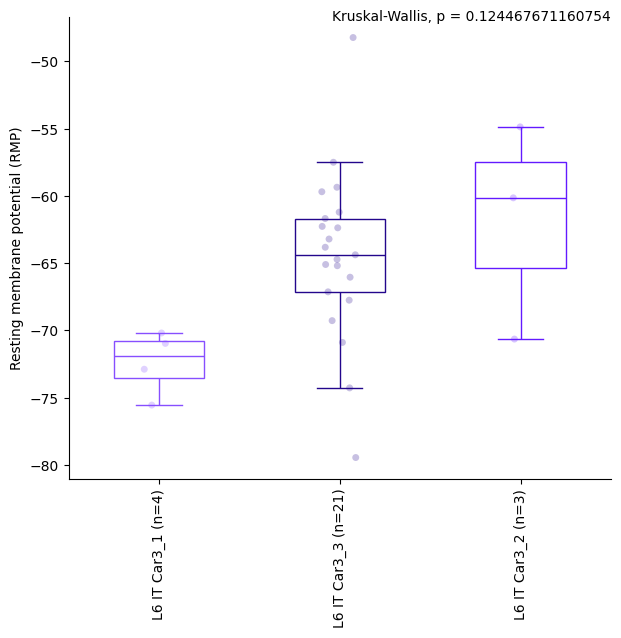

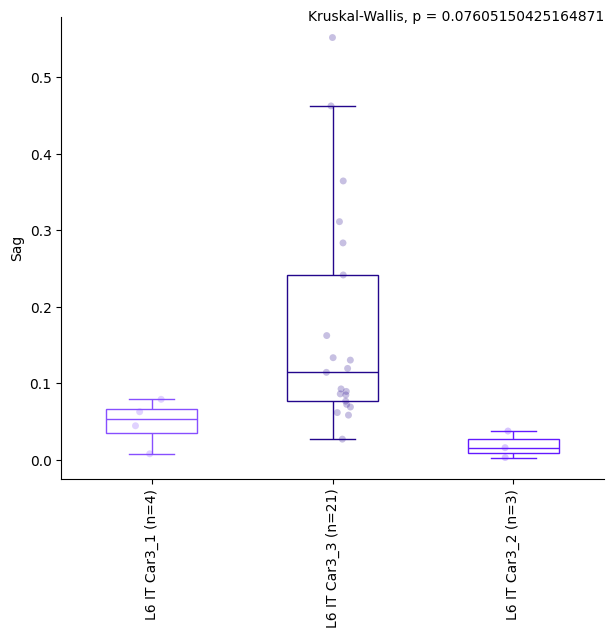

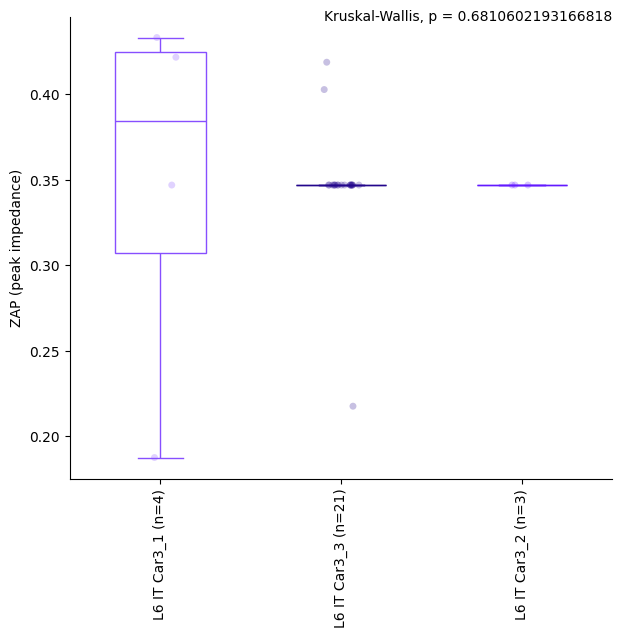

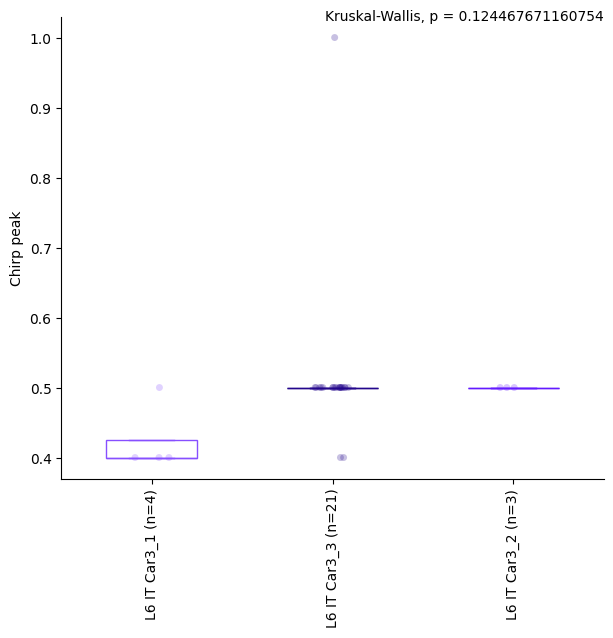

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

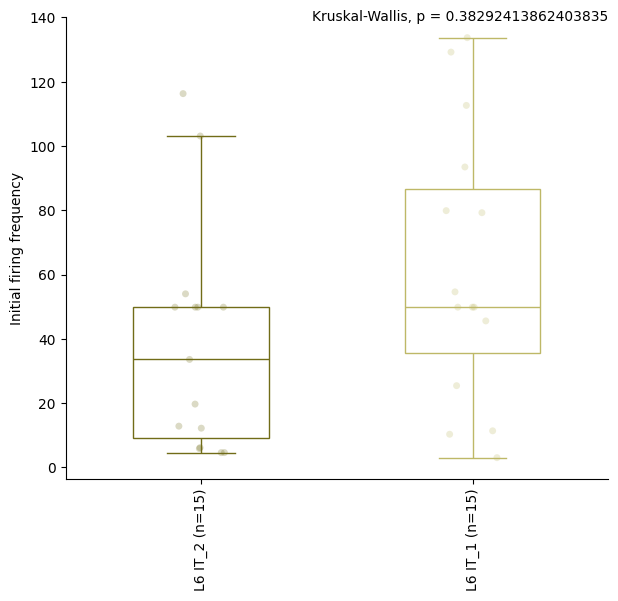

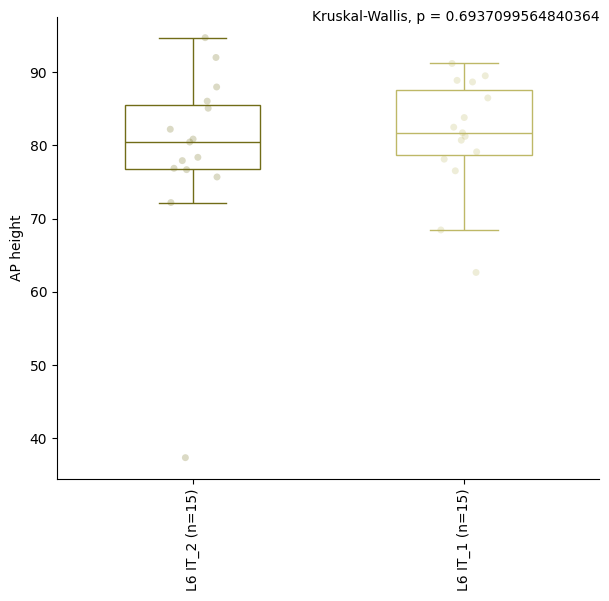

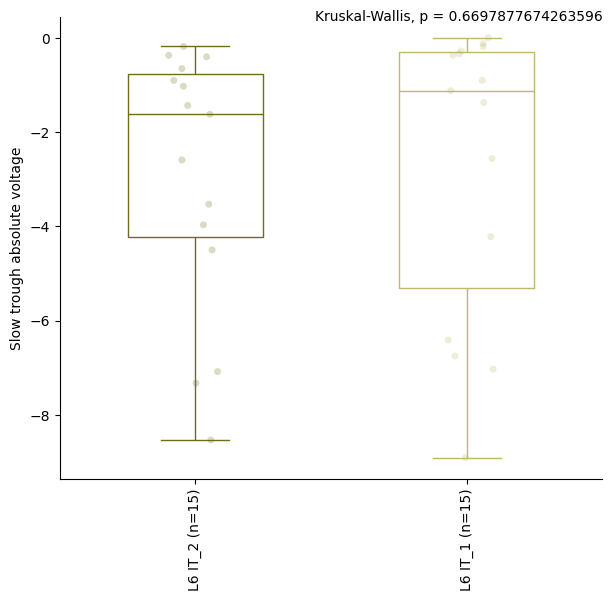

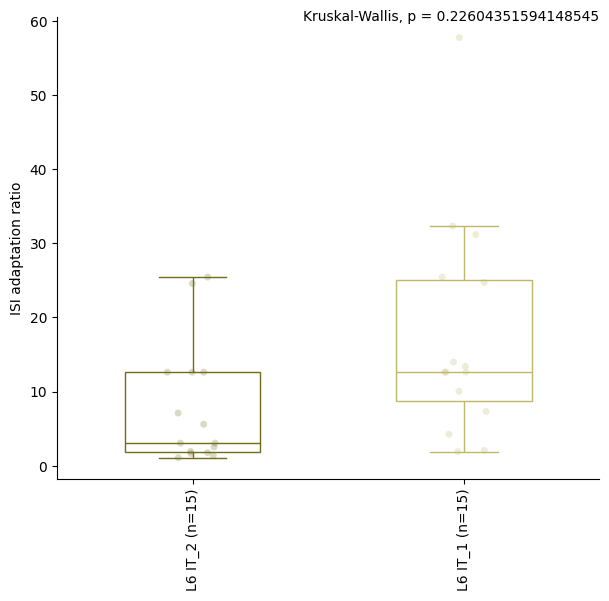

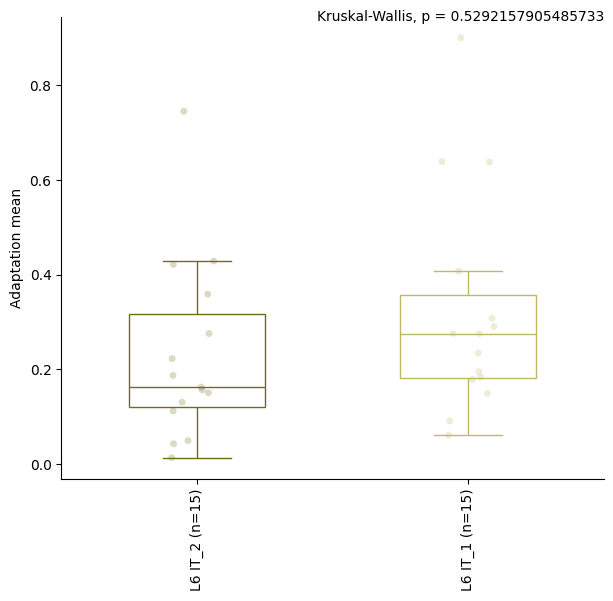

...

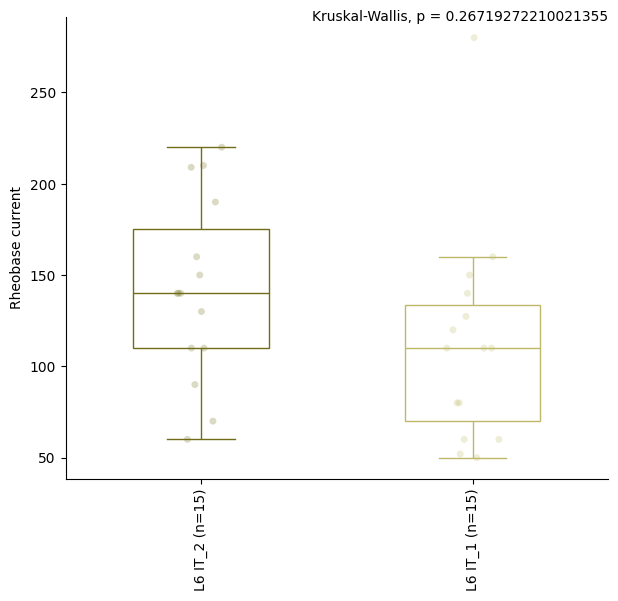

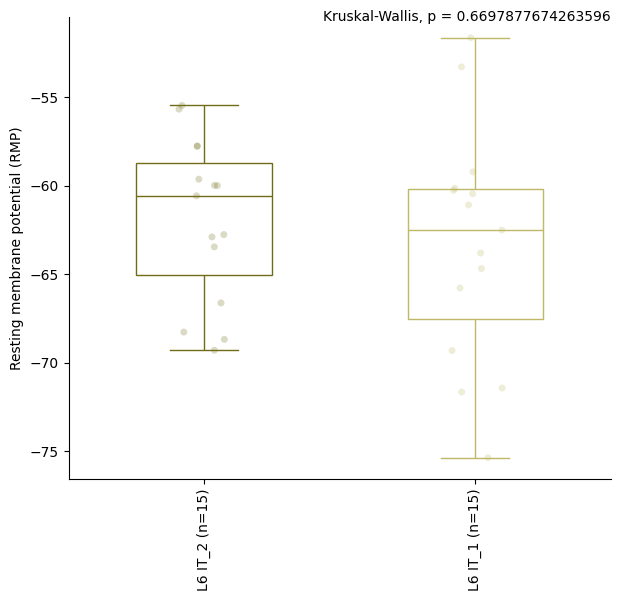

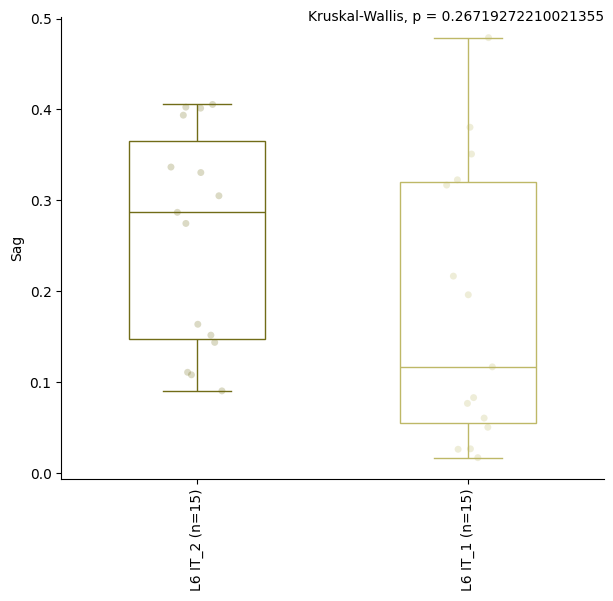

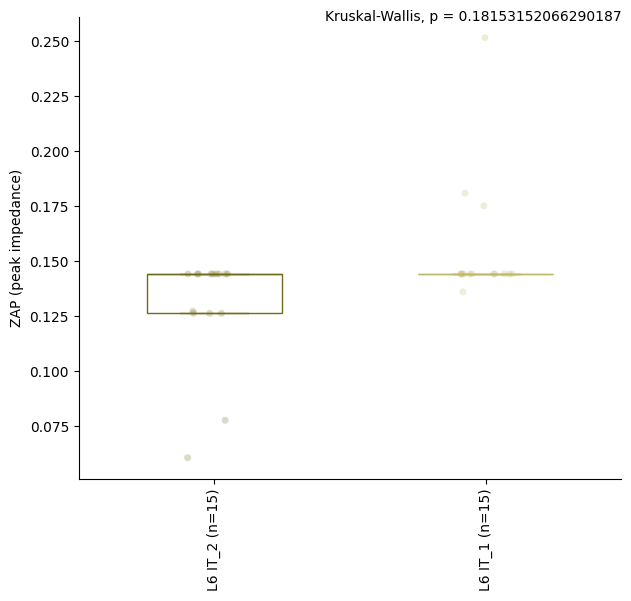

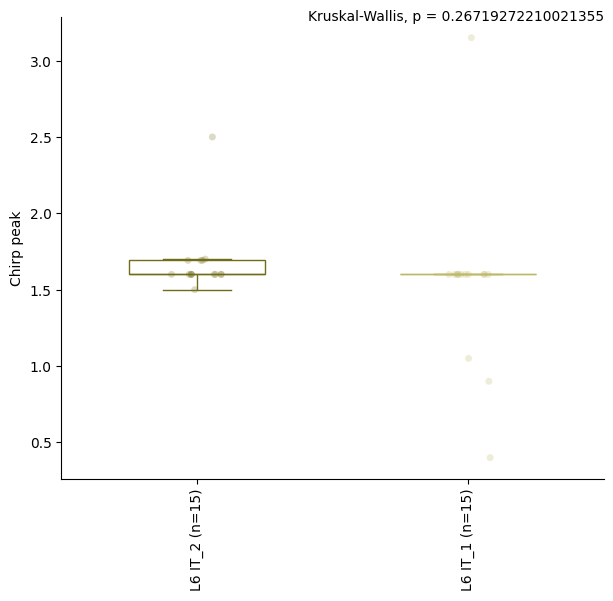

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

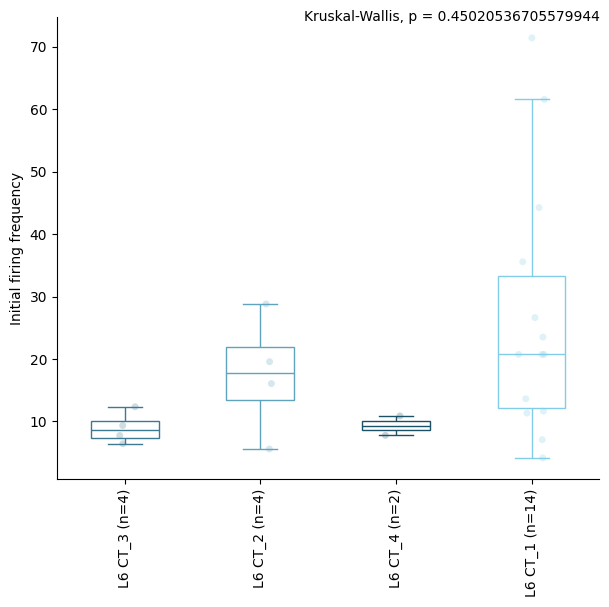

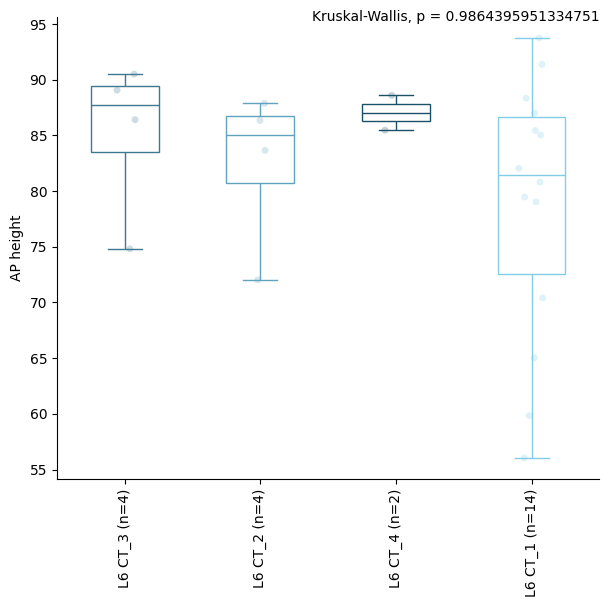

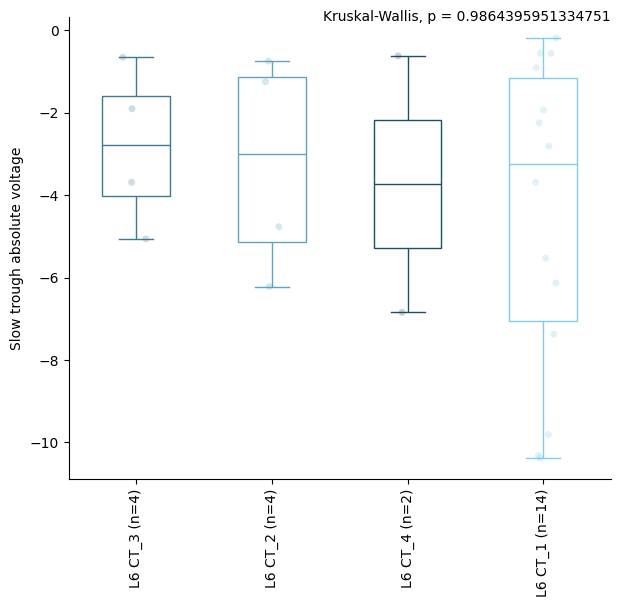

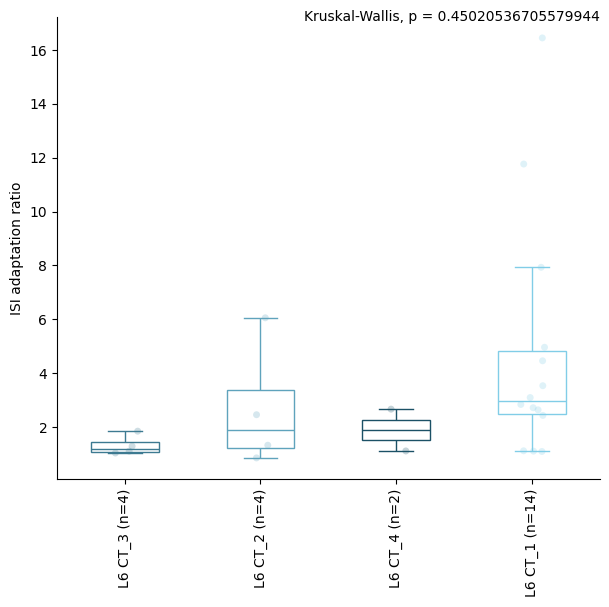

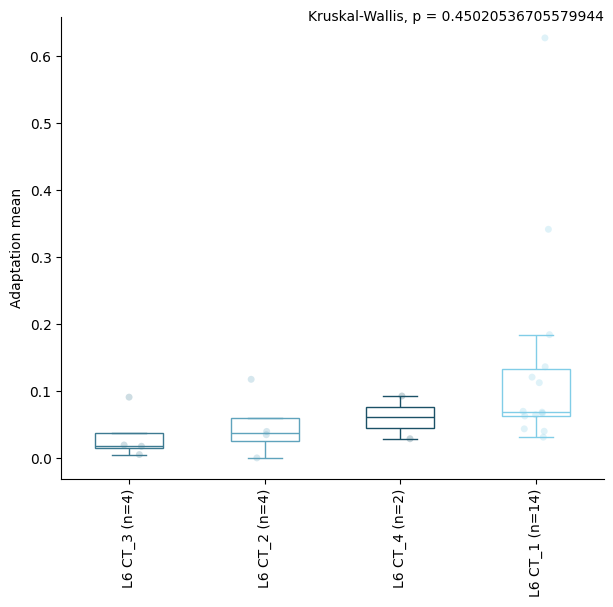

...

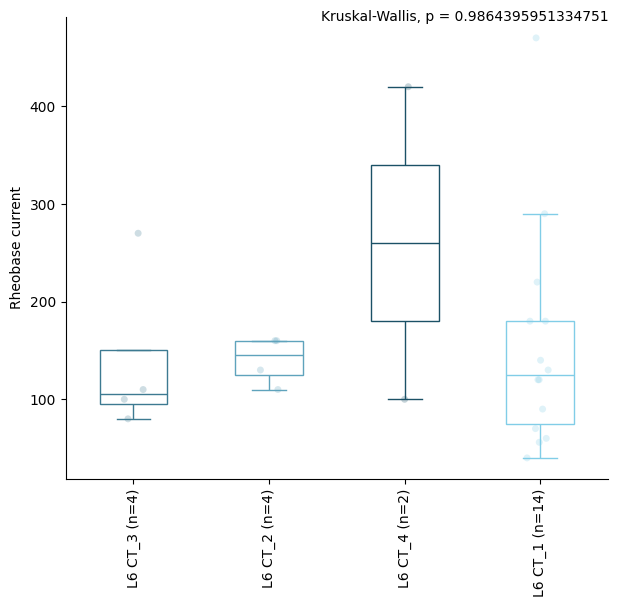

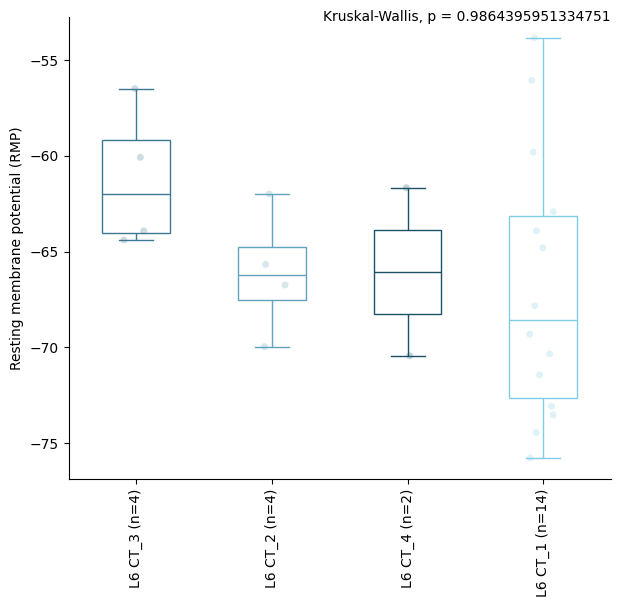

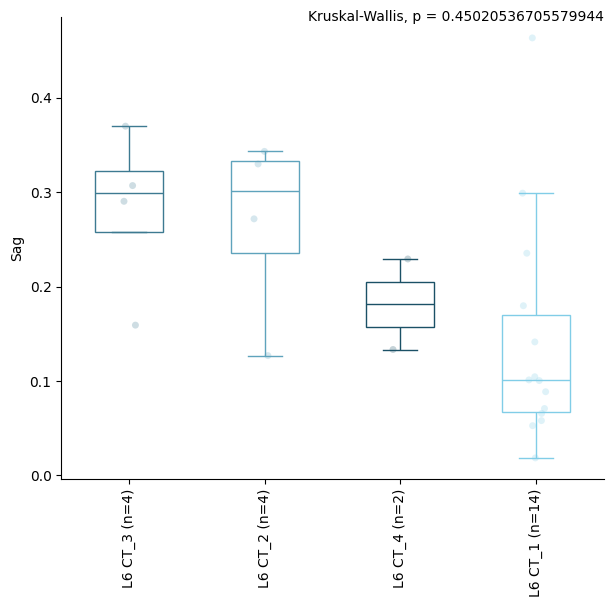

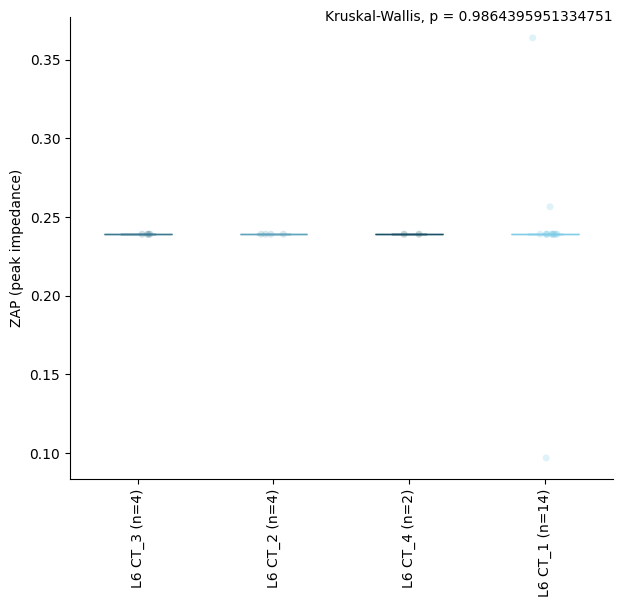

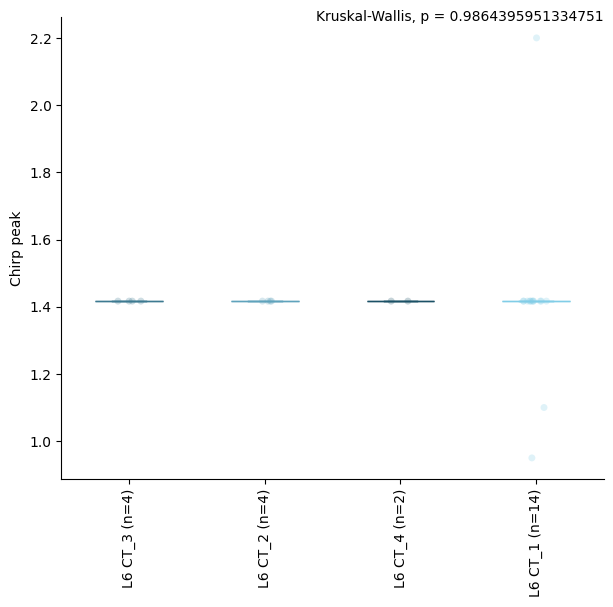

/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/578903445.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


<Figure size 640x480 with 0 Axes>

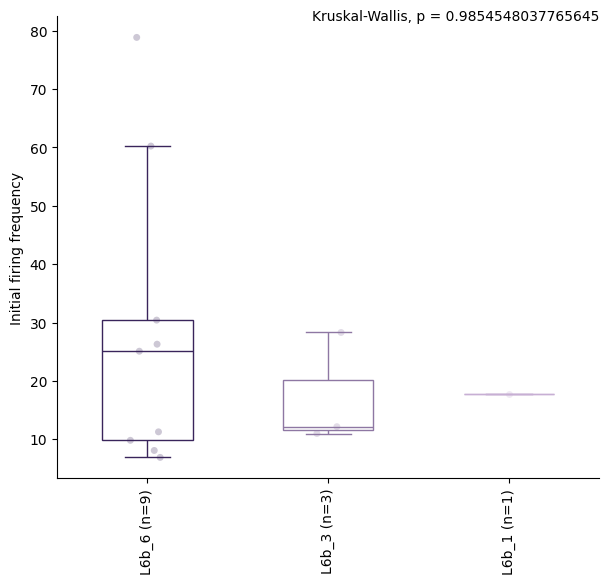

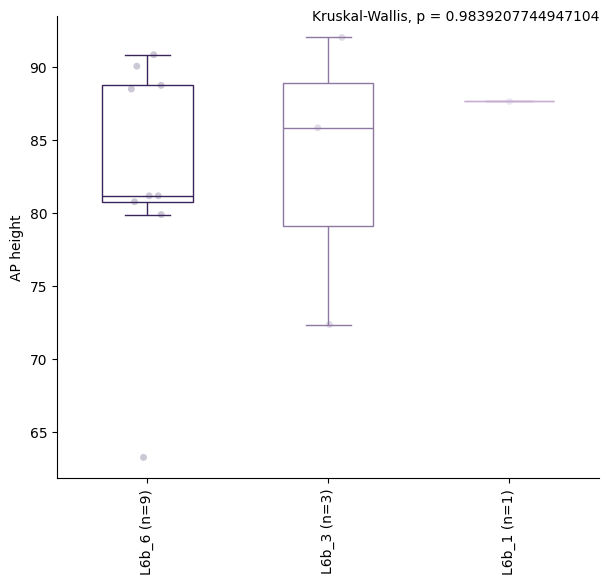

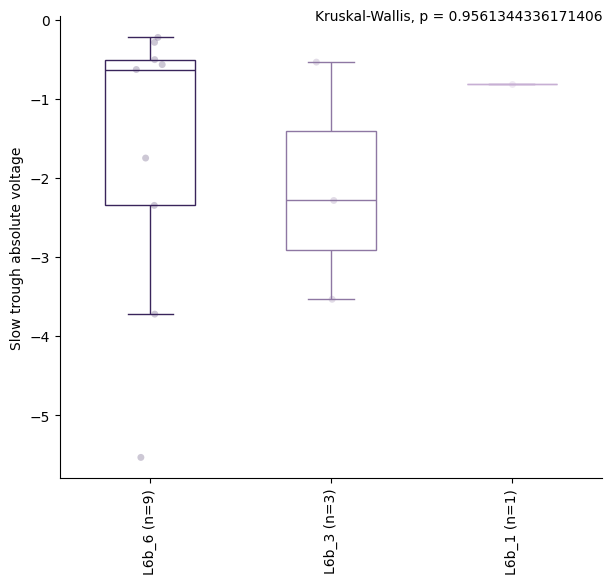

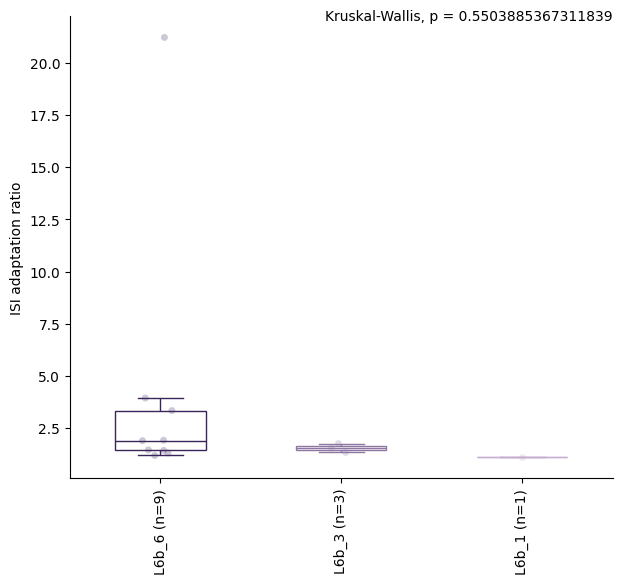

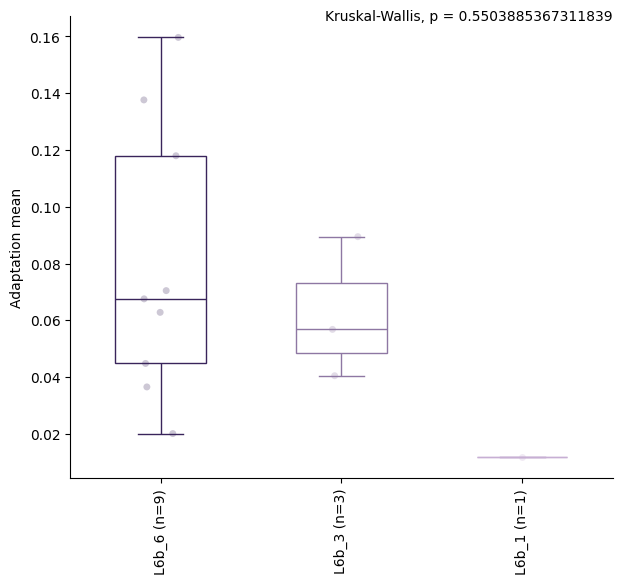

...

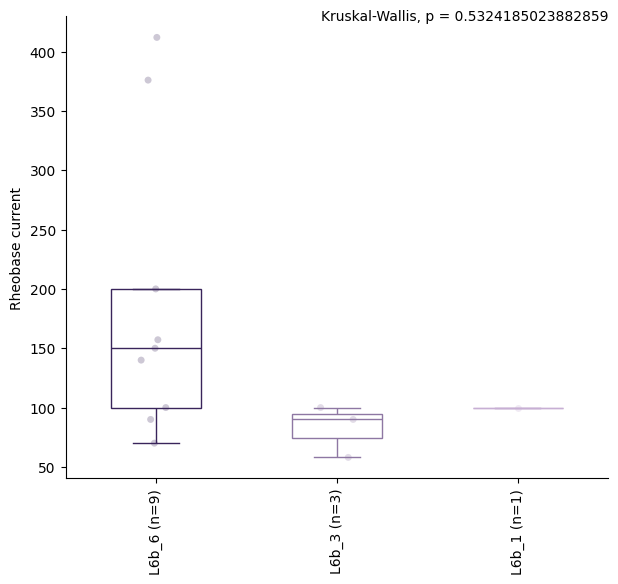

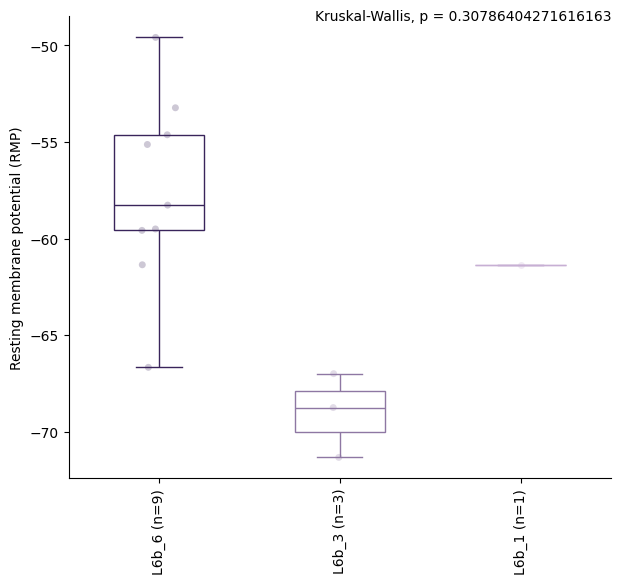

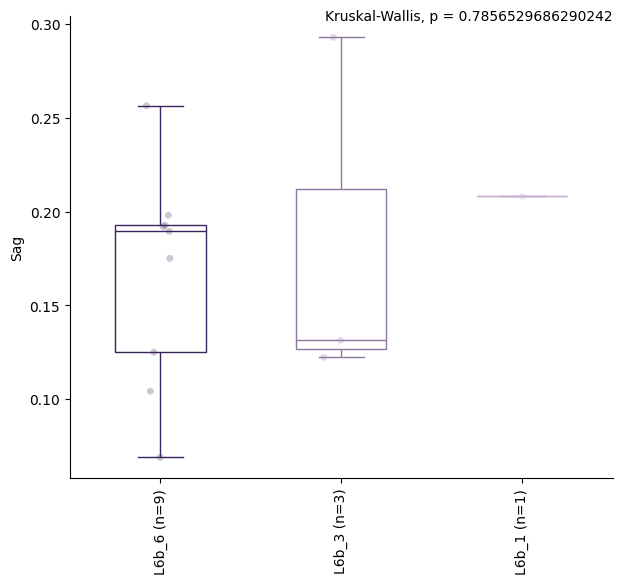

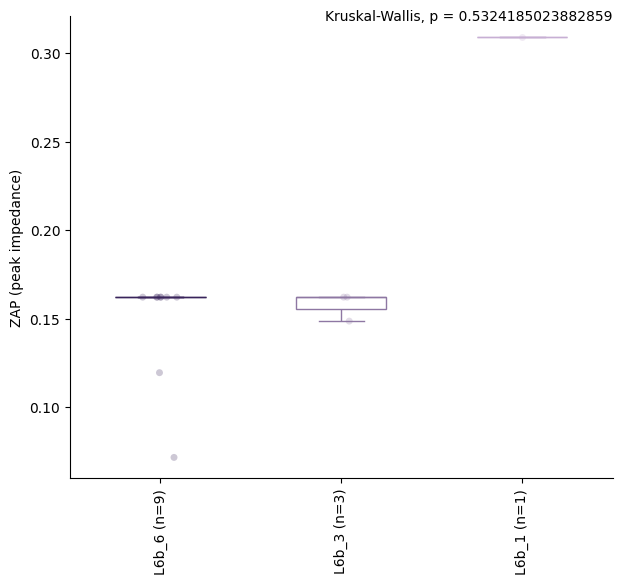

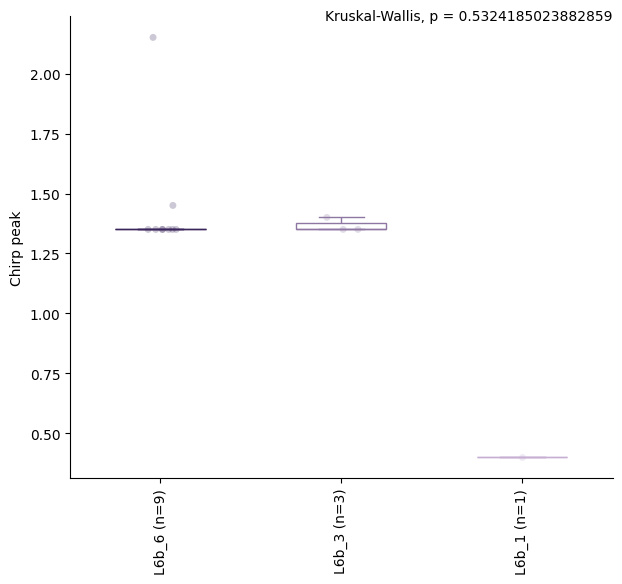

<Figure size 640x480 with 0 Axes>

In [16]:
# ttype x feature box plots

ttype_order = group_order['t_type']

for subclass in kw_pvals_fdr_subclass.keys():
    if kw_pvals_fdr_subclass[subclass]:
        #subclass has results (there were enough ttypes in the subclass, etc.)
        subclass_data = sorted_clean_data.loc[sorted_clean_data[subcalss_var] == subclass]
        kw_pvals_fdr = kw_pvals_fdr_subclass[subclass]  
        dunn_pvals_fdr = dunn_pvals_fdr_subclass[subclass]
        x_var = 't_type'  # what to do box plots on
        x_var_order = [t for t in ttype_order if t in subclass_data[x_var].unique()]

        #ADJUST VARS
        fig_name = 'human_excitatory_boxplots_ephys_features_KW_Dunn_FDR_{}_byTtype.pdf'.format(subclass.replace('/', '-').replace(' ', '_'))
        color_palette = color_dict #colors for x_var
        hue_var = 't_type' #seperate strip plots into these categories 
        hue_color_palette = color_dicts[hue_var] #color palette for hue_var
        ##### MAKE SURE TO UPDATE KRUSKAL CALL IN CODE BELOW TO CONTAIN ALL THE X_VAR GROUPS #####

        #######################

        fig_path = os.path.join(output_dir, fig_name)
        ephys_features = feature_cols.copy()

        with warnings.catch_warnings():
            warnings.simplefilter(action='ignore', category=FutureWarning)

            with PdfPages(fig_path) as pdf:
                while ephys_features != []:
                    
                    #one fig per page, each has page (fig) has 4 rows. 
                    fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
                    # for ax in axes: #plot as many neurons as fit on this page (num_rows rows of plotting)
                    
                    y_var = ephys_features.pop()
                    
                    sns.stripplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, alpha=0.25)
                    sns.boxplot(data=subclass_data, x=x_var, y=y_var, ax=ax, order=x_var_order, palette=color_palette, saturation=1, showfliers = False, width=0.5)
                    format_box_plot(ax) #color line not fill of boxplot


                    #add num observations per x_var
                    nobs = []
                    for t in x_var_order:
                        n = len(subclass_data[subclass_data[x_var] == t])
                        nobs.append(" (n=%s)" % str(n))
                    new_x_tick_labels = [x_var_order[i] + nobs[i] for i in range(len(x_var_order))]  
                    ax.set_xticklabels(new_x_tick_labels)

                    # add stats (KW w/ Dunn post hoc FDR corrected)

                    #plot signif dunn fdr p-vals 
                    if y_var in dunn_pvals_fdr.keys(): 
                        #kw fdr val was signif so there are dunn fdr vals to plot
                        
                        this_dunn_pvals_fdr = dunn_pvals_fdr[y_var]
                        remove = np.tril(np.ones(this_dunn_pvals_fdr.shape), k=0).astype("bool")
                        this_dunn_pvals_fdr[remove] = np.nan
                        dunn_pvals_fdr_melt = this_dunn_pvals_fdr.melt(ignore_index=False).reset_index().dropna()

                        #set insignificant pvals to nan 
                        p_thresh = 0.05 #threshold for plotting p vals 
                        dunn_pvals_fdr_melt.drop(dunn_pvals_fdr_melt[dunn_pvals_fdr_melt['value'] > p_thresh].index, inplace = True)

                        #plot bar for all signif fdr corrected dunn p vals 
                        pairs = [(i[1]["index"], i[1]["variable"]) for i in dunn_pvals_fdr_melt.iterrows()]
                        if len(pairs): 
                            #there's at least one pair of x_vals for which fdr corrected dunn test is signif
                            p_values = [i[1]["value"] for i in dunn_pvals_fdr_melt.iterrows()]                    
                            annotator = Annotator(ax, pairs, data=subclass_data, x=x_var, y=y_var, order=x_var_order)
                            annotator.configure(text_format="star", loc="inside") #text_format="simple"
                            annotator.set_pvalues_and_annotate(p_values)
                            
                    #plot Kruskal-Wallis fdr p-vals
                    if y_var in kw_pvals_fdr.keys():
                        xlimit = ax.get_xlim()
                        ylimit = ax.get_ylim()
                        p_txt = 'Kruskal-Wallis, p = ' + str(kw_pvals_fdr[y_var])
                        ax.text(xlimit[1], ylimit[1], p_txt, verticalalignment='center', horizontalalignment='right')

                    #rotate and format x_var labels 
                    ax.set(xlabel=None)
                    ax.tick_params(axis='x', rotation=90)
                    ax.set_ylabel(y_var.replace("_", " "), rotation=90)
                    ax.spines[['right', 'top']].set_visible(False)

                    fig.subplots_adjust(wspace=0, hspace=0.0)
                    pdf.savefig(dpi=600, bbox_inches='tight')
                plt.show()
                plt.clf()
                print()



Cross areal box plots - subclass

In [18]:
# subclass x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 'subclass_label'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_Other: Custom statistical test, P_val:7.967e-03


/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.125e-02


/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:6.492e-03
L2/3 IT_TemL vs. L2/3 IT_Other: Custom statistical test, P_val:7.888e-10
L5 IT_TemL vs. L5 IT_Other: Custom statistical test, P_val:1.768e-02


... (9 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:4.511e-04


/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/234911206.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_Other: Custom statistical test, P_val:1.947e-02


/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/234911206.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


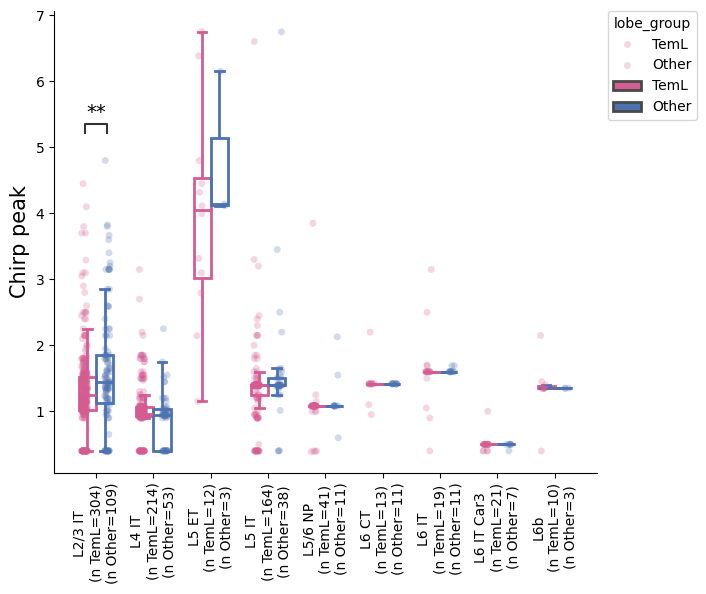

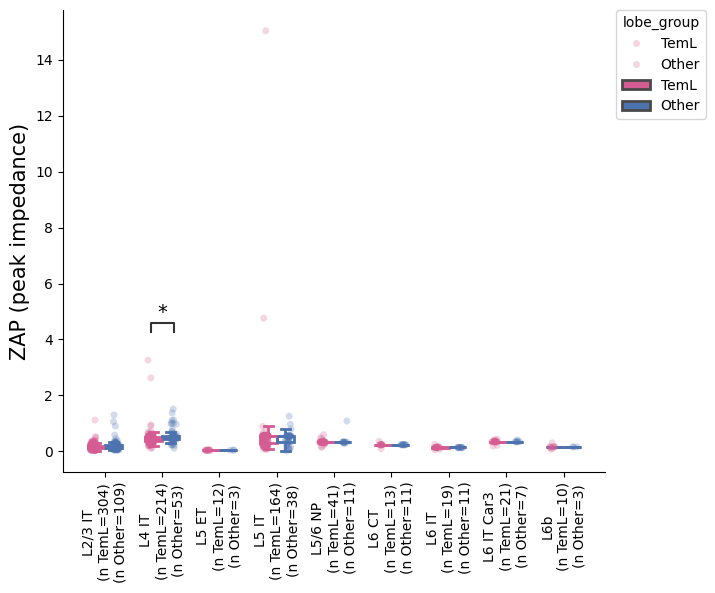

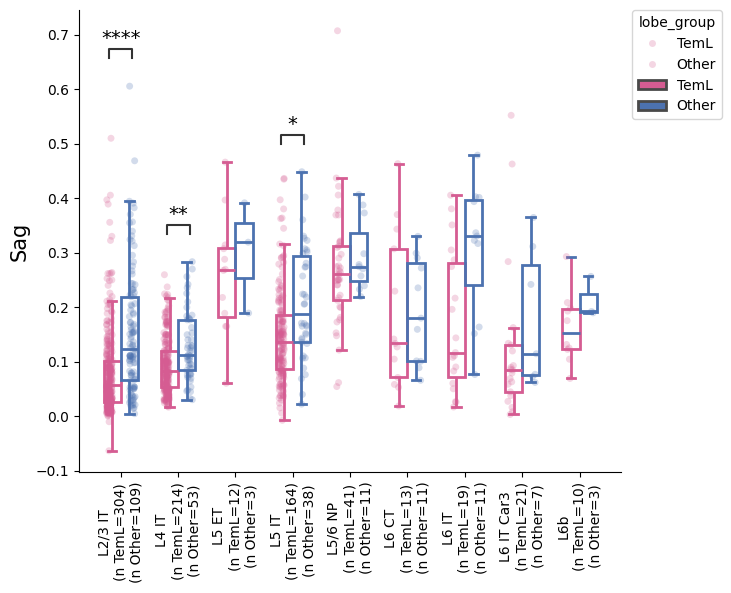

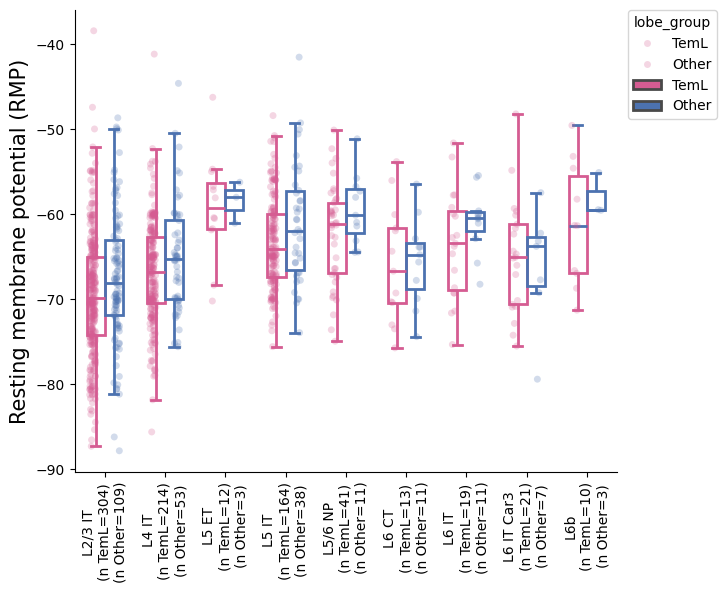

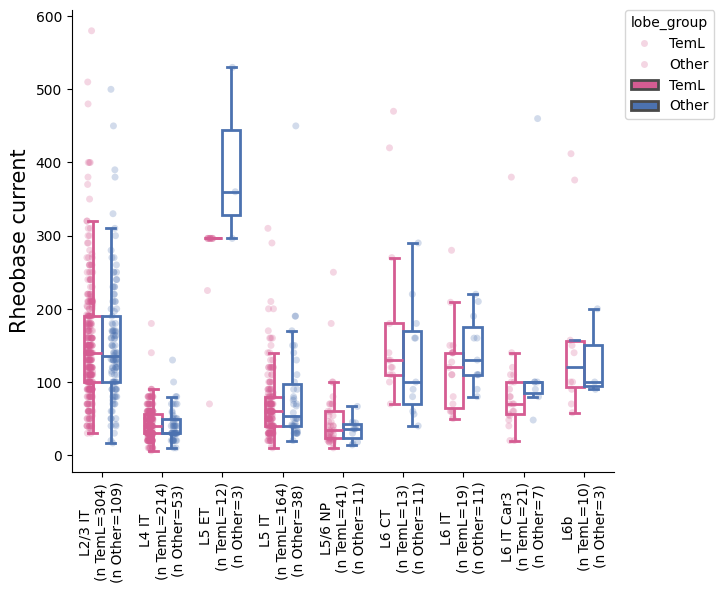

...

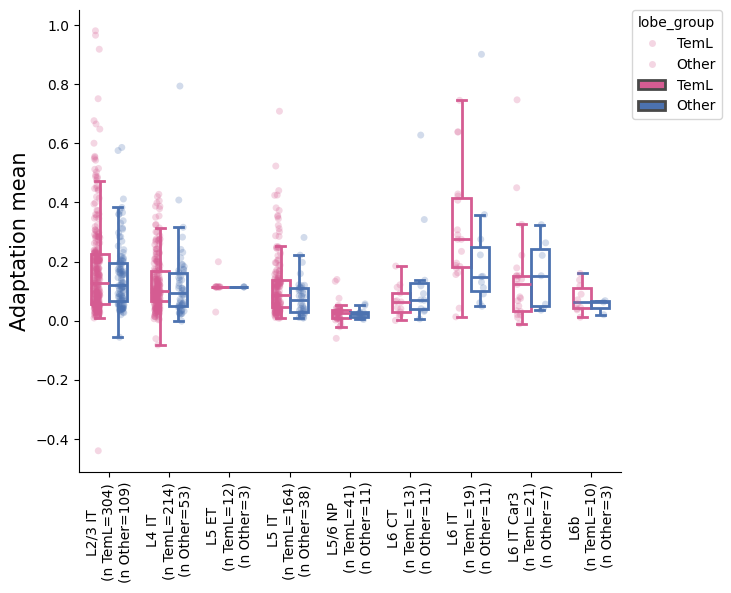

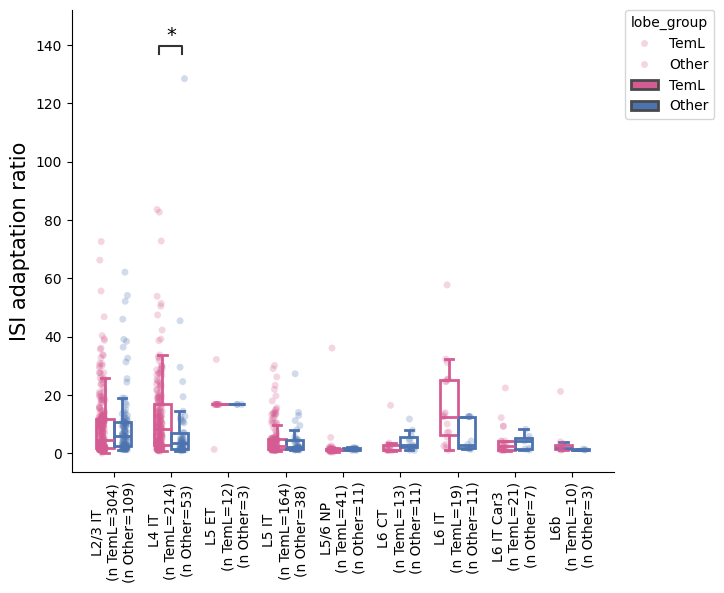

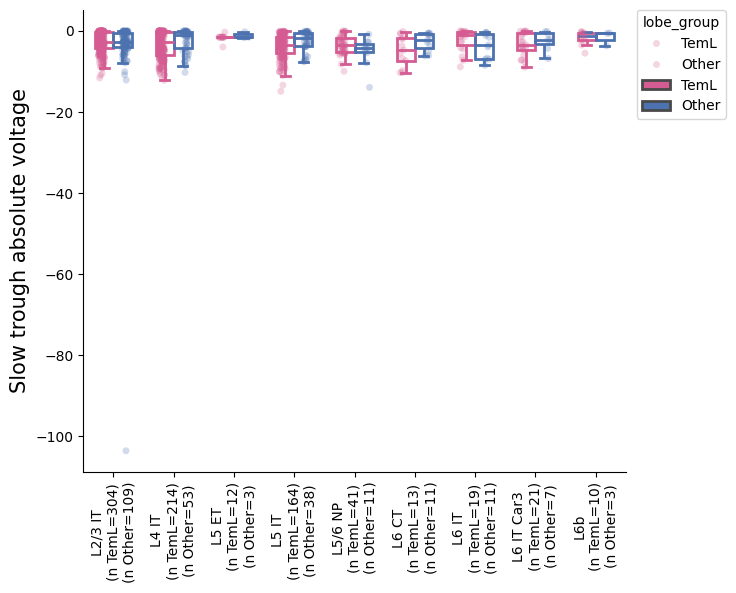

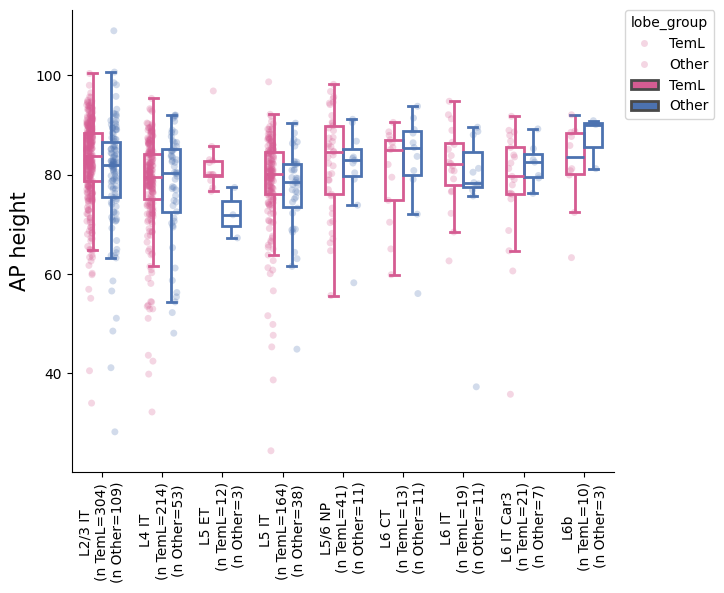

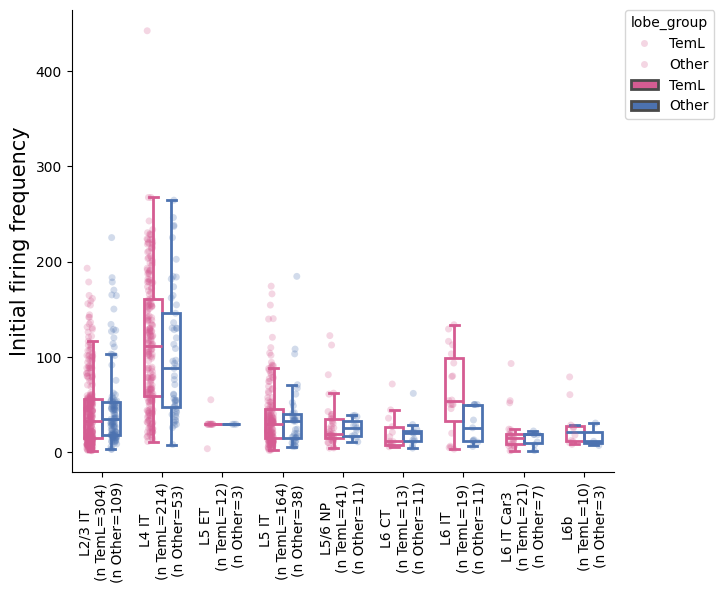

Boxplots with Mann-Whitney U stats saved.


In [19]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            # sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype 

In [20]:
# ttype x feature box plots

x_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
group_var = 't_type'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_1094812/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2678593707.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

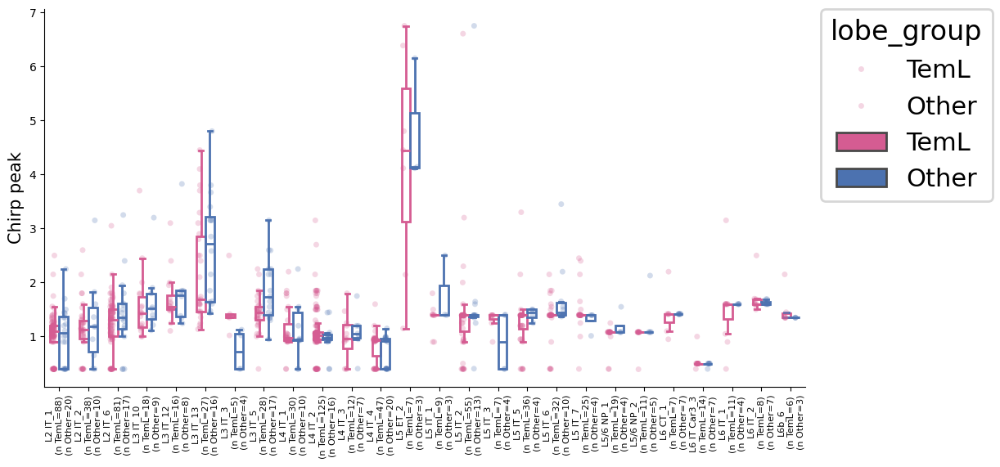

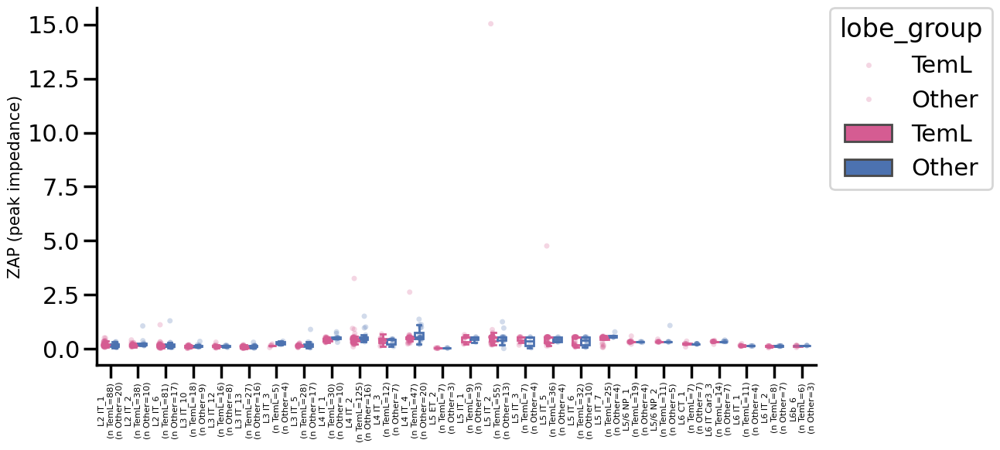

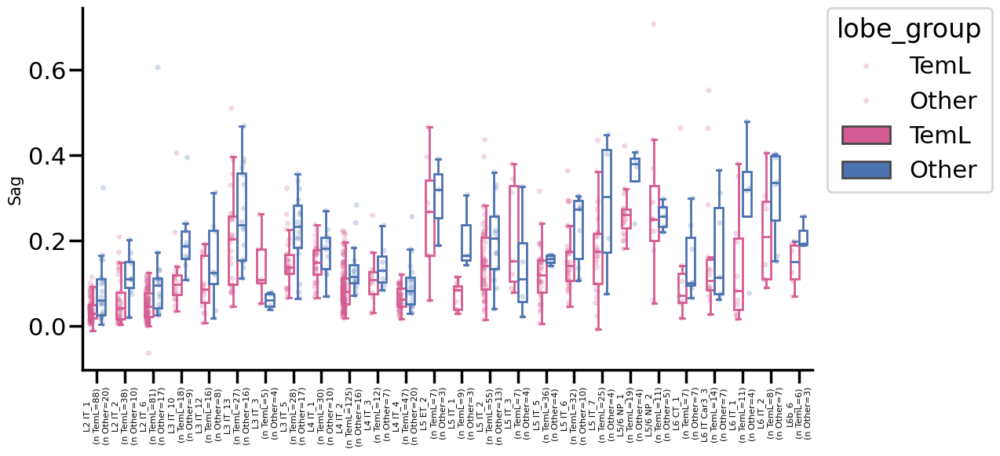

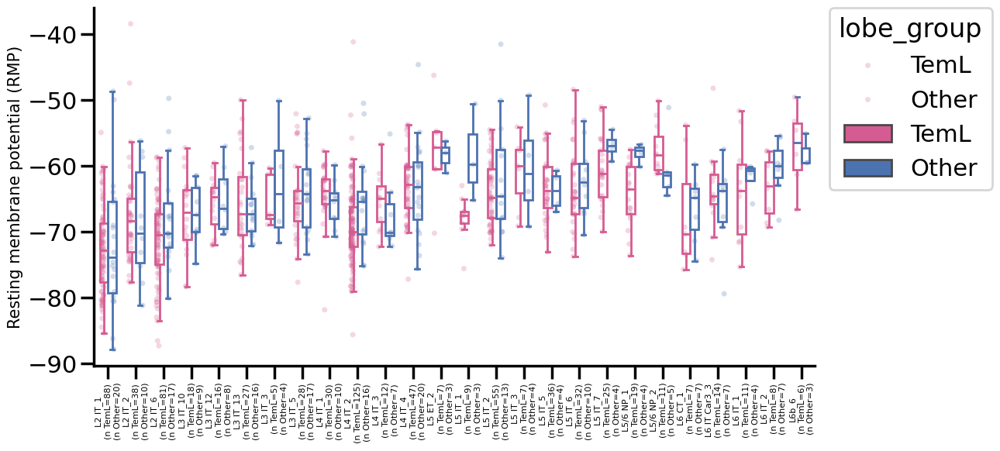

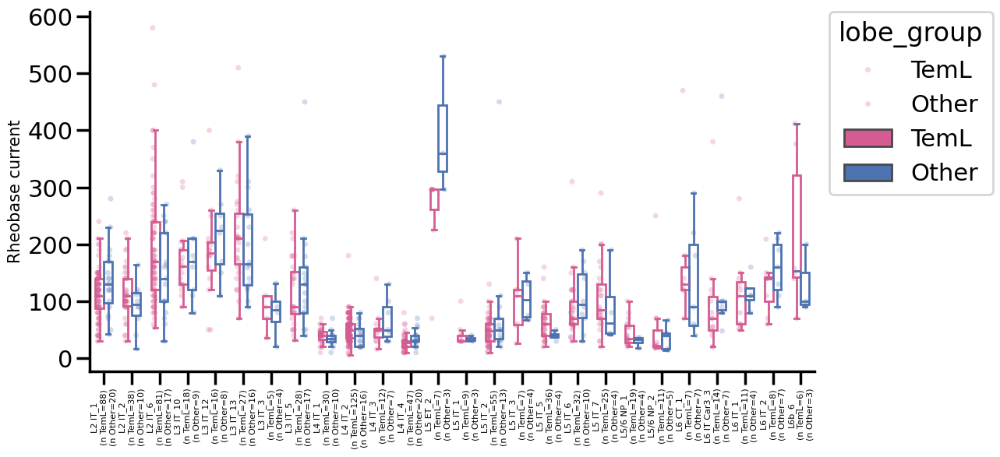

...

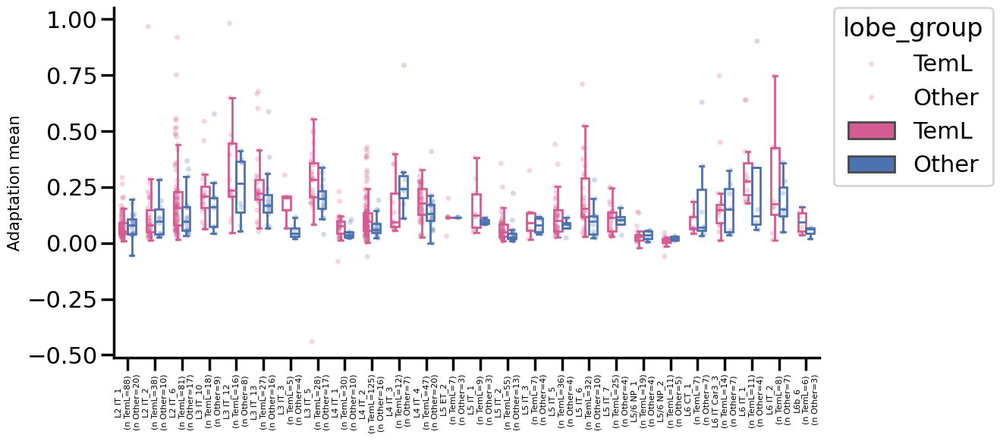

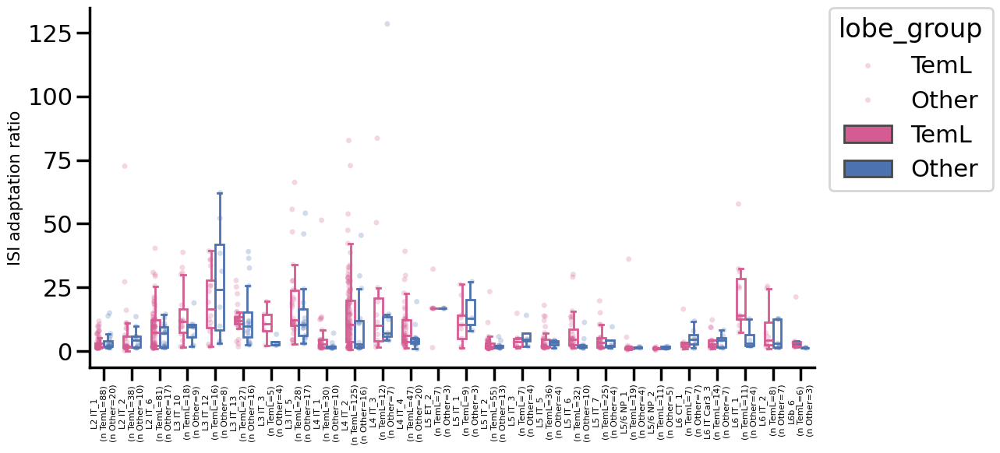

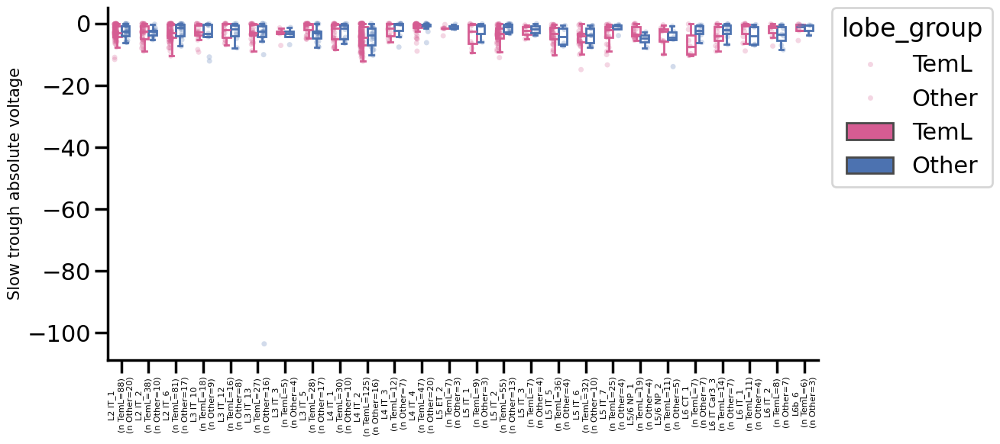

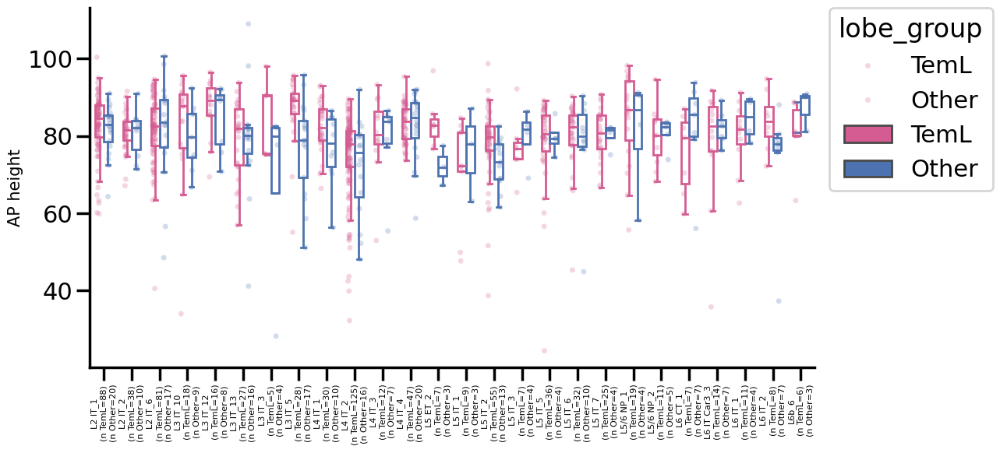

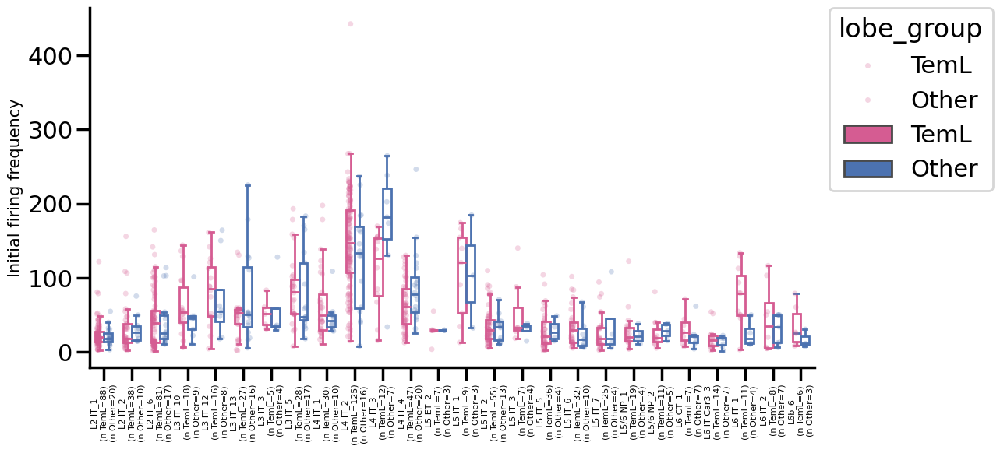

In [21]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe_group'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'Other']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
                 
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'TemL')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'Other')])
                nobs.append("\n(n TemL={})\n(n Other={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'Other')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross areal box plots - subclass - TemL vs FroL

In [22]:
# subclass x feature box plots

x_var = 'lobe'
x_var_order = group_order[x_var]
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 'subclass_label'

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in ephys_features:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:9.826e-03


/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:9.826e-03


/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:1.752e-05


... (5 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:9.826e-03


/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:9.826e-03


/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2292705234.py:21: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},
/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2292705234.py:45: UserWarning: set_ticklabels() should

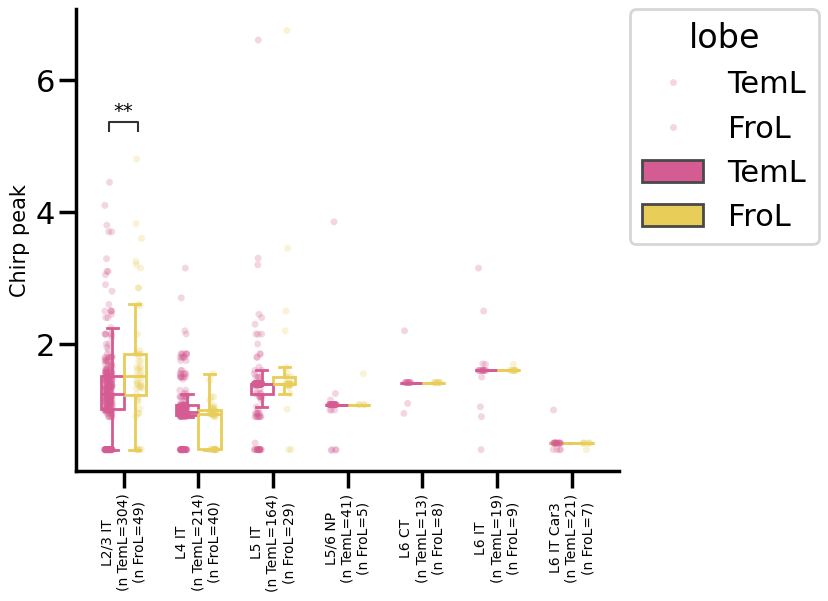

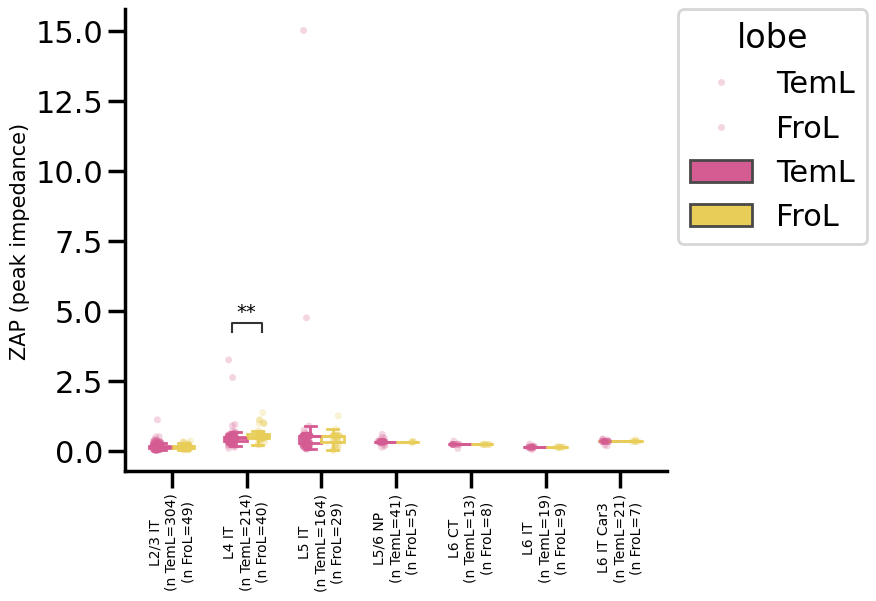

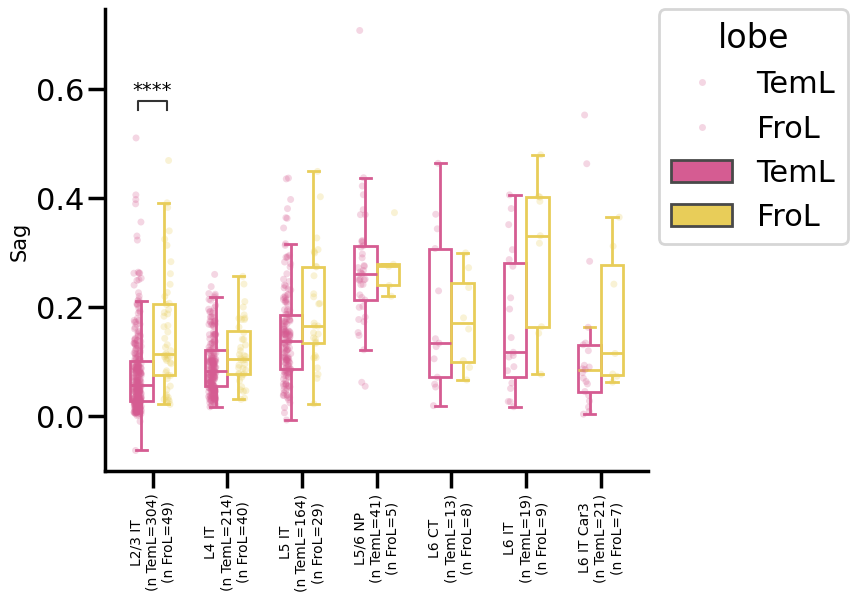

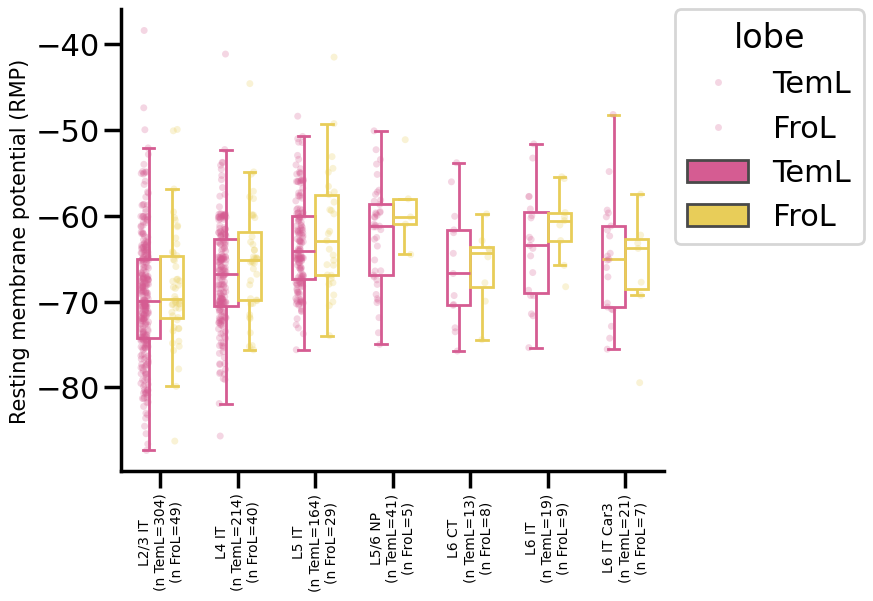

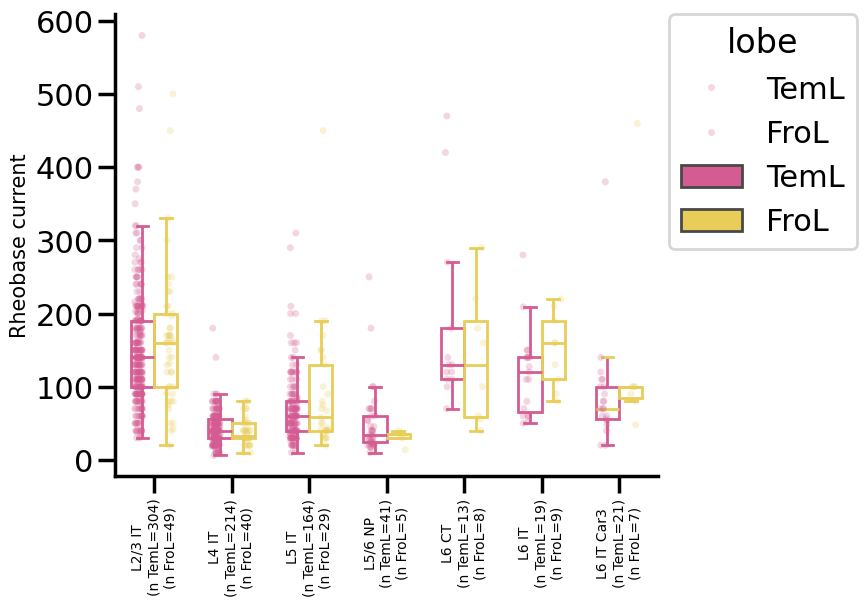

...

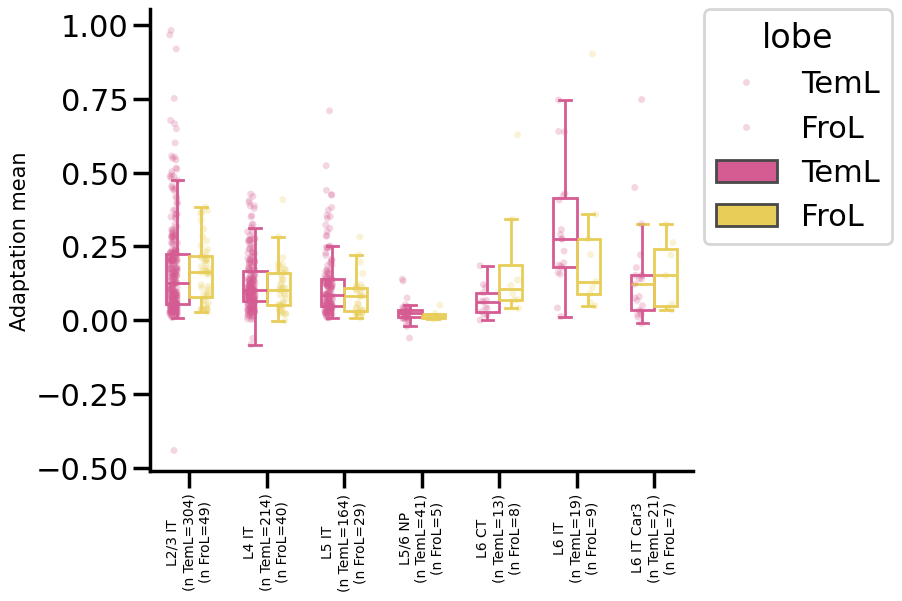

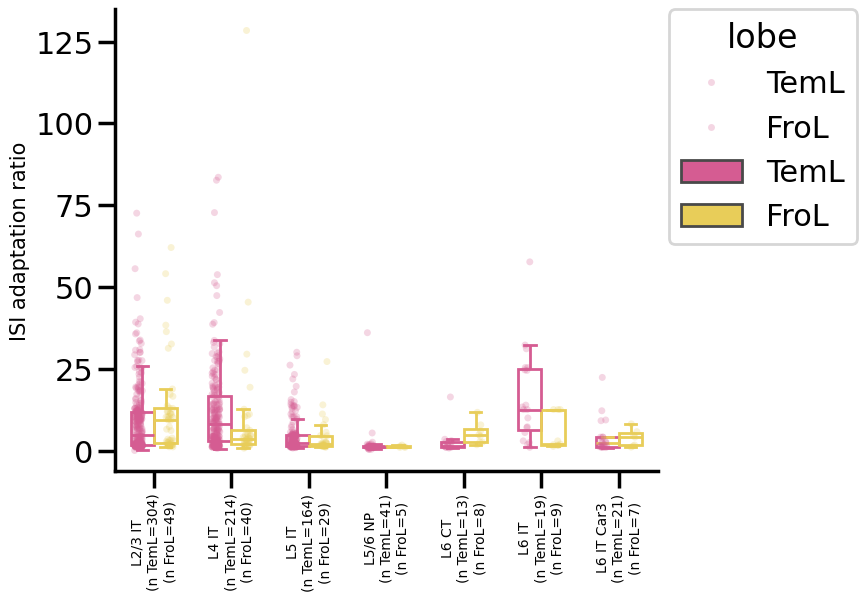

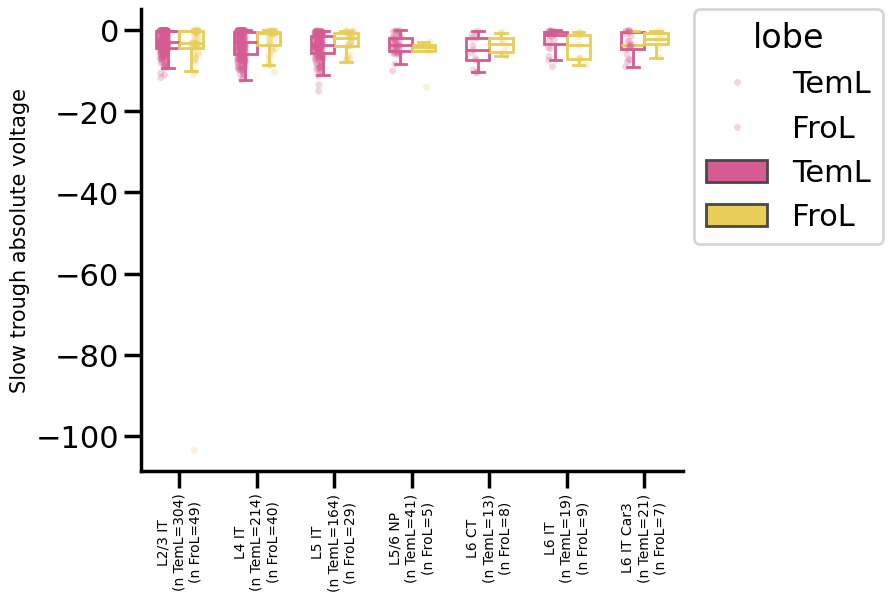

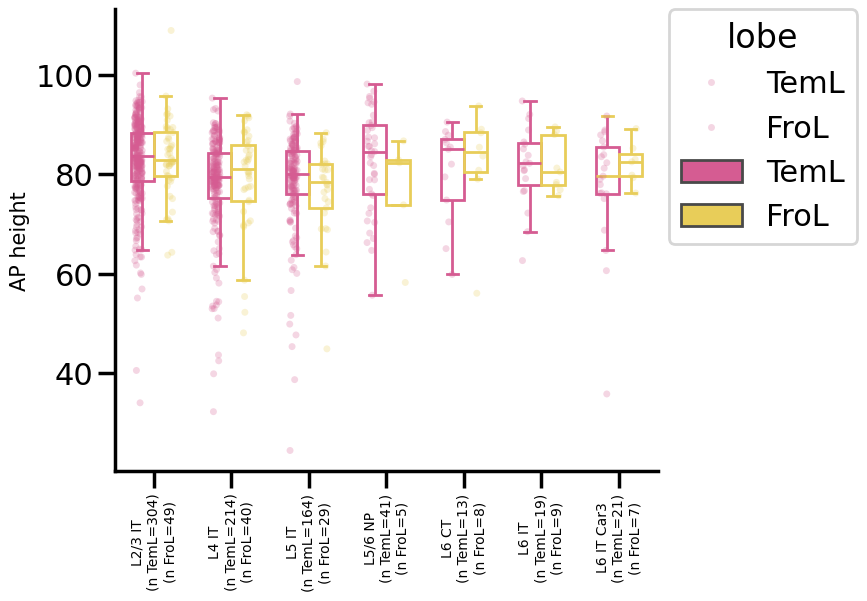

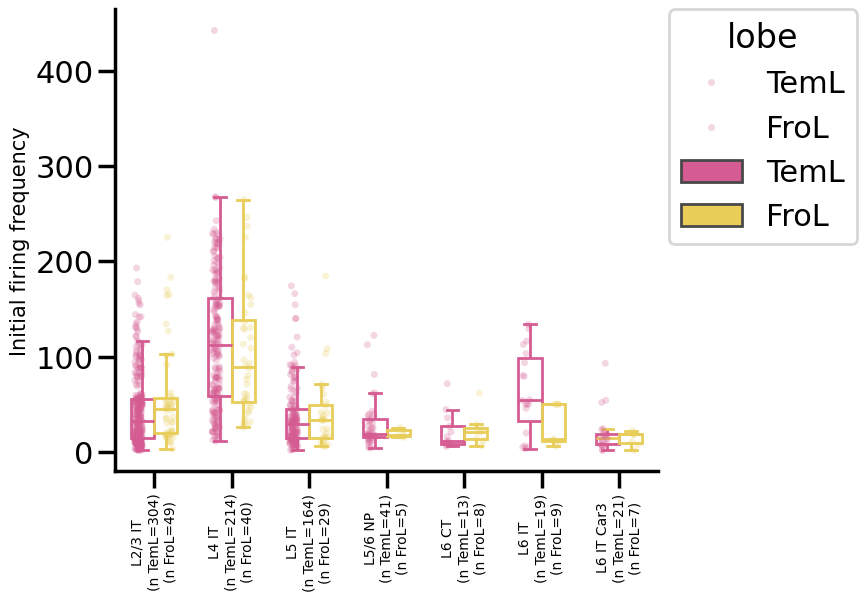

Boxplots with Mann-Whitney U stats saved.


In [23]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_teml_frol_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
                        
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross areal box plots - ttype - TemL vs FroL

In [24]:
# ttype x feature box plots

x_var = 'lobe'
x_var_order = ['TemL', 'FroL']
group1_label = 'TemL'
group2_label = 'FroL'
group_var = 't_type'

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[x_var].isin(x_var_order)]
n_min_cells = 3
combo_counts = this_sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = this_sorted_clean_data[this_sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_6_TemL vs. L2 IT_6_FroL: Custom statistical test, P_val:9.066e-03


/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/3033294357.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

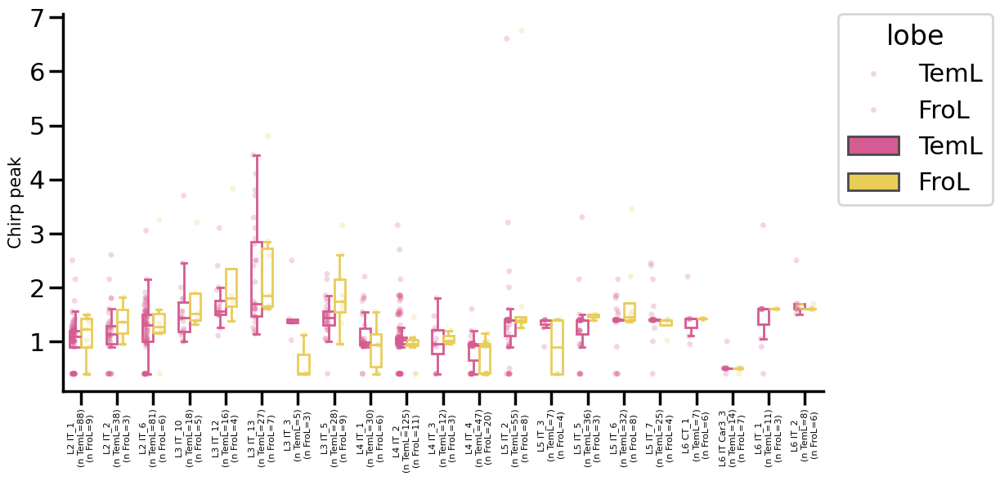

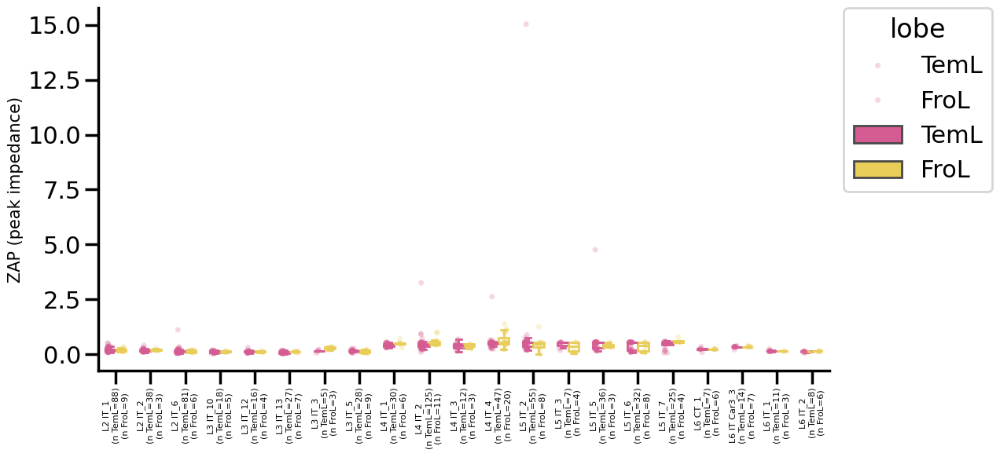

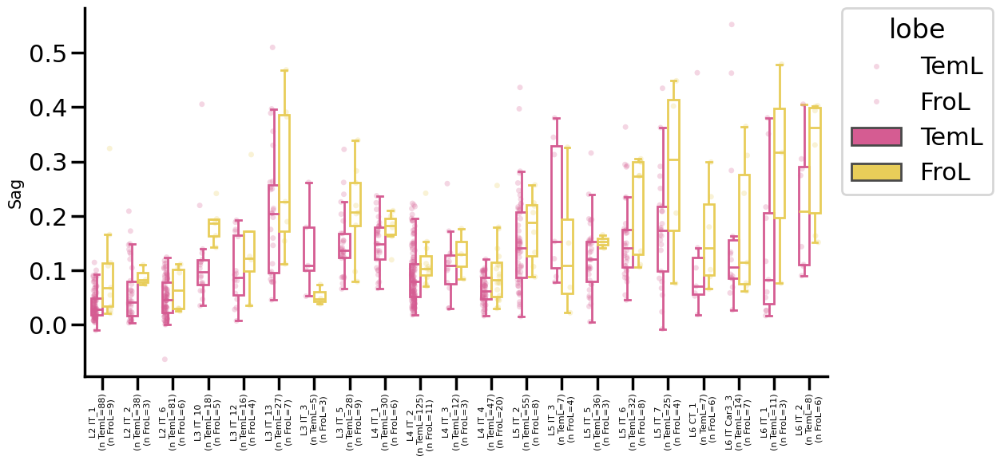

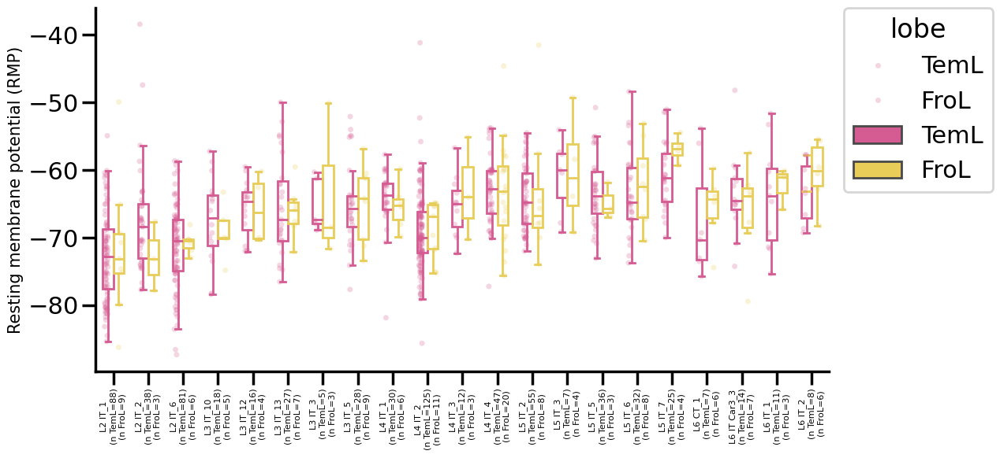

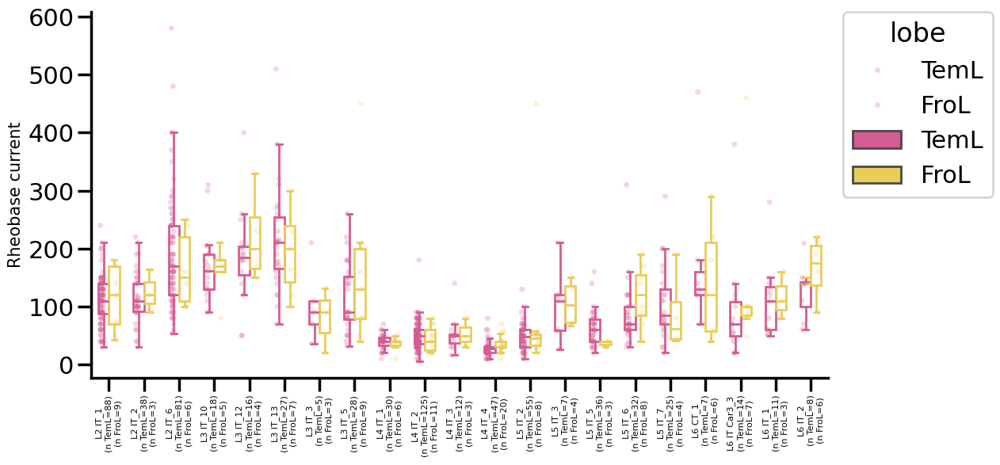

...

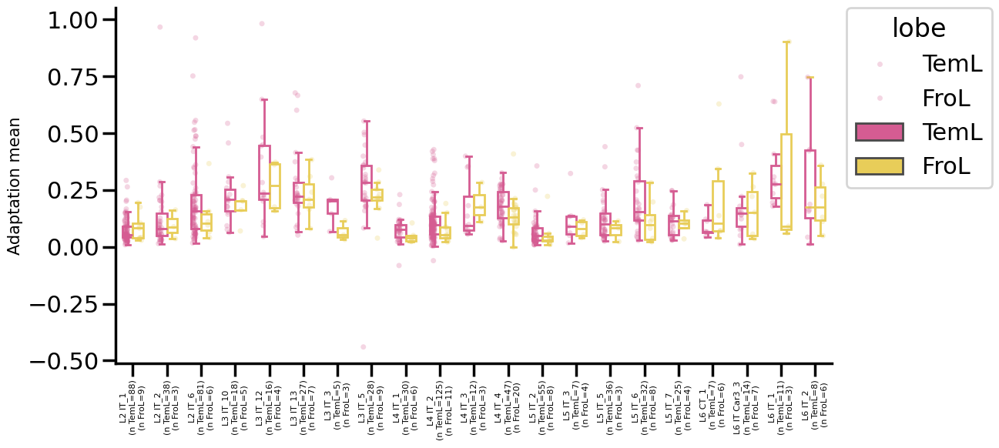

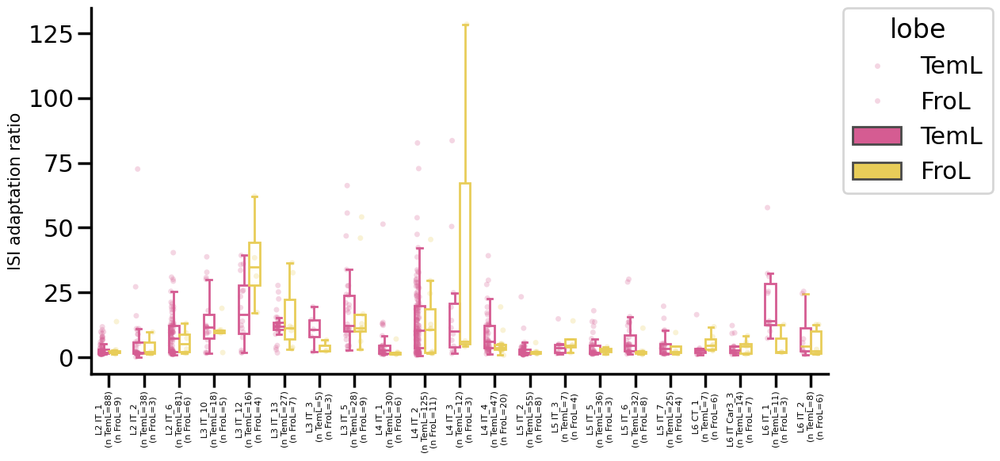

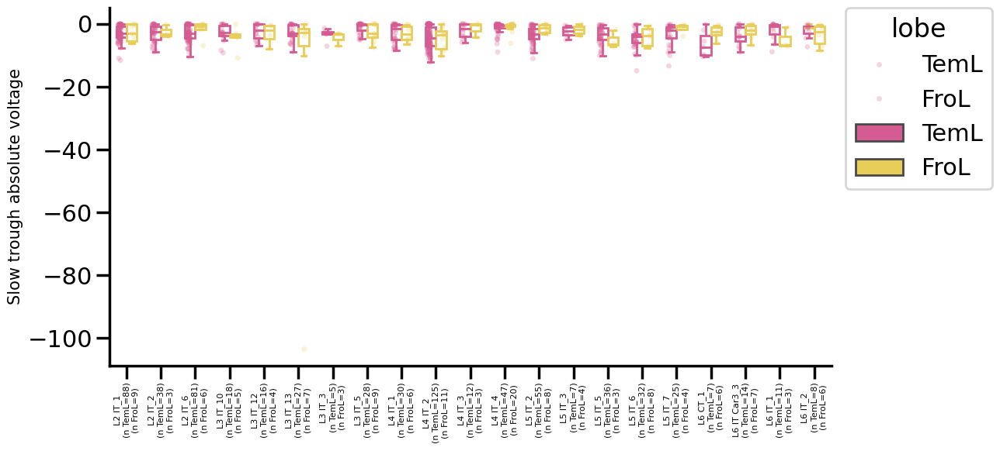

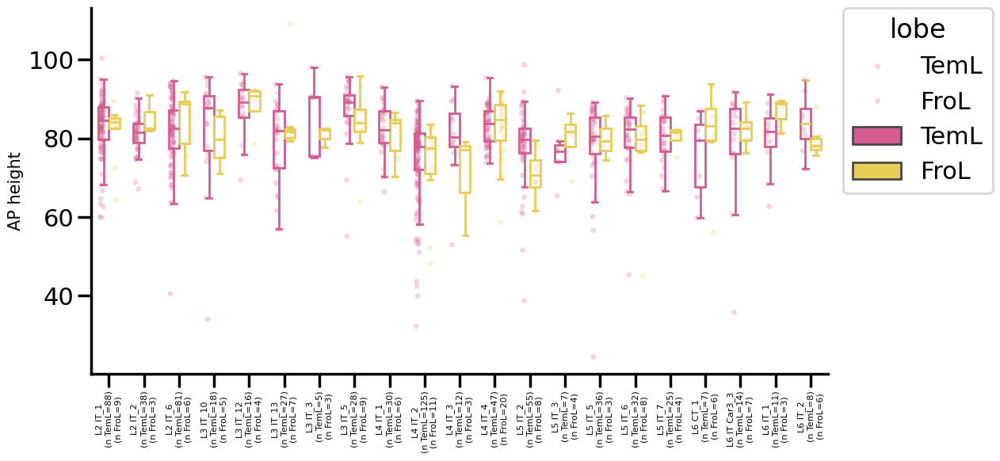

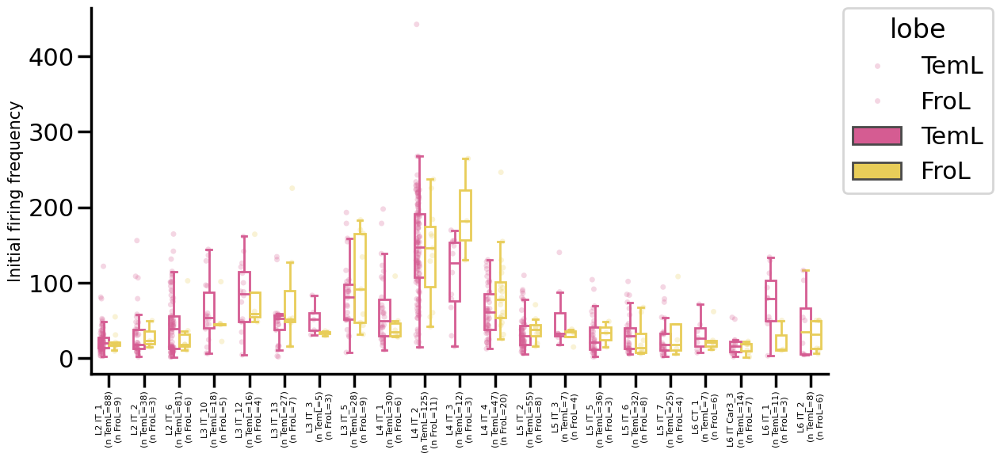

In [25]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_lobe_teml_frol_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'lobe'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['TemL', 'FroL']
color_palette = color_dicts[hue_var]

this_sorted_clean_data = sorted_clean_data[sorted_clean_data[hue_var].isin(hue_order)]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'TemL')])
                nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == 'FroL')])
                nobs.append("\n(n TemL={})\n(n FroL={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'TemL'), (subclass, 'FroL')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Cross paradigm box plots - subclass

In [26]:
# subclass x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 'subclass_label'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (subclass, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


In [27]:
#Save stats
rows = []
for (subclass, feature), pval in mw_pvals.items():
    rows.append({
        'subclass': subclass,
        'feature': feature,
        'mw_stat': mw_stats.get((subclass, feature)),
        'pval_raw': pval,
        'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
        'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
        'group1': group1_label,
        'group2': group2_label
    })

mw_stats_df = pd.DataFrame(rows)

# optional: sort for readability
mw_stats_df = mw_stats_df.sort_values(
    ['subclass', 'pval_fdr'],
    ascending=[True, True]
)

# save
mw_stats_df.to_csv(os.path.join(output_dir, r'ephys_feature_box_plot_stats_paradigm_subclass.csv'), index=False)
mw_stats_df

,subclass,feature,mw_stat,pval_raw,pval_fdr,rejected_pval_fdr,group1,group2
3,L2/3 IT,Resting membrane potential (RMP),2485.0,1.553534e-13,3.355634e-11,True,acute,culture
10,L2/3 IT,AP threshold,3620.0,4.899962e-09,1.763986e-07,True,acute,culture
2,L2/3 IT,Sag,3848.0,2.977162e-08,9.186672e-07,True,acute,culture
15,L2/3 IT,Trough voltage,4338.5,1.056921e-06,2.853686e-05,True,acute,culture
22,L2/3 IT,AP height,11277.0,7.352567e-06,1.443777e-04,True,acute,culture
...,...,...,...,...,...,...,...,...
192,L6b,Chirp peak,22.0,7.885526e-01,8.825252e-01,False,acute,culture
193,L6b,ZAP (peak impedance),18.0,7.885526e-01,8.825252e-01,False,acute,culture
199,L6b,Tau,21.0,9.432789e-01,9.890692e-01,False,acute,culture
197,L6b,FI slope,20.0,1.000000e+00,1.000000e+00,False,acute,culture


/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_acute vs. L4 IT_culture: Custom statistical test, P_val:3.580e-04
L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:9.187e-07
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.394e-10
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:3.760e-03
L6 IT_acute vs. L6 IT_culture: Custom statistical test, P_val:1.398e-04
L6 IT Car3_acute vs. L6 IT Car3_culture: Custom statistical test, P_val:1.664e-02


/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:3.356e-11
L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.646e-08
L5/6 NP_acute vs. L5/6 NP_culture: Custom statistical test, P_val:4.088e-05


/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:1.238e-03


... (20 outputs left out)

/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_acute vs. L2/3 IT_culture: Custom statistical test, P_val:1.444e-04


/tmp/ipykernel_1094812/2574612311.py:43: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_acute vs. L5 IT_culture: Custom statistical test, P_val:4.960e-04


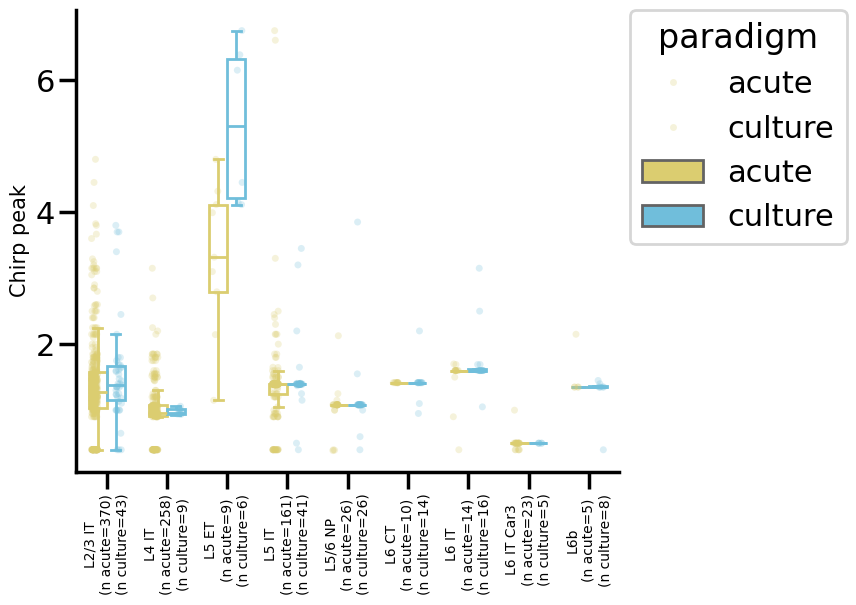

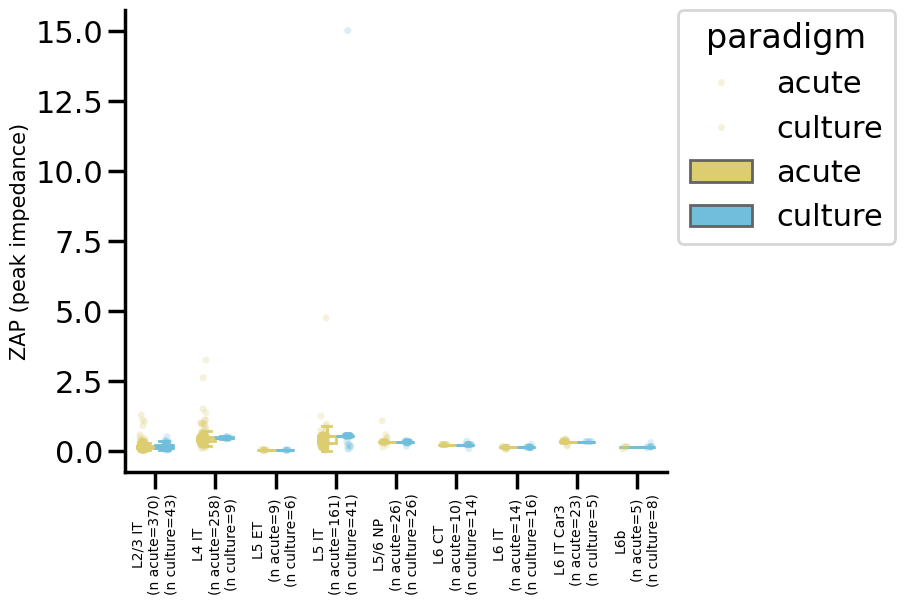

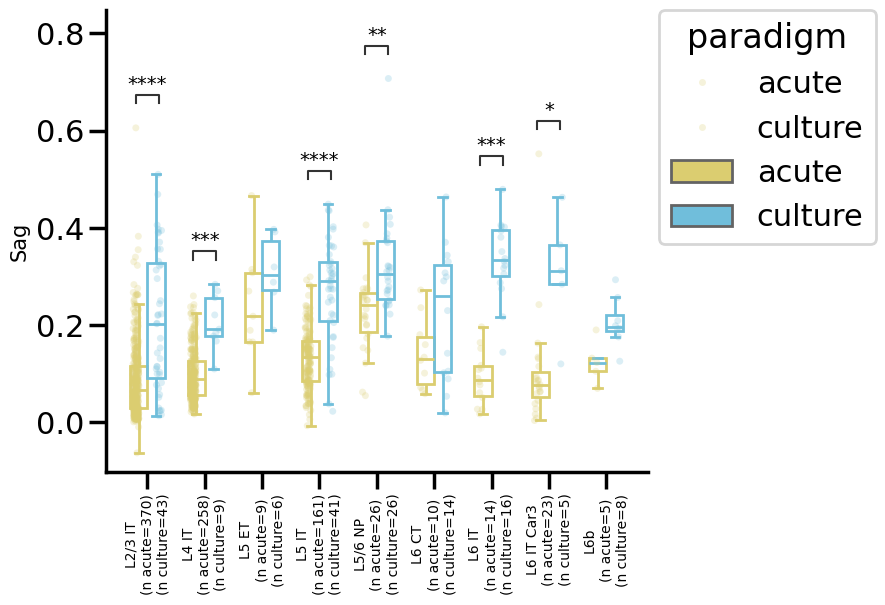

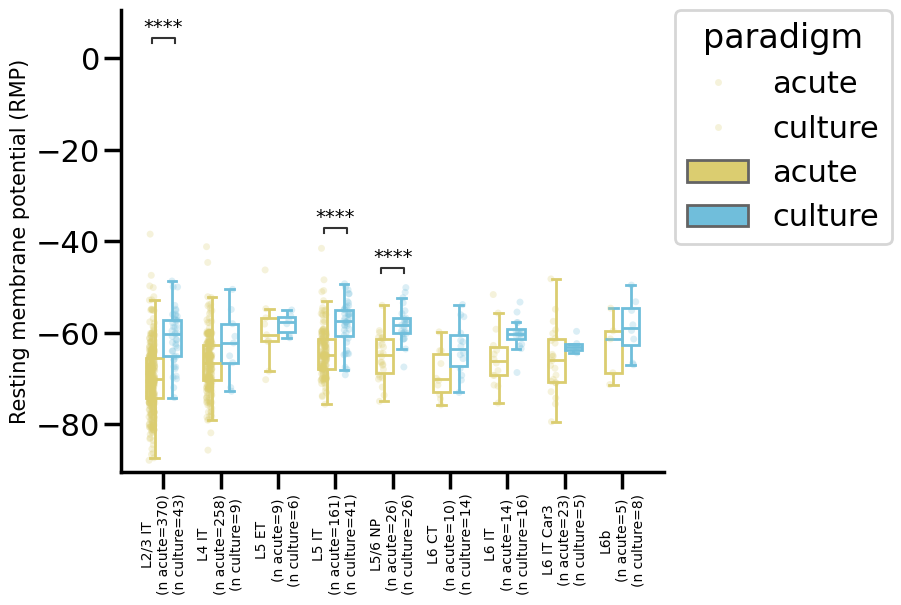

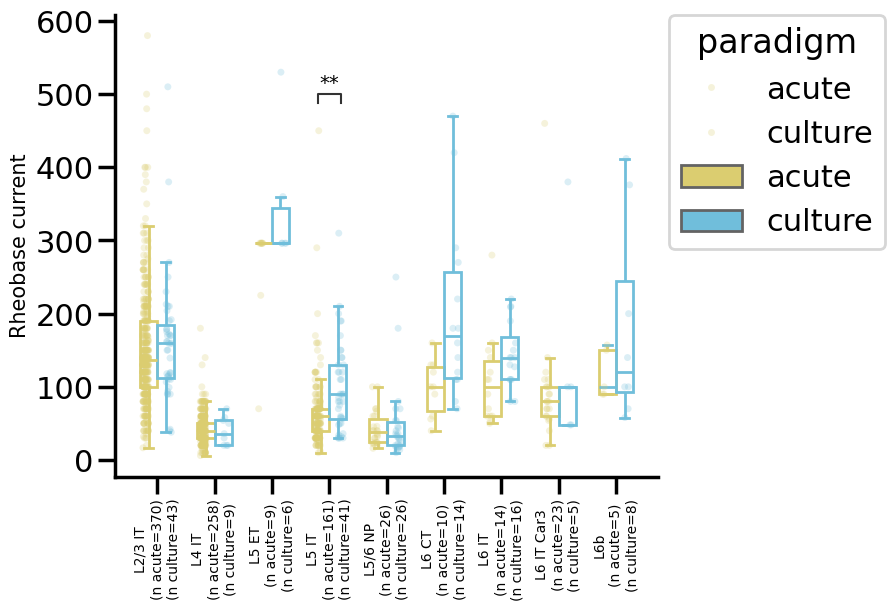

...

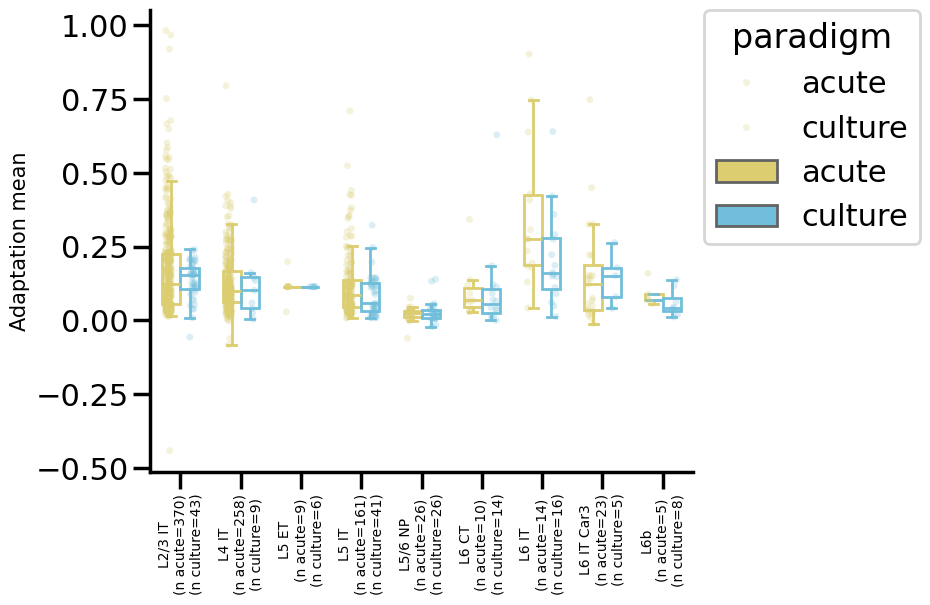

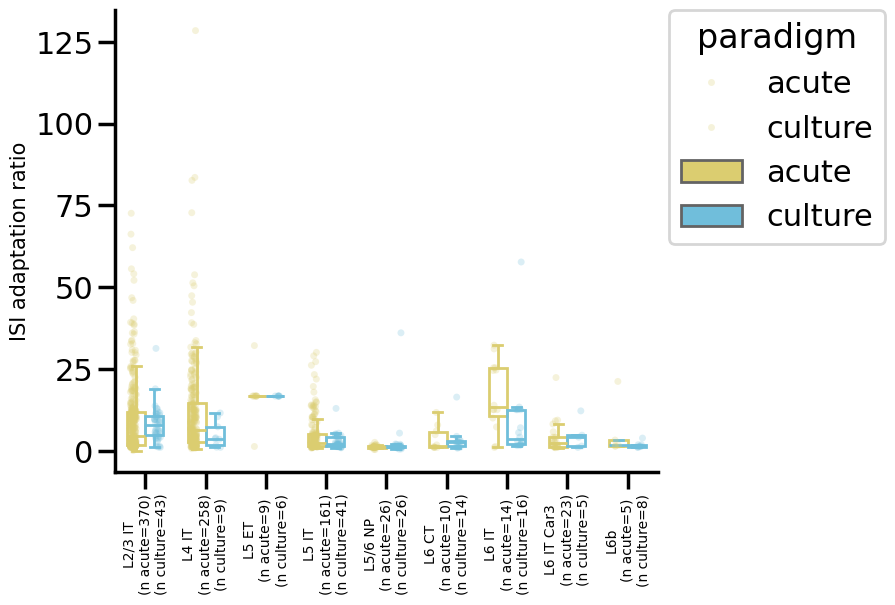

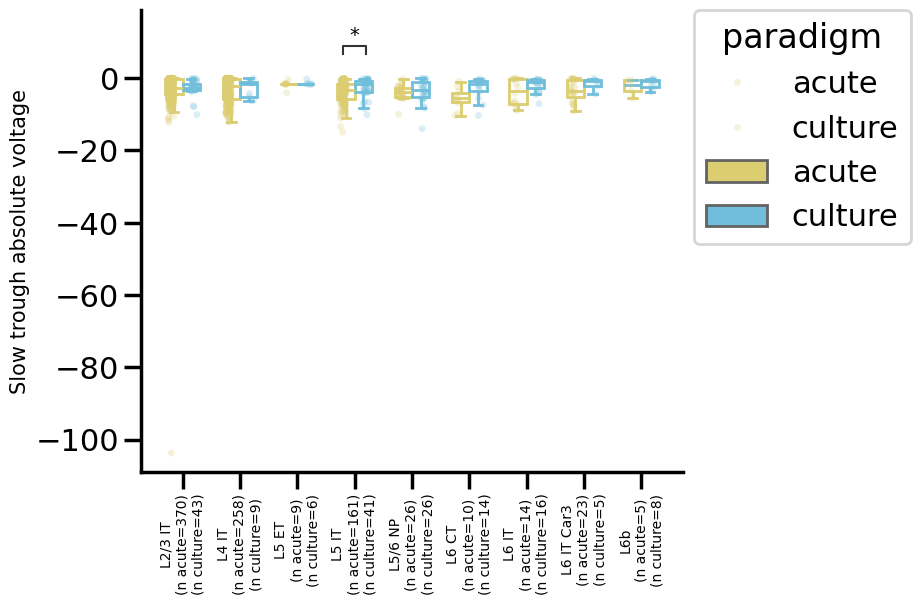

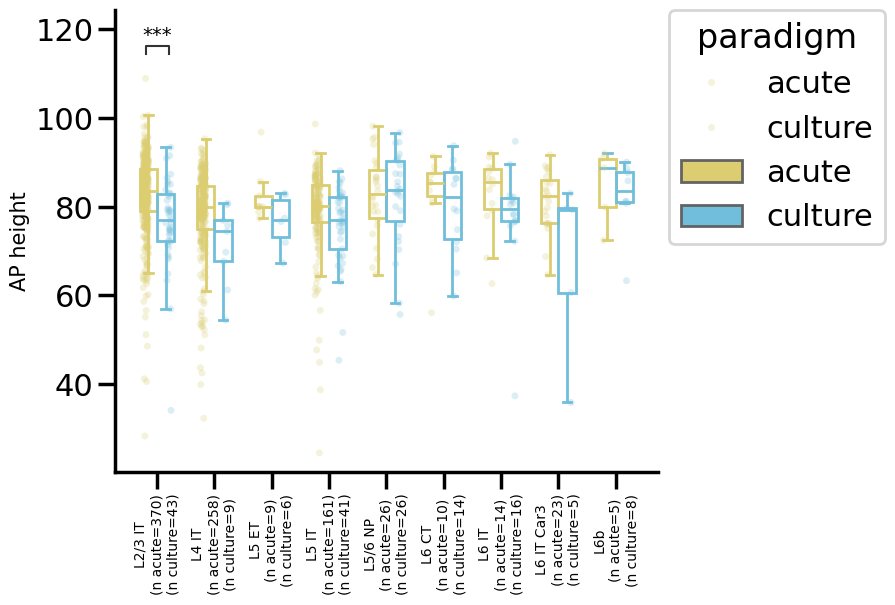

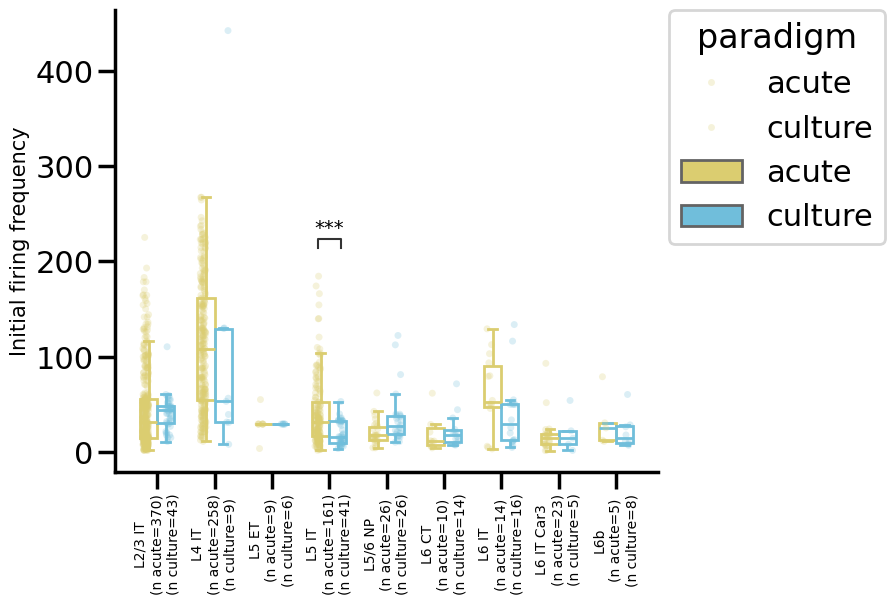

Boxplots with Mann-Whitney U stats saved.


In [28]:
# subclass x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_paradigm_MWU_FDR_bySubclass.pdf'

x_var = 'subclass_label'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = group_order[hue_var]
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)

            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=10)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf

    print("Boxplots with Mann-Whitney U stats saved.")


Cross paradigm box plots - ttype

In [29]:
# ttype x feature box plots

x_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
group_var = 't_type'

n_min_cells = 3
combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()

# Collect p-values and stats by (ttype, feature)
mw_pvals = dict()
mw_stats = dict()

for group in groups:
    sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
    for f in feature_cols:
        group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
        group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

        if group1.empty or group2.empty:
            continue

        try:
            stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
            mw_pvals[(group, f)] = pval
            mw_stats[(group, f)] = stat
        except ValueError as e:
            print(f'Mann-Whitney failed for {group}, {f}: {e}')

# FDR correction across all tests (subclass-feature pairs)
mw_pvals_list = list(mw_pvals.values())
mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))


/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_6_acute vs. L5 IT_6_culture: Custom statistical test, P_val:2.368e-02
L5 IT_7_acute vs. L5 IT_7_culture: Custom statistical test, P_val:2.368e-02
L6 IT_1_acute vs. L6 IT_1_culture: Custom statistical test, P_val:2.368e-02
L4 IT_4_acute vs. L4 IT_4_culture: Custom statistical test, P_val:3.775e-02
L3 IT_13_acute vs. L3 IT_13_culture: Custom statistical test, P_val:4.684e-03
L4 IT_2_acute vs. L4 IT_2_culture: Custom statistical test, P_val:4.684e-03


/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_6_acute vs. L5 IT_6_culture: Custom statistical test, P_val:3.775e-02
L5/6 NP_1_acute vs. L5/6 NP_1_culture: Custom statistical test, P_val:3.829e-02
L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:4.684e-03
L3 IT_10_acute vs. L3 IT_10_culture: Custom statistical test, P_val:4.684e-03
L3 IT_13_acute vs. L3 IT_13_culture: Custom statistical test, P_val:2.368e-02


/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_2_acute vs. L5 IT_2_culture: Custom statistical test, P_val:2.368e-02


... (5 outputs left out)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:3.829e-02


/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2625050737.py:19: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.fig

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2 IT_1_acute vs. L2 IT_1_culture: Custom statistical test, P_val:3.775e-02


/tmp/ipykernel_1094812/2625050737.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


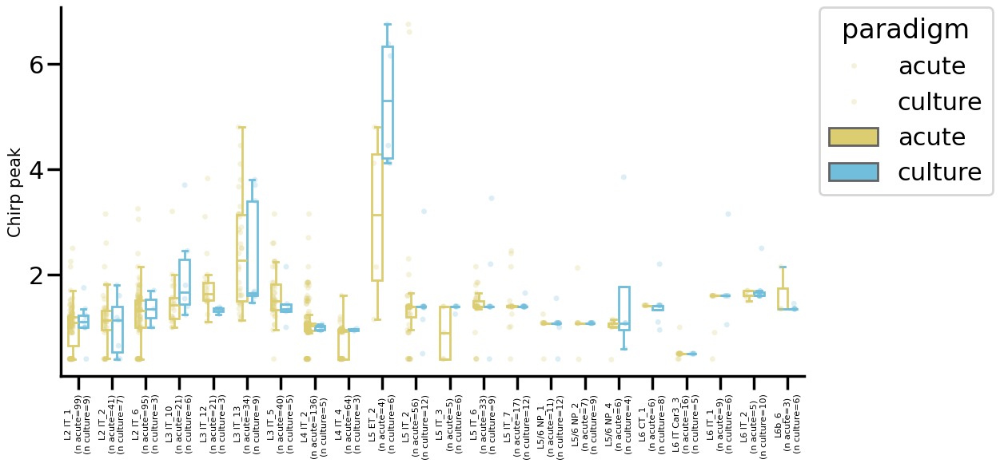

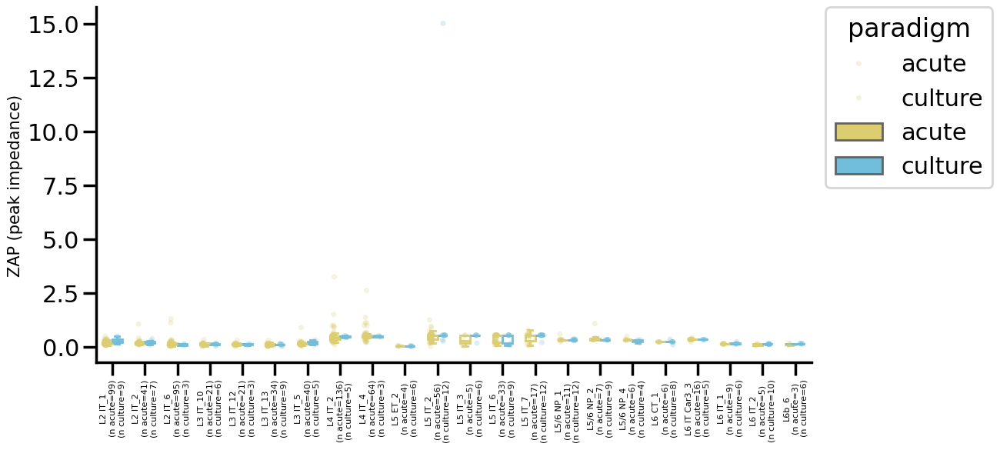

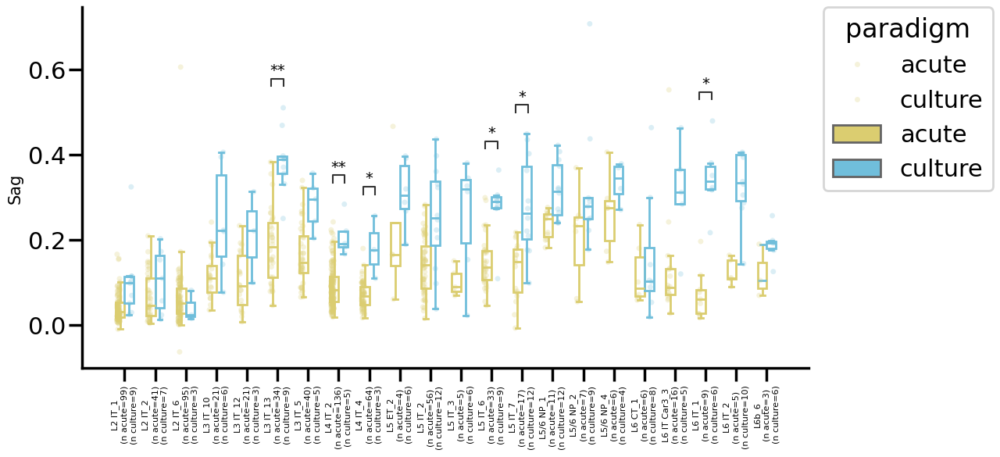

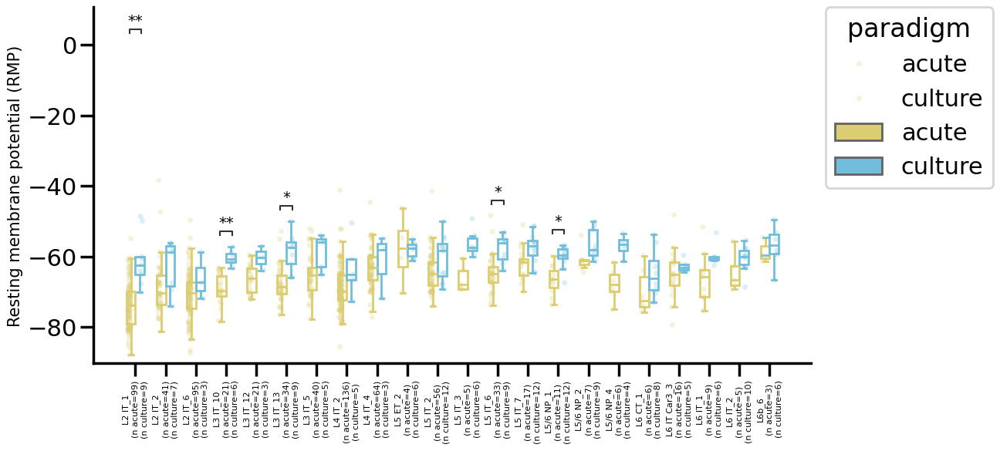

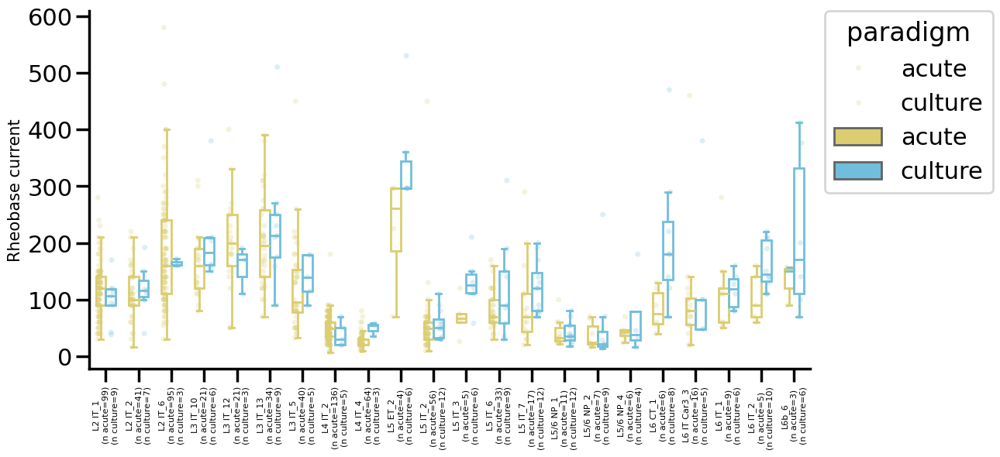

...

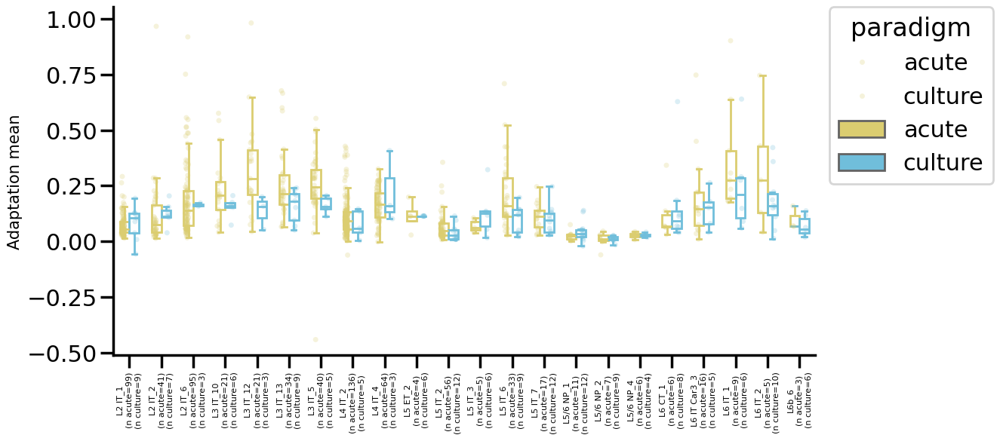

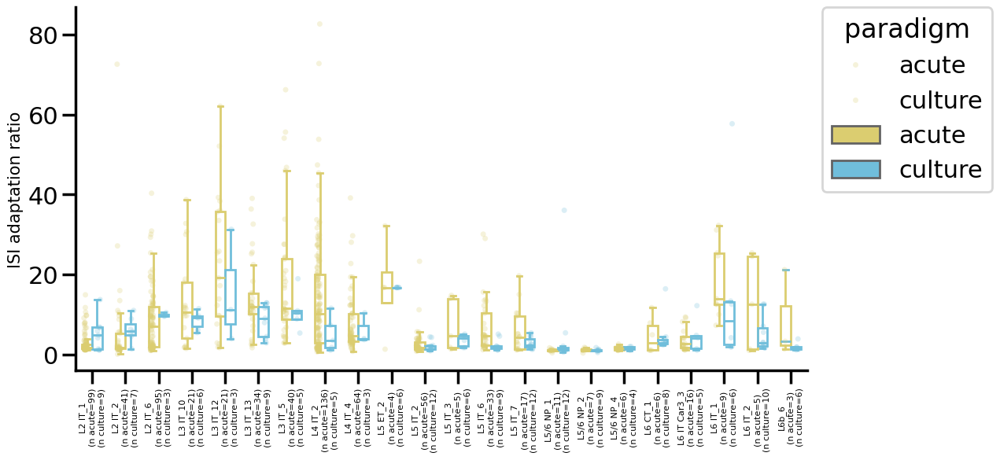

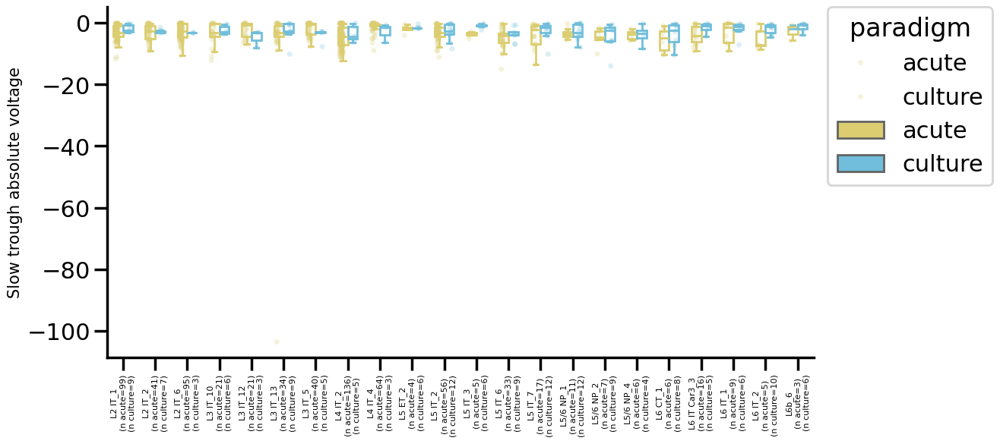

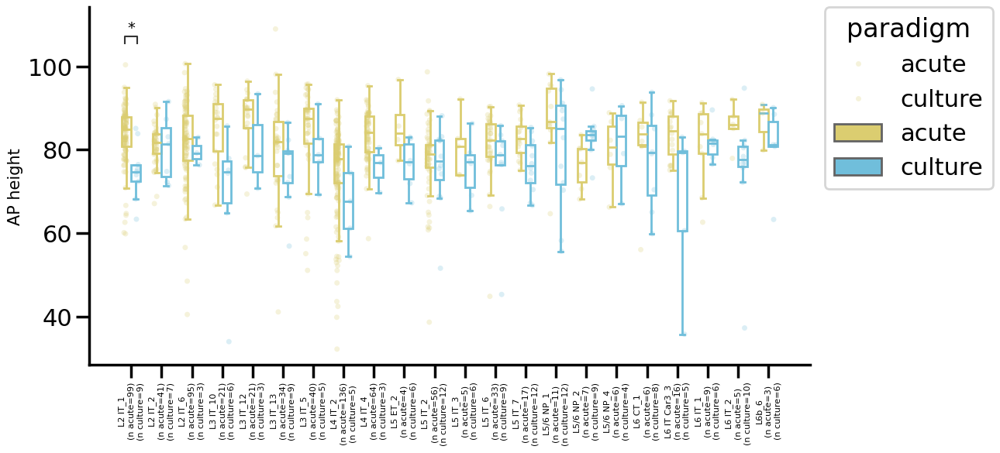

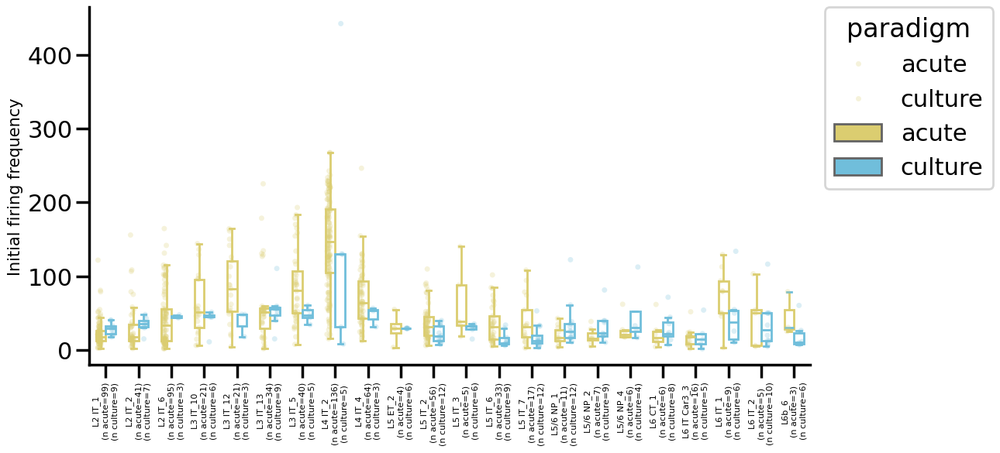

In [30]:
# ttype x feature box plots
fig_name = 'human_excitatory_boxplots_ephys_features_paradigm_MWU_FDR_byTtype.pdf'

x_var = 't_type'
hue_var = 'paradigm'
x_order = groups #sorted_clean_data[x_var].unique().tolist()
hue_order = ['acute', 'culture']
color_palette = color_dicts[hue_var]

fig_path = os.path.join(output_dir, fig_name)
ephys_features = feature_cols.copy()

with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)

    with PdfPages(fig_path) as pdf:
        for y_var in ephys_features:
            # fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 6), sharex=True)
            fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(12,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

            sns.set_context('poster')
            strip = sns.stripplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, alpha=0.25, dodge=True, size=5)
            sns.boxplot(data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=color_palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False)

            #format 
            format_box_plot(ax) #clear fill of box plots, color edges
            sns.despine(right=True, top=True)
            ax.set_xlabel("")
            ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)
            
            ax.legend_.remove()
            handles, labels = strip.get_legend_handles_labels()
            ax.legend(handles, labels, title=hue_var, bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

            #add num observations per x_var
            nobs = []
            for s in x_order:
                nT = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'acute')])
                nO = len(sorted_clean_data[(sorted_clean_data[x_var] == s) & (sorted_clean_data[hue_var] == 'culture')])
                nobs.append("\n(n acute={})\n(n culture={})".format(nT, nO))
            new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
            ax.set_xticklabels(new_x_tick_labels)
            ax.tick_params(axis='x', rotation=90, labelsize=8)

            # Annotate p-values
            pairs = []
            p_values = []
            for subclass in x_order:
                key = (subclass, y_var)
                if key in mw_pvals_fdr:
                    pval = mw_pvals_fdr[key]
                    sig = mw_rejected.get(key, False)
                    if sig:
                        pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                        p_values.append(pval)

            # Only annotate if there are significant results
            if pairs:
                annotator = Annotator(ax, pairs, data=sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                annotator.configure(text_format="star", loc="inside", fontsize=14)
                annotator.set_pvalues_and_annotate(p_values)

            # fig.tight_layout()
            pdf.savefig(dpi=600, bbox_inches='tight')
        plt.show()
        plt.clf


Other metadata box plots - subclass

In [31]:
#add other metadata
additional_metadata_cols = ['group', 'age(yrs)', 'sex', 'medical_conditions'] #'paradigm',
additional_metadata = pd.read_csv(metadata_path, index_col='cell_id')[additional_metadata_cols]
additional_metadata = additional_metadata.rename(columns={'age(yrs)' : 'age'})

sorted_clean_data = sorted_clean_data.merge(additional_metadata, how='left', left_on='specimen_id', right_index=True)

#format metadata column labels 
sorted_clean_data['medical_conditions'] = sorted_clean_data['medical_conditions'].str.lower()
sorted_clean_data['sex'] = sorted_clean_data['sex'].replace('F or M?', 'unknown')
sorted_clean_data['age_bin'] = pd.cut(pd.to_numeric(sorted_clean_data['age'], errors='coerce'), bins=[18, 40, 60, 100], labels=['18-40', '40-60', '60-100'])
sorted_clean_data['age_bin'] = sorted_clean_data['age_bin'].astype('object').fillna('unknown')
sorted_clean_data['lobe_group'] = sorted_clean_data['lobe'].apply(lambda x: x if x == 'TemL' else 'Other')


KW functions

In [32]:
def compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features):

    # STORE RESULTS
    kw_pvals = {}
    kw_hvals = {}
    dunn_tables = {}

    # KW per (subclass, feature)
    for subclass in x_var_order:
        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]

        for f in features:
            groups = [
                sub_df[sub_df[group_var] == g][f].dropna()
                for g in group_order
            ]

            groups = [g for g in groups if len(g) > 0]

            if len(groups) < 2:
                continue

            try:
                h, p = kruskal(*groups)
                kw_hvals[(subclass, f)] = h
                kw_pvals[(subclass, f)] = p
            except Exception as e:
                print(f"KW failed: {subclass}, {f} -> {e}")

    # FDR correction (over all subclass-feature tests)
    pvals = list(kw_pvals.values())
    rej, pvals_fdr = fdrcorrection(pvals, alpha=0.05)

    kw_pvals_fdr = dict(zip(kw_pvals.keys(), pvals_fdr))
    kw_rejected = dict(zip(kw_pvals.keys(), rej))

    # Dunn post hoc ONLY for significant KW results
    # (within each subclass × feature)
    for (subclass, f), sig in kw_rejected.items():

        if not sig:
            continue

        sub_df = sorted_clean_data[sorted_clean_data[x_var] == subclass]
        sub_df = sub_df[sub_df[group_var].isin(group_order)]

        try:
            dunn = posthoc_dunn(
                sub_df,
                val_col=f,
                group_col=group_var,
                p_adjust='fdr_bh'
            )
            dunn_tables[(subclass, f)] = dunn

        except Exception as e:
            print(f"Dunn failed: {subclass}, {f} -> {e}")

    return kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables

In [33]:
def get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected):

    rows = []
    for (subclass, feature), p in kw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'kw_H': kw_hvals.get((subclass, feature)),
            'pval_raw': p,
            'pval_fdr': kw_pvals_fdr.get((subclass, feature)),
            'rejected_fdr': kw_rejected.get((subclass, feature)),
        })

    kw_stats_df = pd.DataFrame(rows)
    kw_stats_df = kw_stats_df.sort_values(['subclass', 'pval_fdr'], ascending=True)

    return kw_stats_df


In [34]:
def get_dunn_stats_df(dunn_tables):
    dunn_rows = []

    for (subclass, feature), dunn_df in dunn_tables.items():

        # iterate upper triangle only
        for i, g1 in enumerate(dunn_df.index):

            for j, g2 in enumerate(dunn_df.columns):

                if j <= i:
                    continue

                dunn_rows.append({
                    'subclass': subclass,
                    'feature': feature,
                    'group1': g1,
                    'group2': g2,
                    'dunn_pval_fdr': dunn_df.loc[g1, g2]
                })

    dunn_stats_df = pd.DataFrame(dunn_rows)
    return dunn_stats_df

In [35]:
def plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, hue_order, palette, dunn_tables, figsize=(8, 6)):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=hue_order, ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)

        with PdfPages(fig_path) as pdf:

            for y_var in y_vars:

                fig, ax = plt.subplots(
                    nrows=1,
                    ncols=1,
                    figsize=figsize,
                    sharex=True,
                    gridspec_kw={'wspace': 0, 'hspace': 0.1}
                )

                sns.set_context('poster')

                strip = sns.stripplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, dodge=True, alpha=0.75, size=4, ax=ax )
                sns.boxplot( data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order, hue_order=hue_order, palette=palette, showfliers=False, width=0.6, linewidth=1, saturation=1, ax=ax )

                # formatting
                format_box_plot(ax)
                sns.despine(ax=ax, right=True, top=True)

                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # tighter category spacing
                # ax.margins(x=0.01)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate(hue_order)
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )

                # rotate labels
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                #add num observations per x_var
                nobs = []
                for s in x_order:
                    counts = []
                    for h in hue_order:
                        n = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == h) & (~this_sorted_clean_data[y_var].isna())])
                        counts.append(f"({h}={n})")
                    label = "\n".join(counts)
                    nobs.append(label)

                new_x_tick_labels = [x_order[i] + "\n" + nobs[i] for i in range(len(x_order))]
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)


                # ADD DUNN SIGNIFICANCE
                pairs = []
                pvals = []

                for subclass in x_order:
                    key = (subclass, y_var)

                    if key not in dunn_tables:
                        continue

                    dunn = dunn_tables[key]

                    mask = np.tril(np.ones(dunn.shape), k=0).astype(bool)
                    dunn = dunn.copy()
                    dunn[mask] = np.nan

                    melted = dunn.melt(ignore_index=False).reset_index()
                    melted = melted.dropna()
                    melted = melted[melted['value'] < 0.05]

                    for _, row in melted.iterrows():
                        pairs.append([
                            (subclass, row['index']),
                            (subclass, row['variable'])
                        ])
                        pvals.append(row['value'])

                if len(pairs) > 0:
                    annot = Annotator(
                        ax,
                        pairs,
                        data=this_sorted_clean_data,
                        x=x_var,
                        y=y_var,
                        hue=hue_var,
                        order=x_order,
                        hue_order=hue_order
                    )

                    annot.configure(
                        text_format="star",
                        loc="inside",
                        fontsize=14
                    )

                    annot.set_pvalues_and_annotate(pvals)

                plt.tight_layout()
                pdf.savefig(fig, bbox_inches='tight', dpi=600)
                plt.show()

            plt.close(fig)

MW functions

In [36]:
def compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features):

    n_min_cells = 3
    combo_counts = sorted_clean_data.groupby([group_var, x_var]).size().unstack(fill_value=0)
    groups = combo_counts[(combo_counts >= n_min_cells).all(axis=1)].index.tolist()


    # Collect p-values and stats by (subclass, feature)
    mw_pvals = dict()
    mw_stats = dict()

    for group in groups:
        sub_data = sorted_clean_data[sorted_clean_data[group_var] == group]
        for f in features:
            group1 = sub_data[sub_data[x_var] == group1_label][f].dropna()
            group2 = sub_data[sub_data[x_var] == group2_label][f].dropna()

            if group1.empty or group2.empty:
                continue

            try:
                stat, pval = mannwhitneyu(group1, group2, alternative='two-sided')
                mw_pvals[(group, f)] = pval
                mw_stats[(group, f)] = stat
            except ValueError as e:
                print(f'Mann-Whitney failed for {group}, {f}: {e}')

    # FDR correction across all tests (subclass-feature pairs)
    mw_pvals_list = list(mw_pvals.values())
    mw_rejected_list, mw_pvals_fdr_list = fdrcorrection(mw_pvals_list, alpha=0.05, method='indep', is_sorted=False)

    mw_pvals_fdr = dict(zip(mw_pvals.keys(), mw_pvals_fdr_list))
    mw_rejected = dict(zip(mw_pvals.keys(), mw_rejected_list))

    return mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected


In [37]:
def get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected):

    #Save stats
    rows = []
    for (subclass, feature), pval in mw_pvals.items():
        rows.append({
            'subclass': subclass,
            'feature': feature,
            'mw_stat': mw_stats.get((subclass, feature)),
            'pval_raw': pval,
            'pval_fdr': mw_pvals_fdr.get((subclass, feature)),
            'rejected_pval_fdr': mw_rejected.get((subclass, feature)),
            'group1': group1_label,
            'group2': group2_label
        })

    mw_stats_df = pd.DataFrame(rows)
    if len(mw_stats_df)>0:
        mw_stats_df = mw_stats_df.sort_values( ['subclass', 'pval_fdr'], ascending=[True, True])
    return mw_stats_df


In [38]:
def plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_order, y_vars, hue_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected):

    # x_var, hue_var cleanup
    this_sorted_clean_data = sorted_clean_data.copy()

    # strip old categorical behavior completely
    this_sorted_clean_data[x_var] = this_sorted_clean_data[x_var].astype(str)
    this_sorted_clean_data[hue_var] = this_sorted_clean_data[hue_var].astype(str)

    # enforce clean order explicitly
    this_sorted_clean_data[x_var] = pd.Categorical( this_sorted_clean_data[x_var], categories=x_order, ordered=True )
    this_sorted_clean_data[hue_var] = pd.Categorical( this_sorted_clean_data[hue_var], categories=[group1_label, group2_label], ordered=True )
    this_sorted_clean_data = this_sorted_clean_data[ this_sorted_clean_data[x_var].isin(x_order) ]

    print(len(this_sorted_clean_data))

    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)

        with PdfPages(fig_path) as pdf:
            for y_var in y_vars:
                fig, ax = plt.subplots(nrows=1,ncols=1,figsize=(7,6),sharex=True, gridspec_kw = {'wspace':0, 'hspace':0.1}) #gridspec_kw = {'wspace':0, 'hspace':0},

                sns.set_context('poster')
                strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
                sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)

                #format 
                format_box_plot(ax) #clear fill of box plots, color edges
                sns.despine(right=True, top=True)
                ax.set_xlabel("")
                ax.set_ylabel(y_var.replace("_", " "), rotation=90, size=15)

                # remove auto legend
                if ax.legend_ is not None:
                    ax.legend_.remove()

                # custom legend handles
                custom_handles = [
                    Line2D(
                        [0], [0],
                        marker='o',
                        color='w',
                        label=group,
                        markerfacecolor=palette[i],
                        markeredgecolor=palette[i],
                        markersize=8,
                        alpha=0.7
                    )
                    for i, group in enumerate([group1_label, group2_label])
                ]

                ax.legend(
                    handles=custom_handles,
                    title=hue_var,
                    bbox_to_anchor=(1.02, 1),
                    loc='upper left',
                    borderaxespad=0
                )


                #add num observations per x_var
                nobs = []
                for s in x_order:
                    nT = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group1_label) & (~this_sorted_clean_data[y_var].isna())])
                    nO = len(this_sorted_clean_data[(this_sorted_clean_data[x_var] == s) & (this_sorted_clean_data[hue_var] == group2_label) & (~this_sorted_clean_data[y_var].isna())])
                    nobs.append("\n(n {}={})\n(n {}={})".format(group1_label, nT, group2_label, nO))
                new_x_tick_labels = [x_order[i] + nobs[i] for i in range(len(x_order))]  
                ax.set_xticklabels(new_x_tick_labels)
                ax.tick_params(axis='x', rotation=90, labelsize=10)

                # Annotate p-values
                pairs = []
                p_values = []
                for subclass in x_order:
                    key = (subclass, y_var)
                    if key in mw_pvals_fdr:
                        pval = mw_pvals_fdr[key]
                        sig = mw_rejected.get(key, False)
                        if sig:
                            pairs.append([(subclass, 'acute'), (subclass, 'culture')])  # or vice versa
                            p_values.append(pval)

                # Only annotate if there are significant results
                if pairs:
                    annotator = Annotator(ax, pairs, data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, order=x_order)
                    annotator.configure(text_format="star", loc="inside", fontsize=14)
                    annotator.set_pvalues_and_annotate(p_values)

                # fig.tight_layout()
                pdf.savefig(dpi=600, bbox_inches='tight')
            plt.show()
            plt.clf
        

Cross disease state box plots - subclass

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:4.860e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


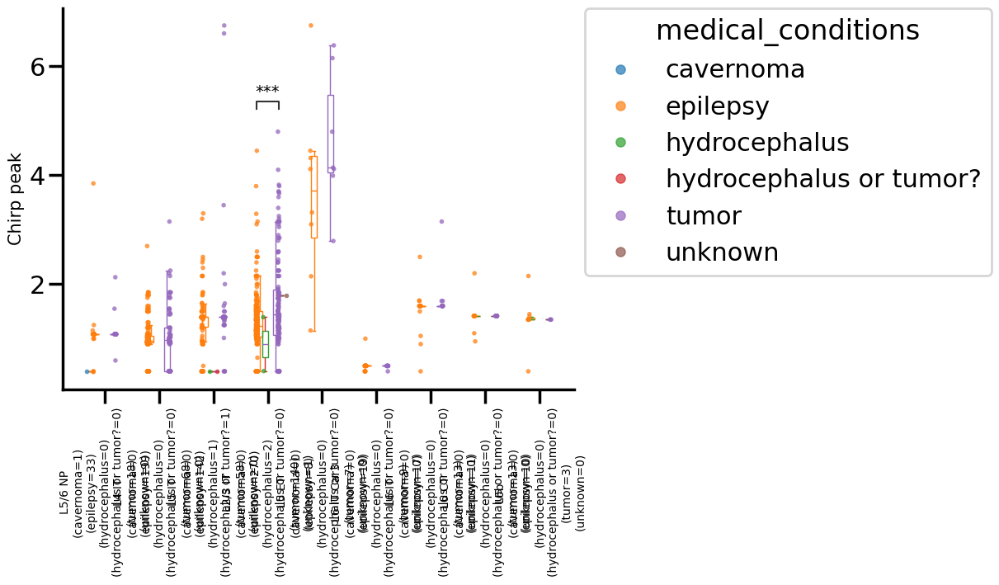

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


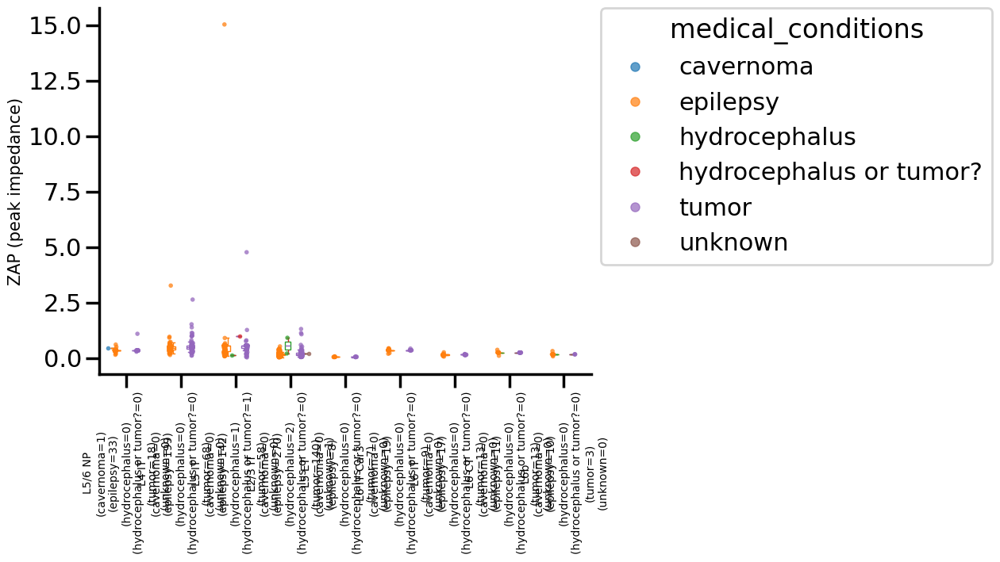

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_epilepsy vs. L4 IT_tumor: Custom statistical test, P_val:2.501e-05
L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:1.167e-14
L6 IT_epilepsy vs. L6 IT_tumor: Custom statistical test, P_val:5.549e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


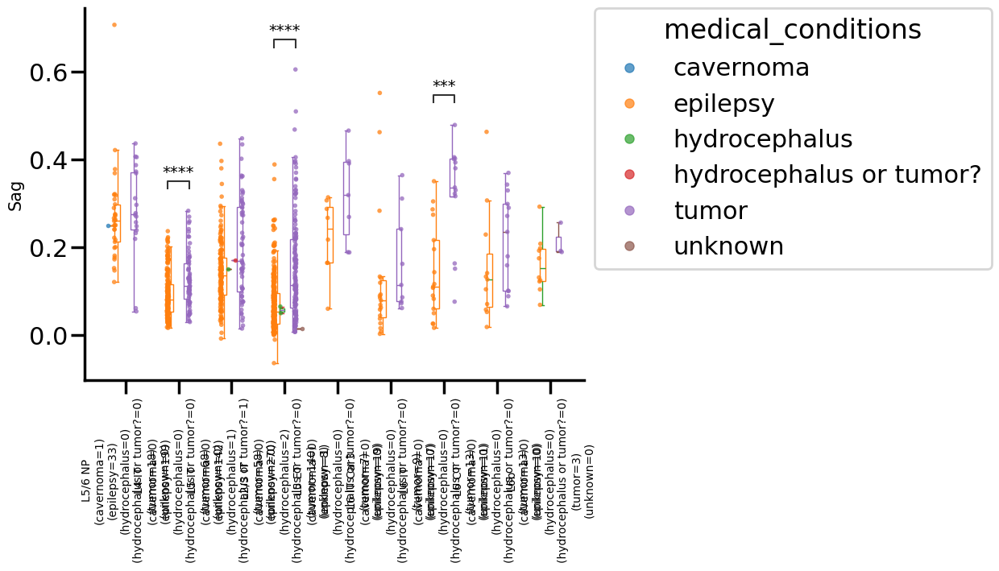

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


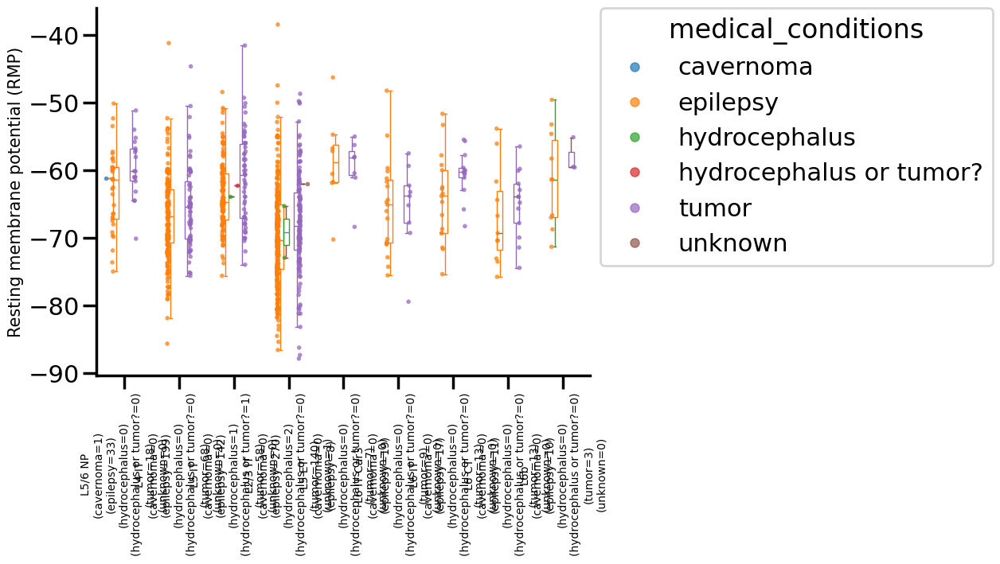

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


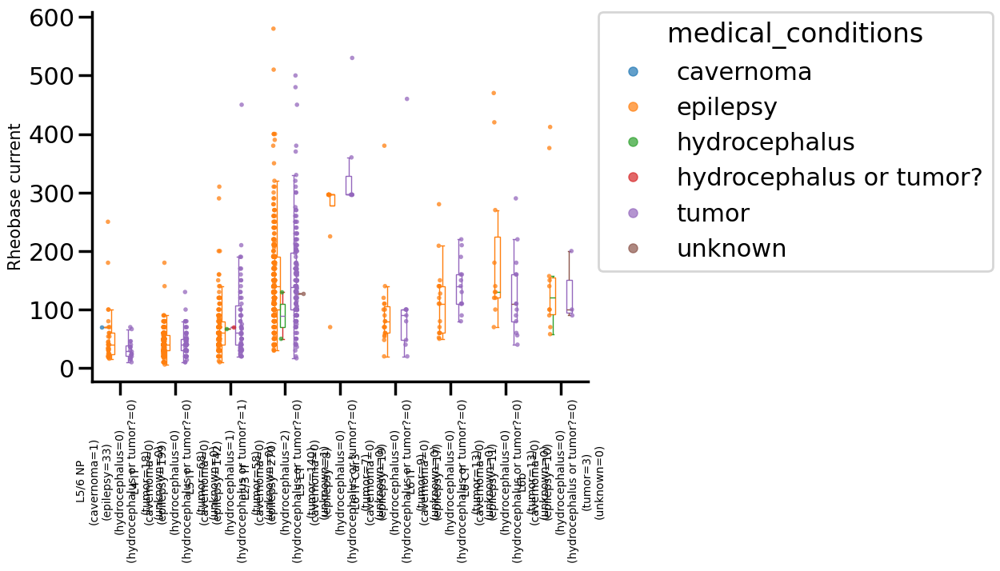

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


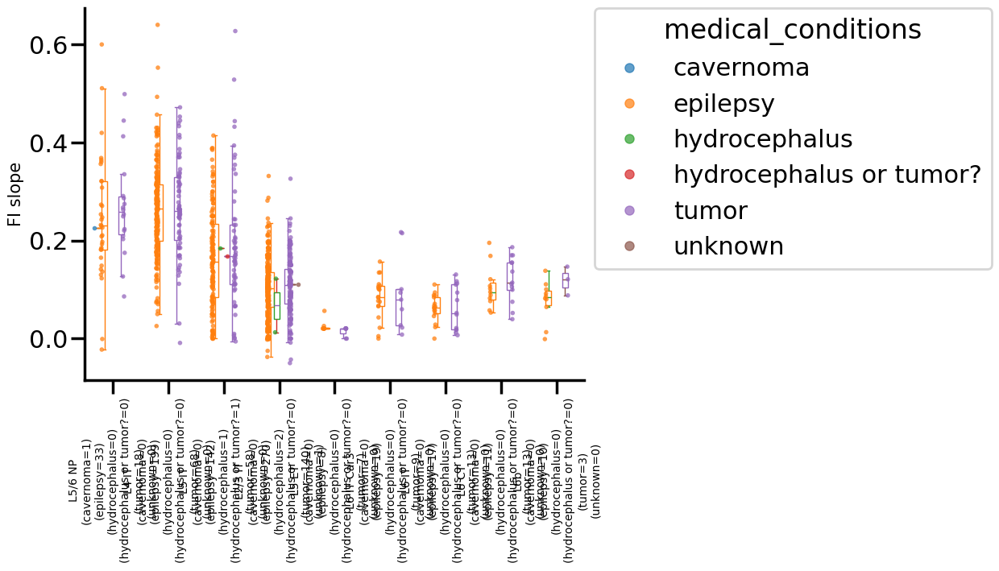

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


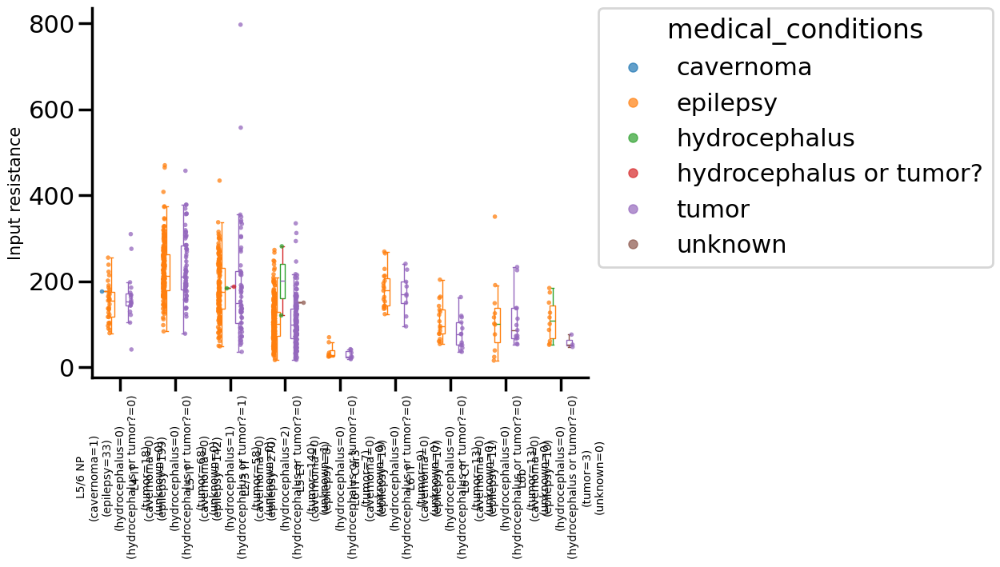

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:5.703e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


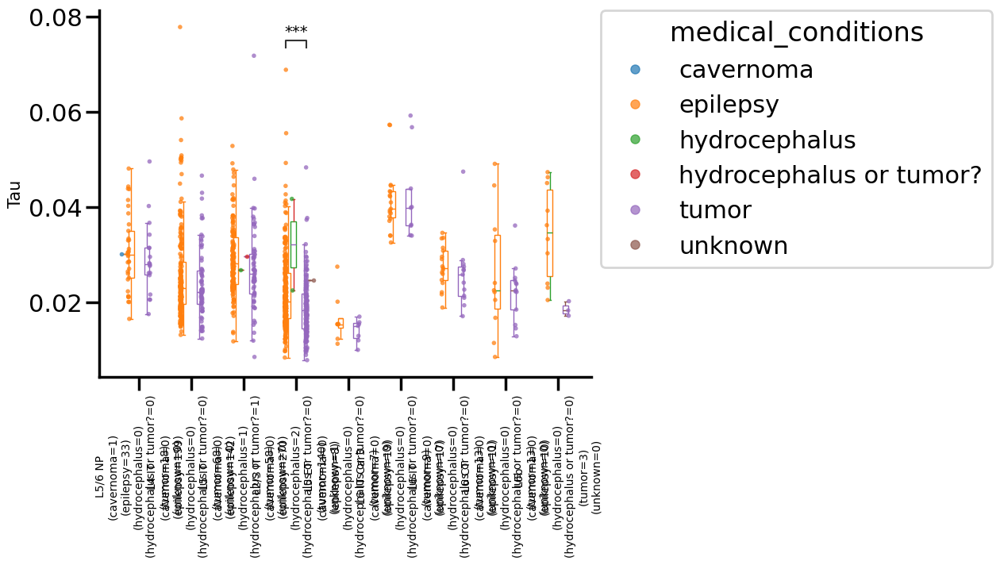

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:3.423e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


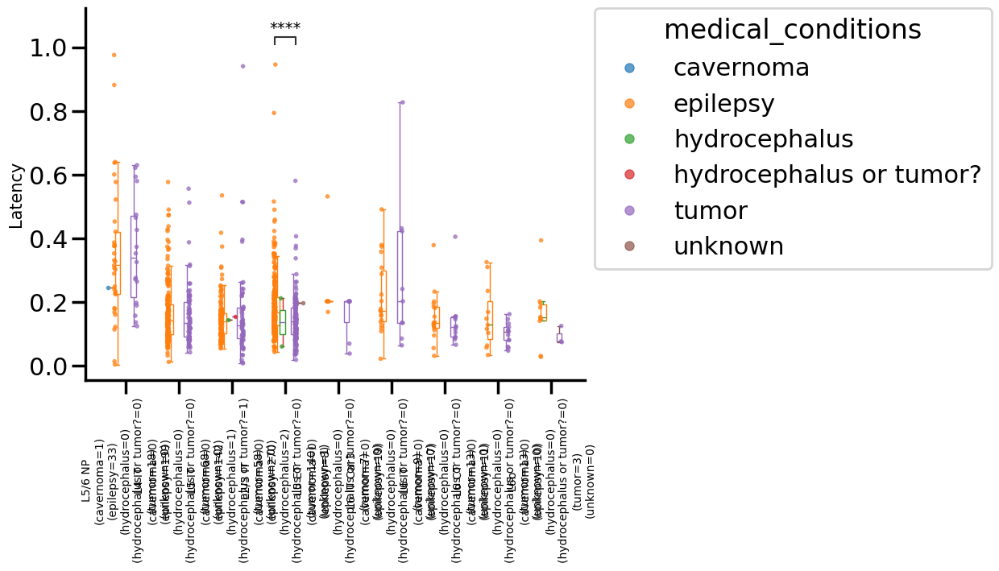

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


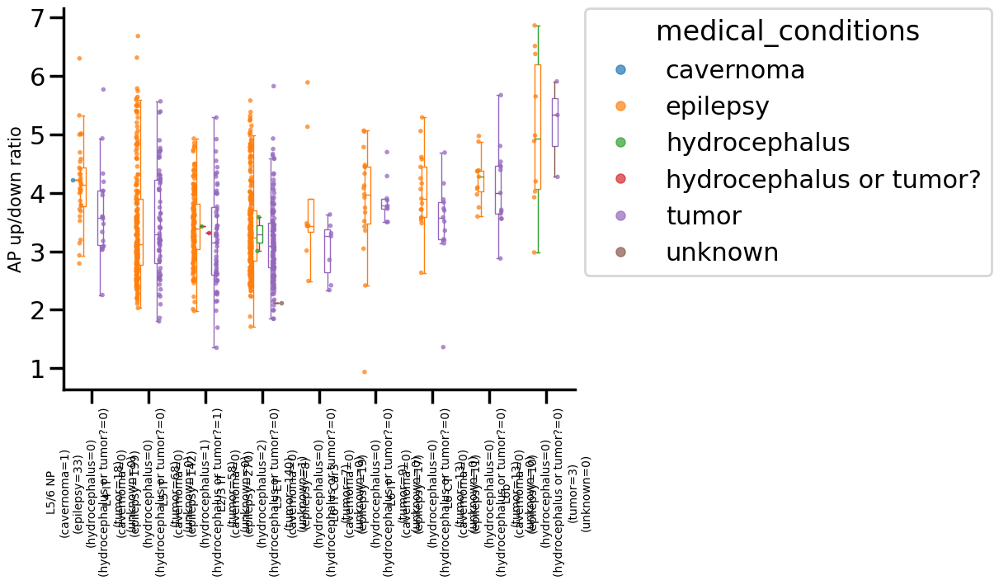

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


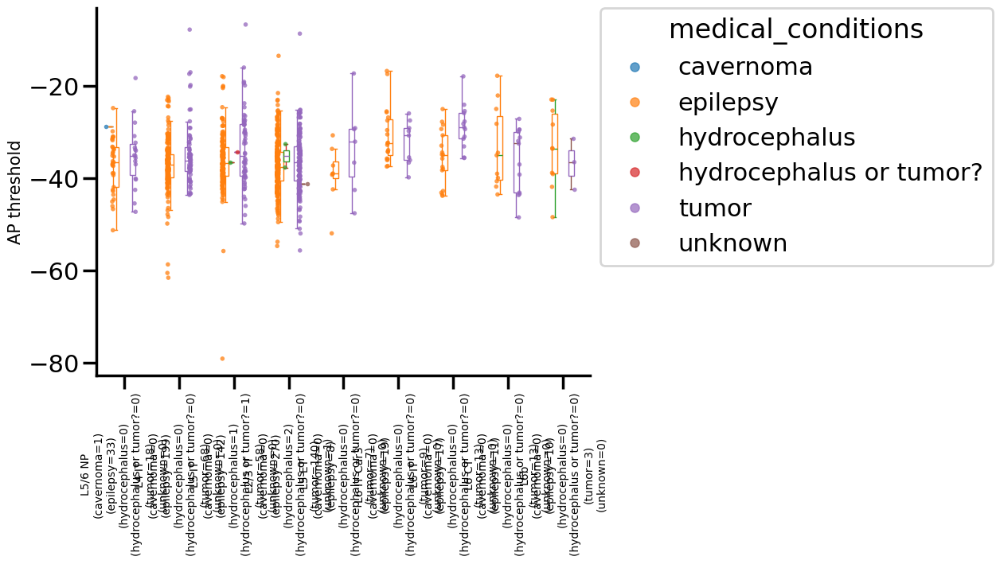

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


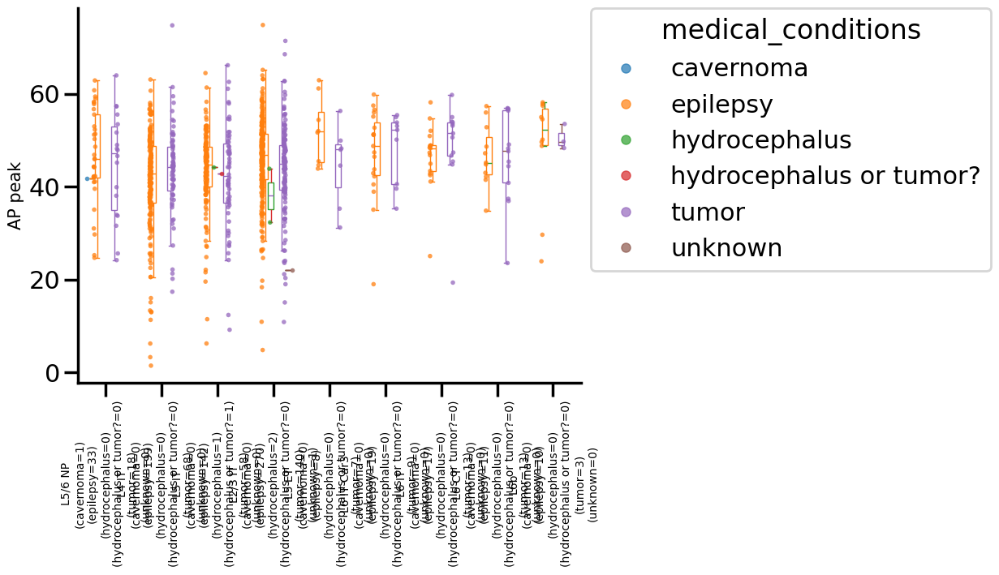

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


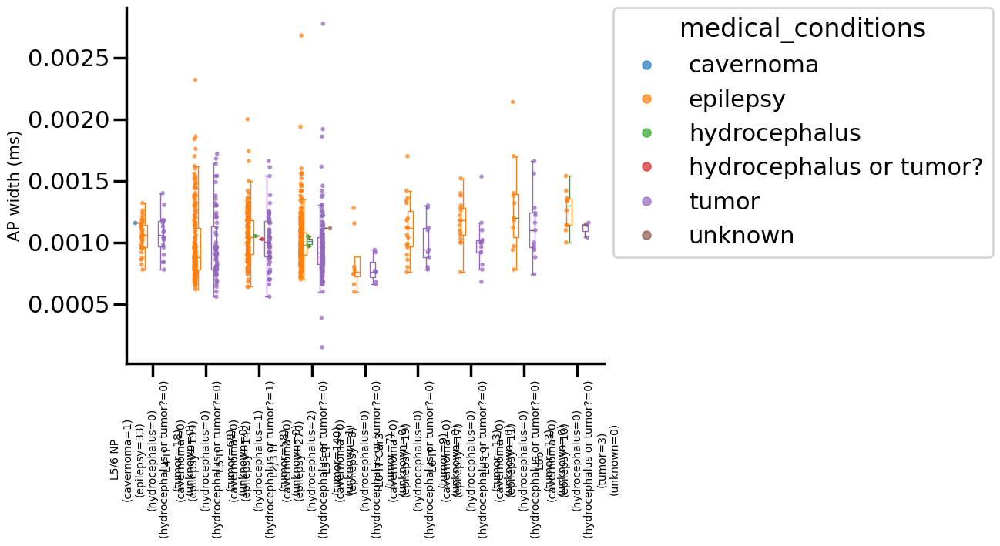

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


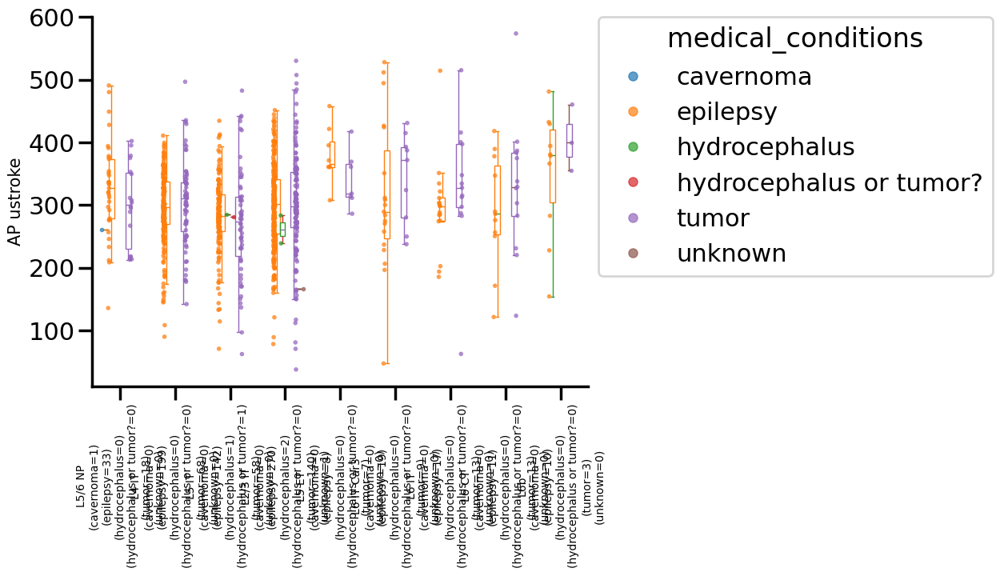

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


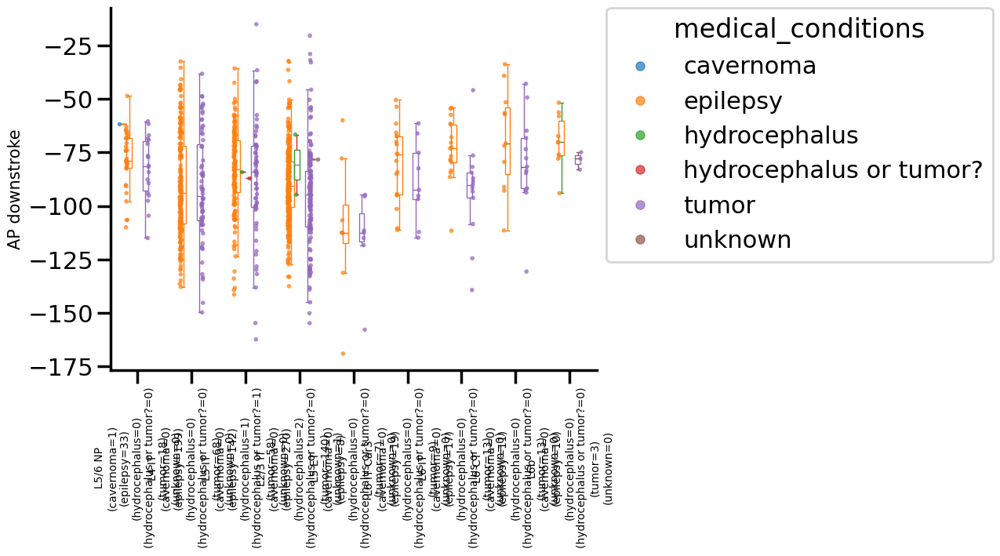

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


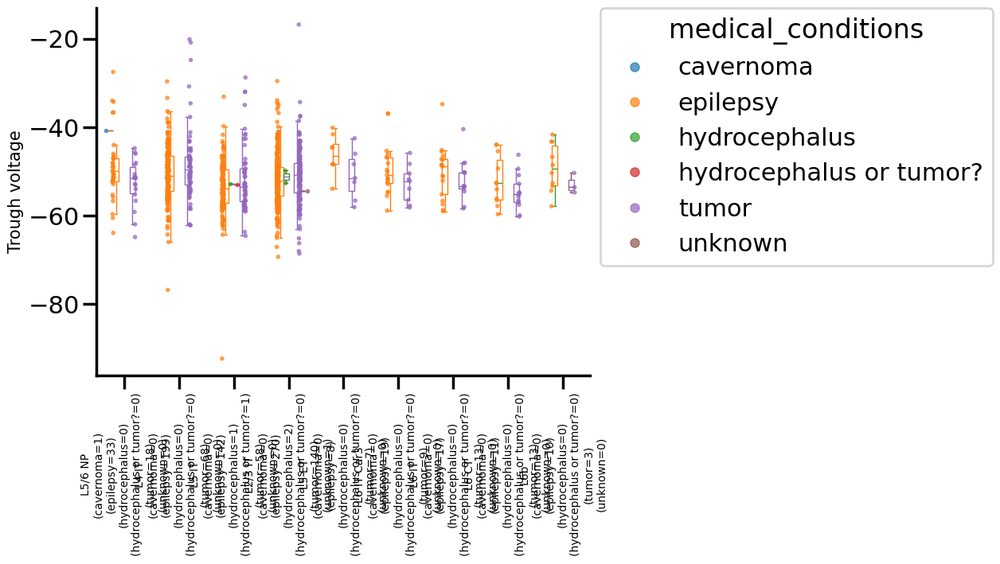

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


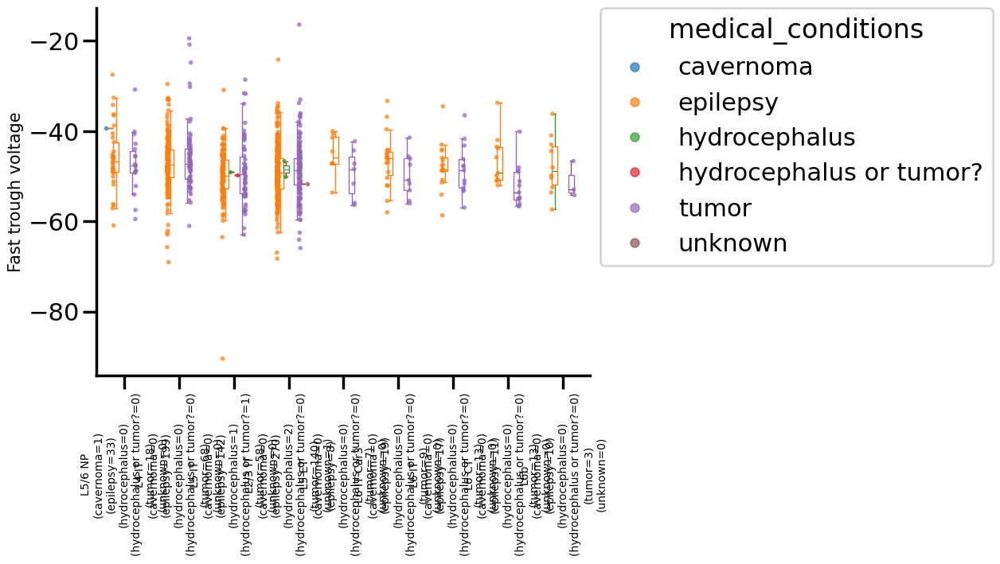

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


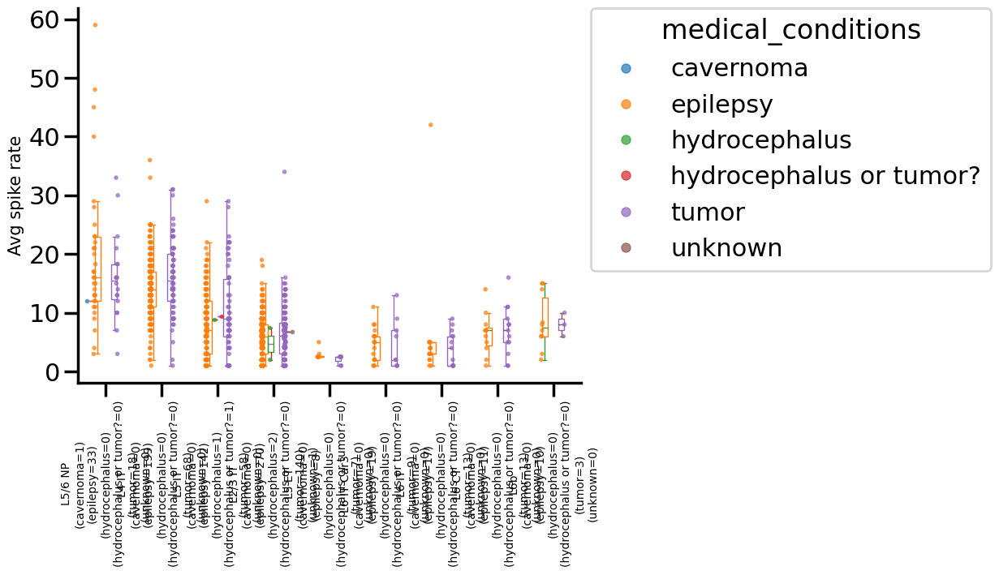

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


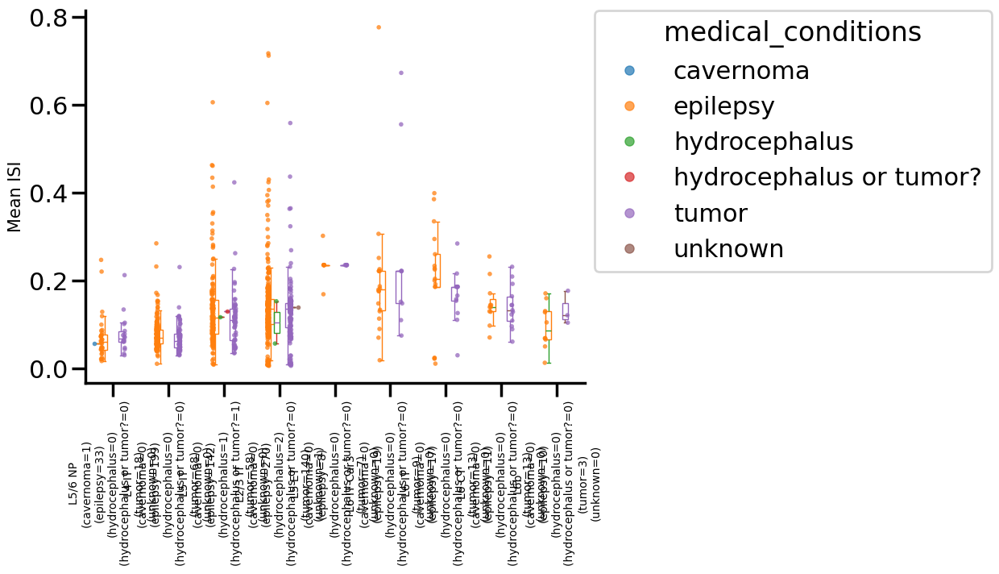

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


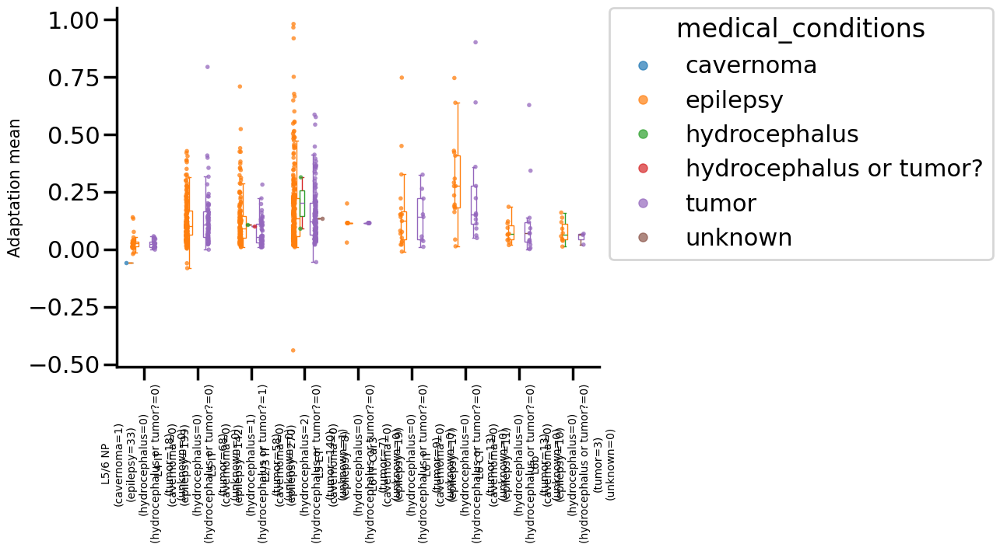

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


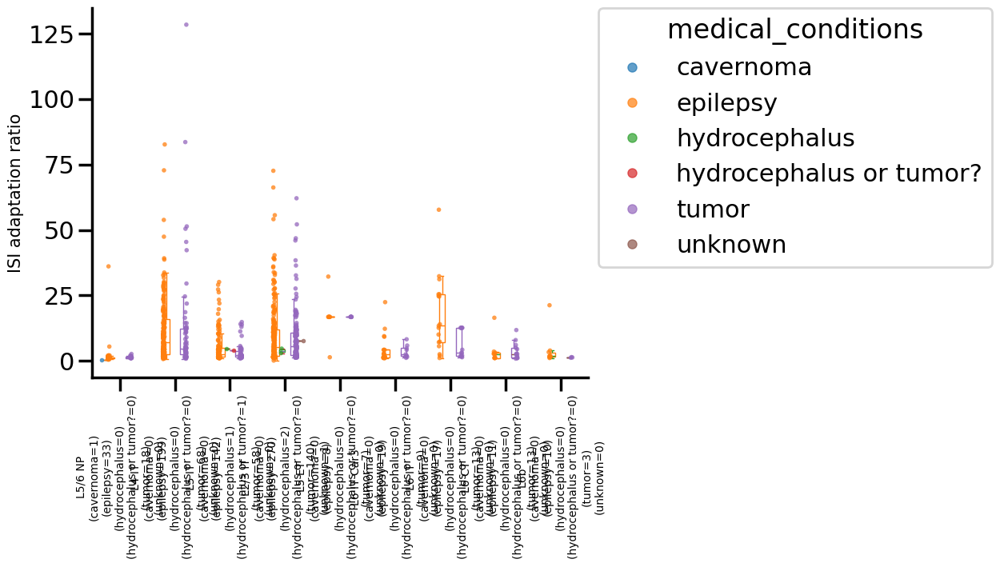

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5/6 NP_epilepsy vs. L5/6 NP_tumor: Custom statistical test, P_val:1.029e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


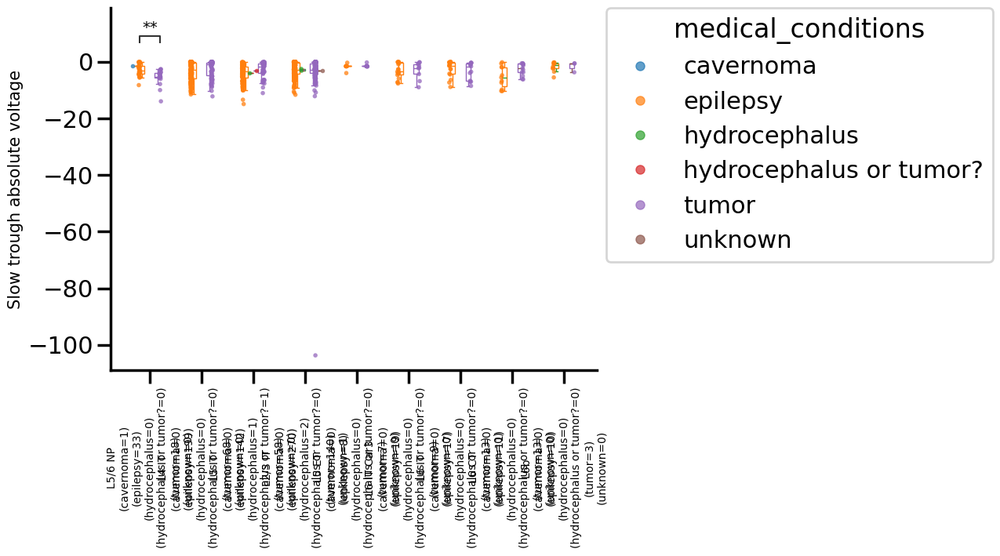

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_epilepsy vs. L2/3 IT_tumor: Custom statistical test, P_val:2.731e-03
L5 ET_epilepsy vs. L5 ET_tumor: Custom statistical test, P_val:1.971e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


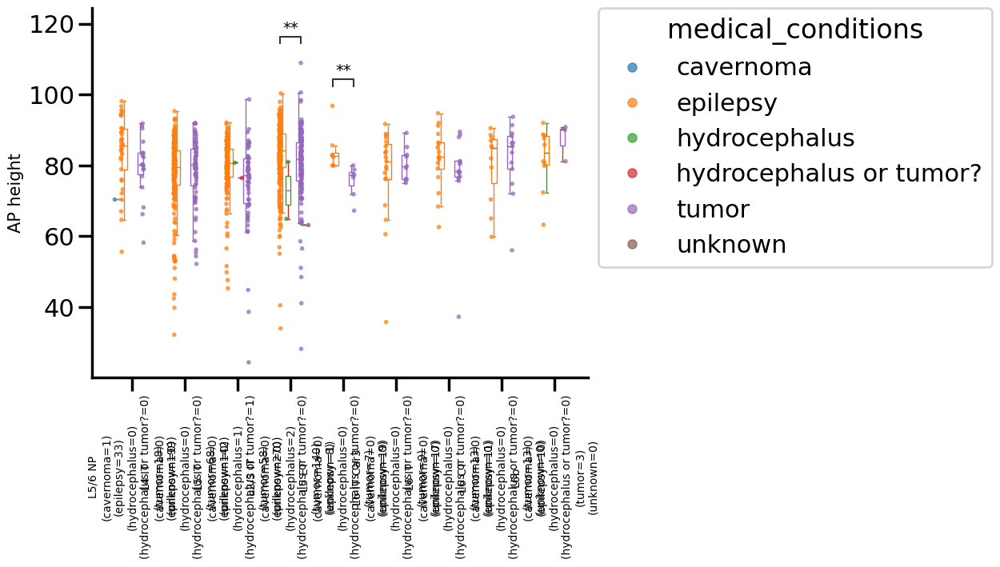

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


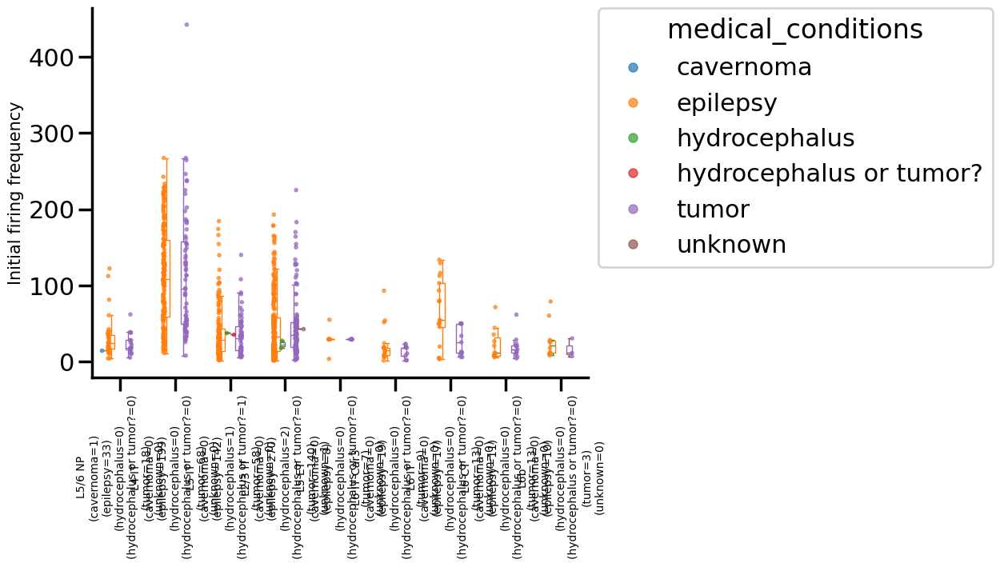

In [39]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'medical_conditions'
group_order = sorted_clean_data[group_var].unique().tolist()

features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing single cells with `hydrocephalus`, `unknown`, and `hydrocephalus or tumor?` conditions 

1044


/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1094812/2125135880.py:26: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

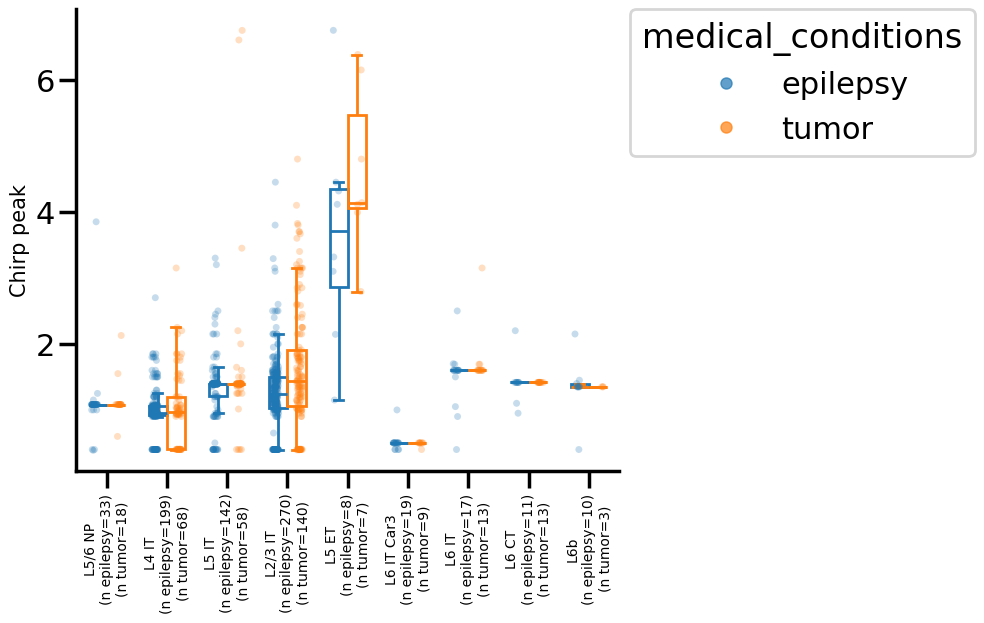

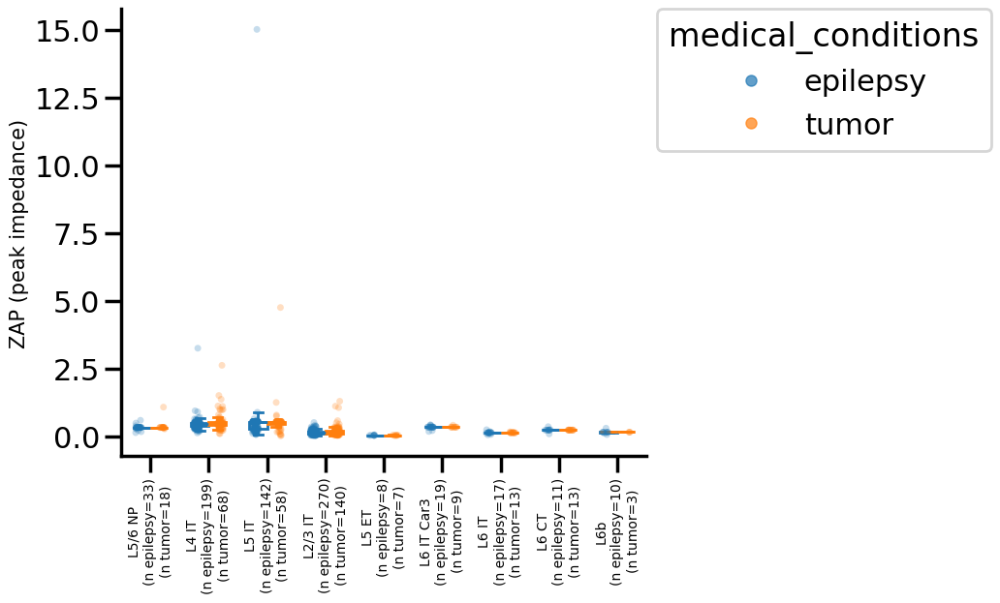

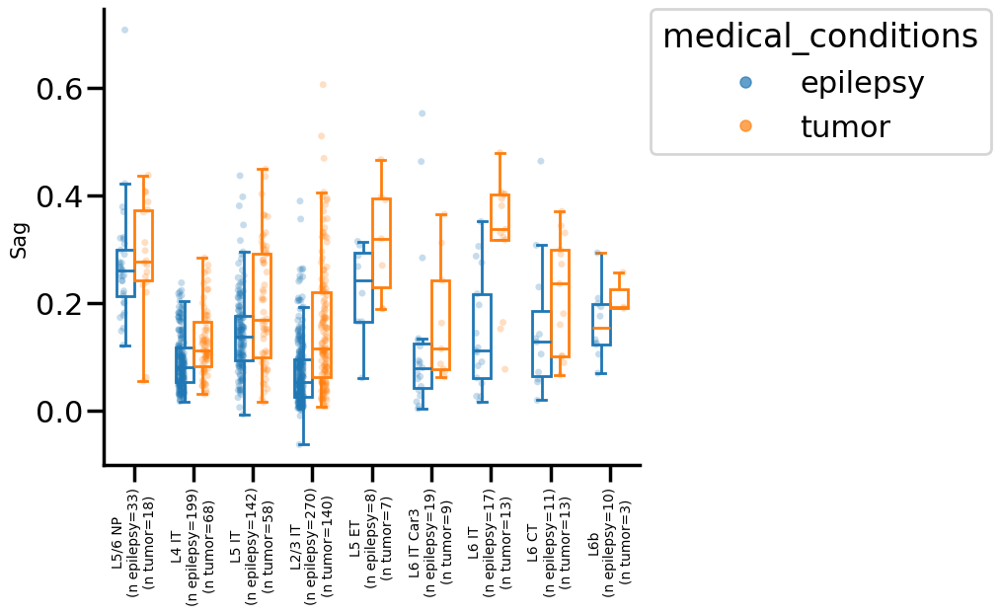

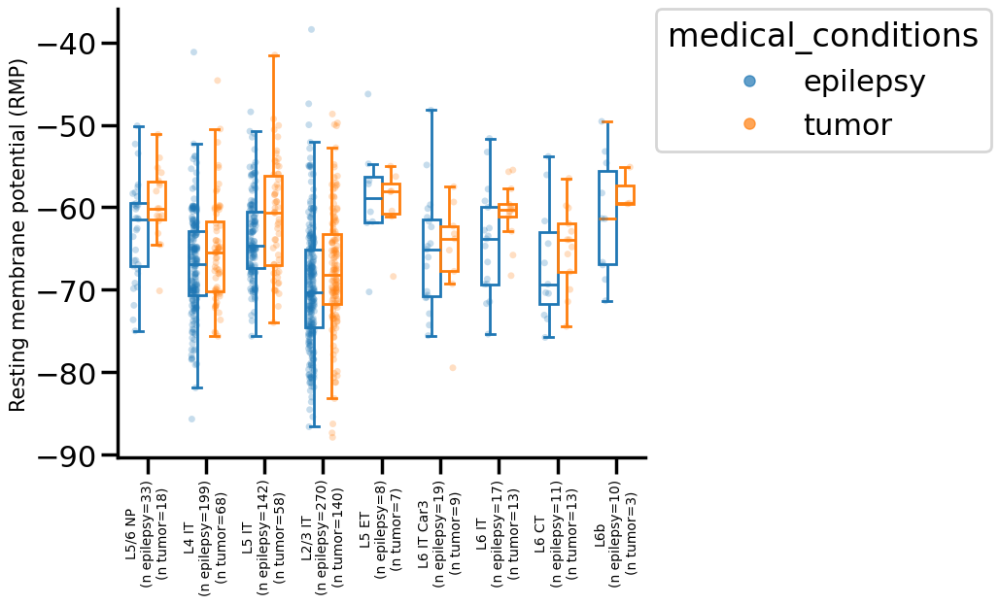

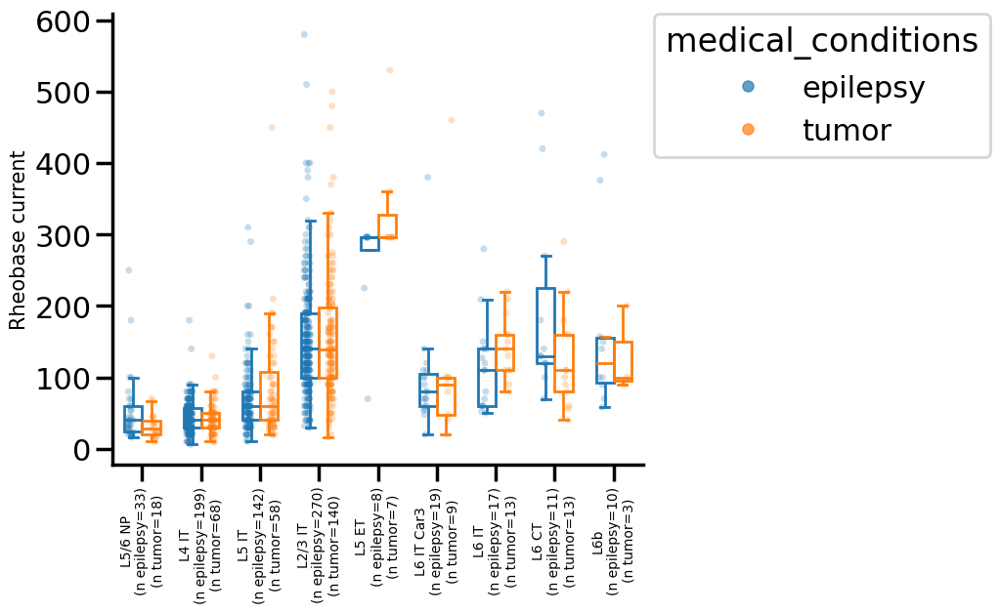

...

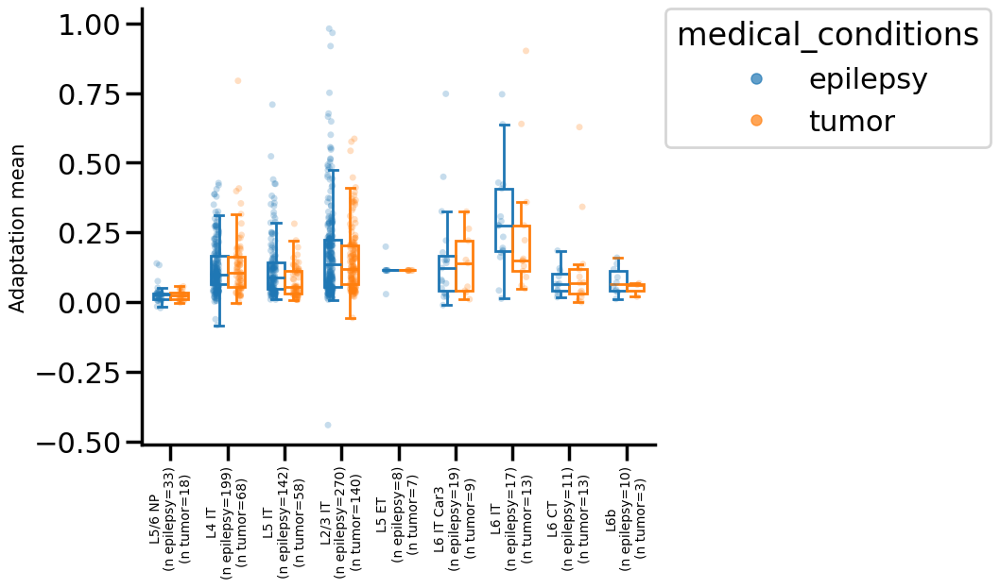

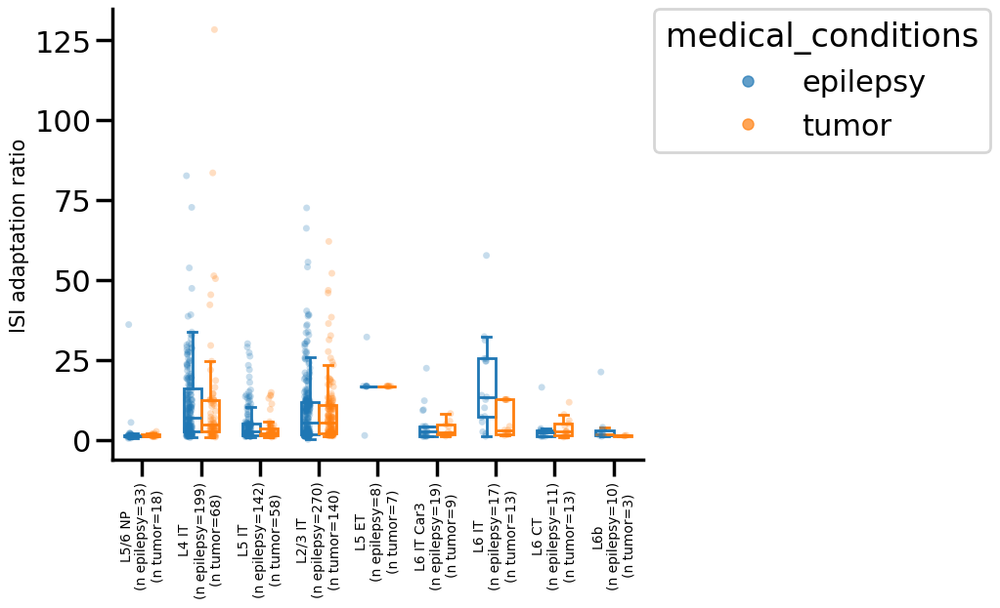

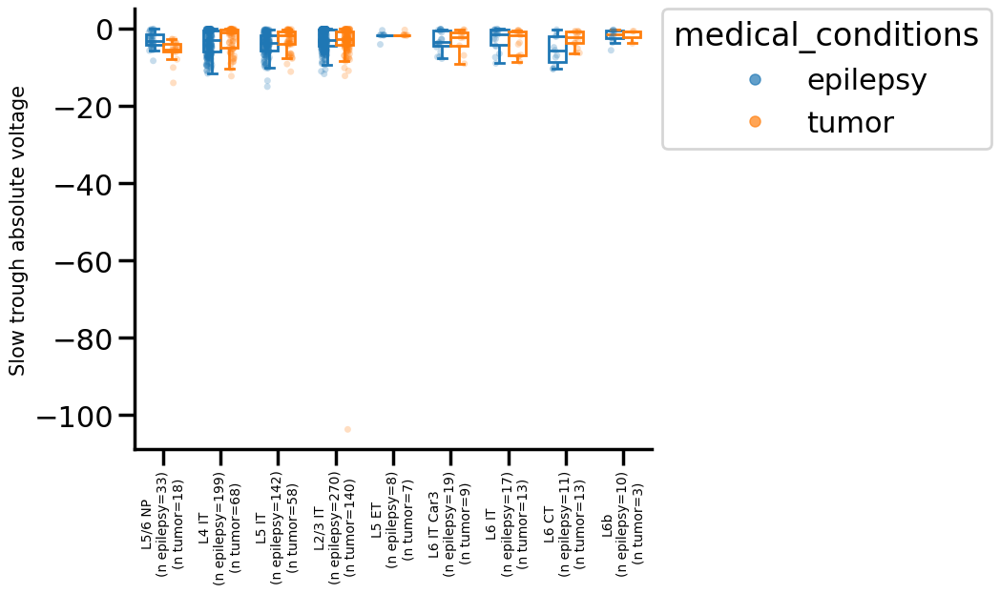

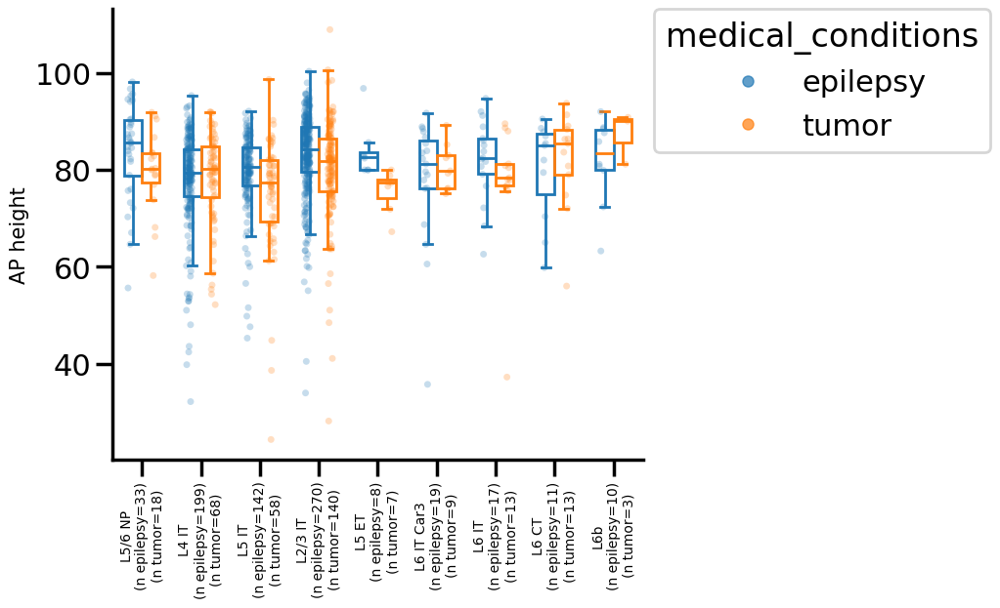

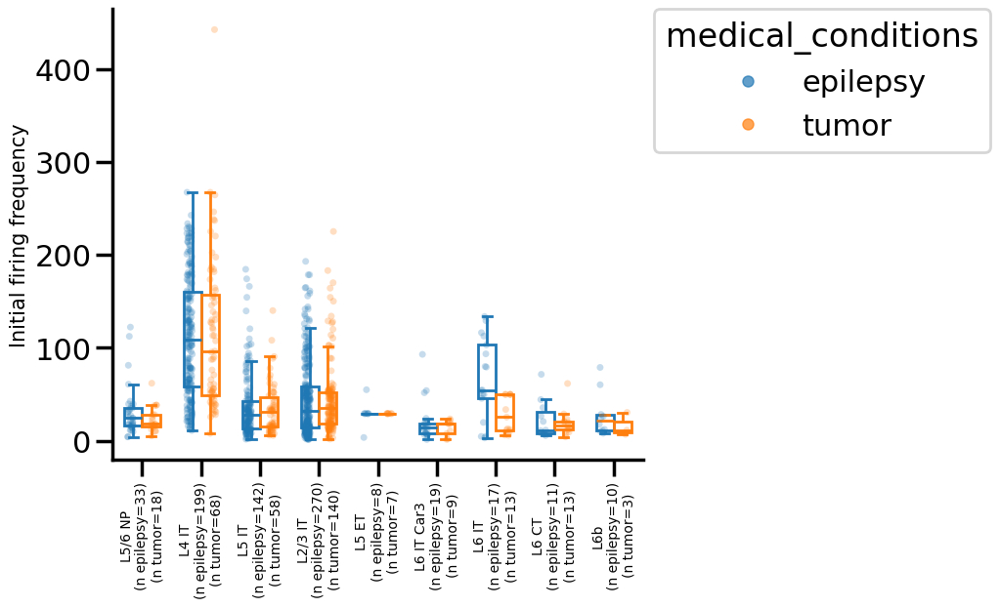

In [40]:
#compute MW - FDR stats for epilepsy and tumor medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'medical_conditions'
group1_label = 'epilepsy'
group2_label = 'tumor'
suffix = '_removeHydrocephalus'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross age box plots - subclass

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


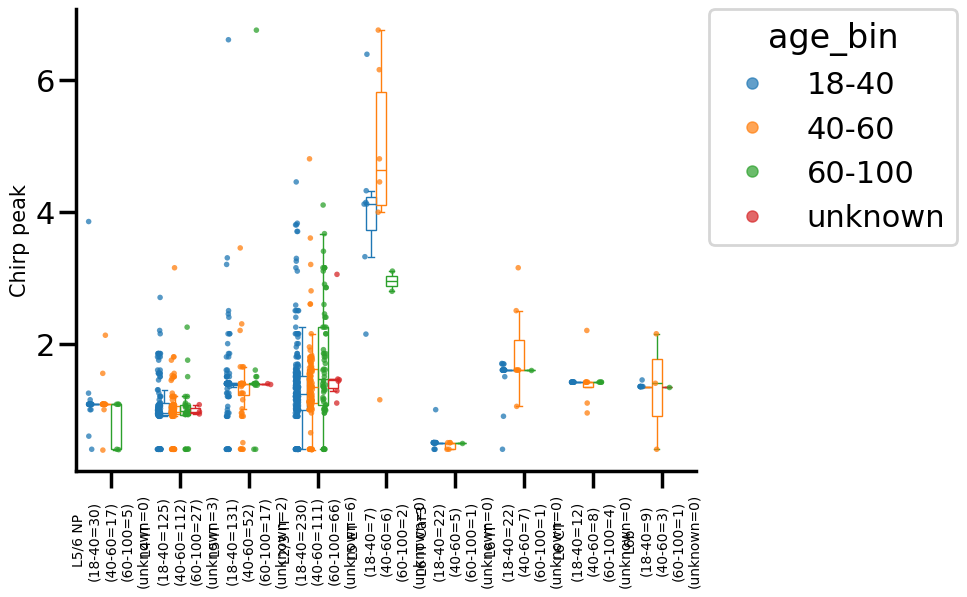

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


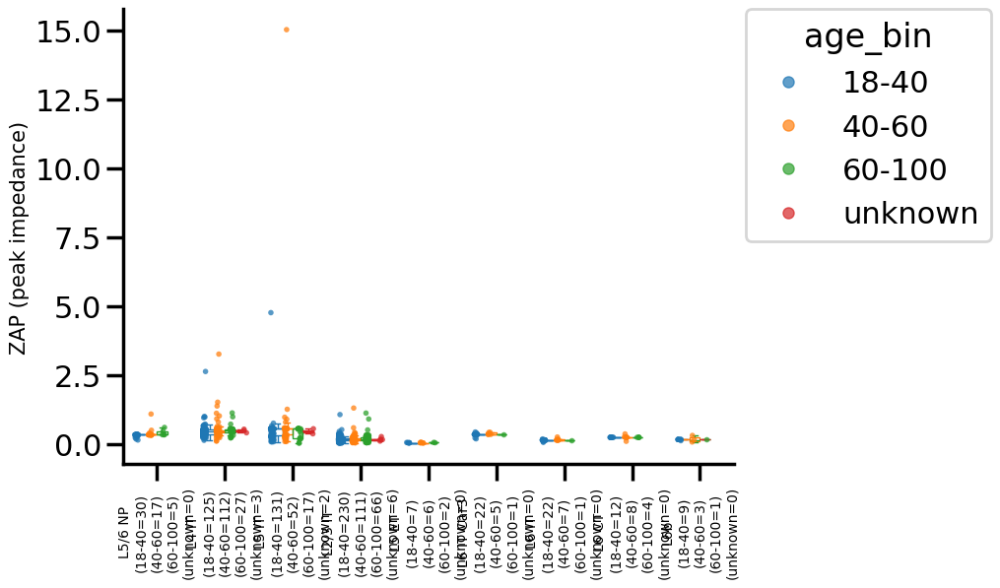

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_60-100 vs. L2/3 IT_unknown: Custom statistical test, P_val:3.968e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.624e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.821e-07


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


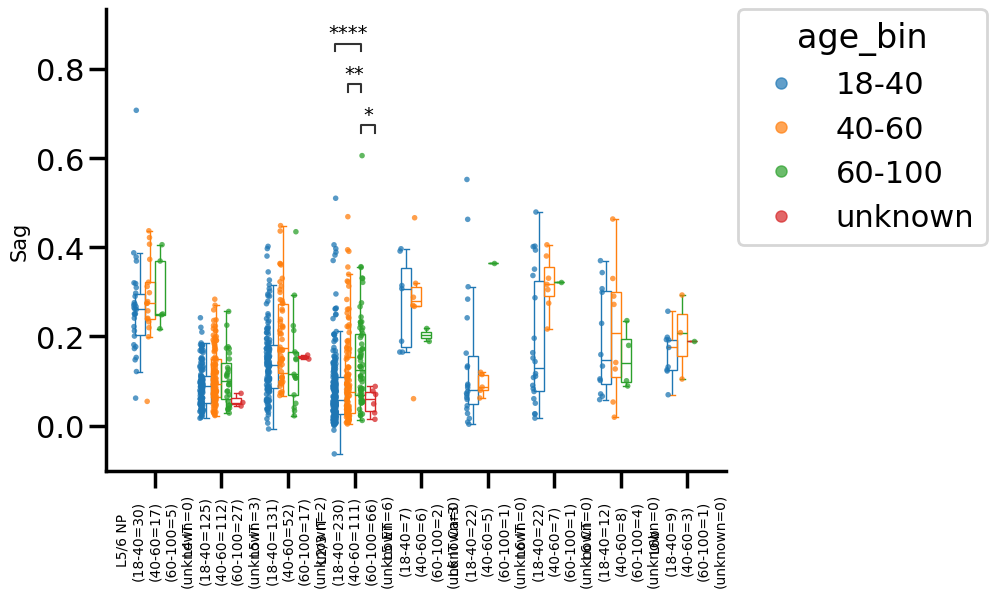

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


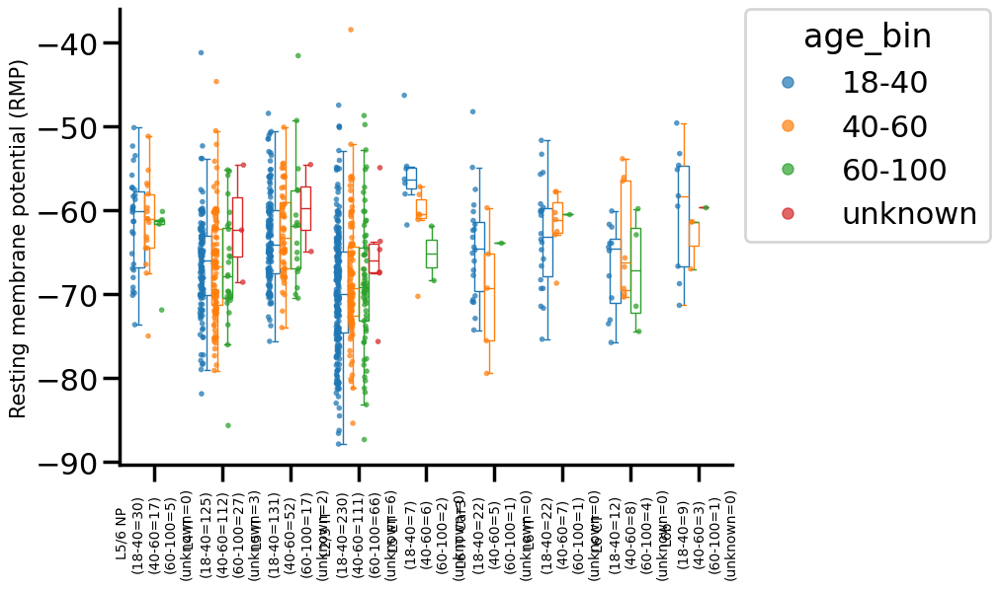

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


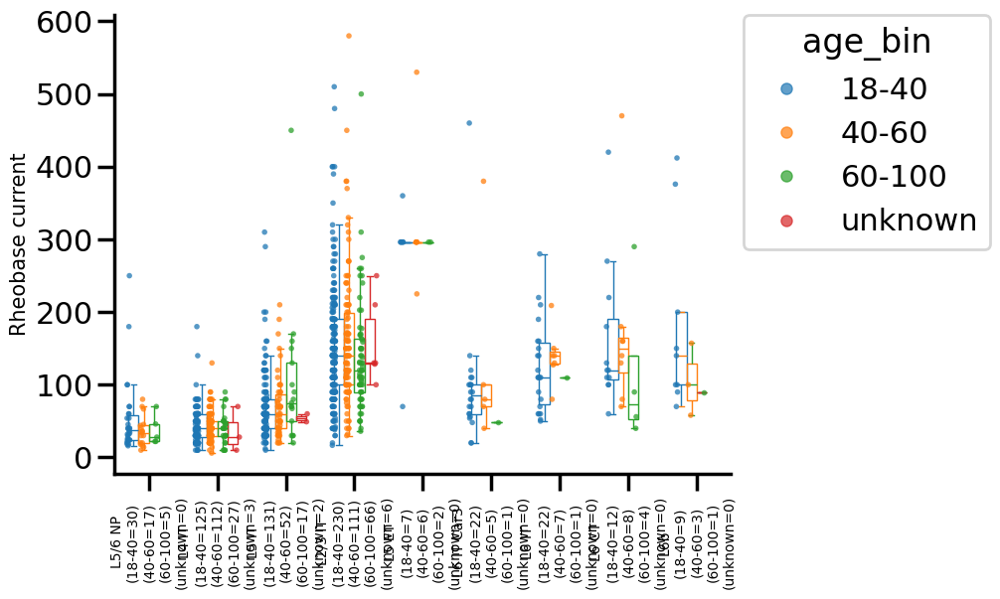

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


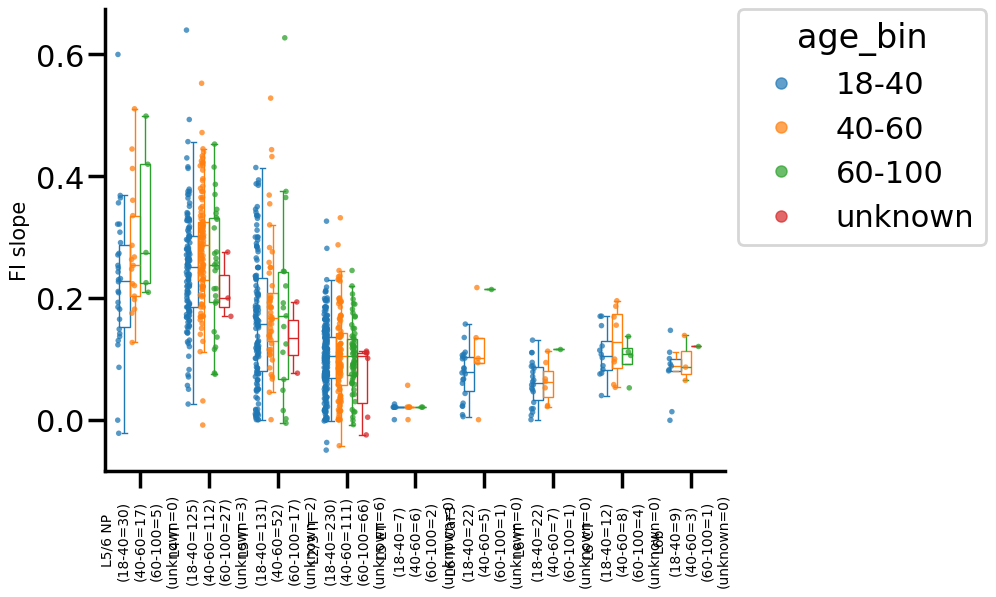

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


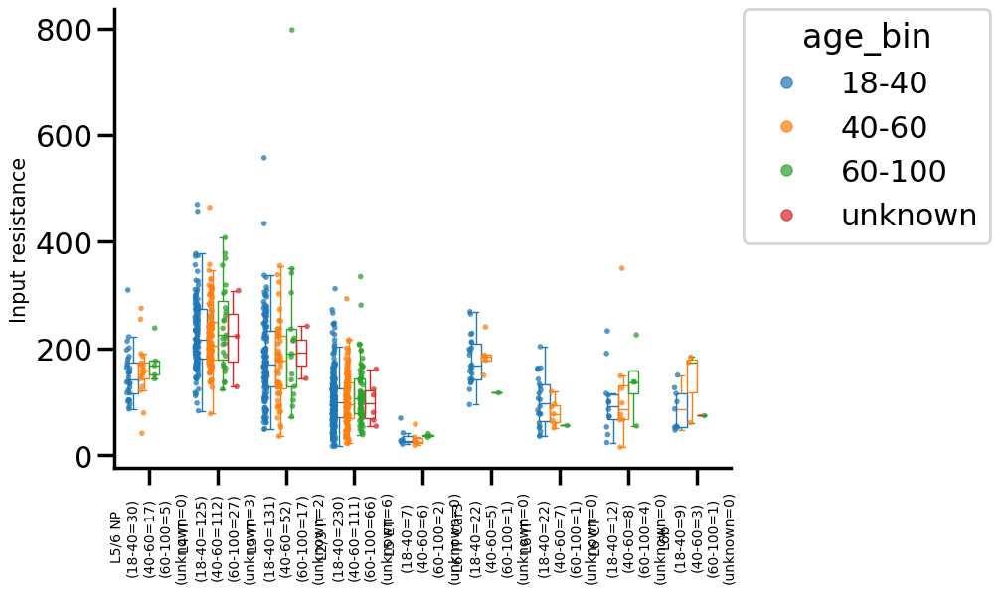

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:5.685e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


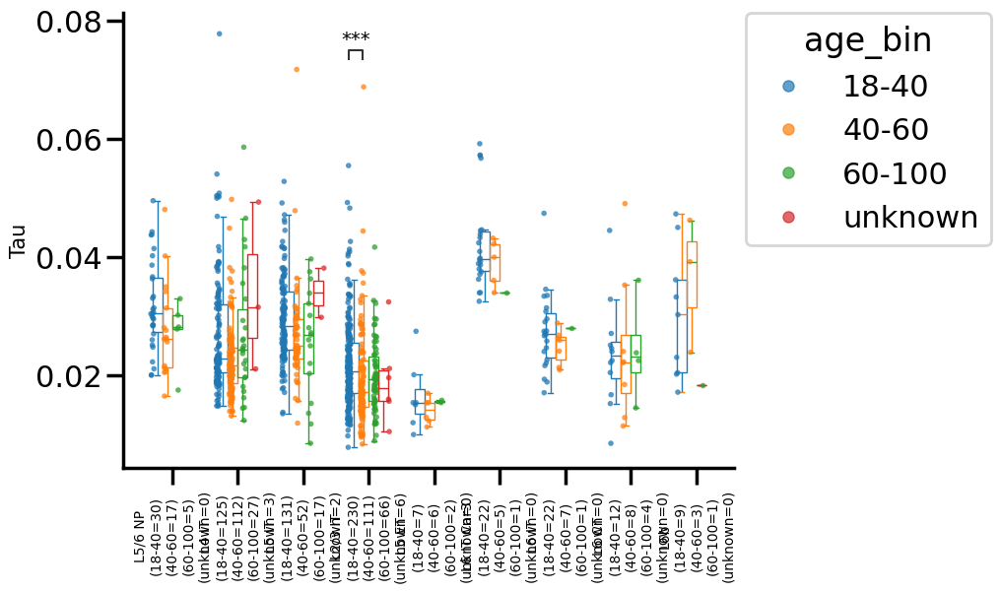

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


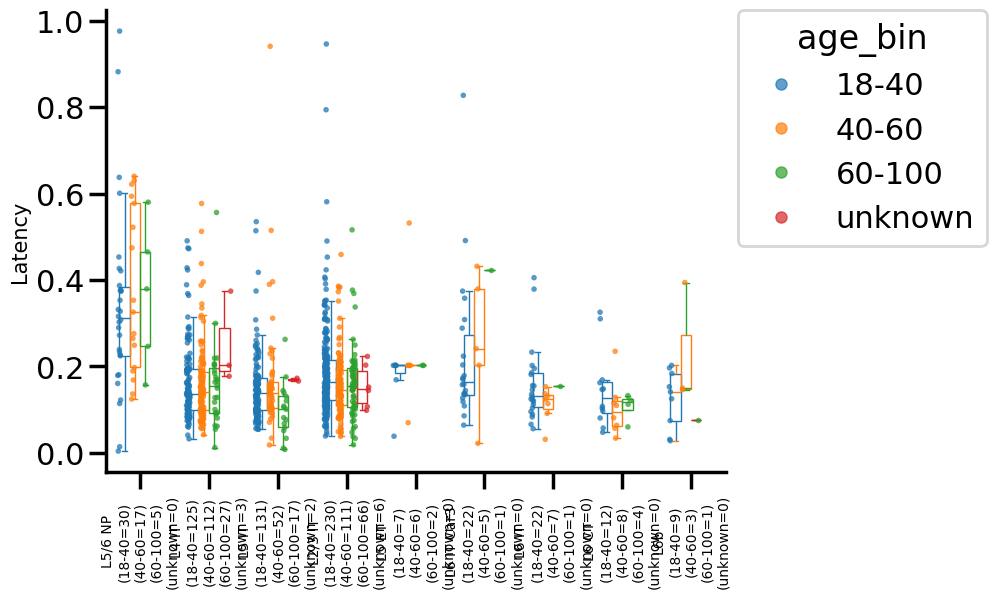

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_60-100 vs. L2/3 IT_unknown: Custom statistical test, P_val:4.665e-02
L5/6 NP_18-40 vs. L5/6 NP_40-60: Custom statistical test, P_val:9.371e-04
L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.415e-05
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:7.638e-04
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.778e-05
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:3.786e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


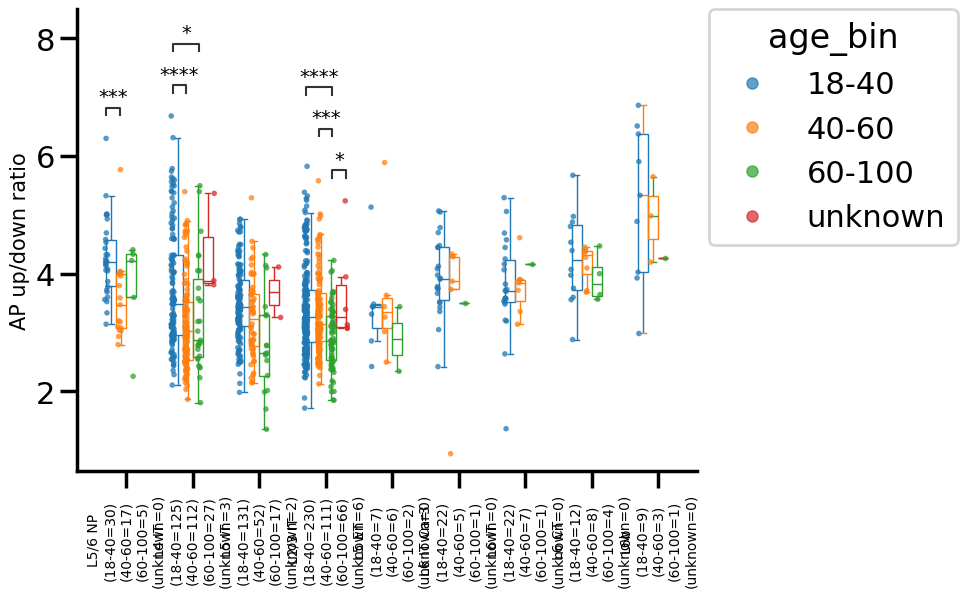

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


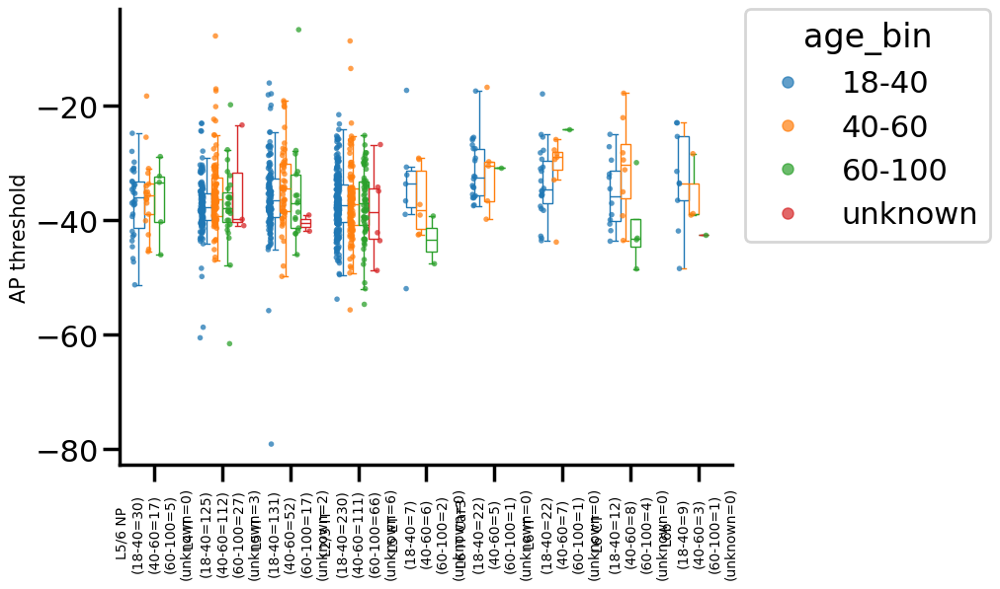

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.411e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.285e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


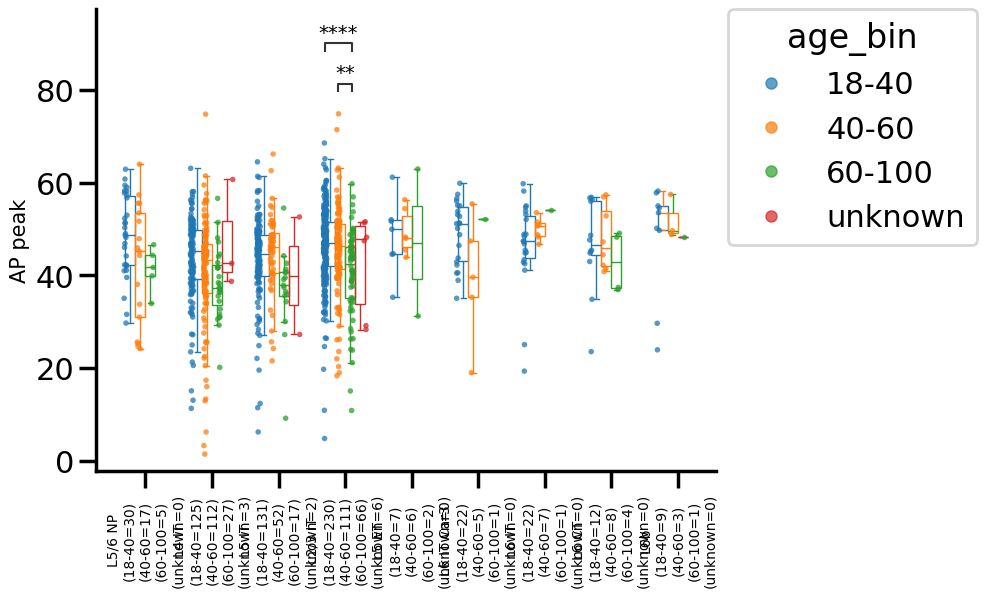

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:4.959e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


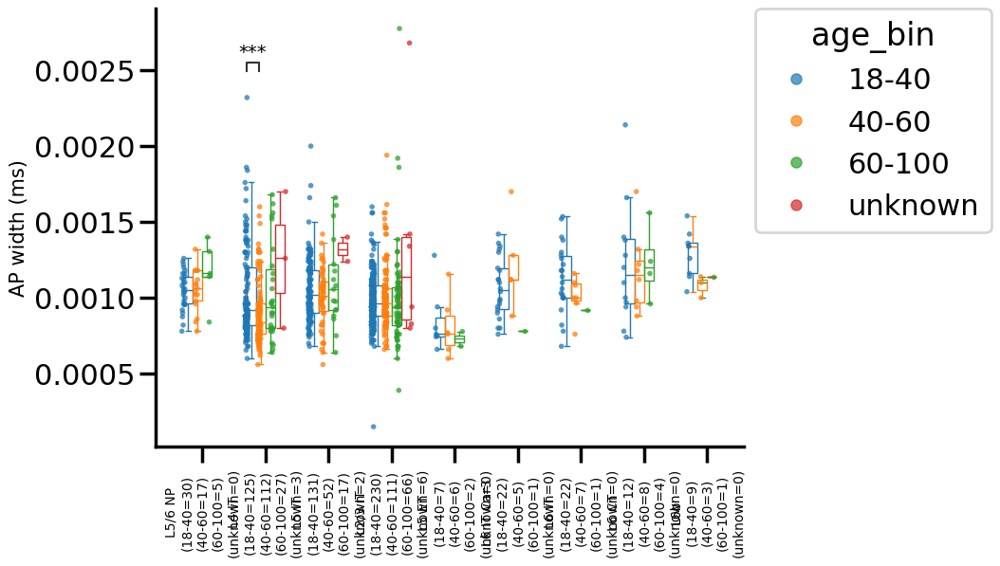

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:1.483e-04
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:2.762e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


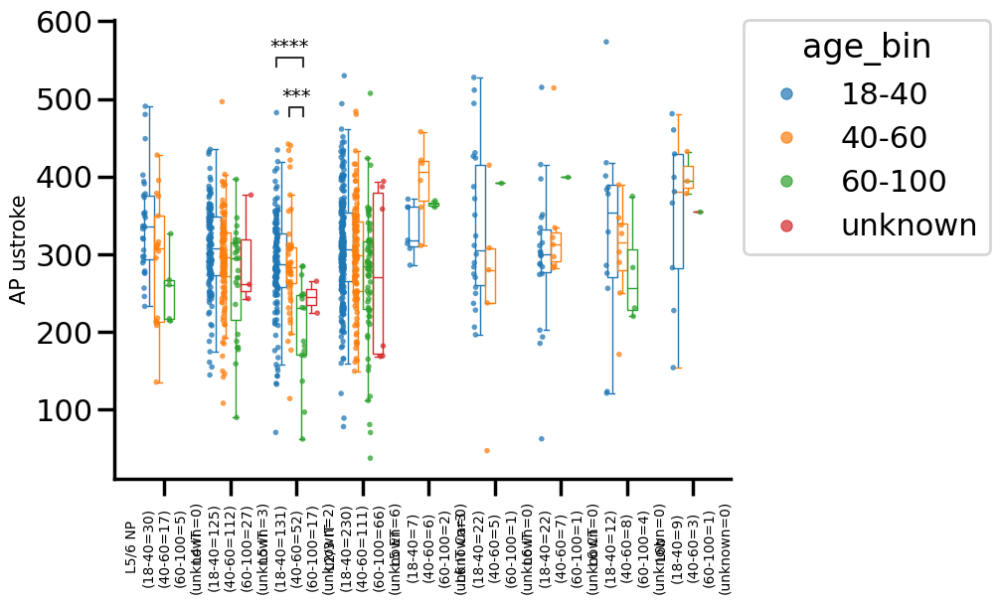

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


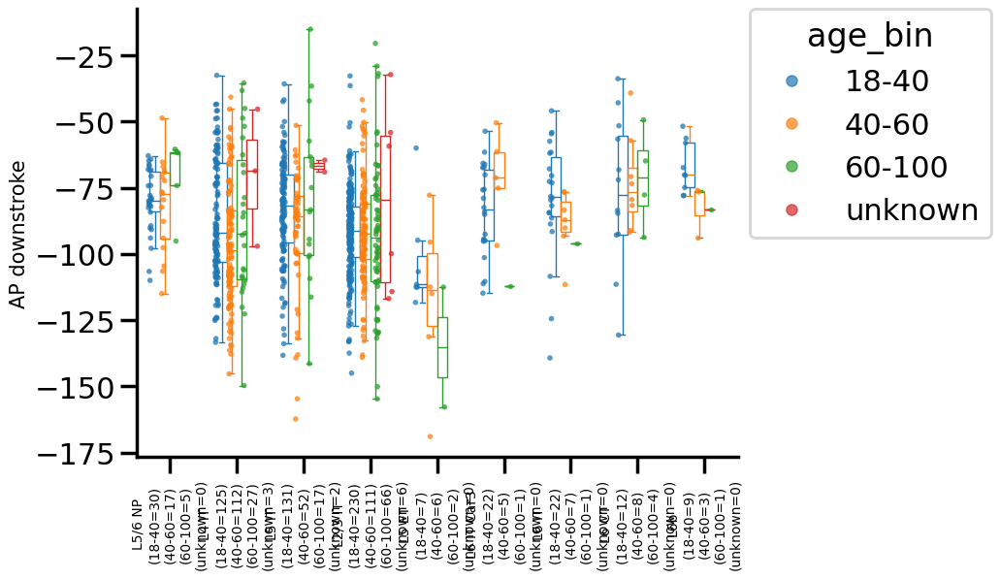

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


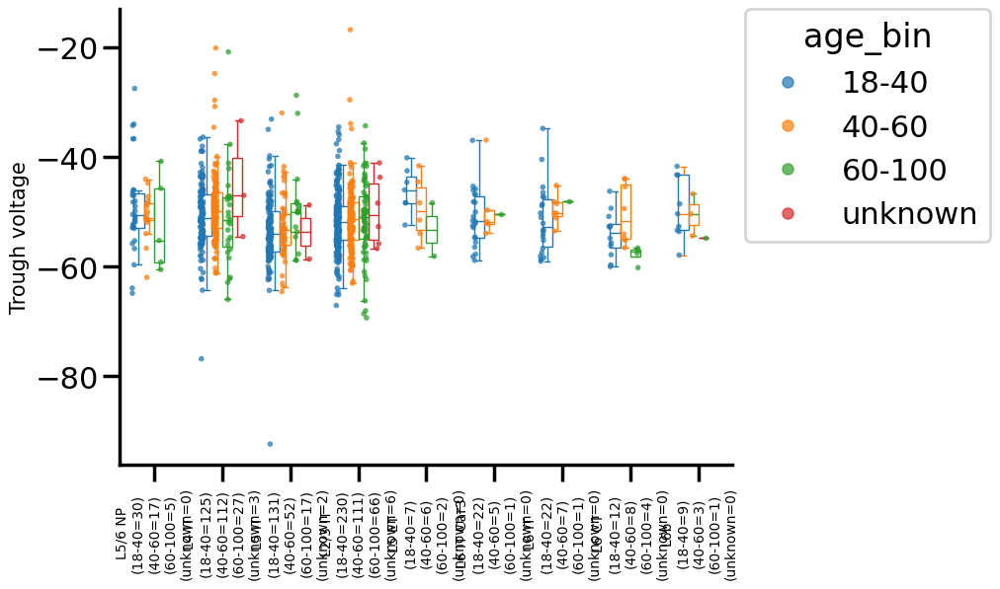

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


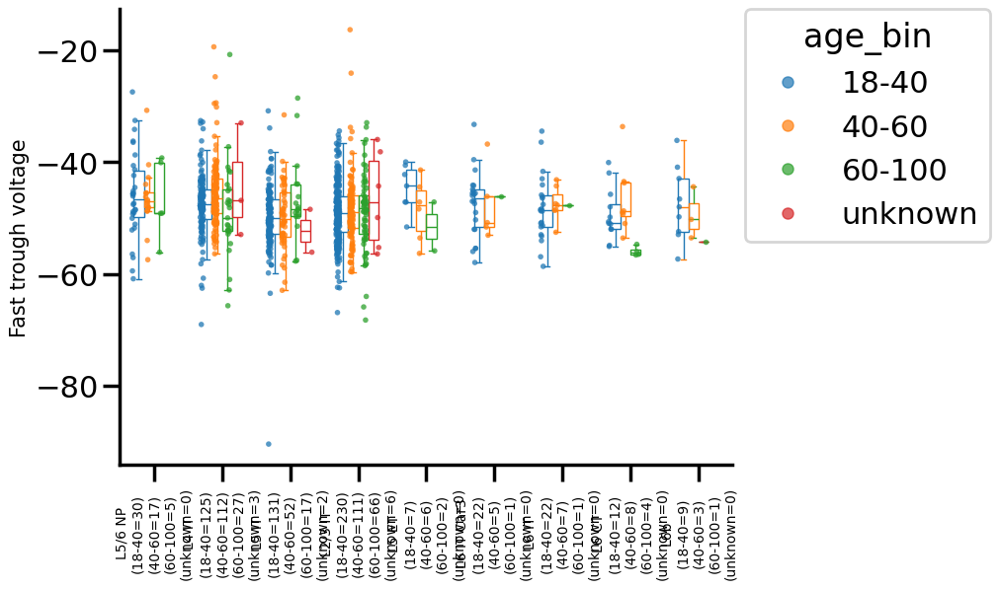

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


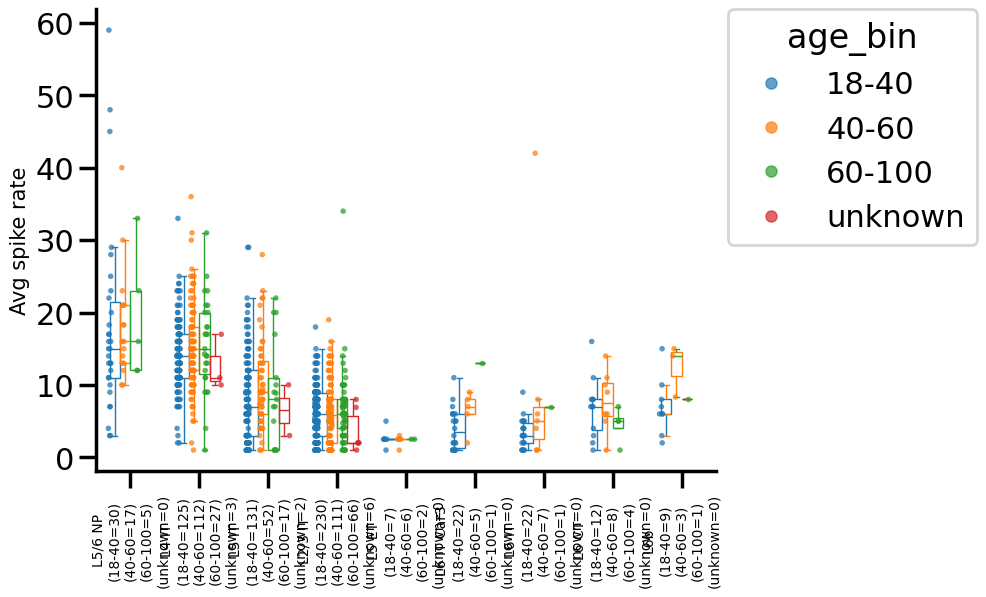

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


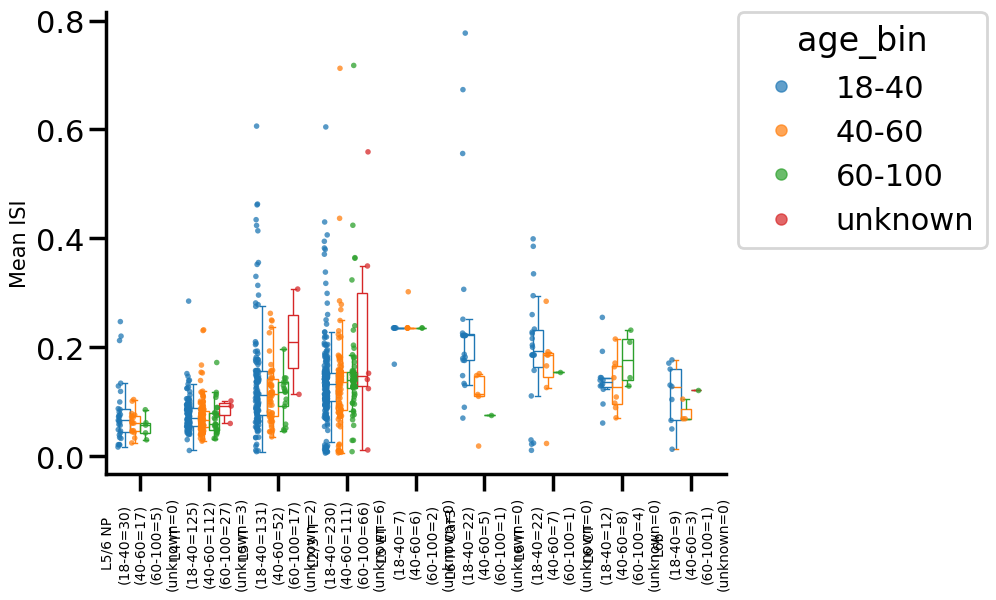

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


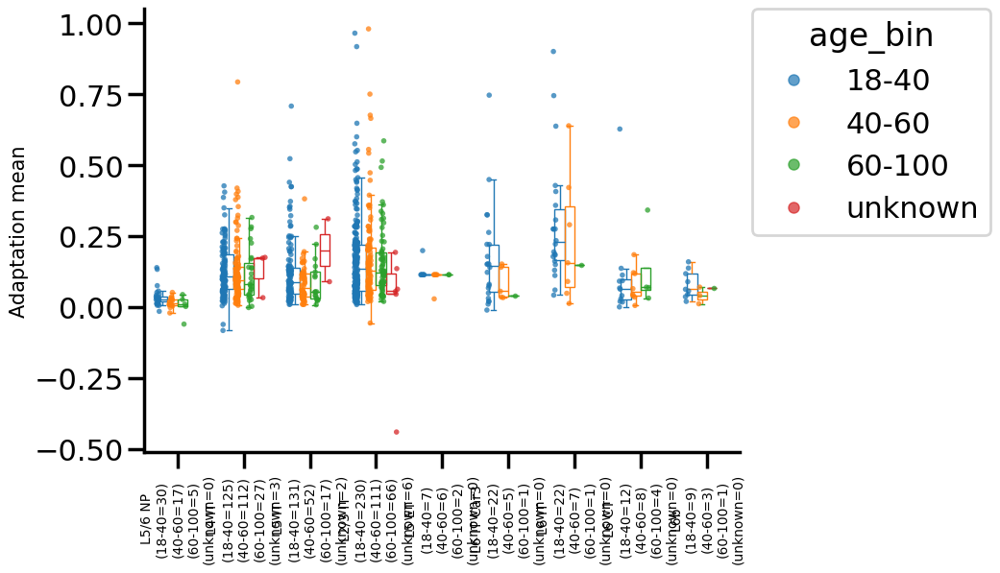

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


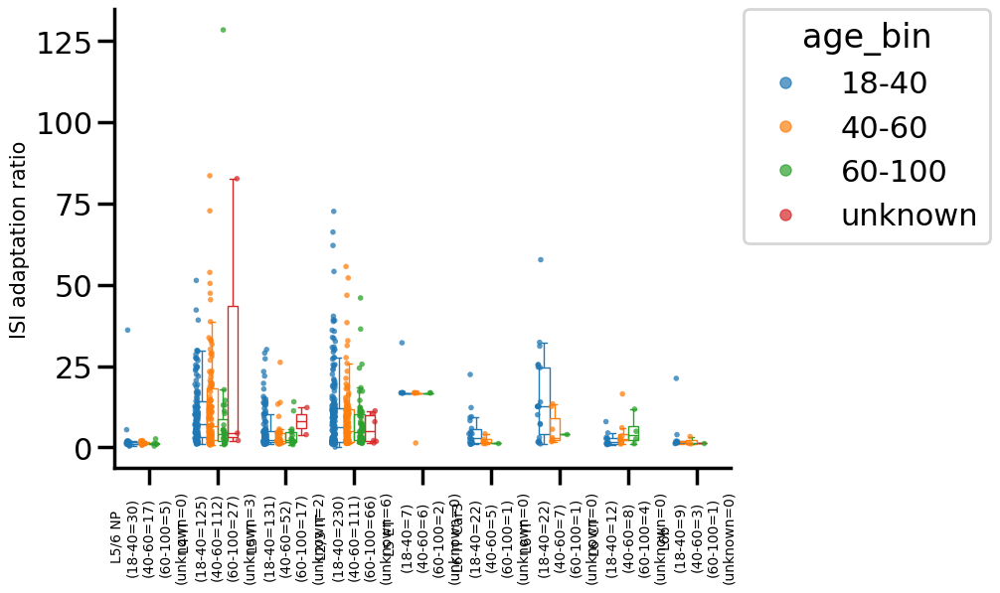

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


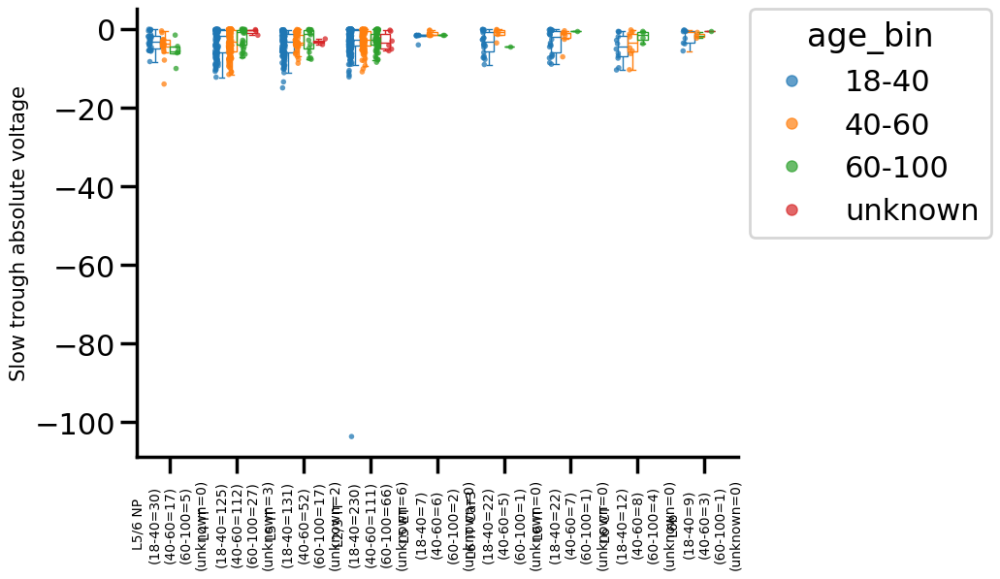

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.894e-04
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:4.699e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.223e-05
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:1.117e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


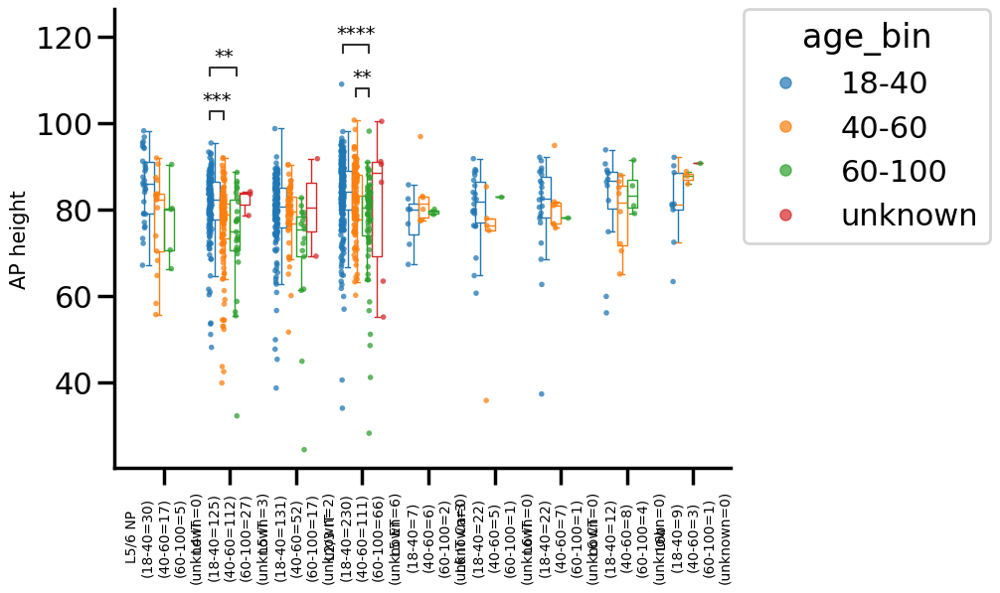

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


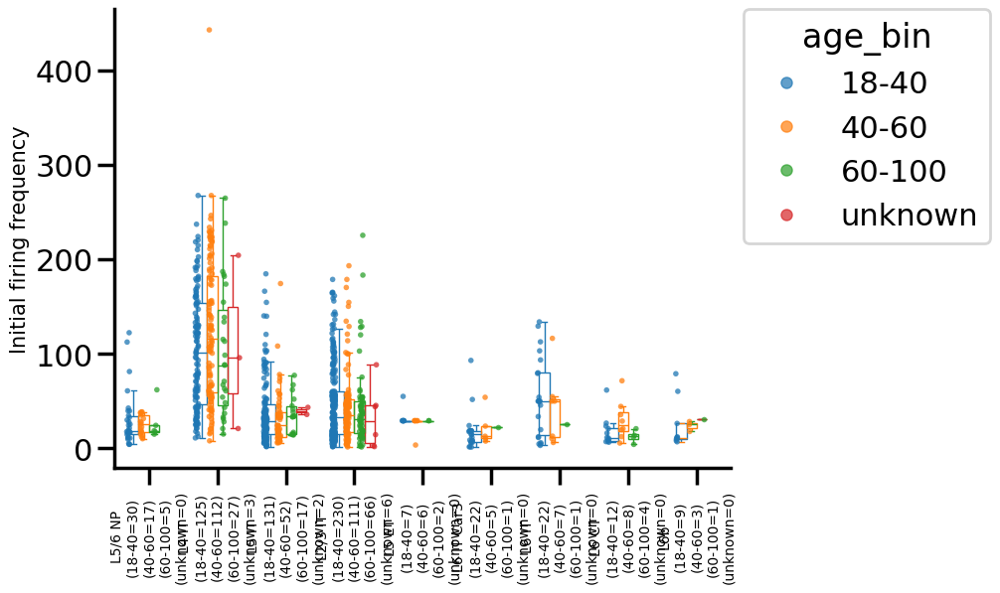

In [41]:
#compute KW - FDR - Dunn stats for all ages (including unknown)
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())

features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing `unknown` age cells

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.945e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


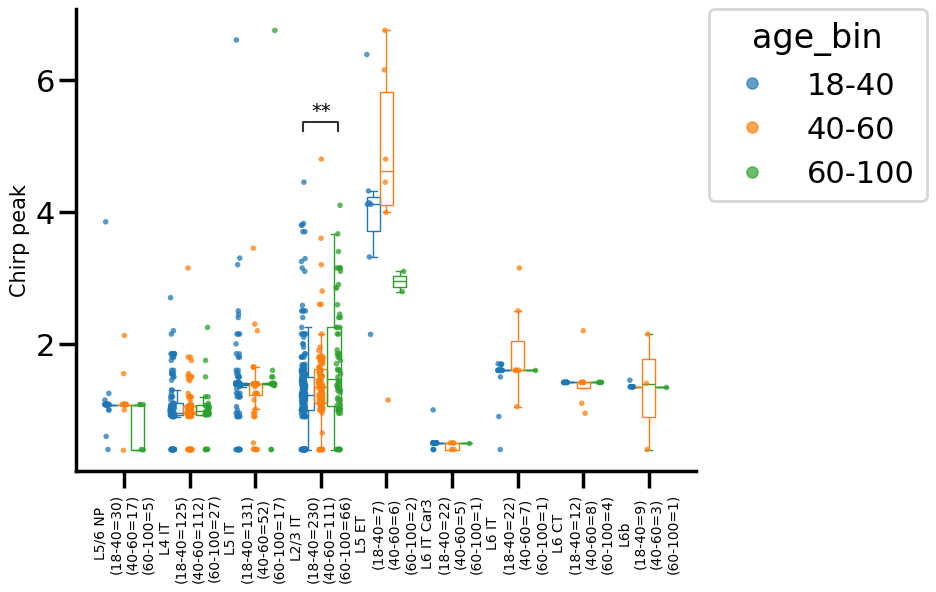

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


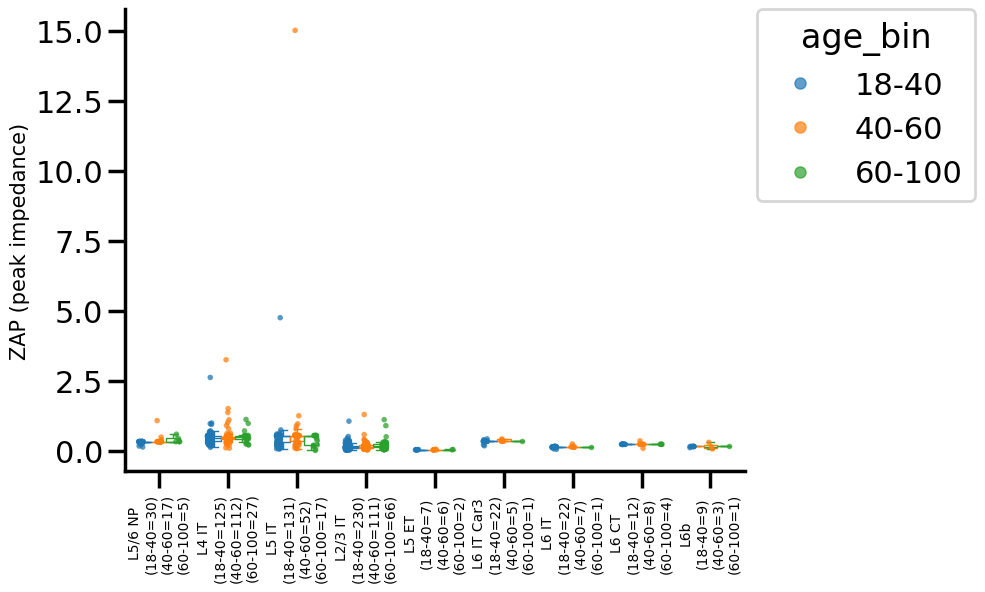

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_18-40 vs. L5 IT_40-60: Custom statistical test, P_val:1.353e-03
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:3.098e-02
L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:4.113e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:8.496e-04
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:9.752e-08


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


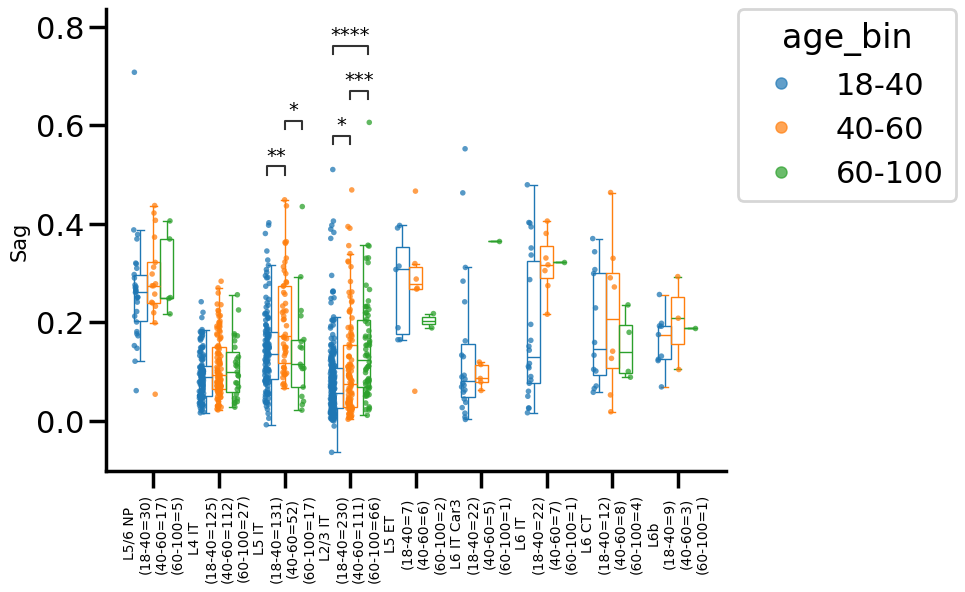

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


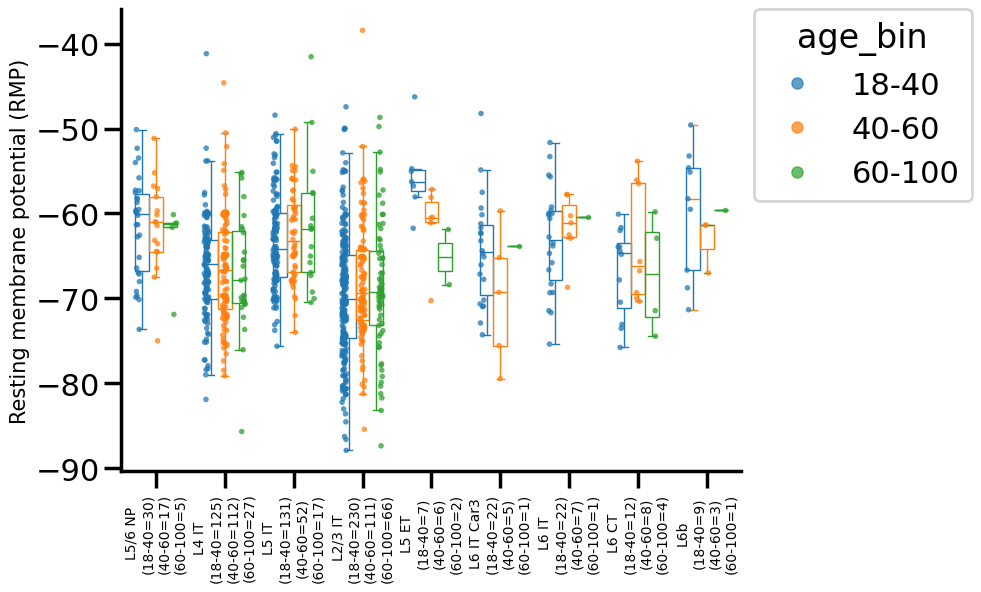

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


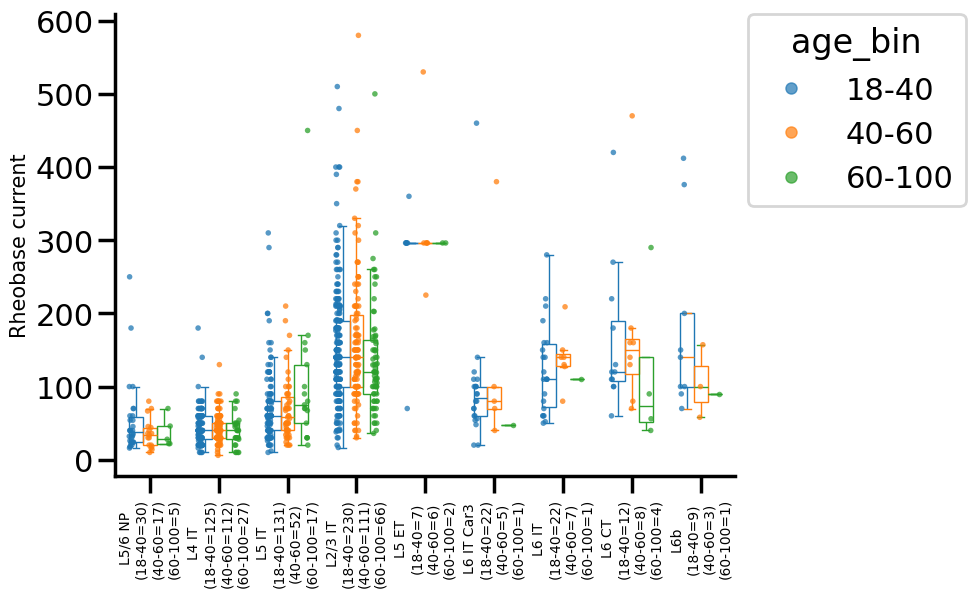

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


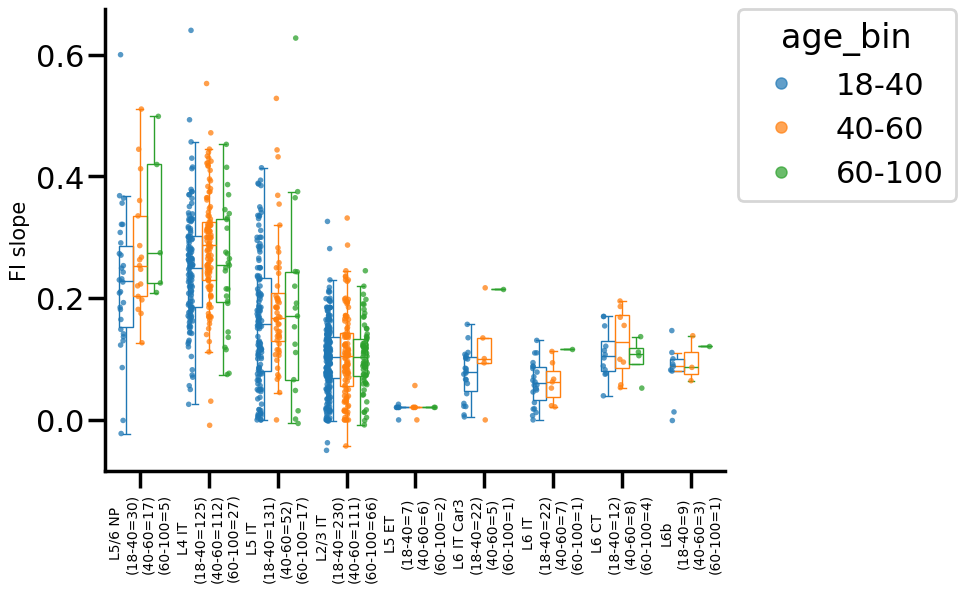

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


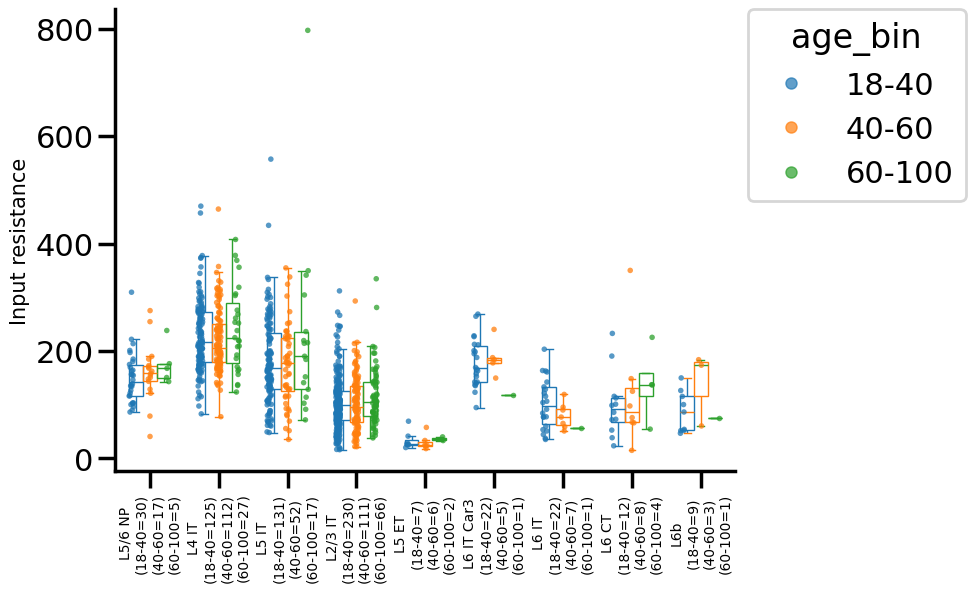

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:2.063e-03
L2/3 IT_18-40 vs. L2/3 IT_40-60: Custom statistical test, P_val:2.906e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


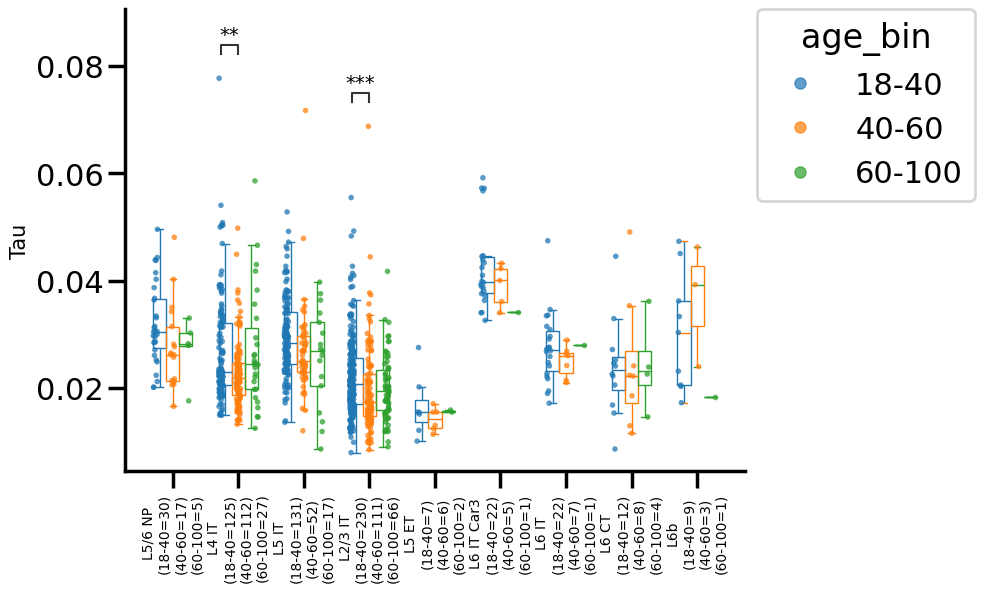

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


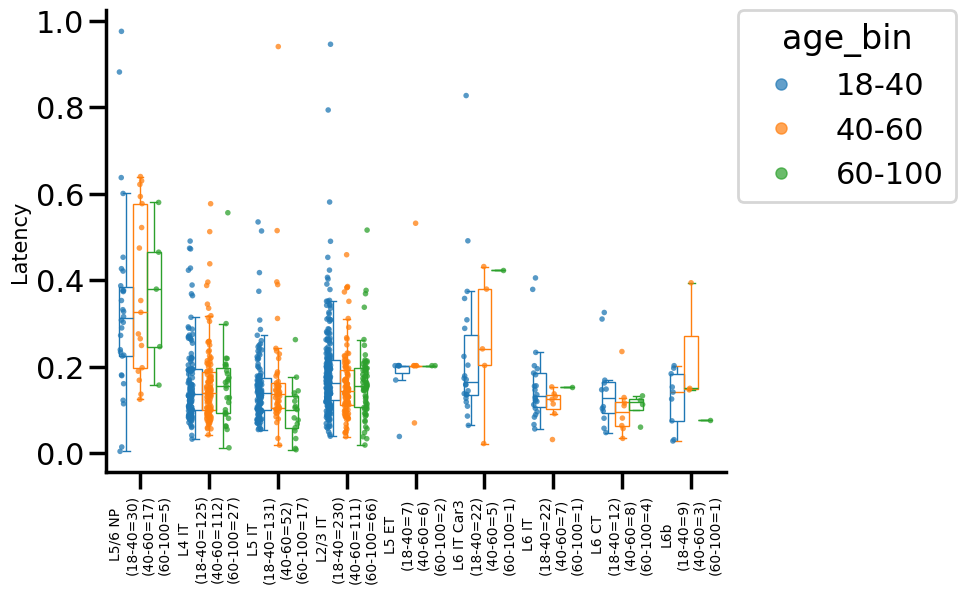

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:7.011e-06
L5 IT_18-40 vs. L5 IT_40-60: Custom statistical test, P_val:4.572e-02
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:3.675e-04
L5/6 NP_18-40 vs. L5/6 NP_40-60: Custom statistical test, P_val:9.371e-04
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:1.837e-02
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:3.022e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:1.374e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


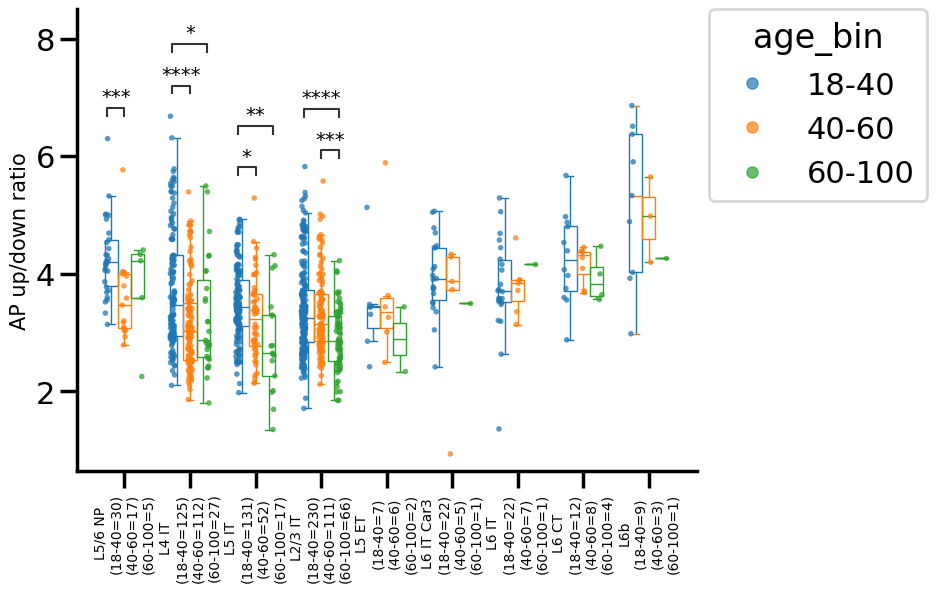

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


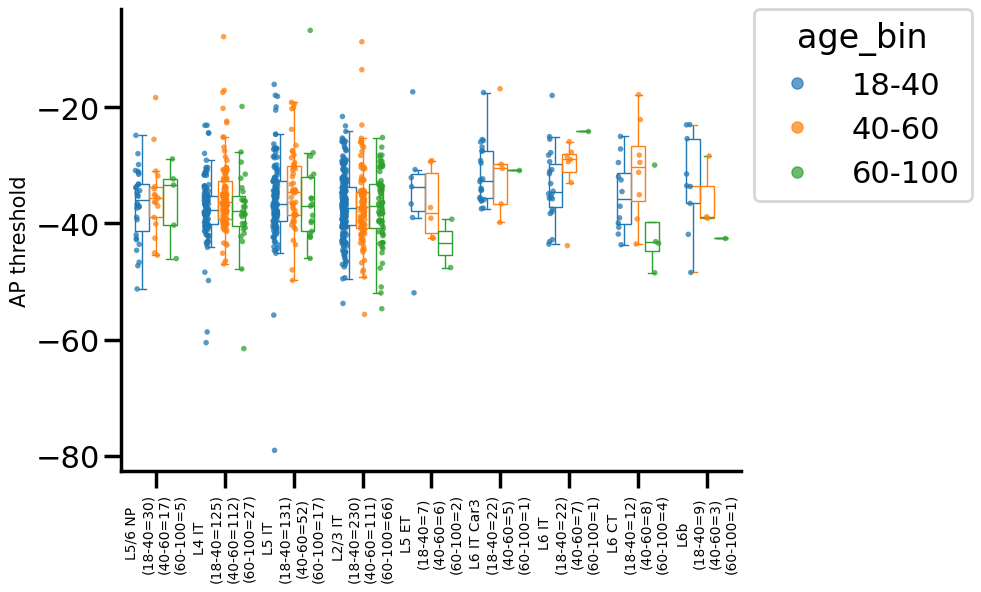

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:3.994e-02
L4 IT_40-60 vs. L4 IT_60-100: Custom statistical test, P_val:3.994e-02
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:9.564e-04
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:6.895e-04
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:1.852e-03
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:1.083e-03
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:6.336e-06


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


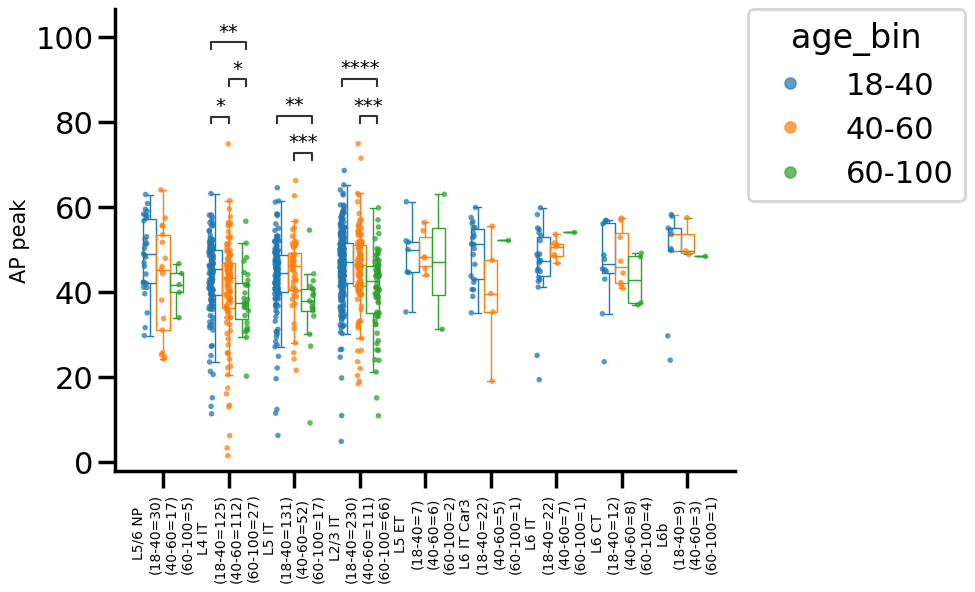

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:2.467e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


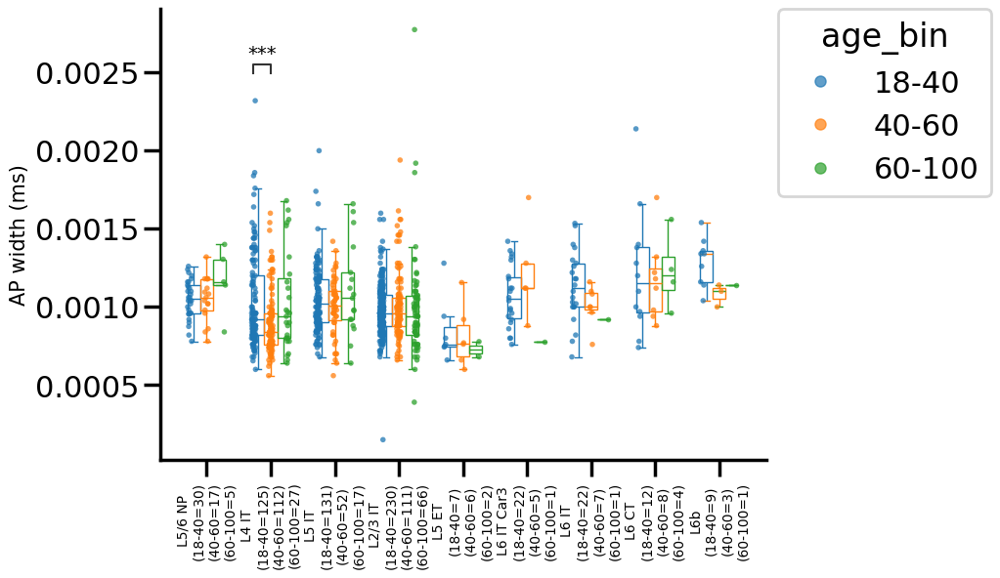

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:7.813e-05
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:1.461e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


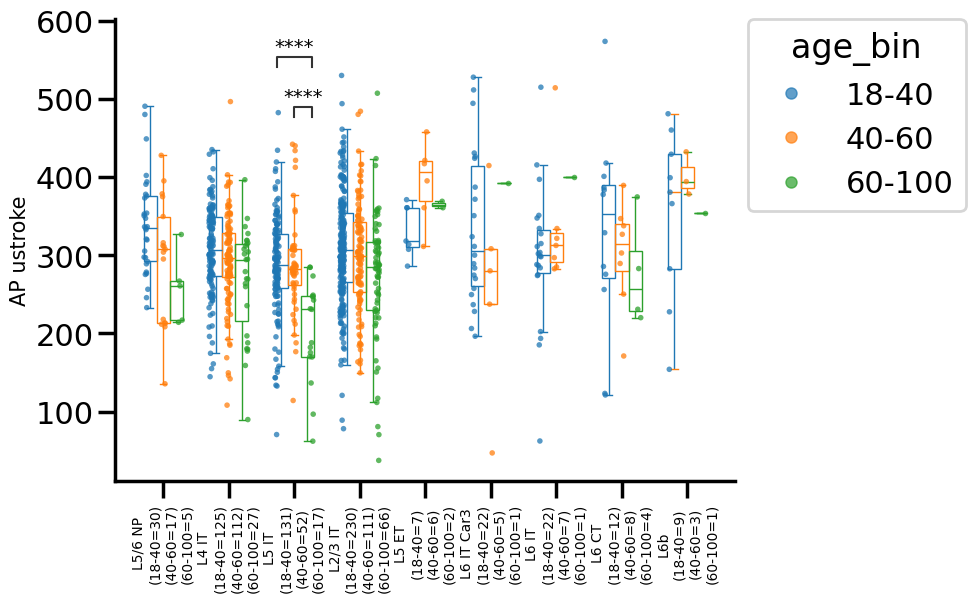

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


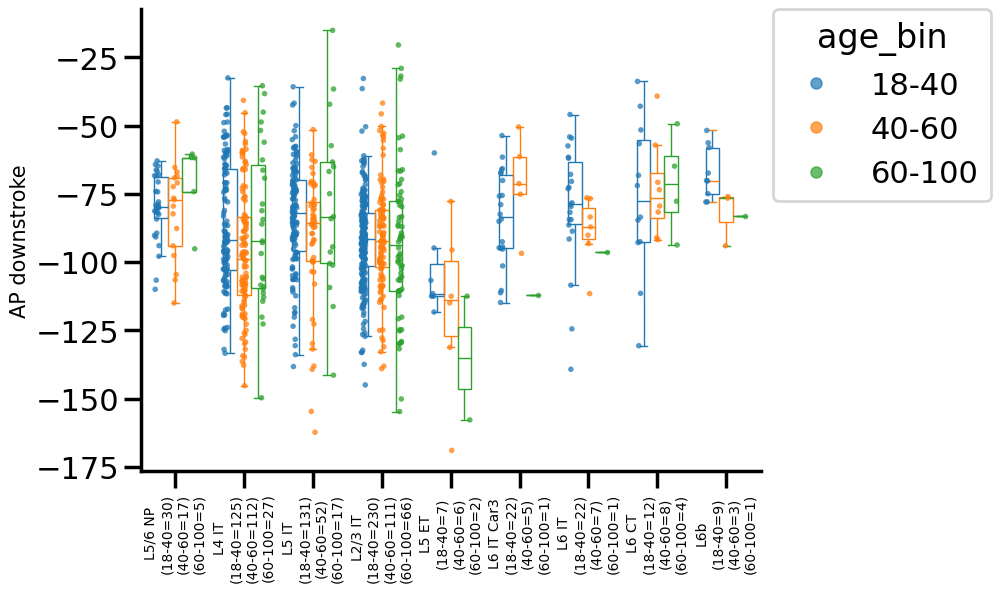

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


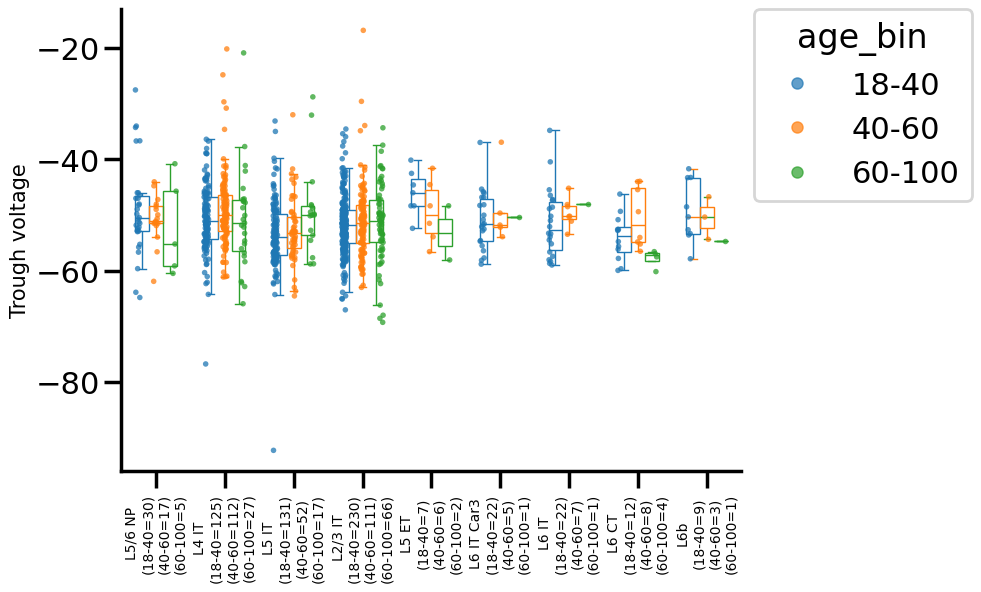

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


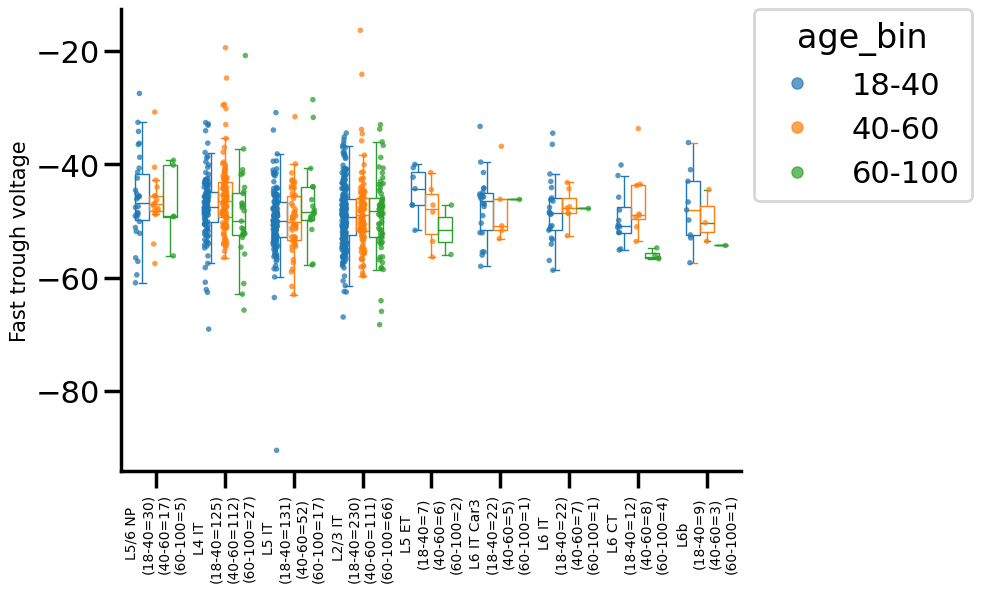

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


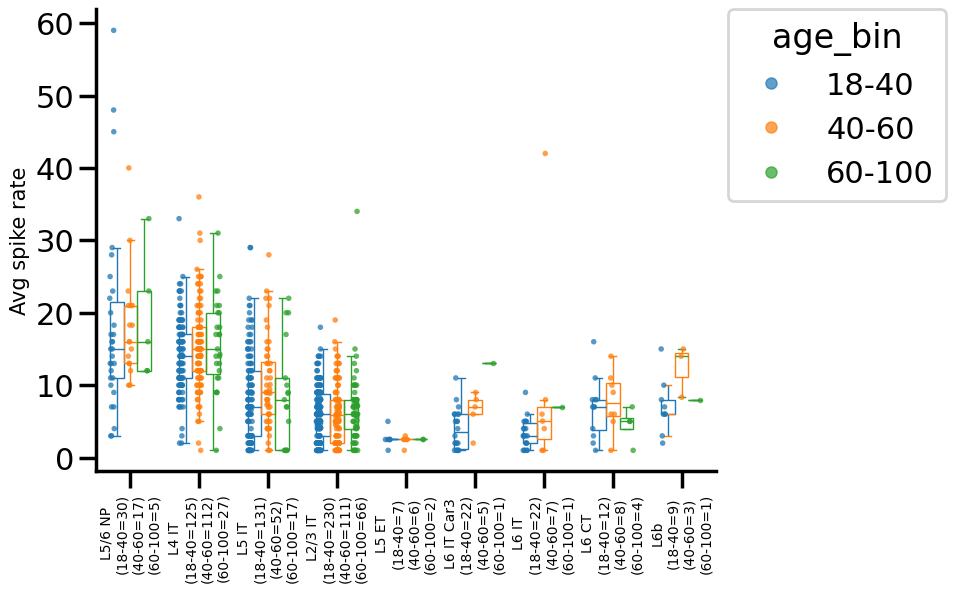

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


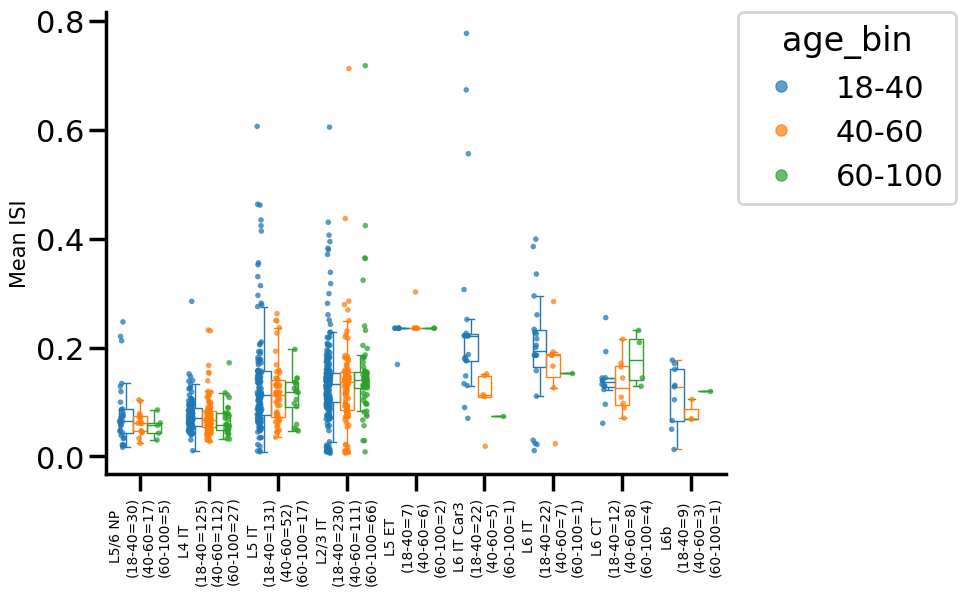

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


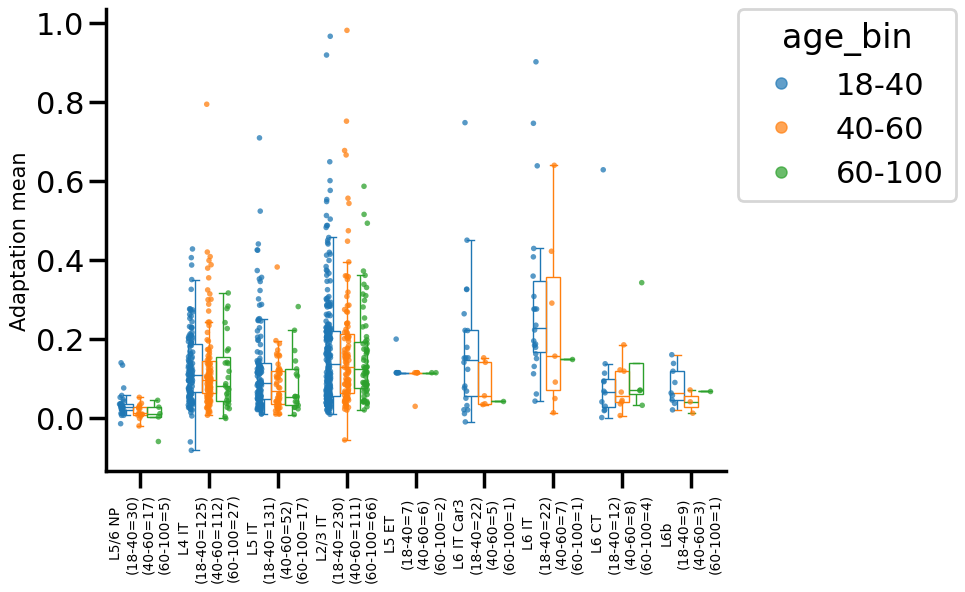

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


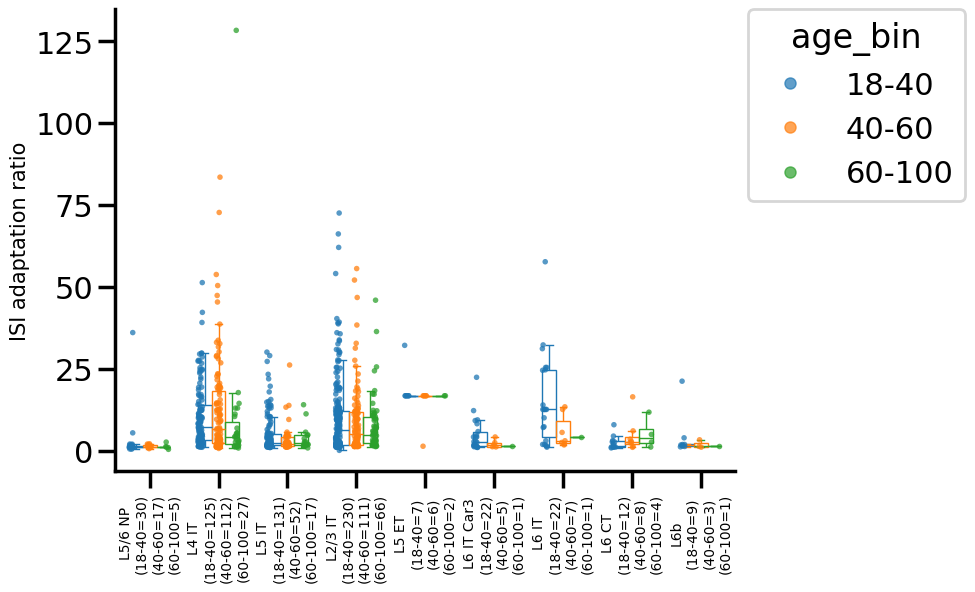

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


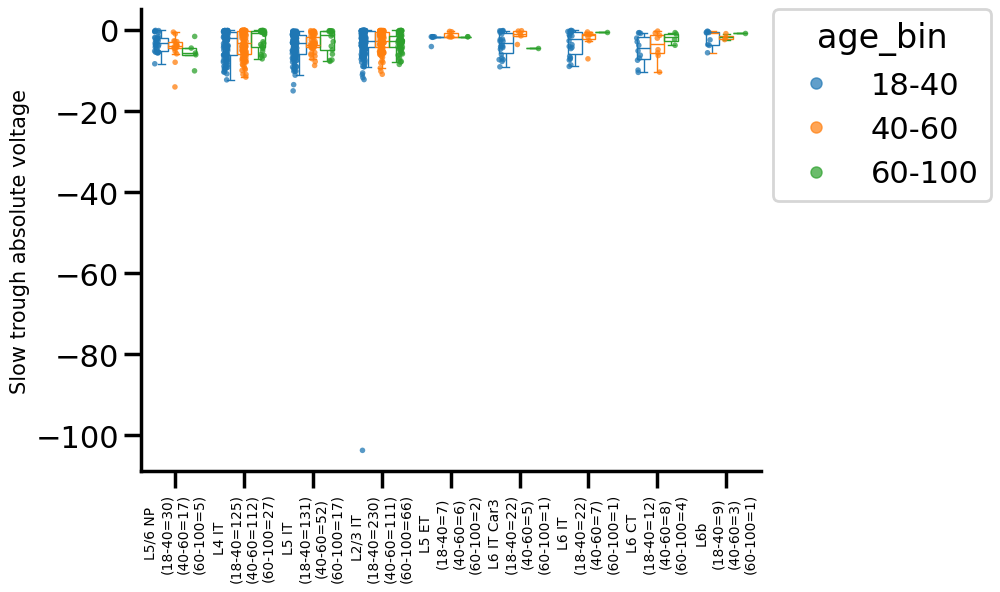

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_18-40 vs. L4 IT_40-60: Custom statistical test, P_val:1.051e-04
L5 IT_40-60 vs. L5 IT_60-100: Custom statistical test, P_val:5.218e-03
L2/3 IT_40-60 vs. L2/3 IT_60-100: Custom statistical test, P_val:2.232e-03
L4 IT_18-40 vs. L4 IT_60-100: Custom statistical test, P_val:5.773e-04
L5 IT_18-40 vs. L5 IT_60-100: Custom statistical test, P_val:9.648e-04
L2/3 IT_18-40 vs. L2/3 IT_60-100: Custom statistical test, P_val:5.331e-06


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


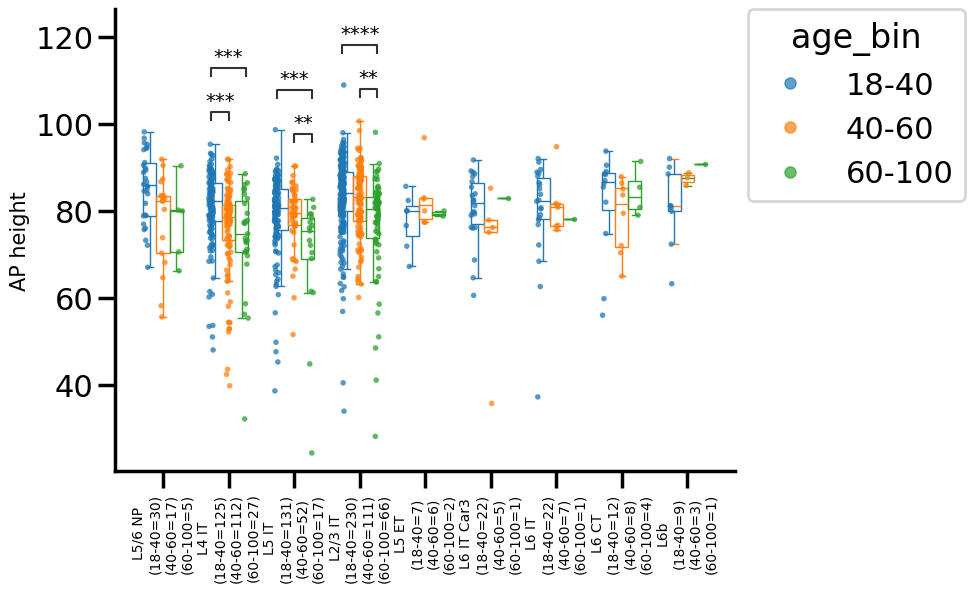

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


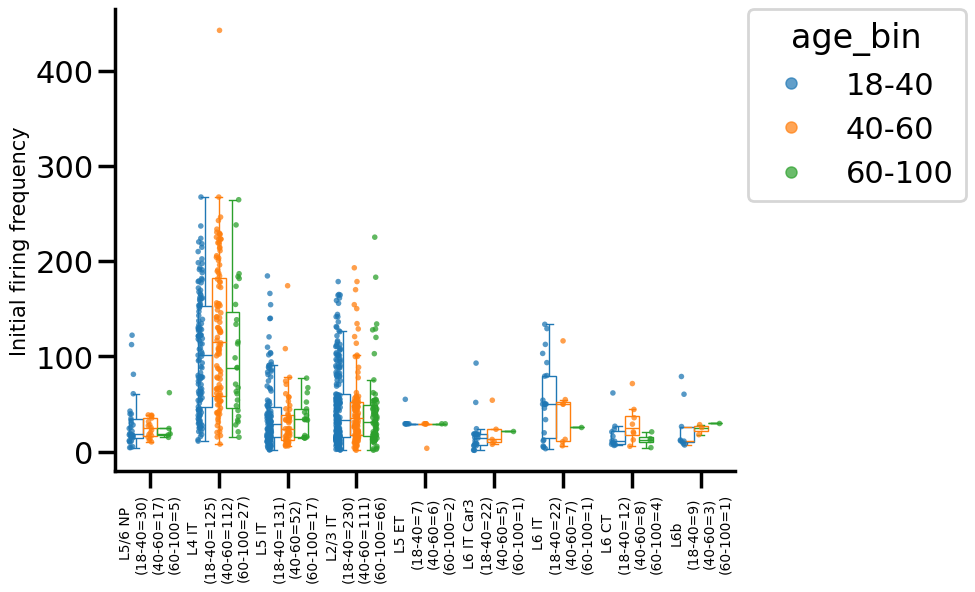

In [42]:
#compute KW - FDR - Dunn stats for all medical conditions
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'age_bin'
group_order = sorted(sorted_clean_data[group_var].unique().tolist())
group_order.remove('unknown')
suffix = '_removeUnknown'
features = feature_cols.copy()
kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


Cross sex box plots - subclass

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


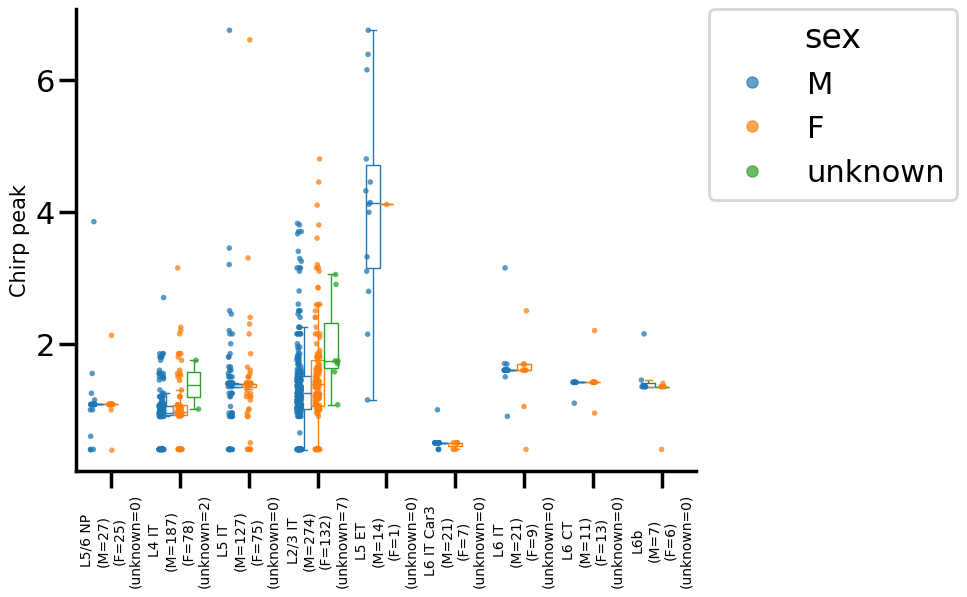

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


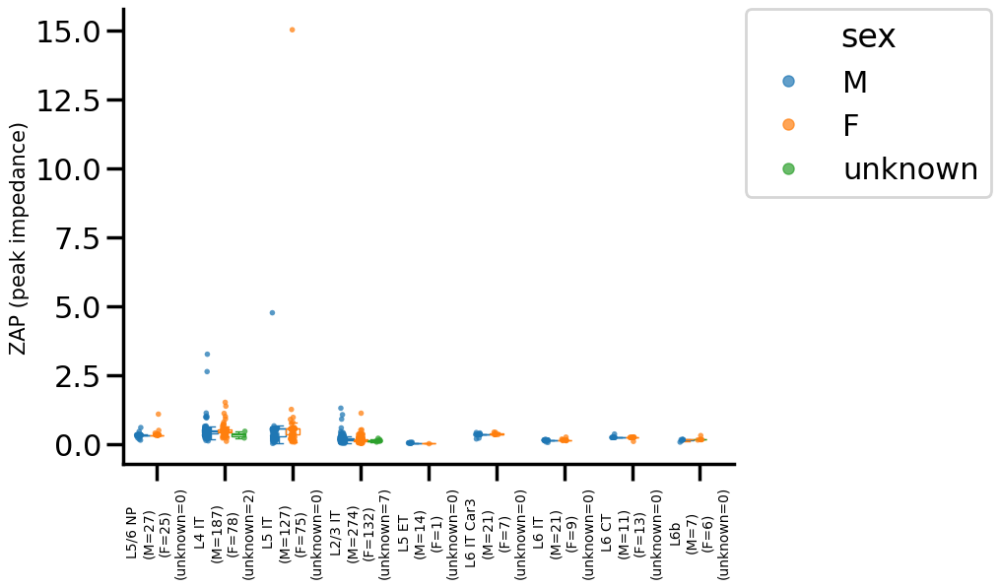

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_M vs. L2/3 IT_F: Custom statistical test, P_val:2.663e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


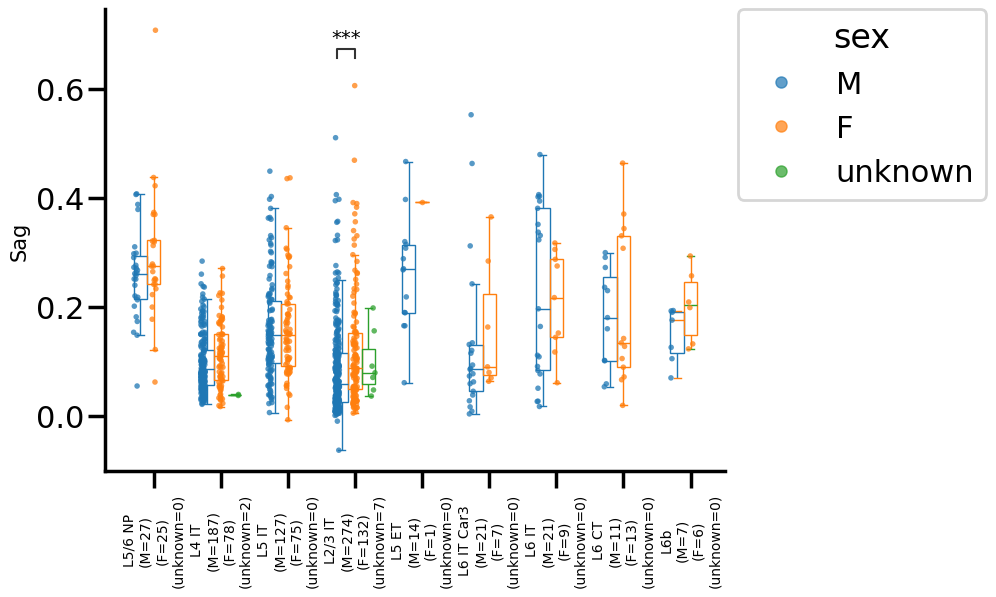

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


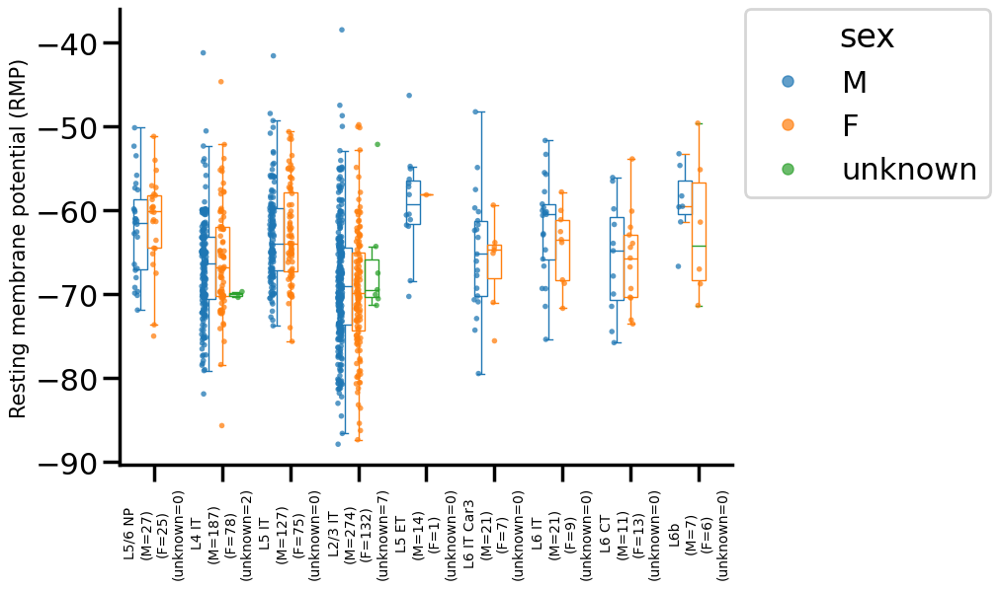

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


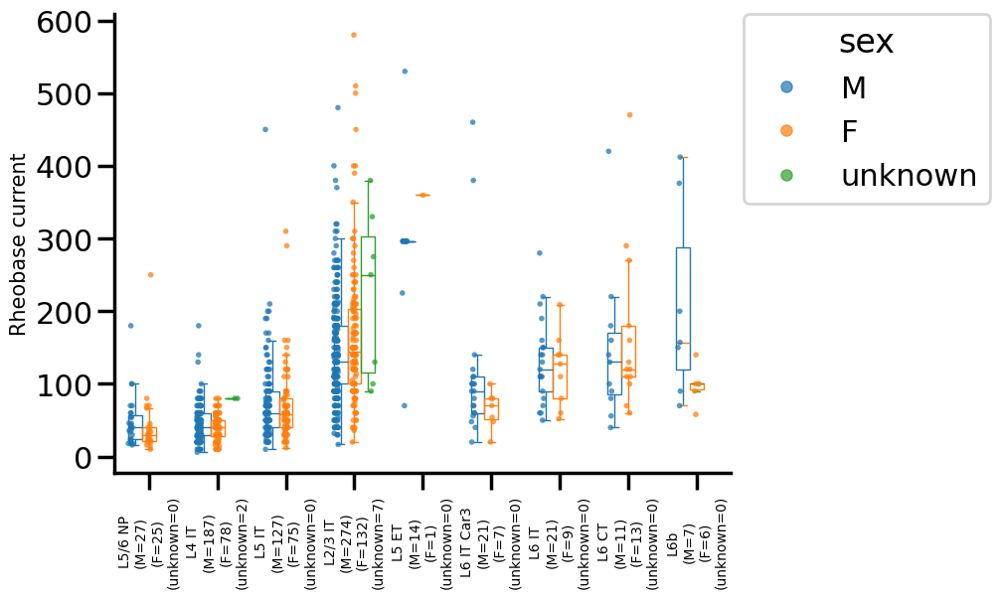

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


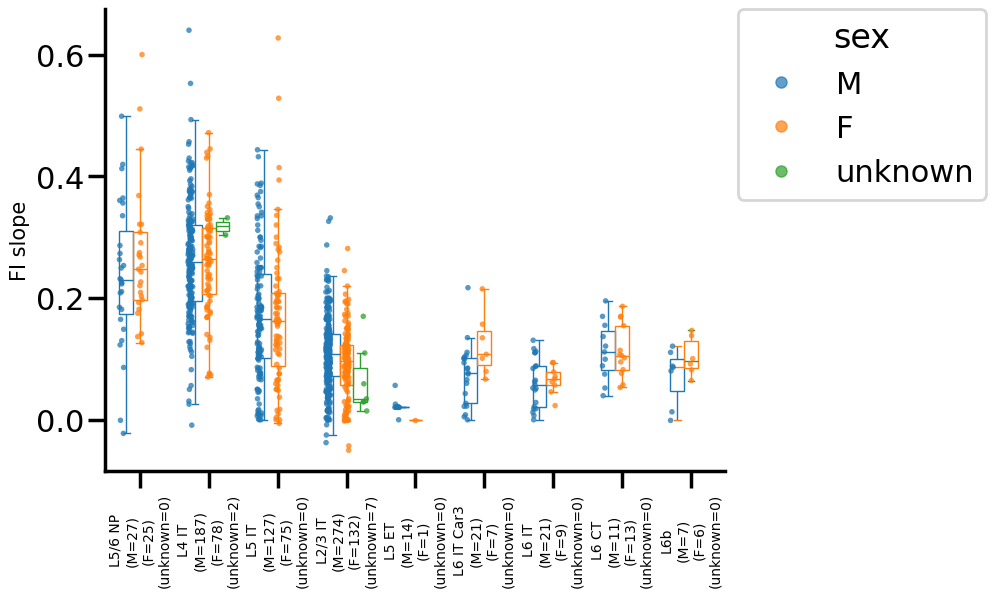

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


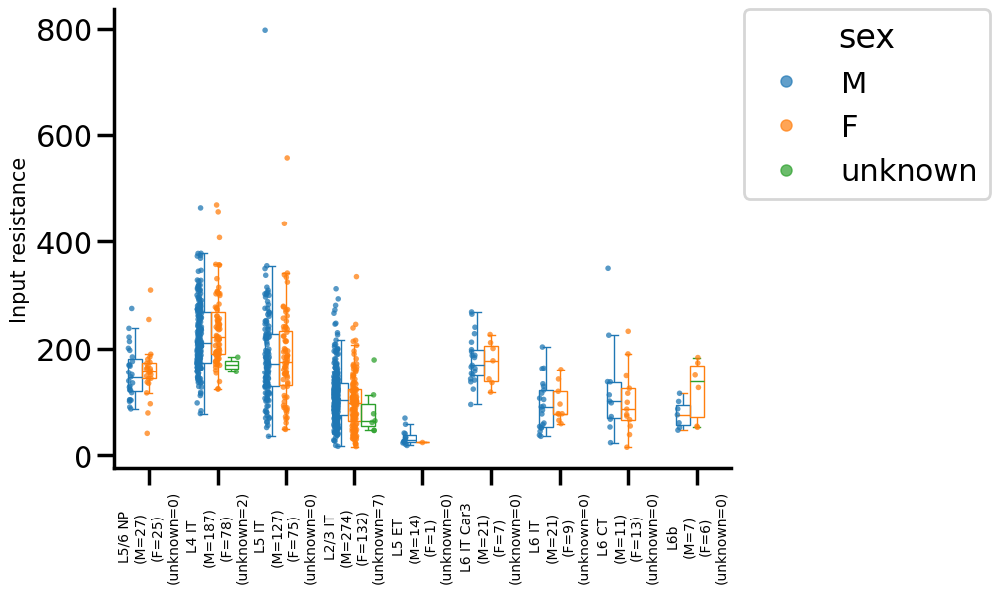

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


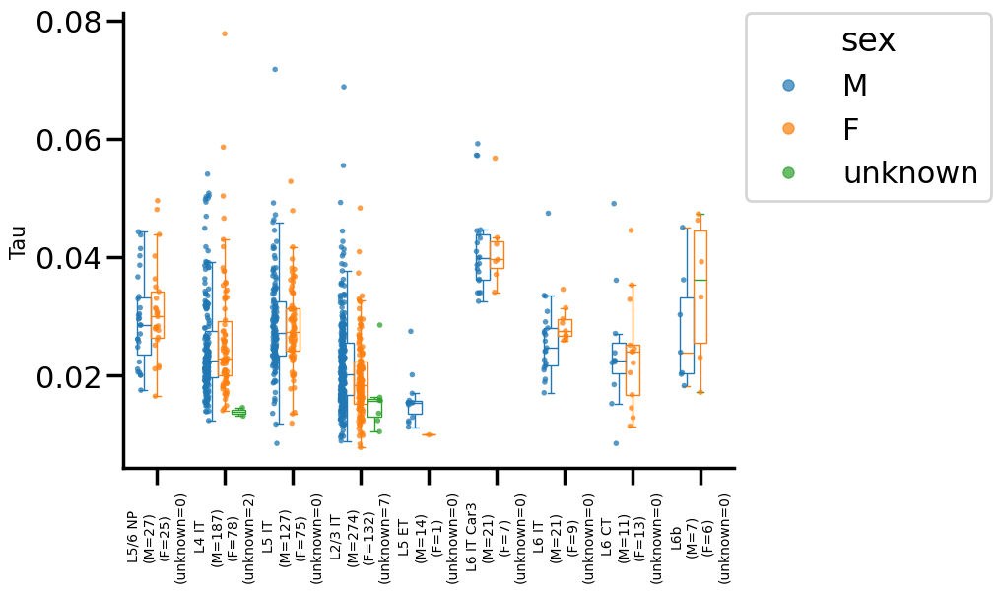

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_M vs. L2/3 IT_F: Custom statistical test, P_val:1.461e-03
L2/3 IT_M vs. L2/3 IT_unknown: Custom statistical test, P_val:1.382e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


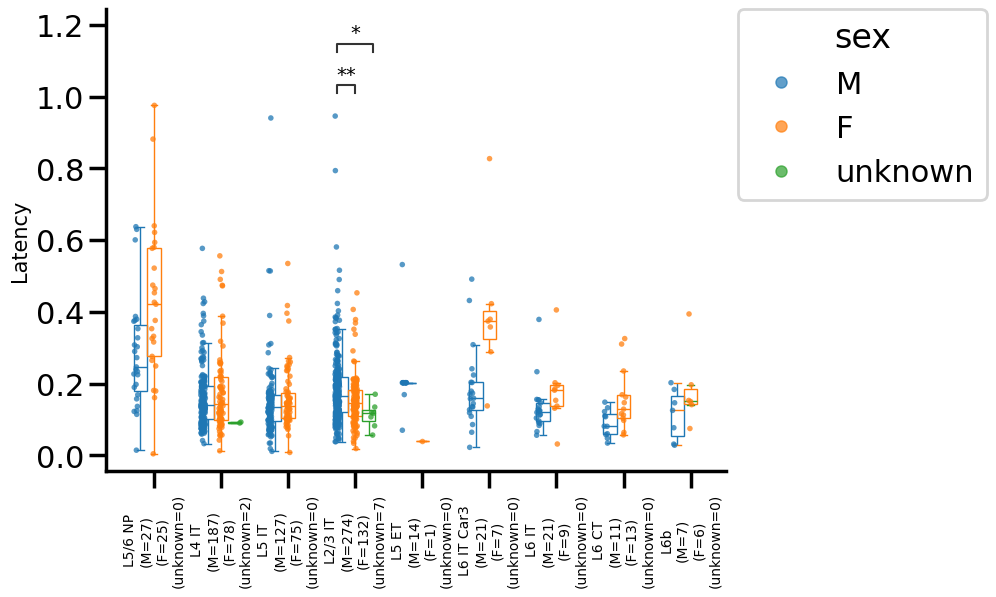

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


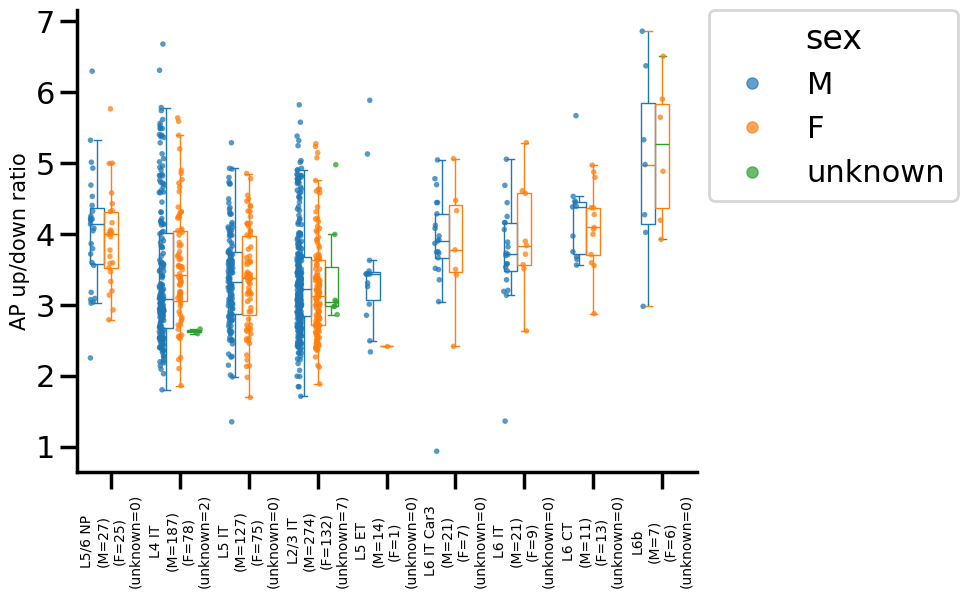

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


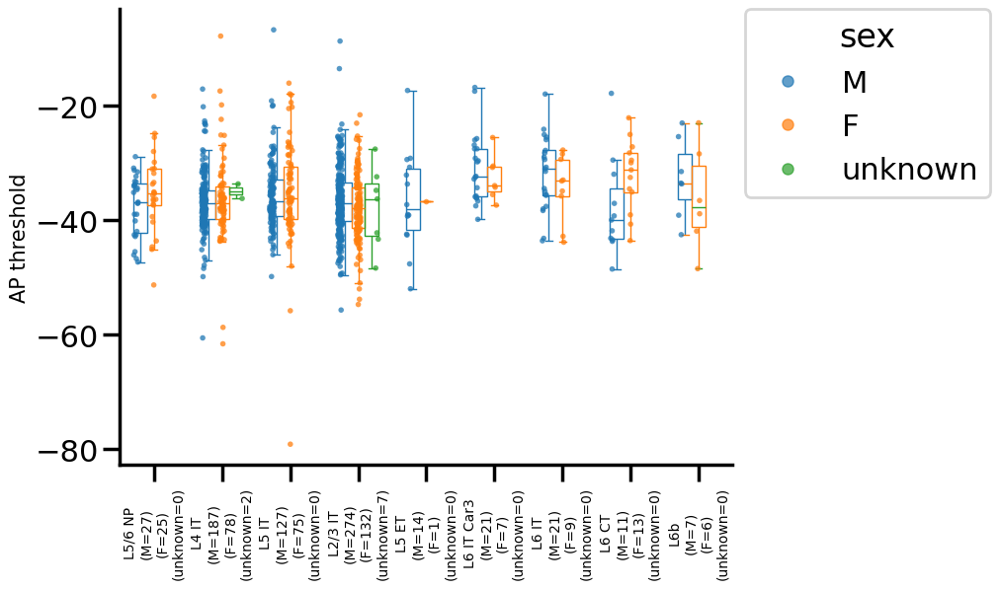

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


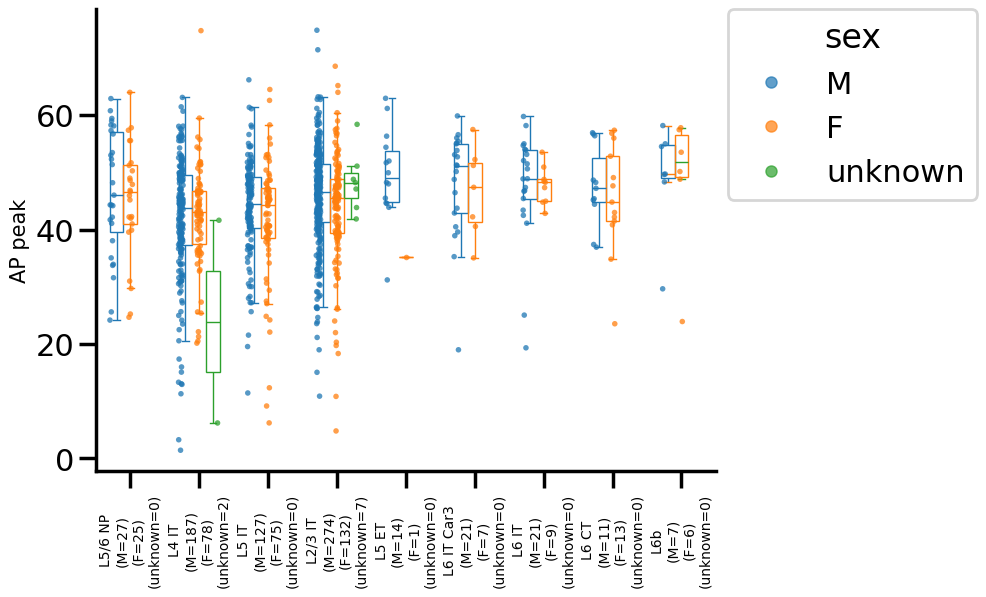

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


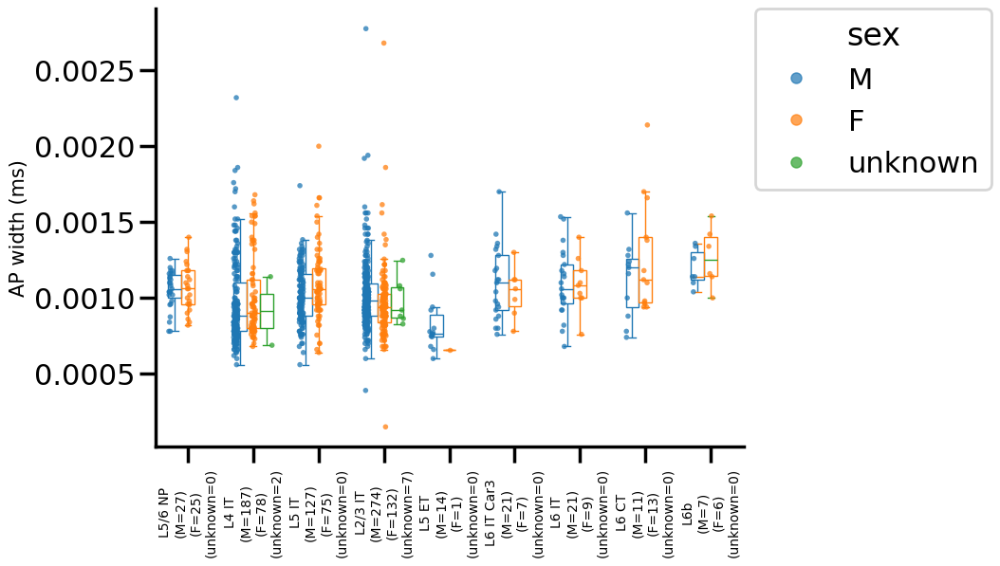

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


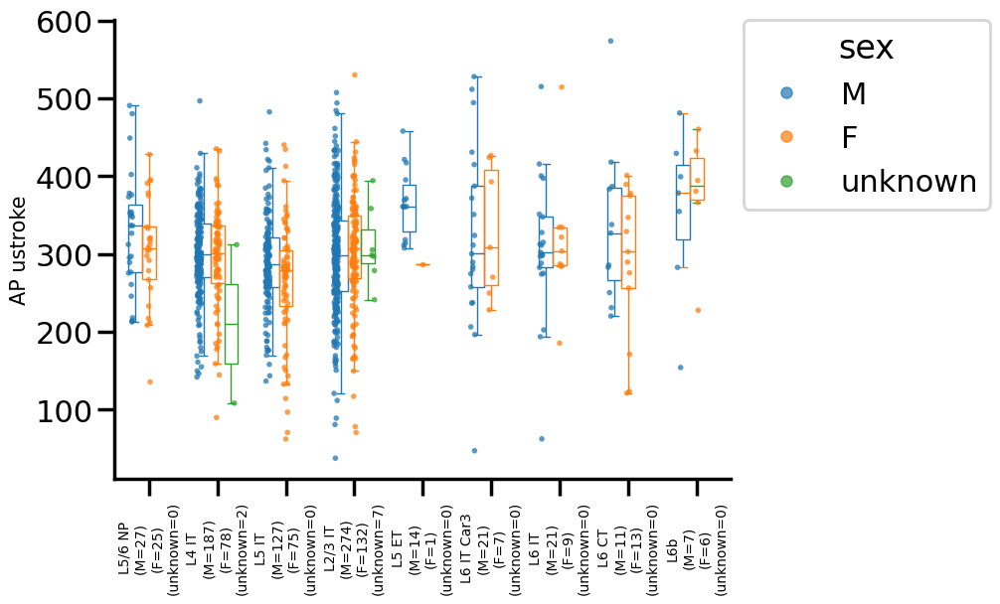

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


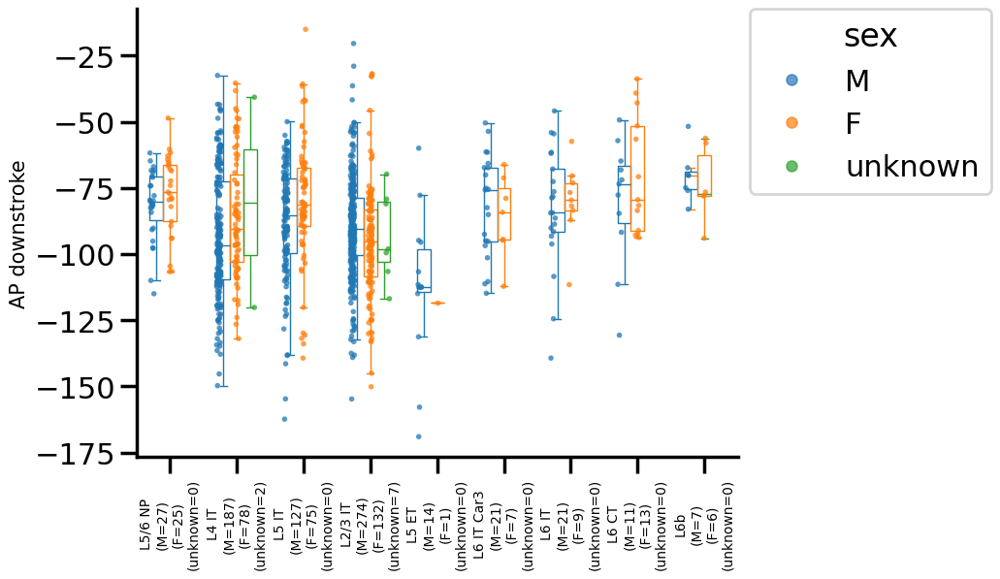

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


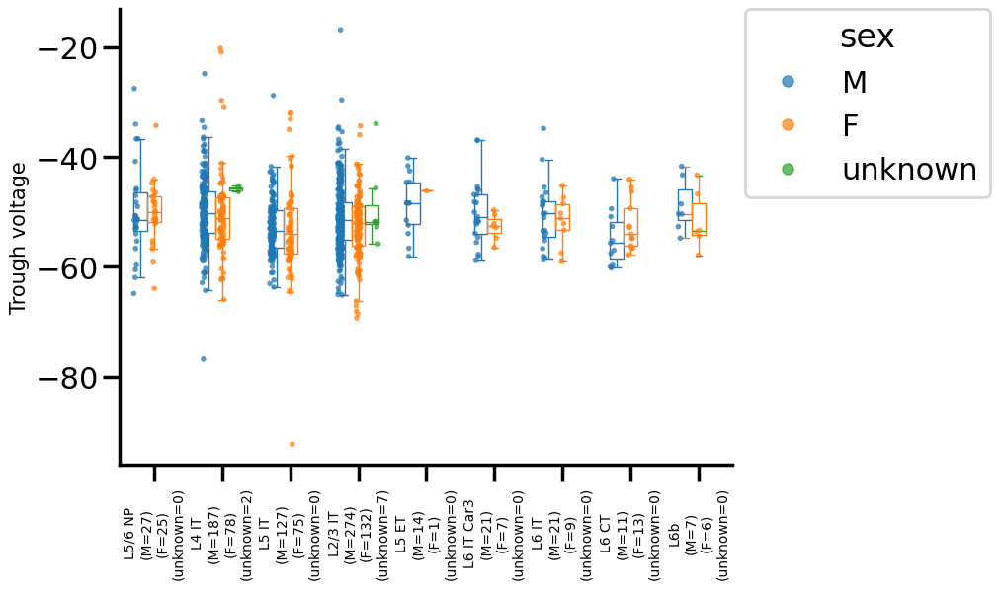

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


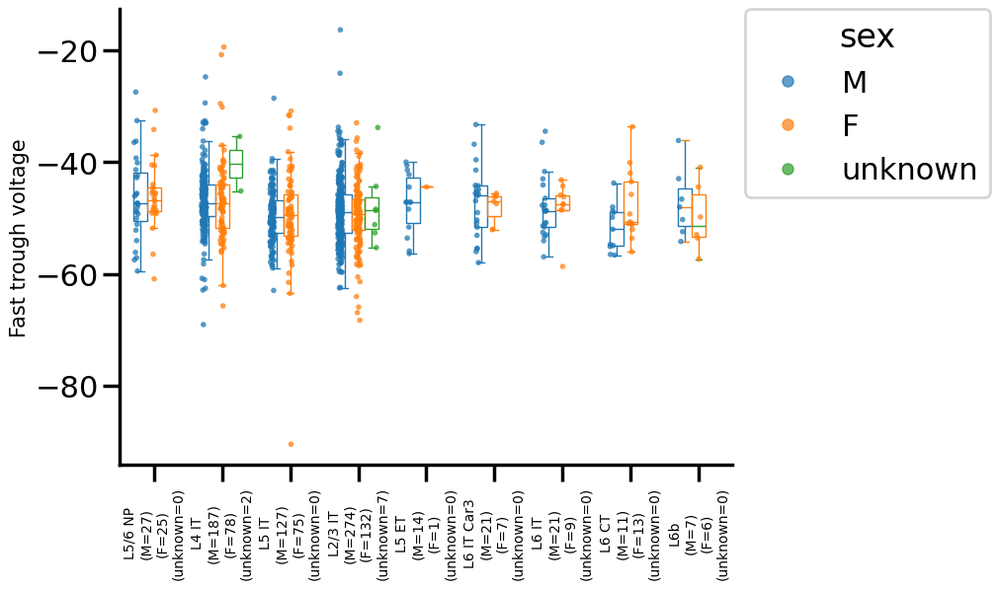

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


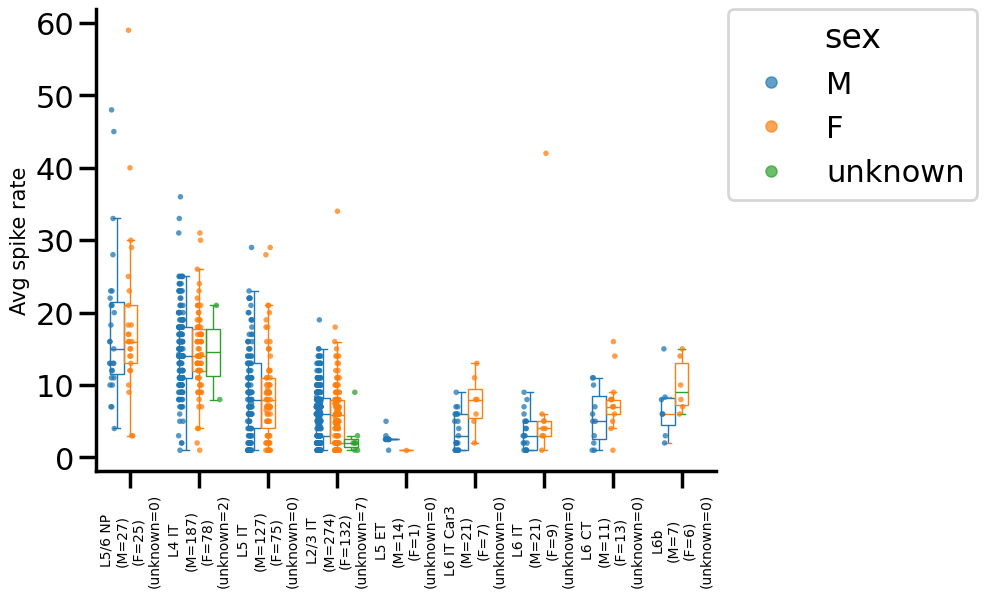

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


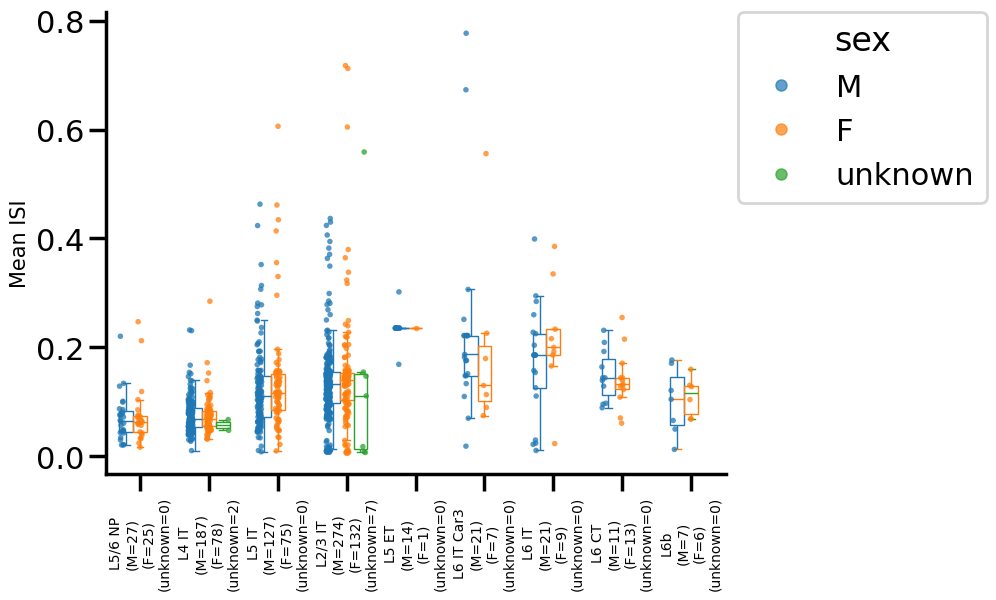

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


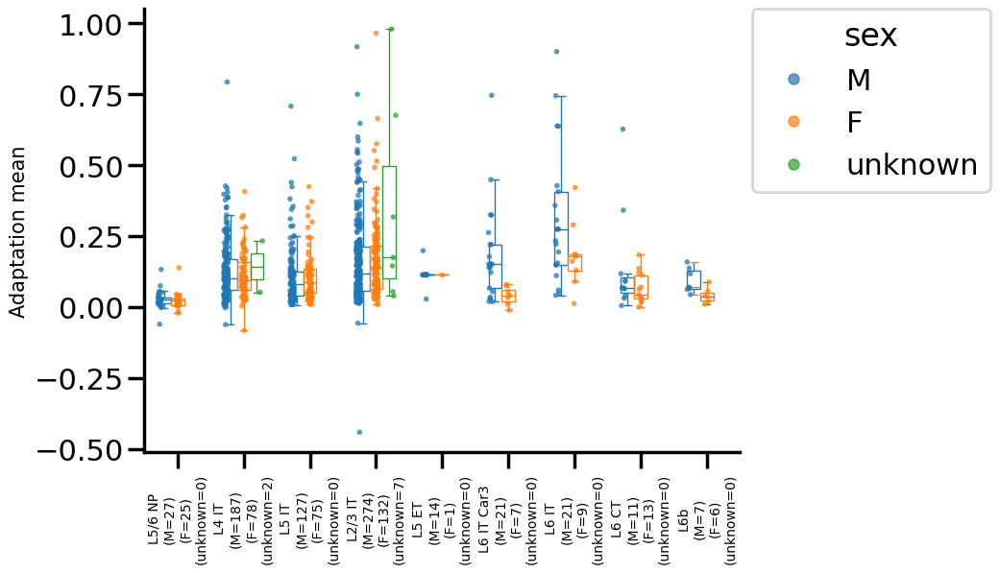

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


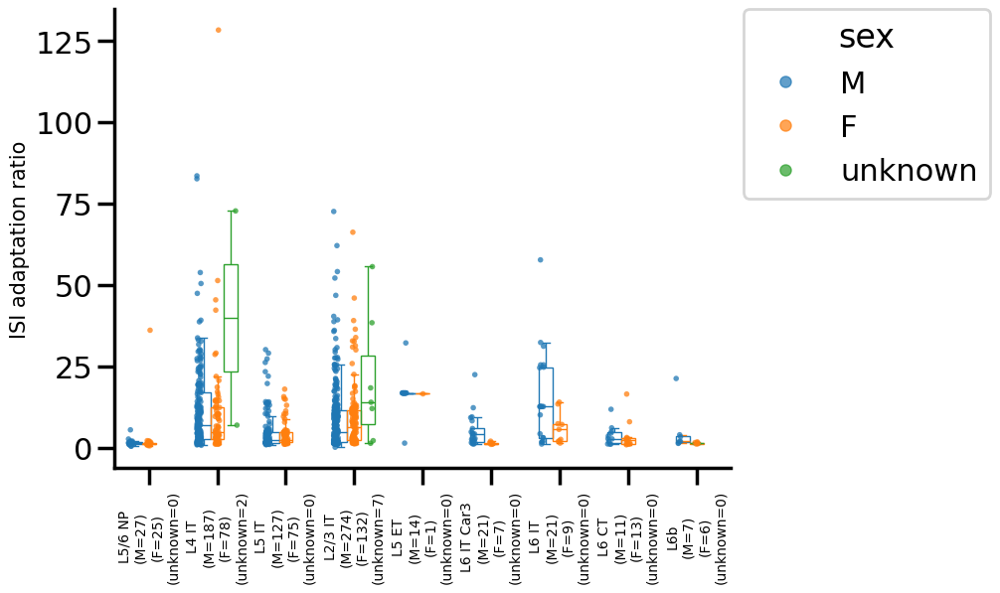

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


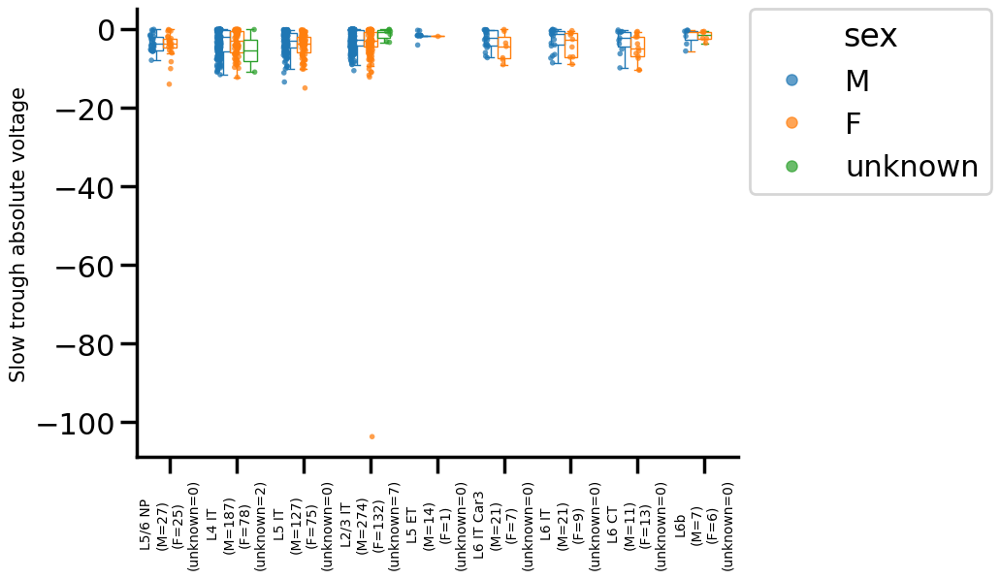

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


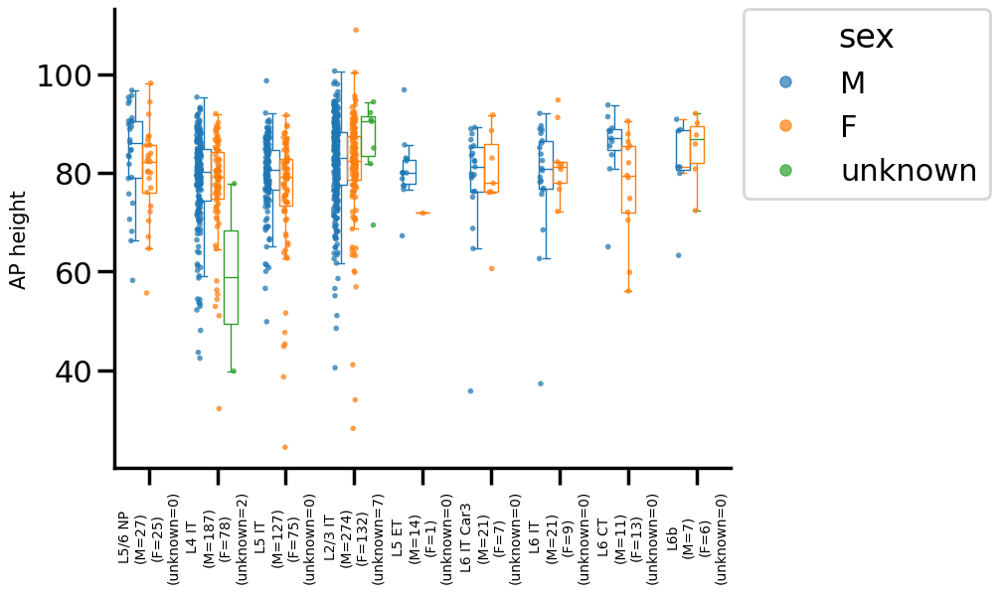

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


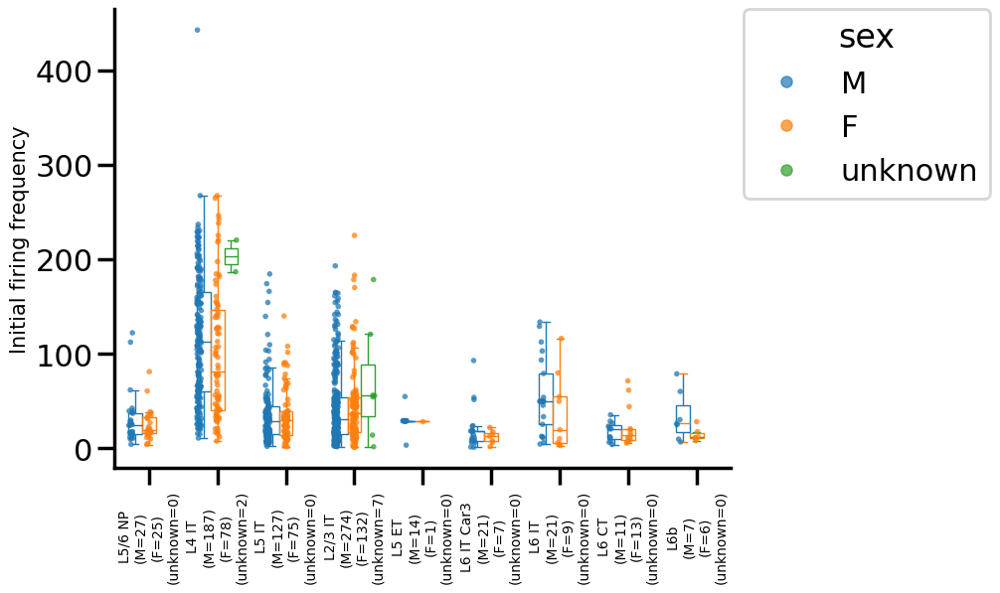

In [43]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'sex'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables)


#### *removing cells with `unknown` sex

1044


/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1094812/2125135880.py:26: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

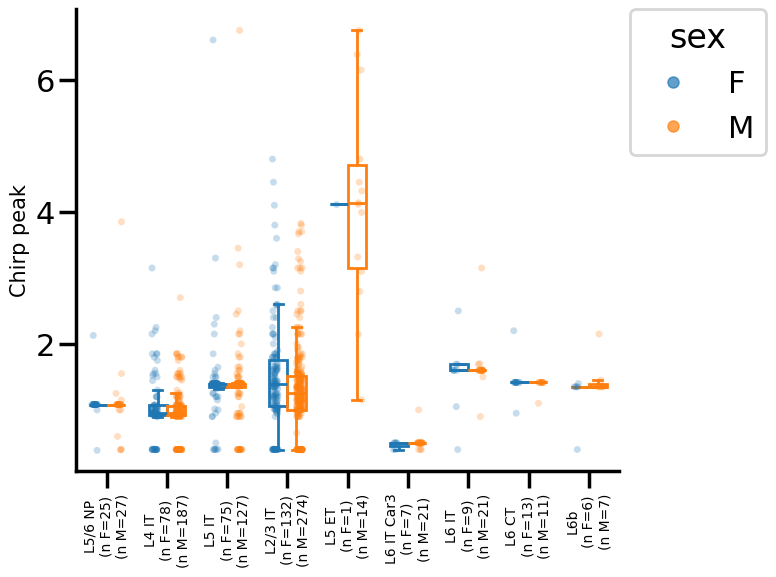

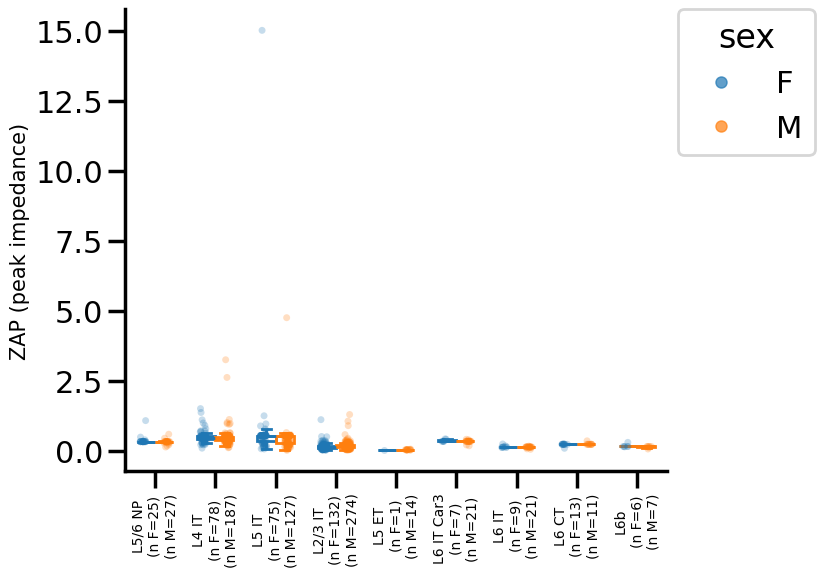

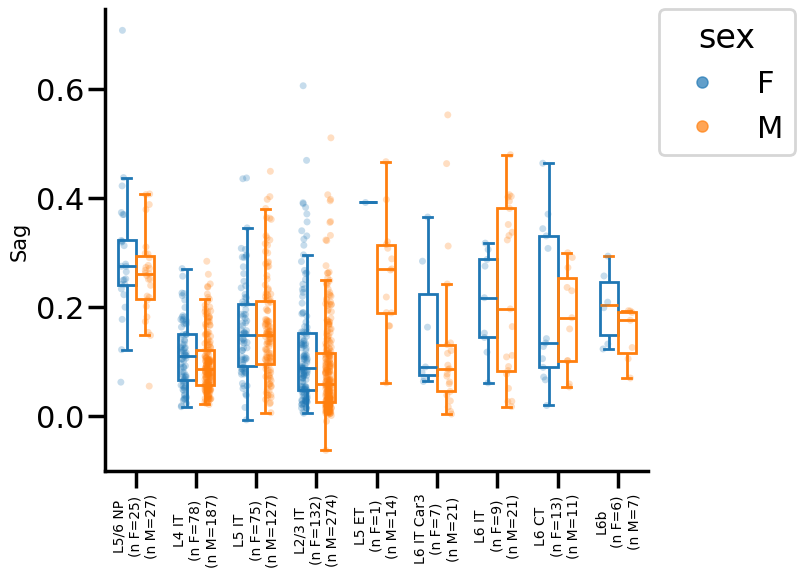

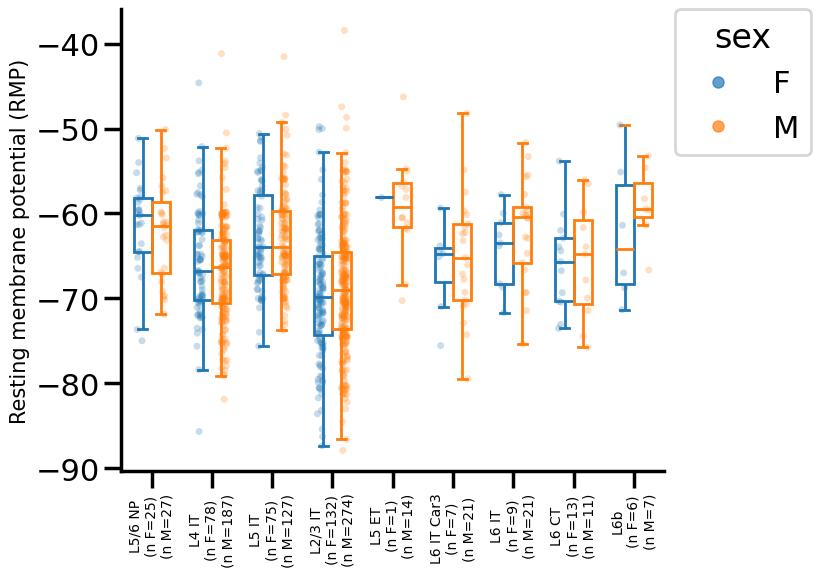

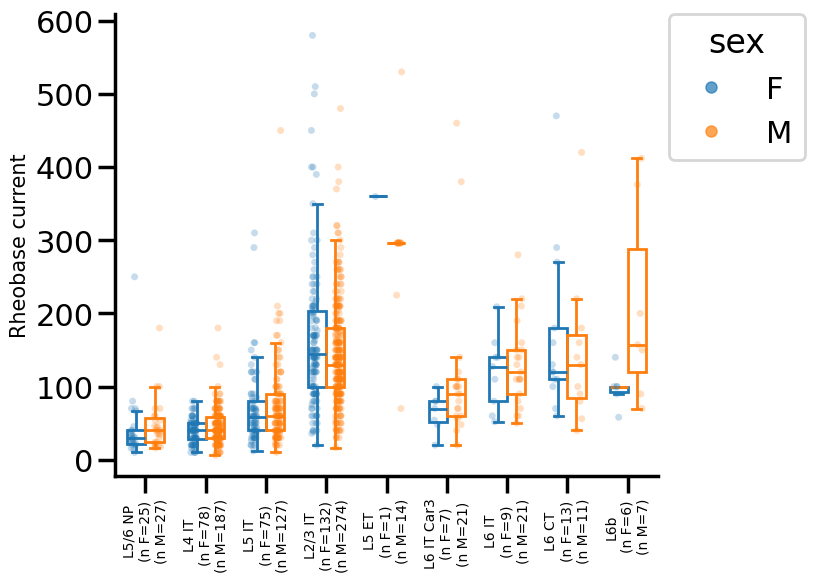

...

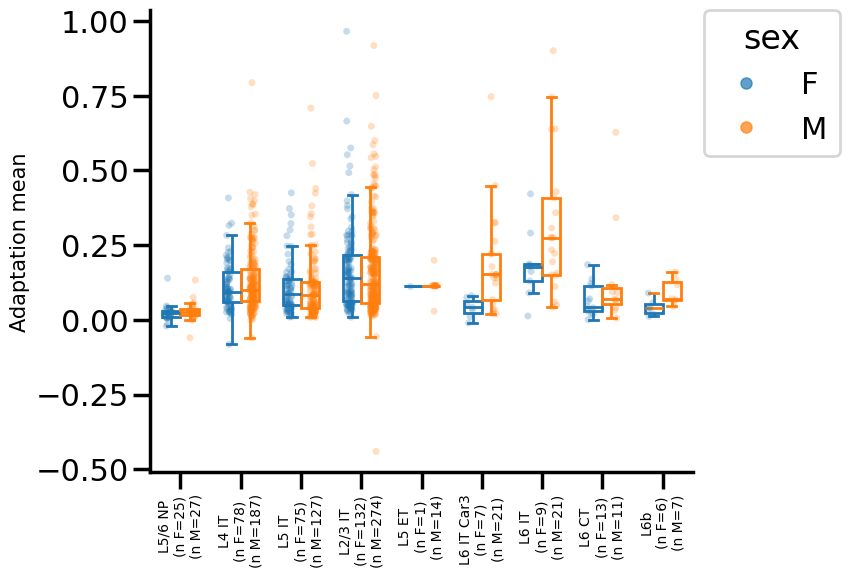

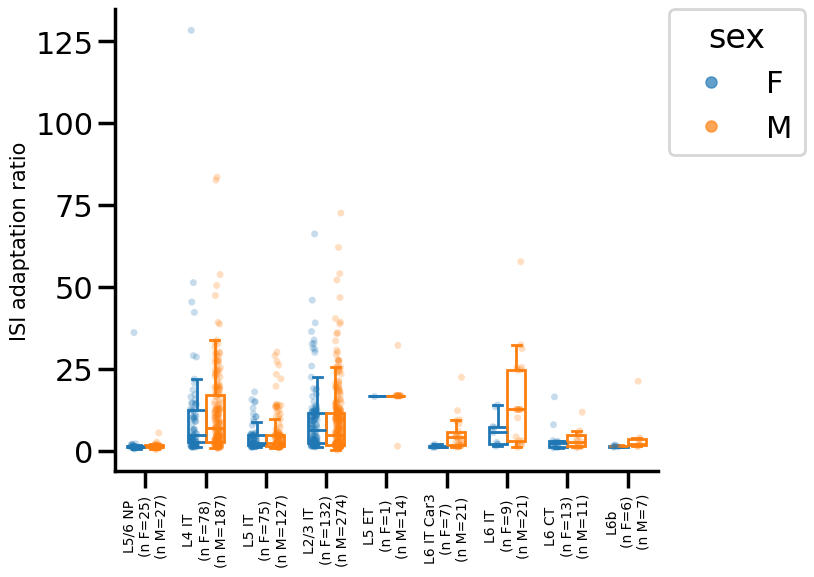

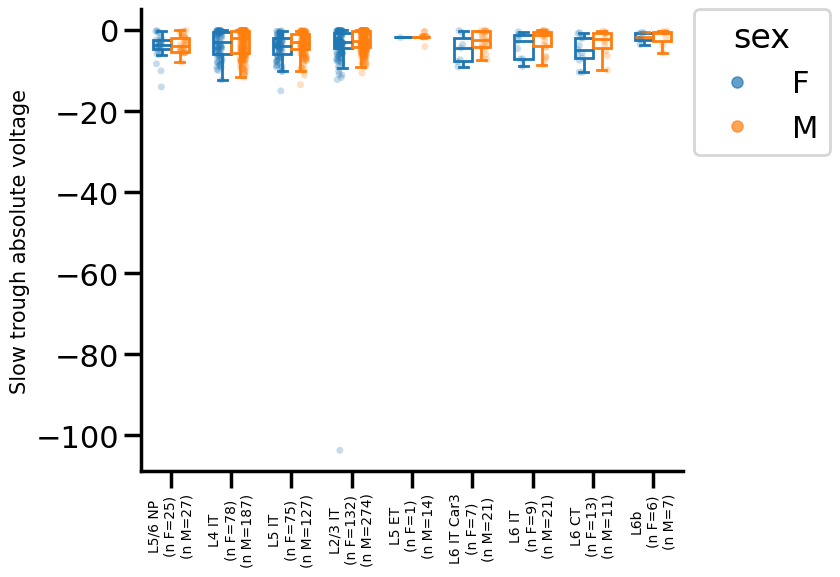

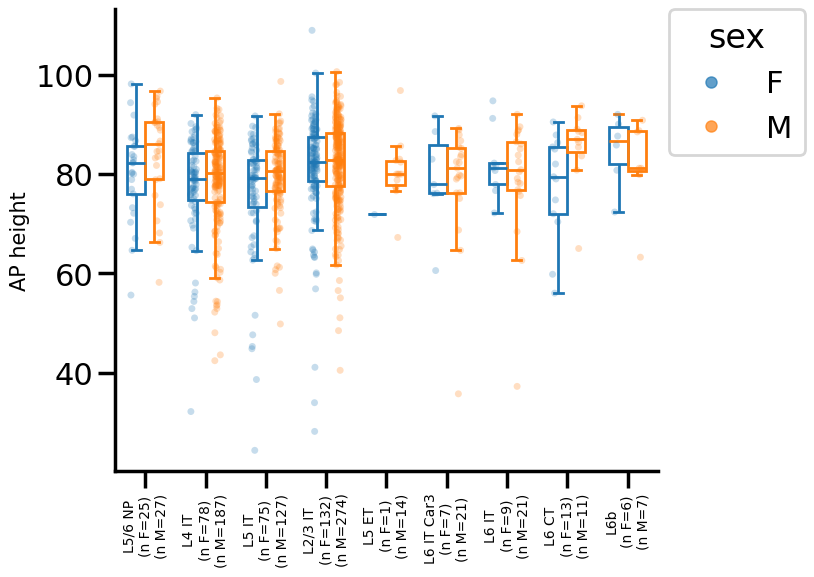

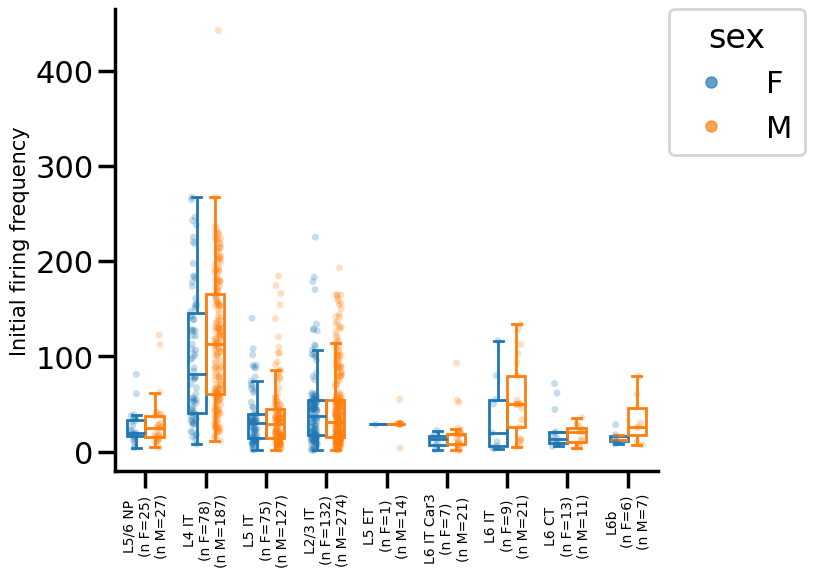

In [44]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'sex'
group1_label = 'F'
group2_label = 'M'
suffix = '_removeUnknown'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order))
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lab box plots - subclass

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:5.599e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:7.782e-04
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.410e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


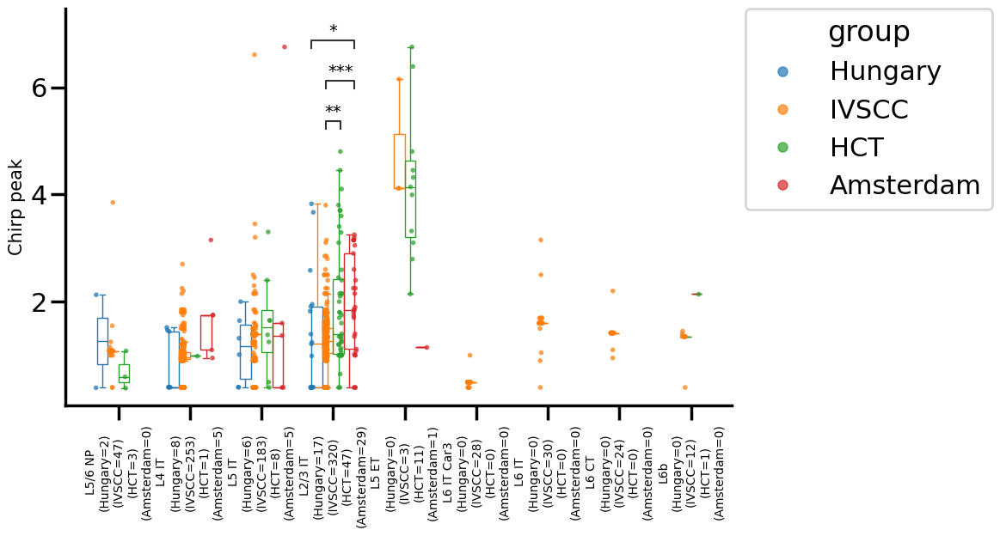

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:7.026e-07
L4 IT_Hungary vs. L4 IT_IVSCC: Custom statistical test, P_val:7.163e-03
L5 IT_IVSCC vs. L5 IT_HCT: Custom statistical test, P_val:1.878e-03
L5 IT_IVSCC vs. L5 IT_Amsterdam: Custom statistical test, P_val:4.375e-03
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:1.194e-07
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.049e-02
L5 IT_Hungary vs. L5 IT_HCT: Custom statistical test, P_val:1.667e-03
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.123e-07
L5 IT_Hungary vs. L5 IT_Amsterdam: Custom statistical test, P_val:1.667e-03
L4 IT_Hungary vs. L4 IT_Amsterdam: Custom statistical test, P_val:1.957e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


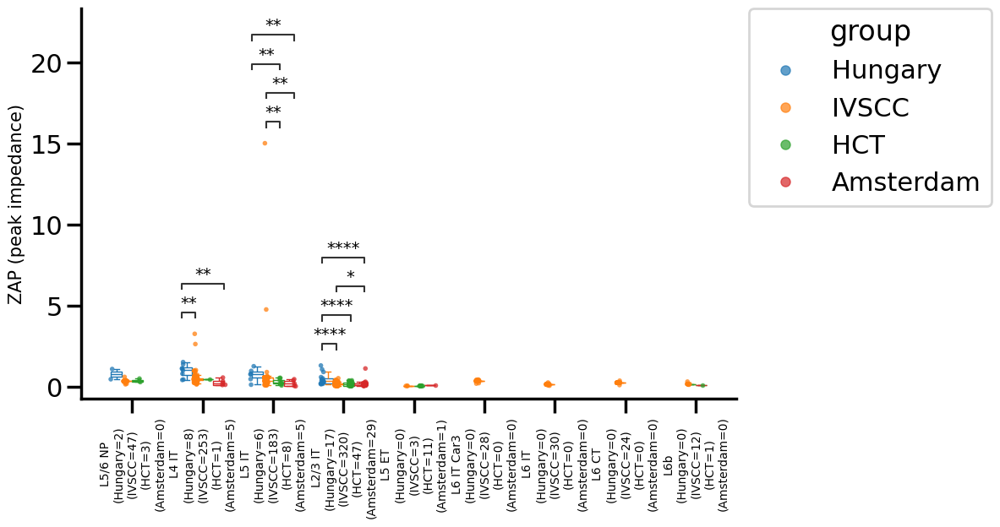

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:1.370e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.647e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


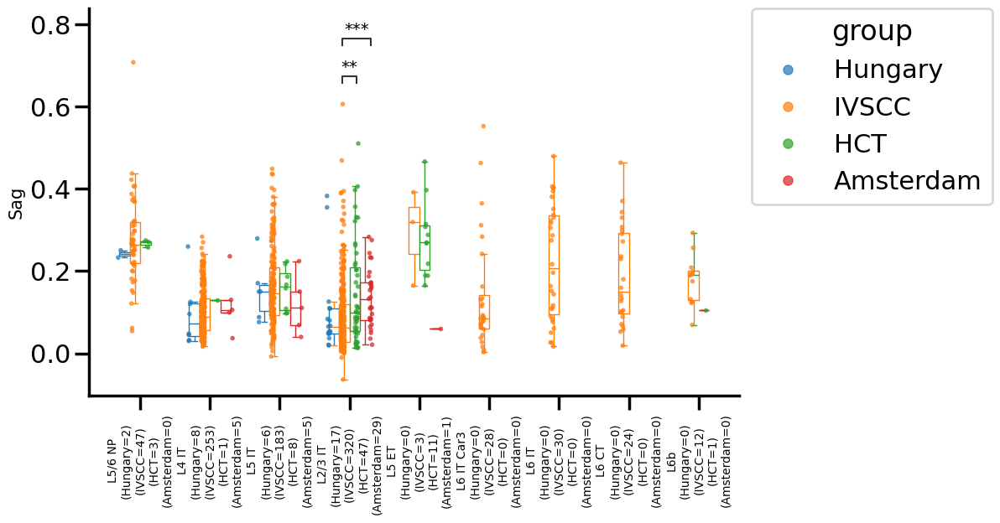

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:5.279e-03
L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:5.022e-10


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


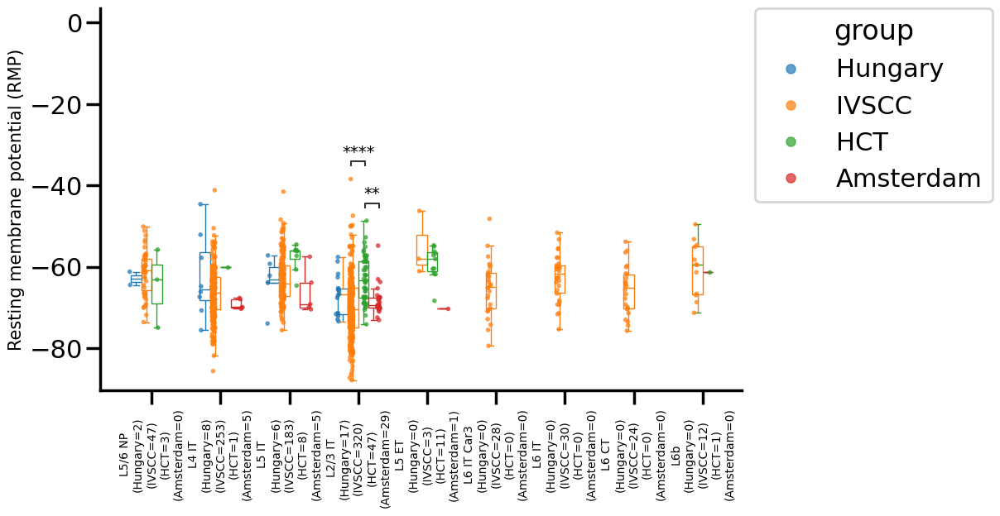

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


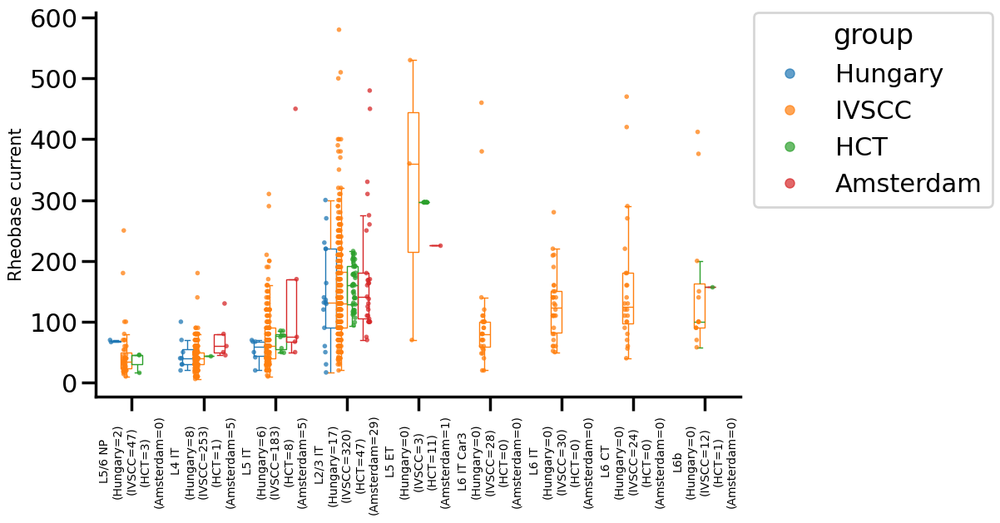

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


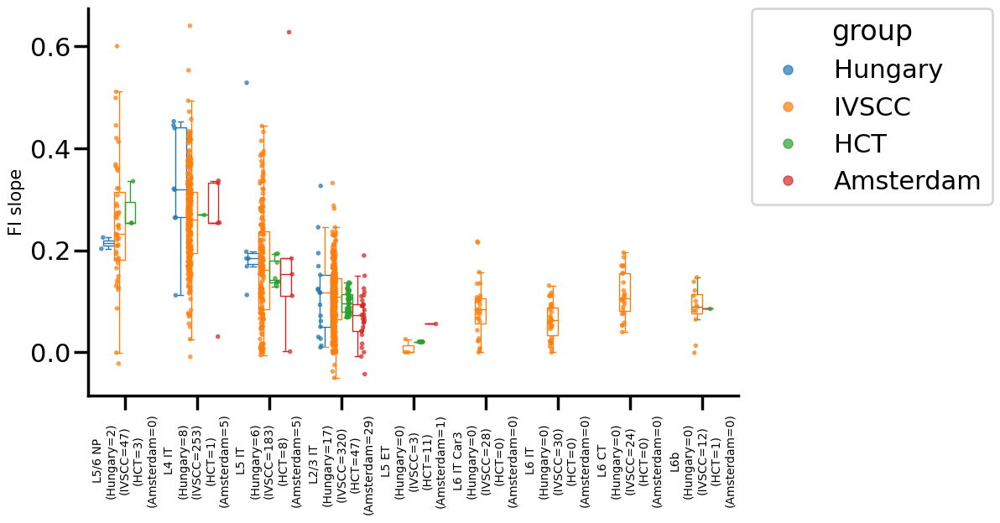

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


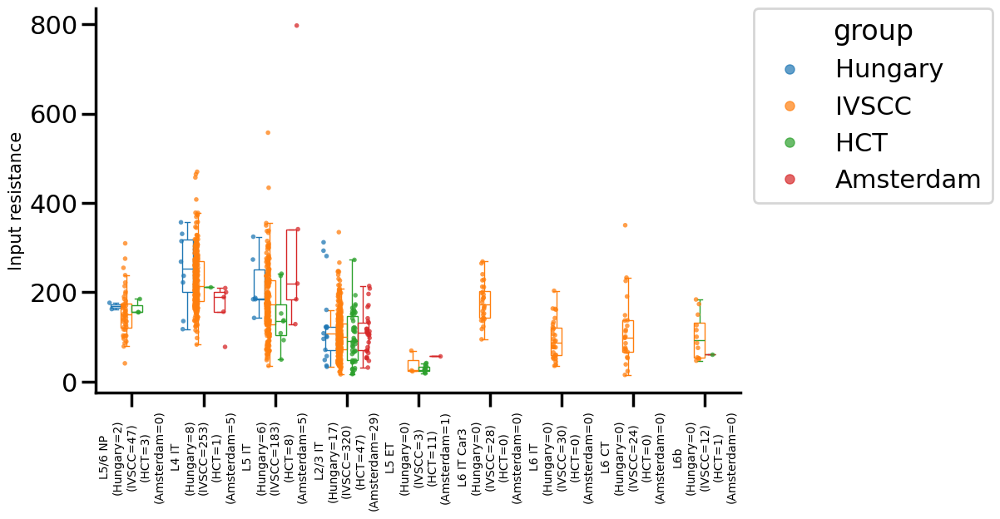

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


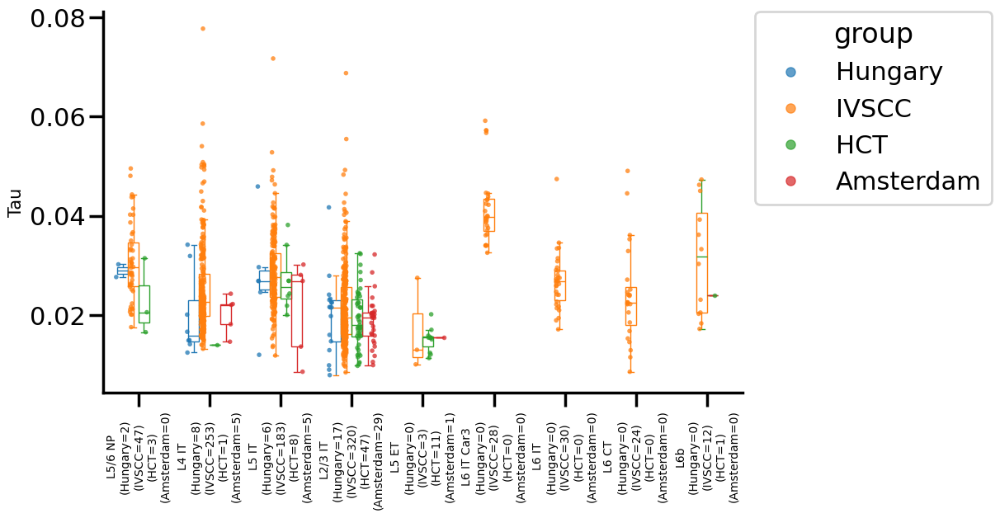

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.394e-06
L5 ET_IVSCC vs. L5 ET_HCT: Custom statistical test, P_val:3.062e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.809e-05
L5 ET_IVSCC vs. L5 ET_Amsterdam: Custom statistical test, P_val:3.062e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


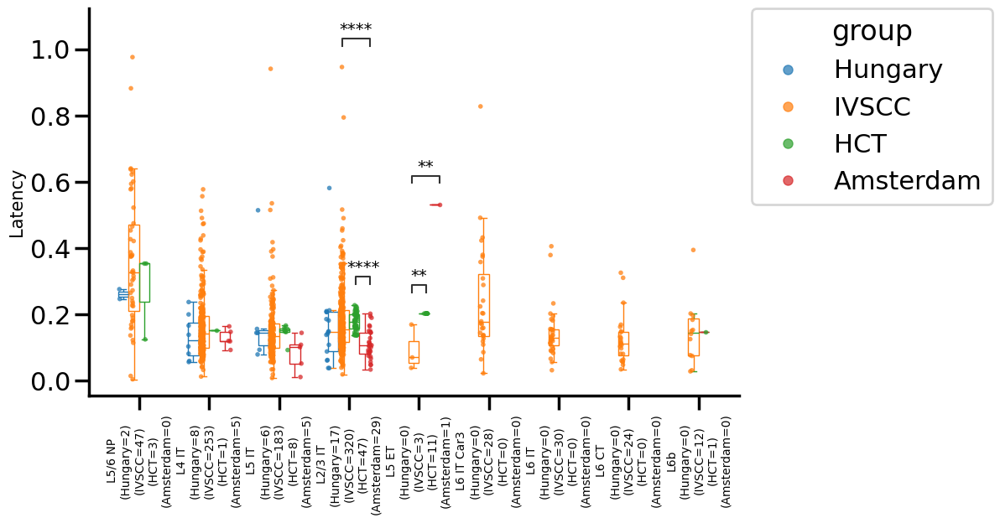

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


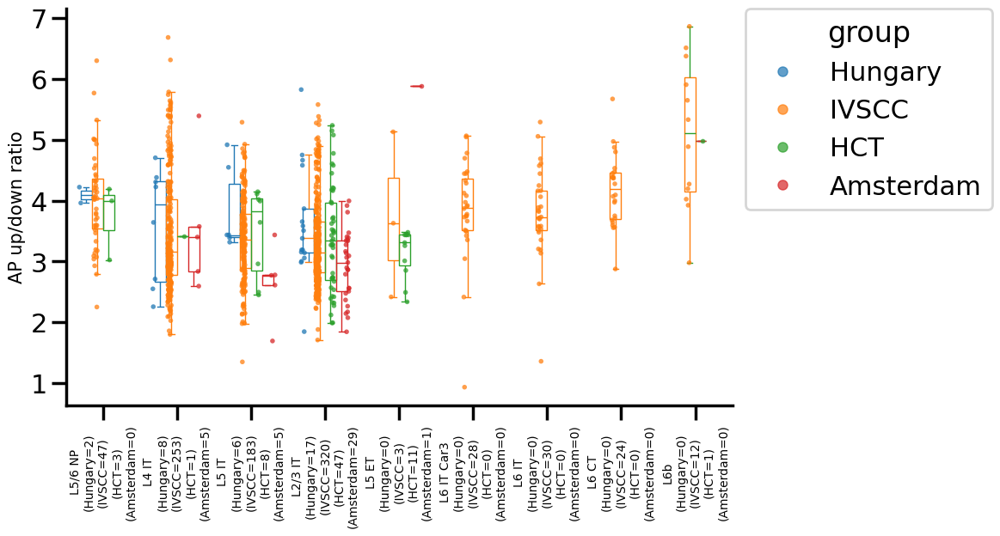

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


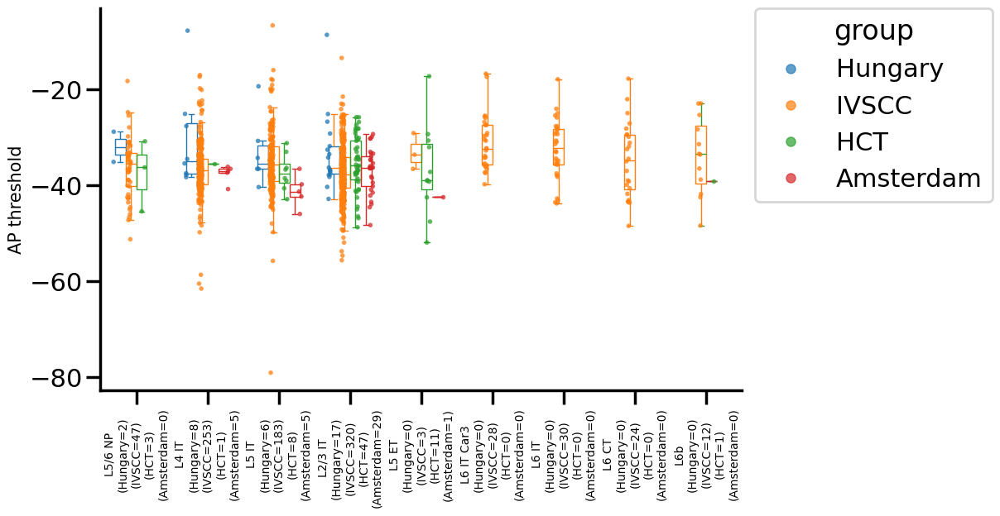

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_HCT vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.606e-02
L2/3 IT_Hungary vs. L2/3 IT_IVSCC: Custom statistical test, P_val:1.195e-02
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:2.318e-02
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.195e-02
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.522e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


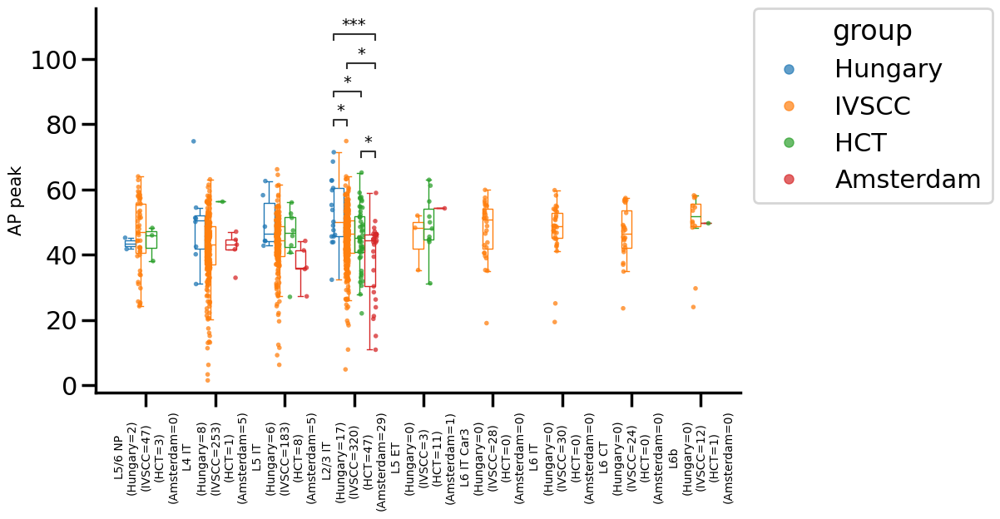

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:3.983e-05
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:4.644e-03
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:3.983e-05
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:2.250e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


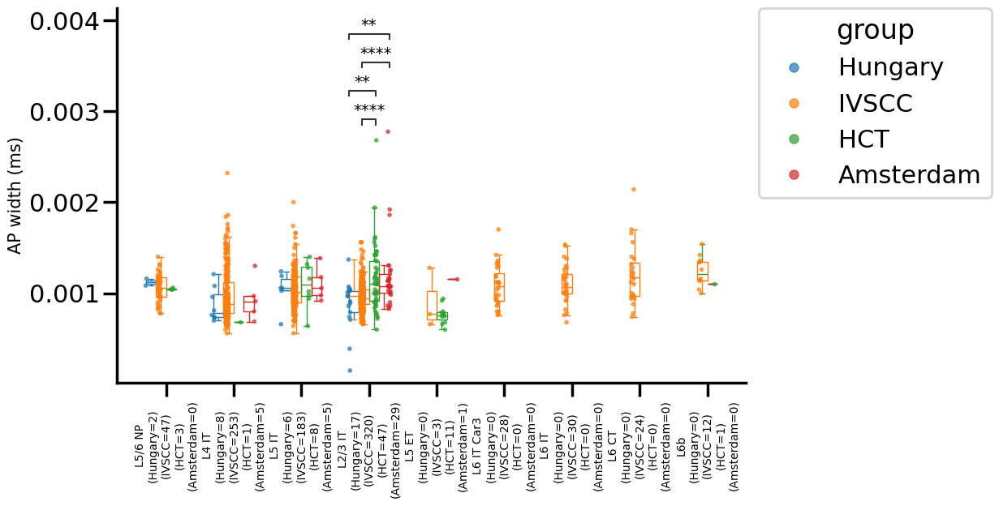

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:3.946e-04
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:5.708e-04
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:7.846e-05
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:9.724e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


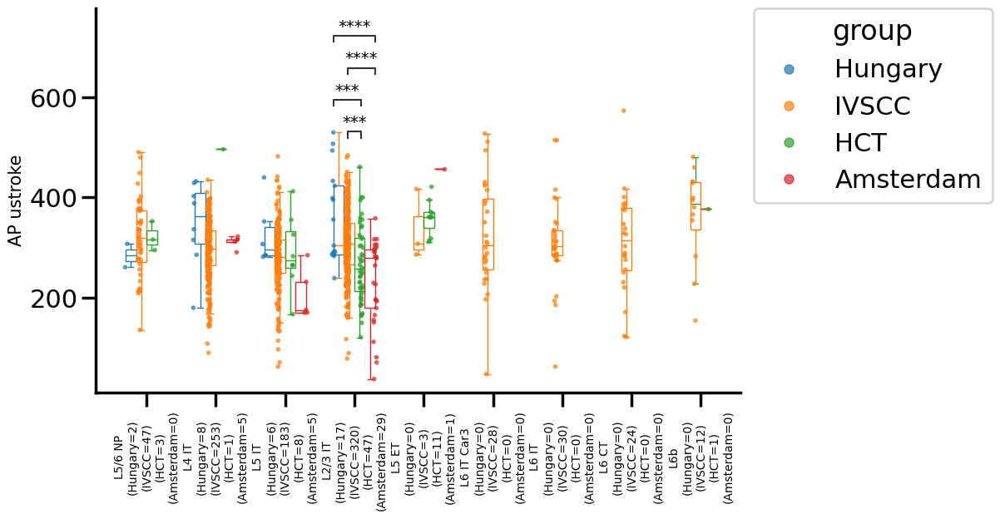

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:4.679e-04
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:2.038e-02
L2/3 IT_IVSCC vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:4.917e-04
L2/3 IT_Hungary vs. L2/3 IT_Amsterdam: Custom statistical test, P_val:1.566e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


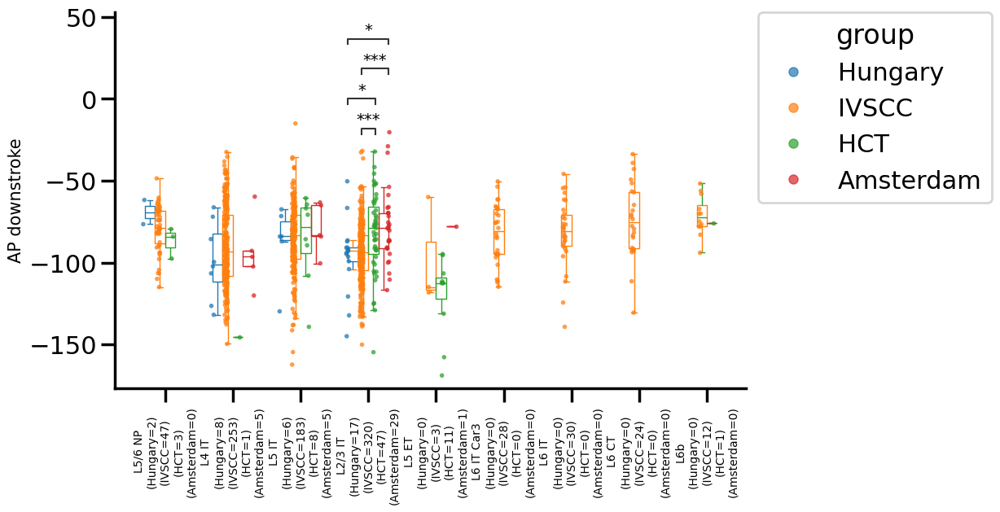

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:3.302e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


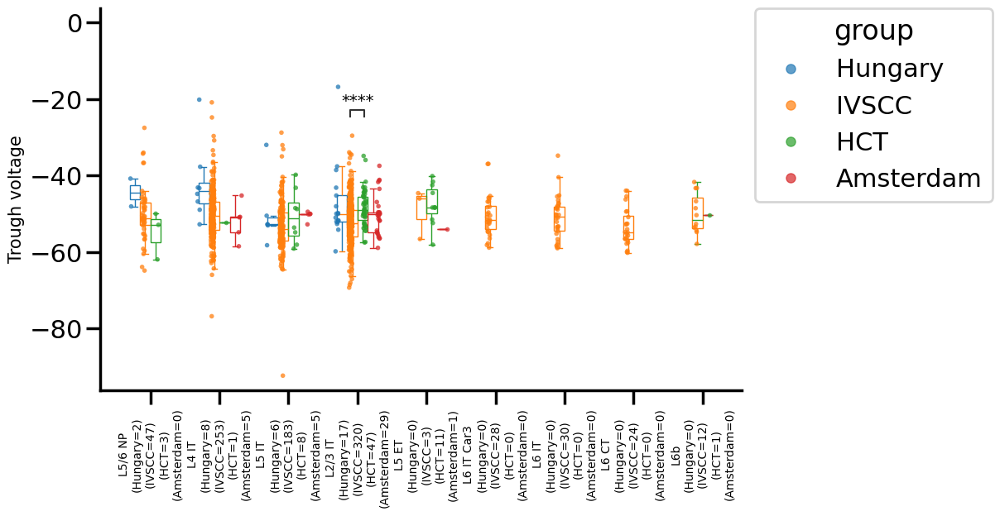

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:1.773e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


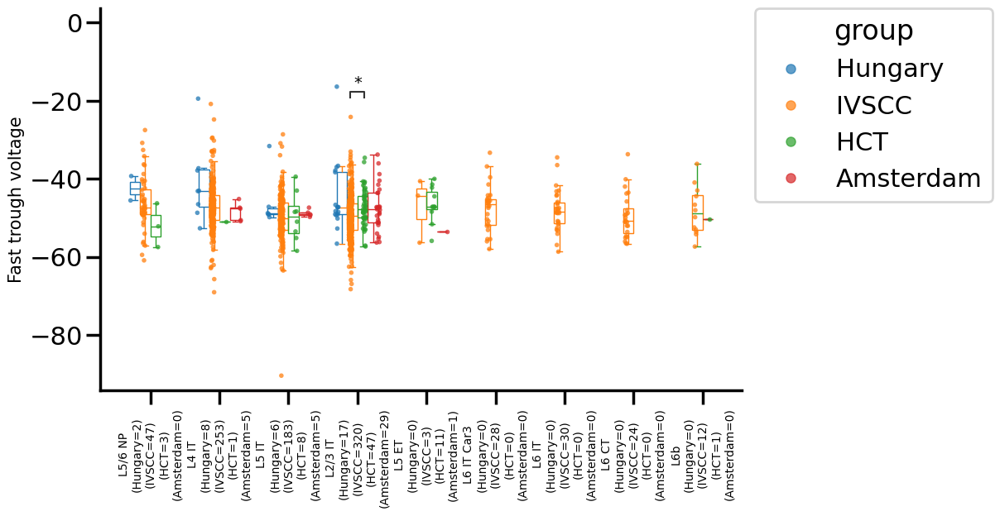

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


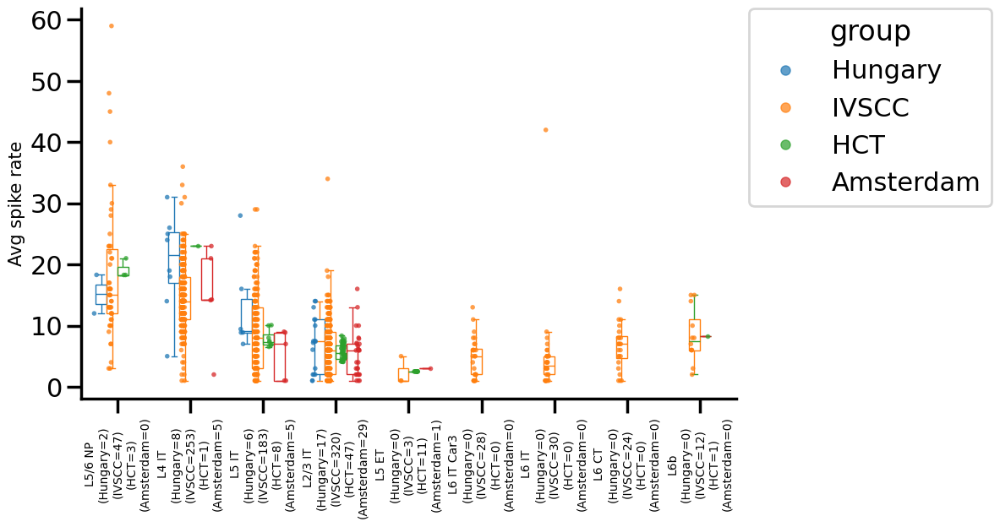

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:2.676e-02
L2/3 IT_Hungary vs. L2/3 IT_HCT: Custom statistical test, P_val:5.593e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


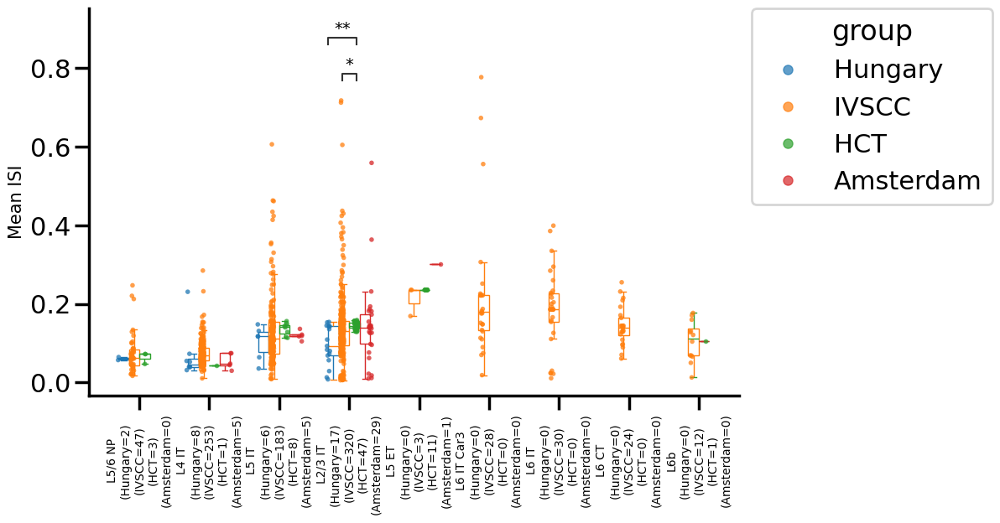

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


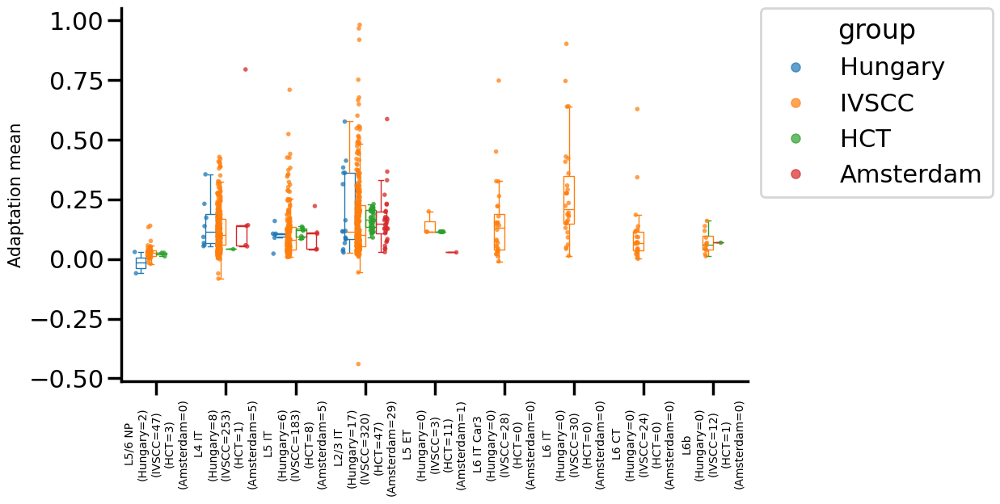

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:7.898e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


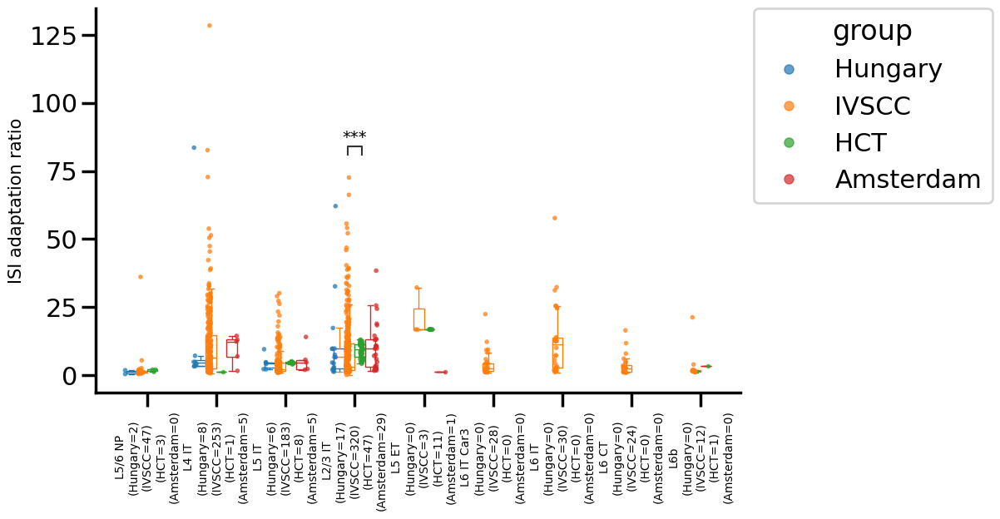

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


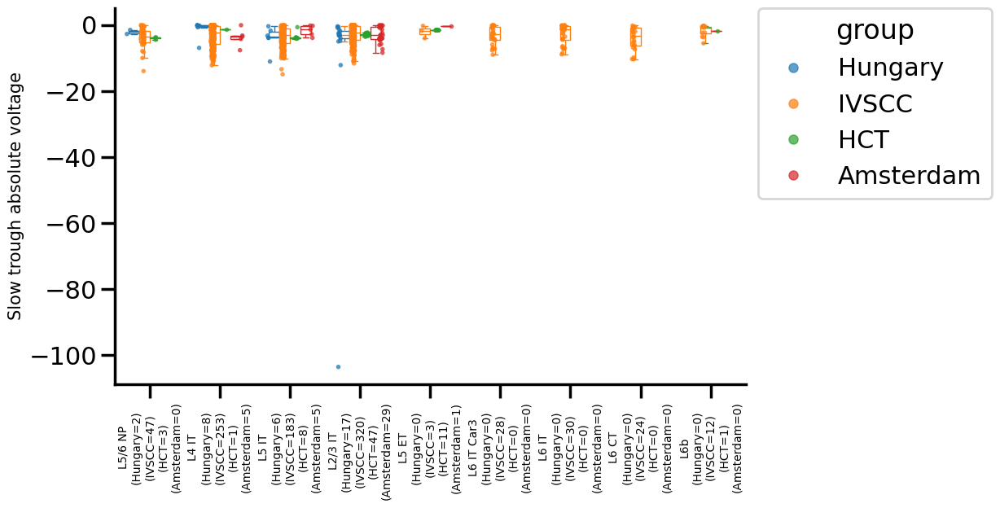

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


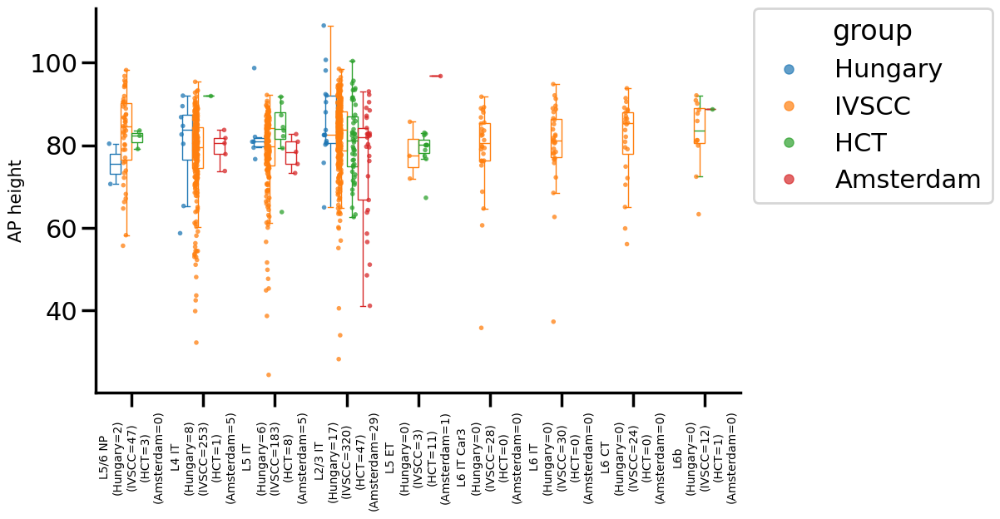

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_IVSCC vs. L2/3 IT_HCT: Custom statistical test, P_val:7.808e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


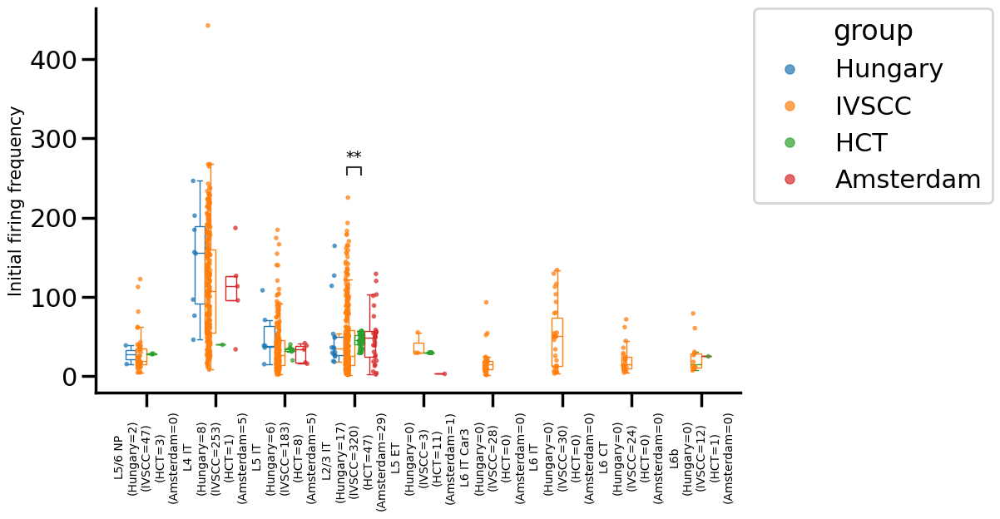

In [45]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'group'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables, figsize=(10,6))


Cross paradigm box plots - stats [duplicate analysis from above, to match this formatting]

1044


/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLoca

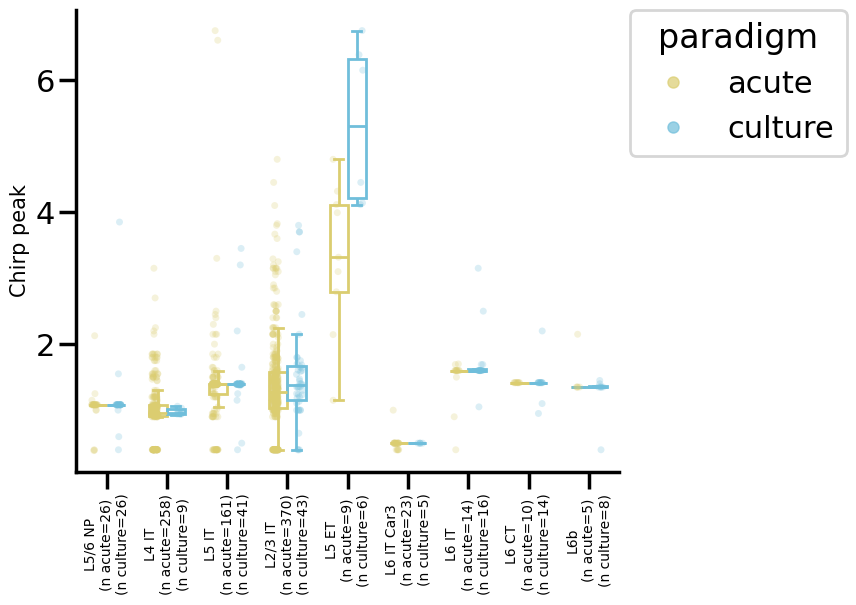

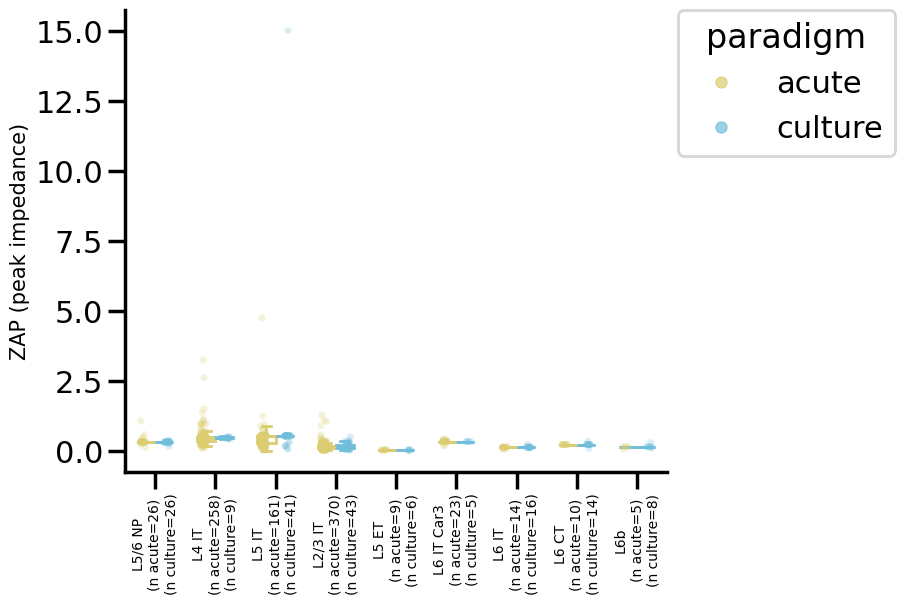

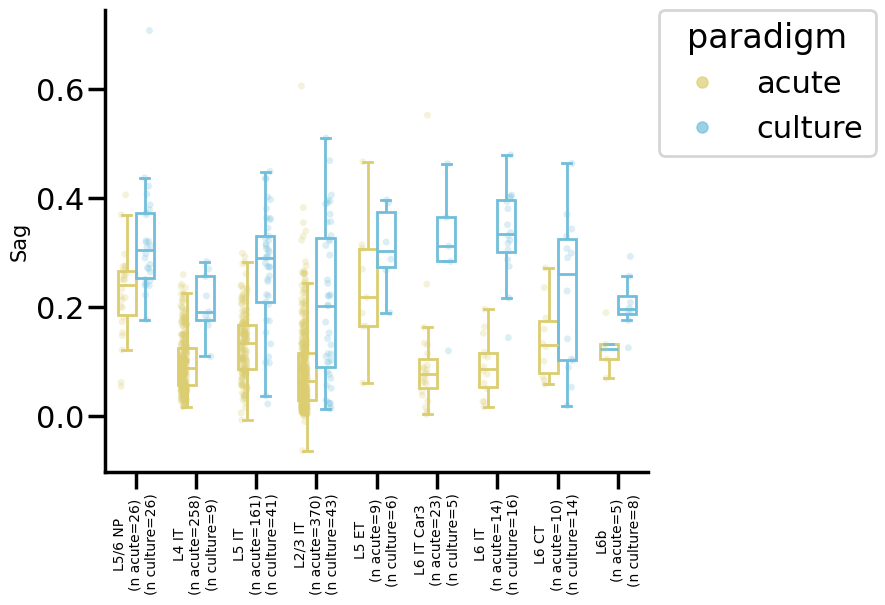

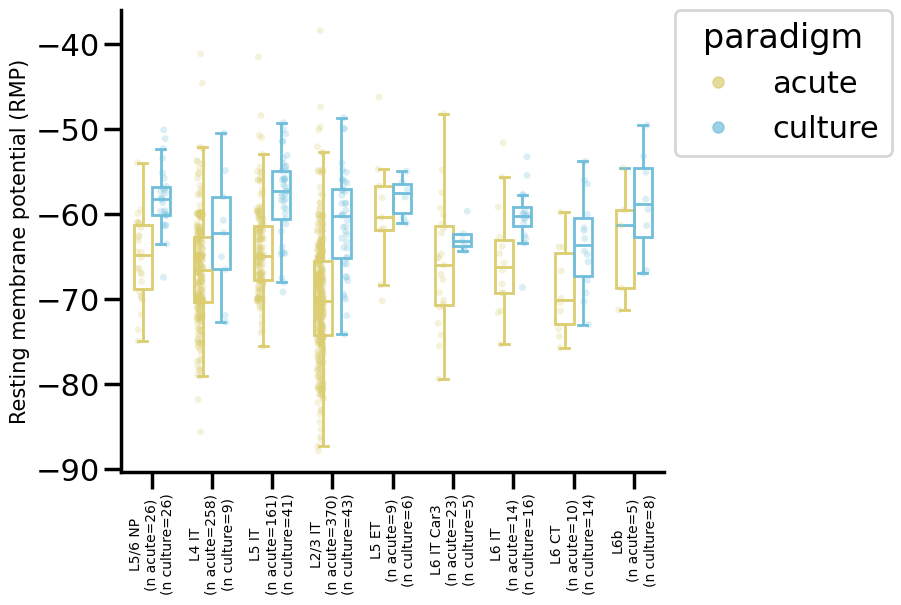

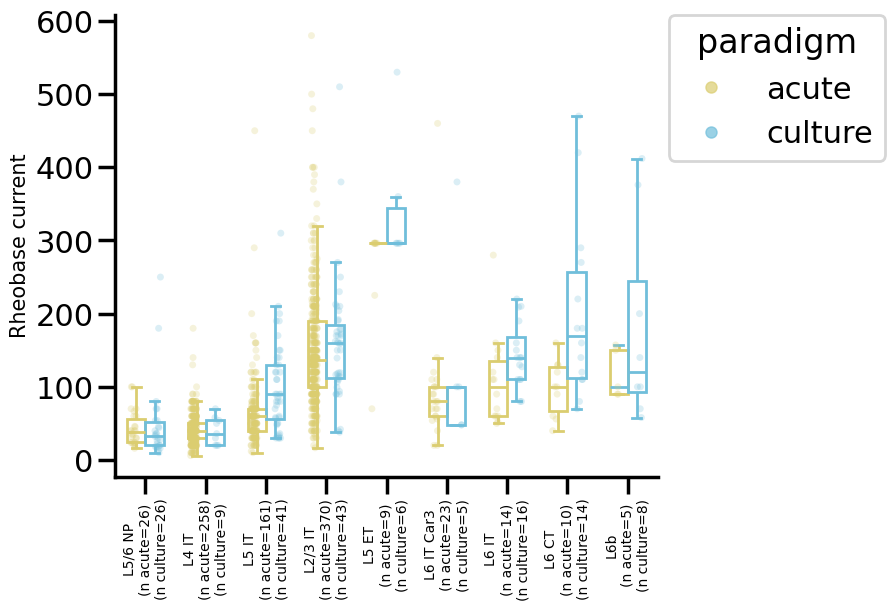

...

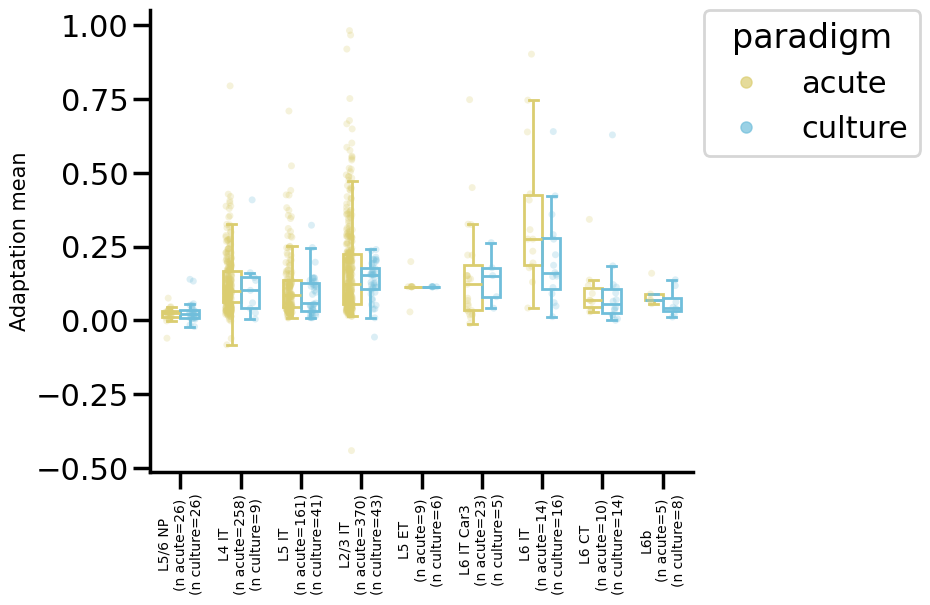

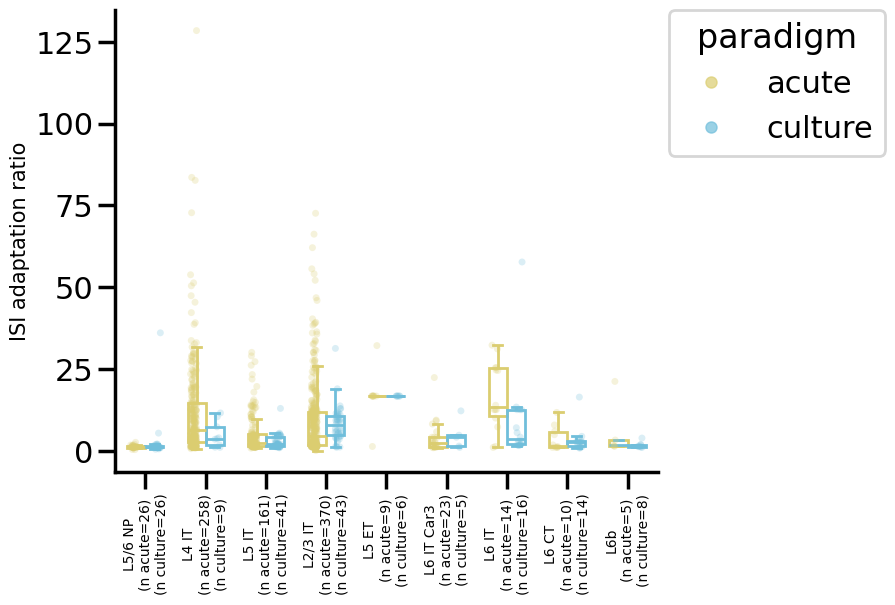

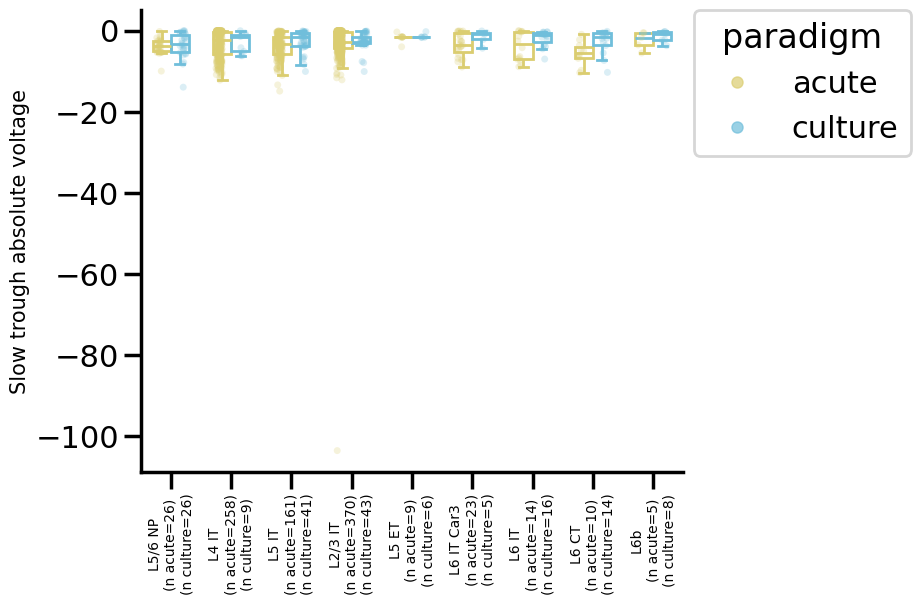

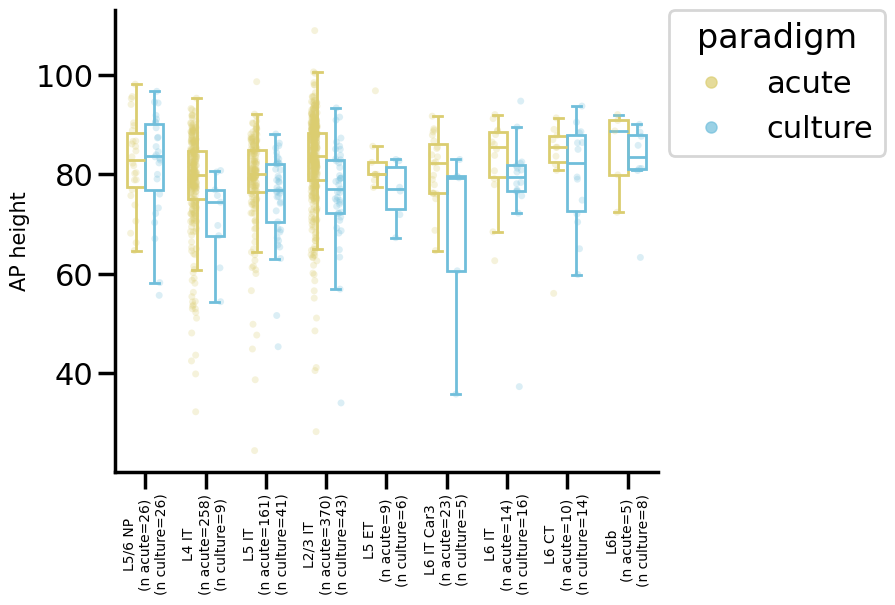

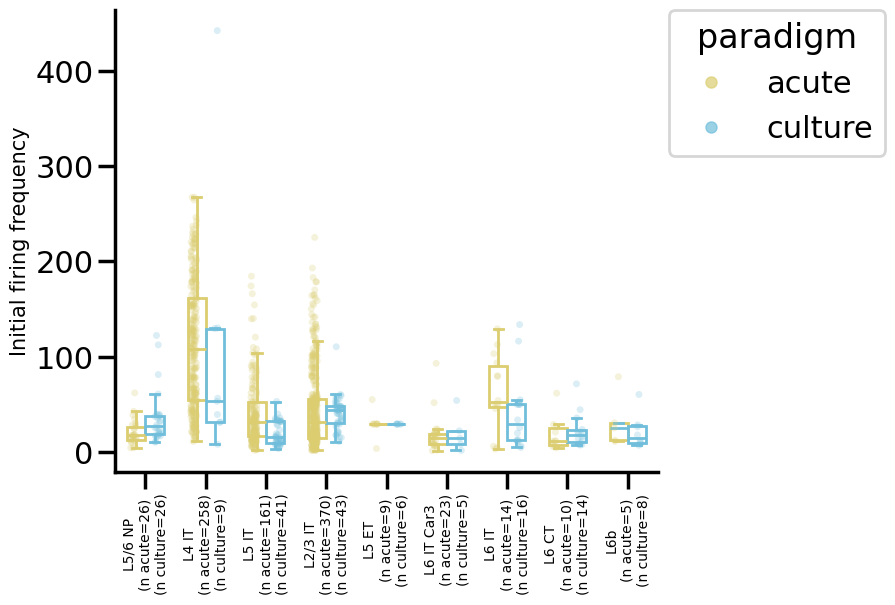

In [46]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'paradigm'
group1_label = 'acute'
group2_label = 'culture'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)


Cross lobe box plots - subclass [duplicate analysis from above, to match this formatting]

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_ParL vs. L2/3 IT_CeG: Custom statistical test, P_val:2.208e-02
L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:3.208e-03
L2/3 IT_FroL vs. L2/3 IT_CeG: Custom statistical test, P_val:2.208e-02
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:8.149e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


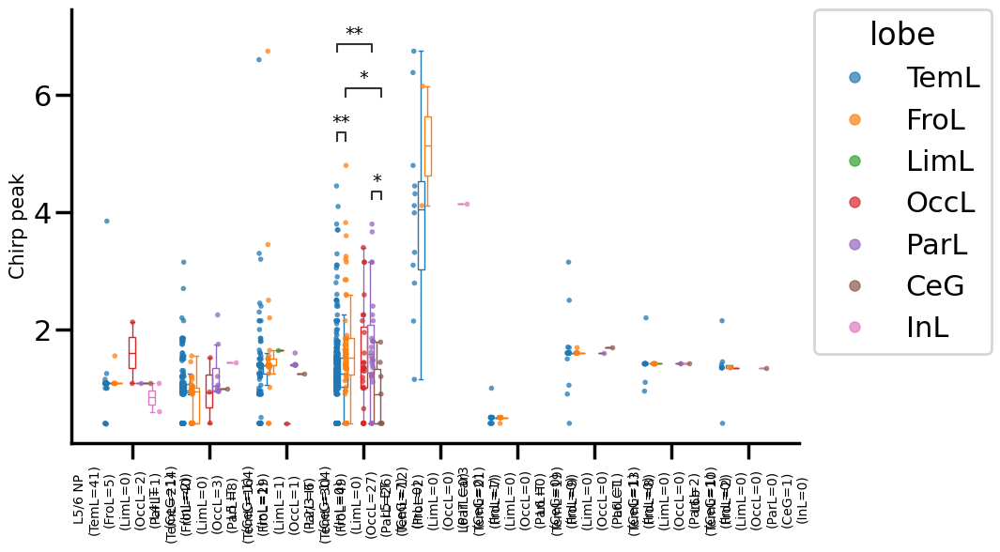

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:2.909e-03
L2/3 IT_OccL vs. L2/3 IT_ParL: Custom statistical test, P_val:2.212e-03
L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:1.864e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.951e-04
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.951e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


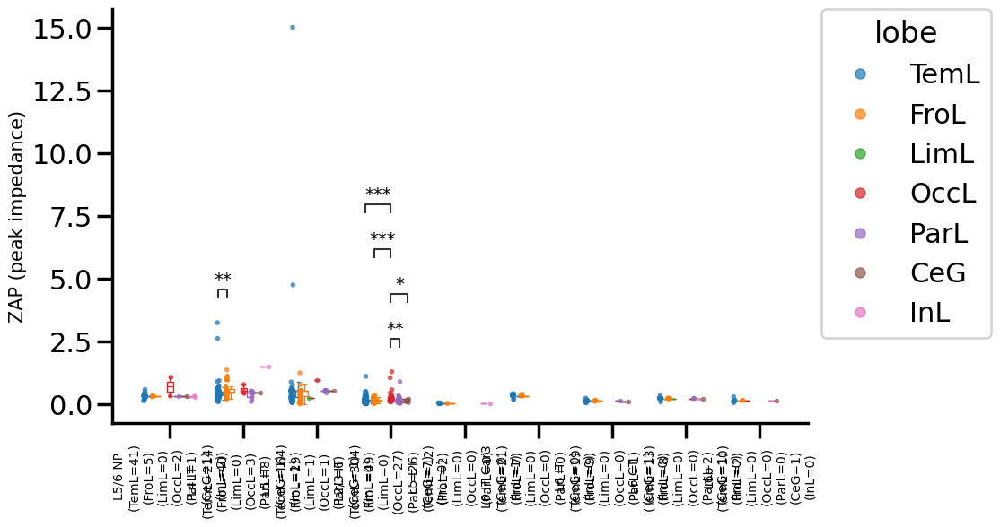

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:1.412e-06
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:7.968e-06
L4 IT_TemL vs. L4 IT_ParL: Custom statistical test, P_val:9.768e-04
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:1.192e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


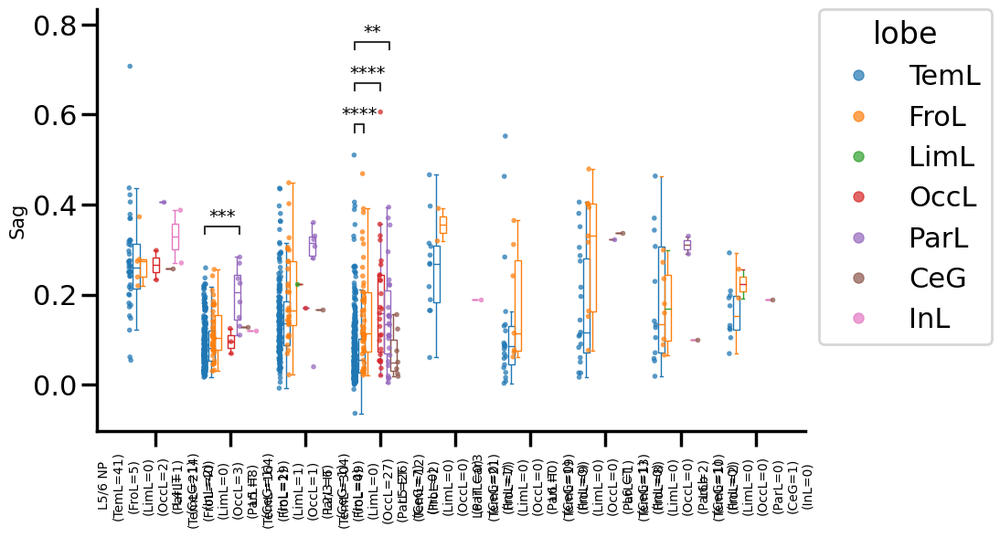

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


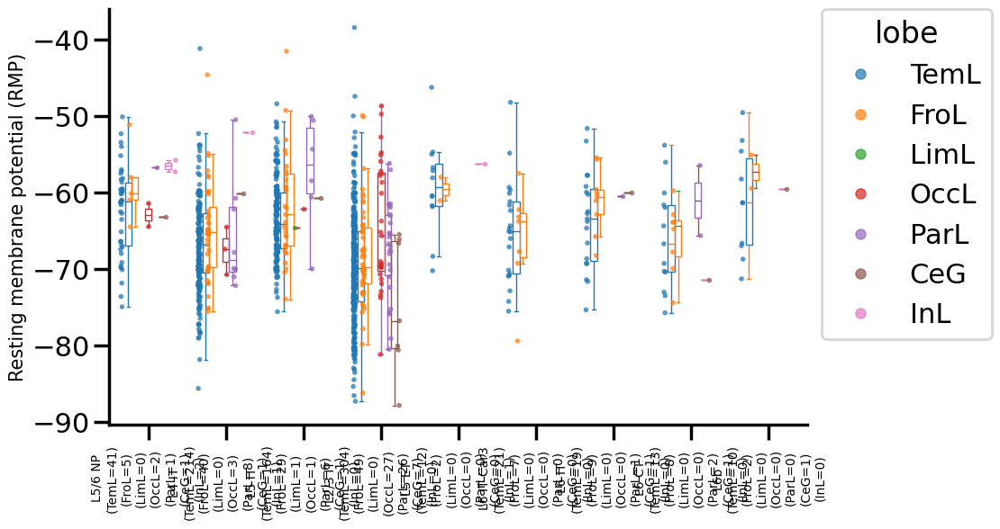

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


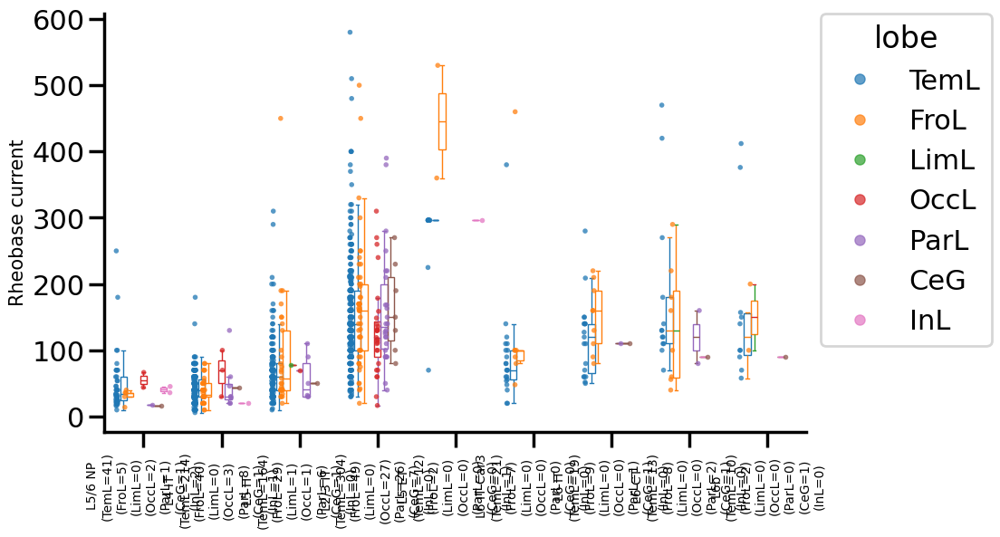

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


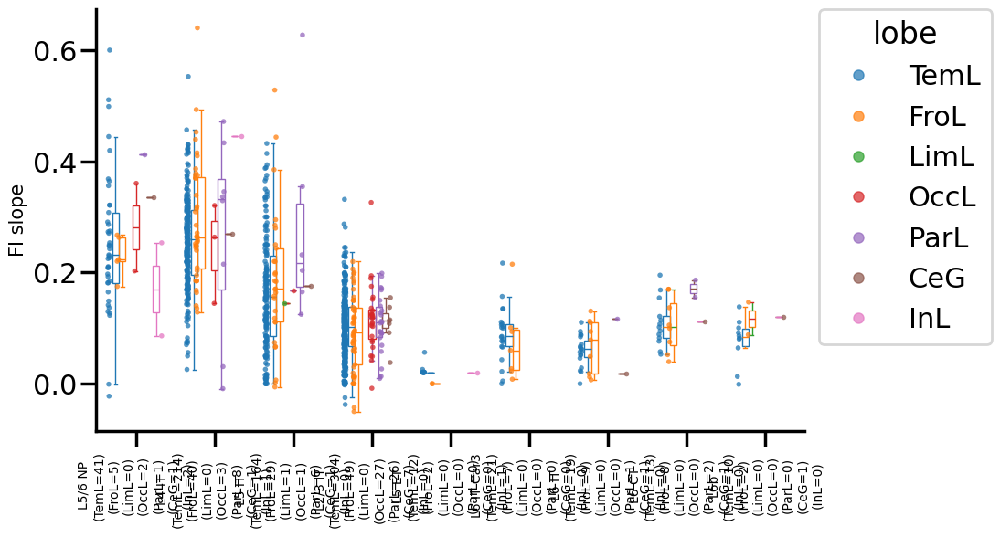

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


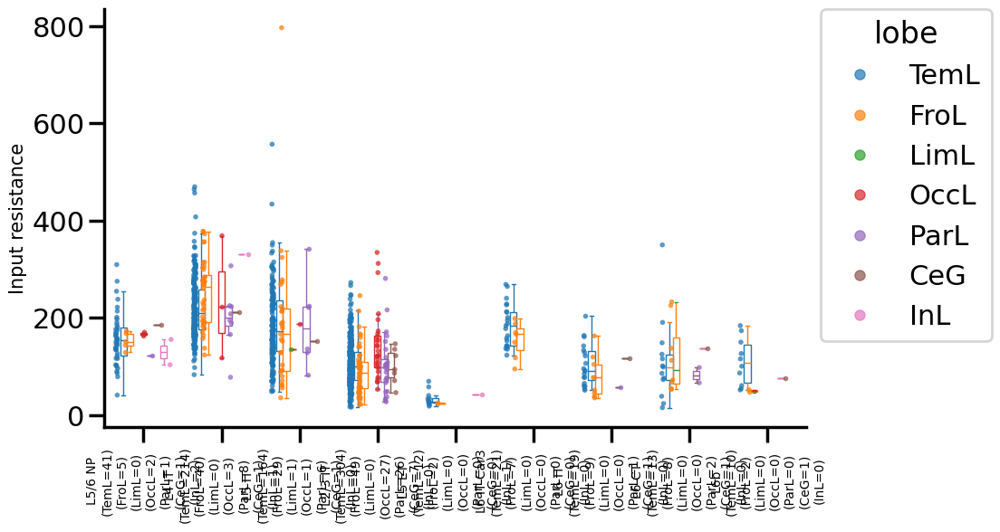

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


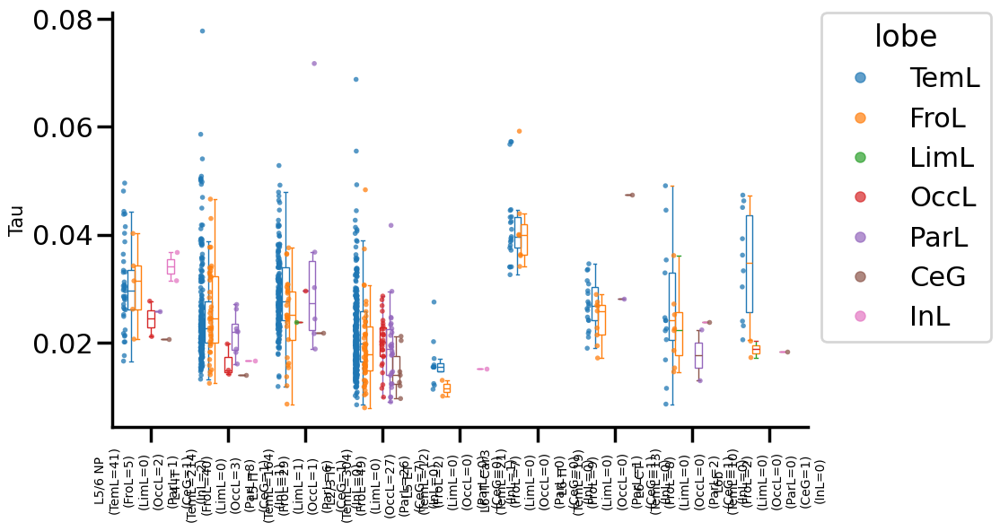

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_ParL: Custom statistical test, P_val:2.130e-02
L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:6.060e-04
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:2.824e-05


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


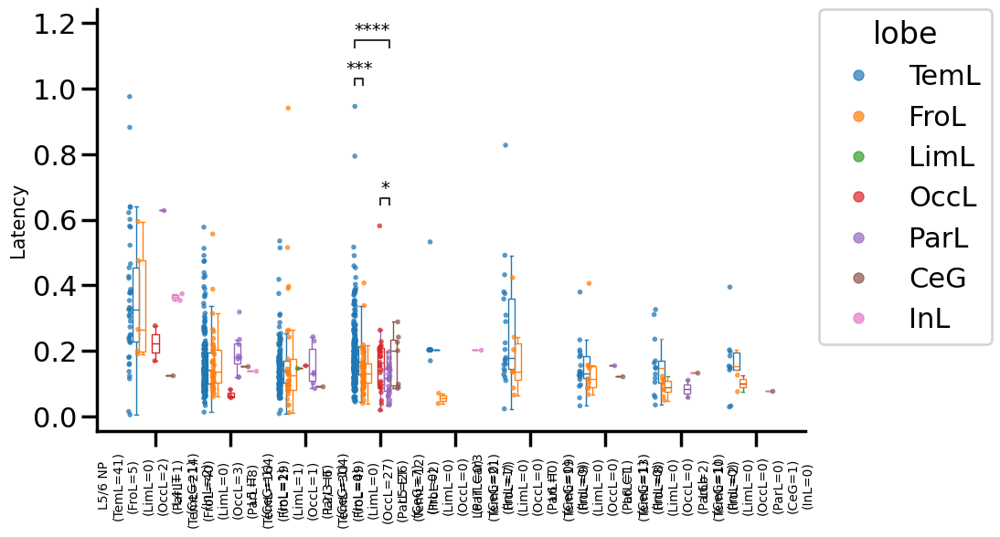

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


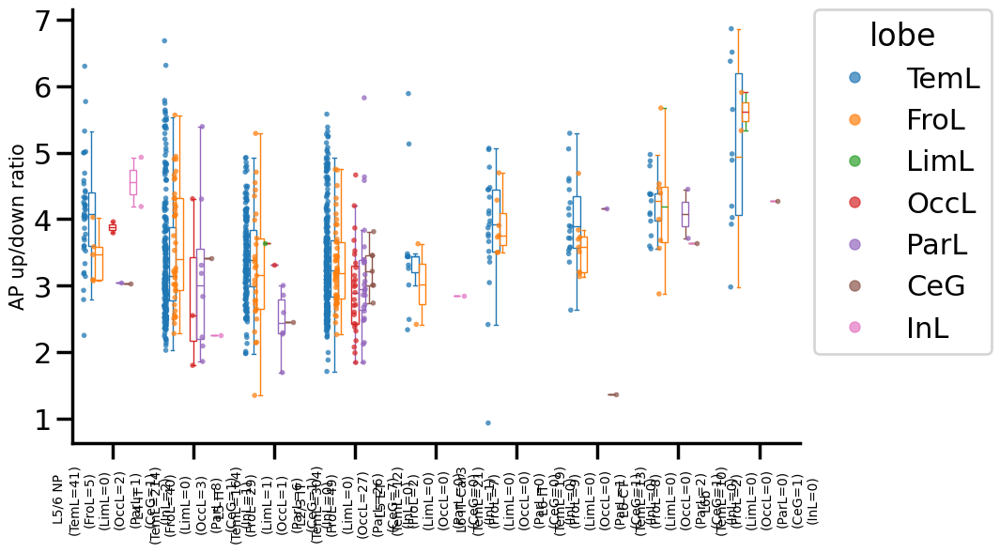

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:1.652e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.386e-03
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.386e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


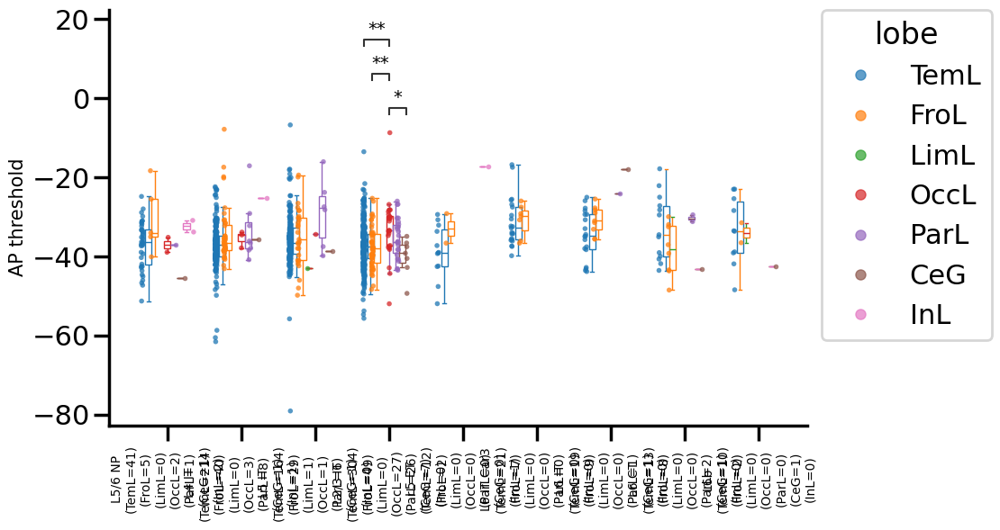

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


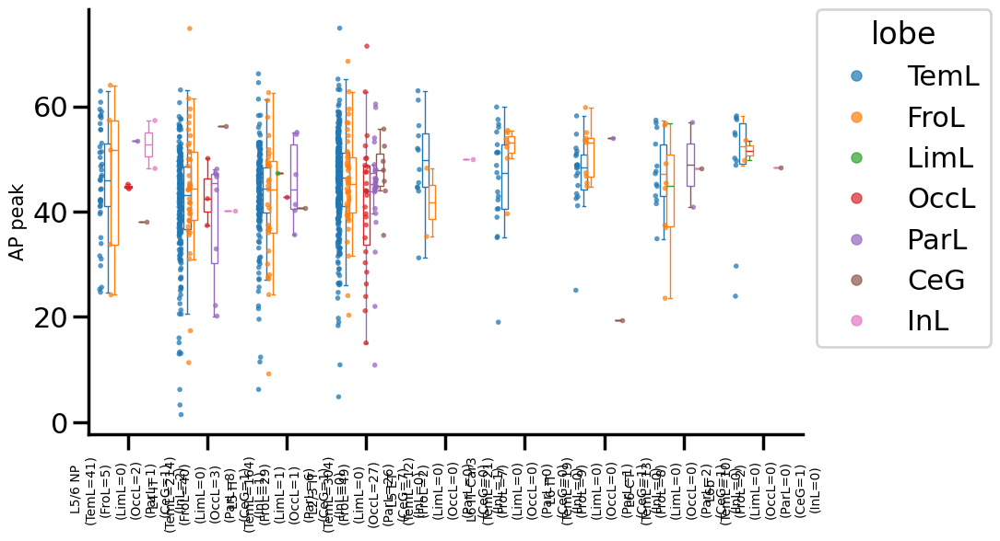

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_ParL: Custom statistical test, P_val:2.412e-02
L2/3 IT_TemL vs. L2/3 IT_FroL: Custom statistical test, P_val:2.412e-02
L4 IT_FroL vs. L4 IT_OccL: Custom statistical test, P_val:4.575e-02
L2/3 IT_TemL vs. L2/3 IT_ParL: Custom statistical test, P_val:6.396e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


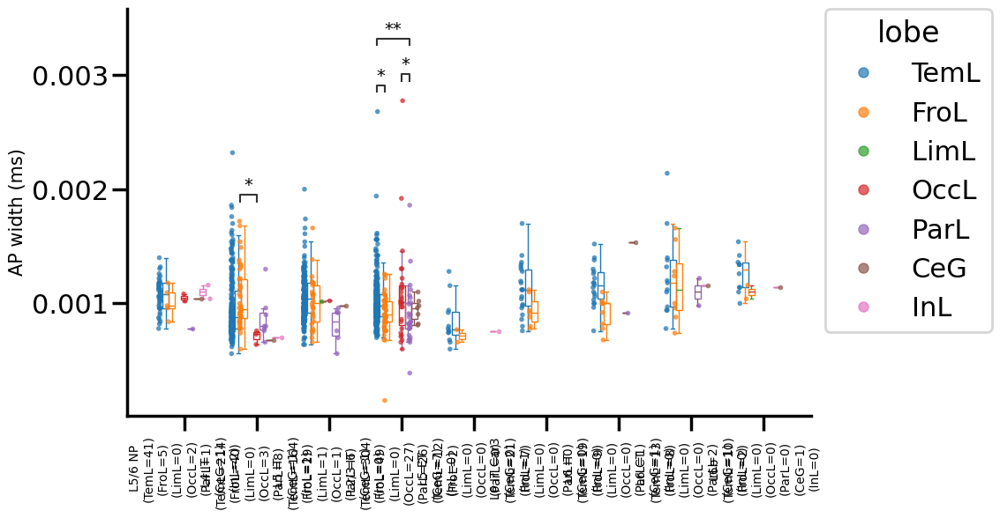

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


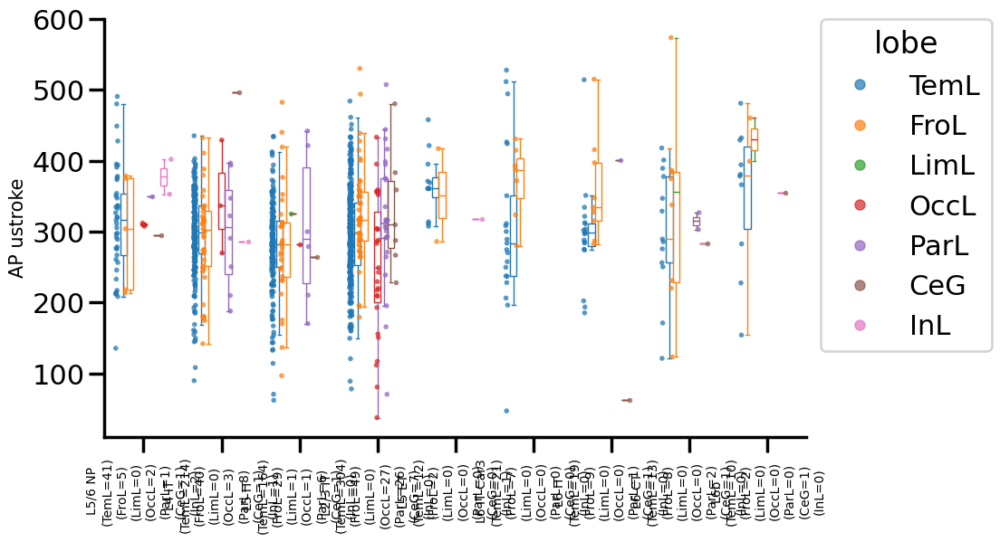

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L6 IT_TemL vs. L6 IT_FroL: Custom statistical test, P_val:7.495e-03
L6 IT_FroL vs. L6 IT_CeG: Custom statistical test, P_val:4.673e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


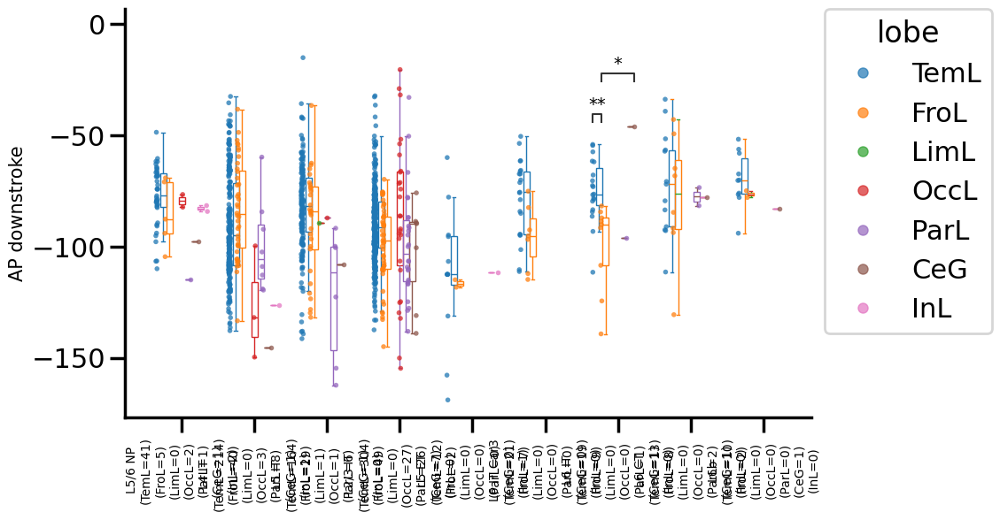

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


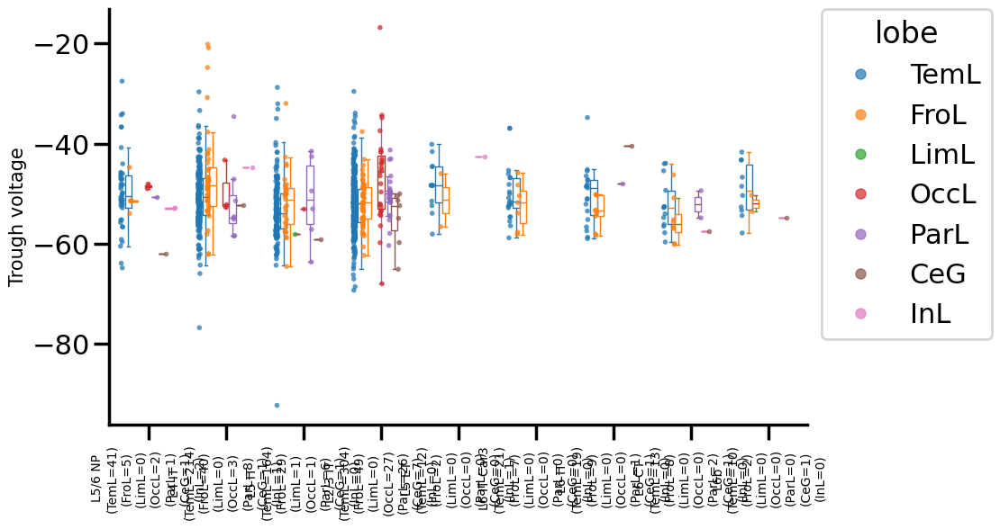

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_ParL vs. L2/3 IT_CeG: Custom statistical test, P_val:3.273e-02
L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:1.597e-02
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:3.273e-02
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:1.597e-02


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


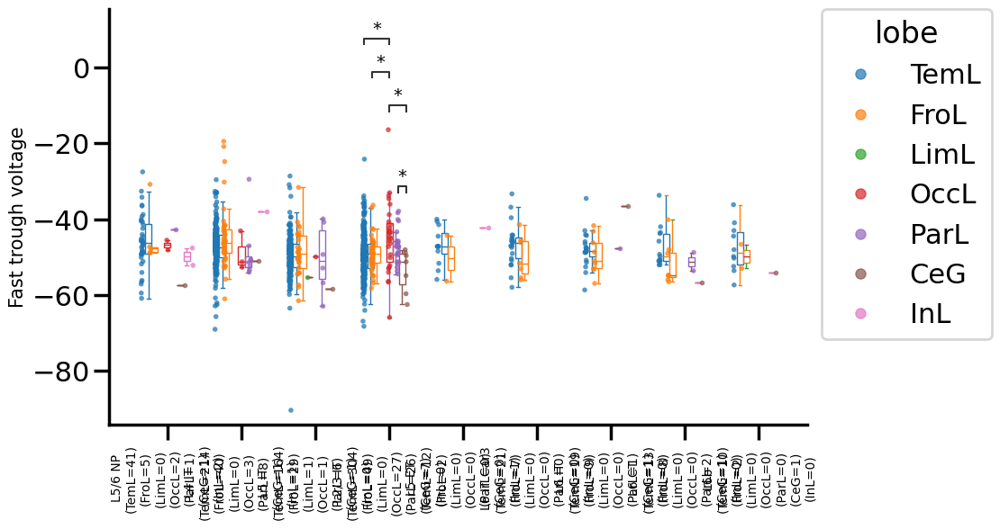

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:5.457e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


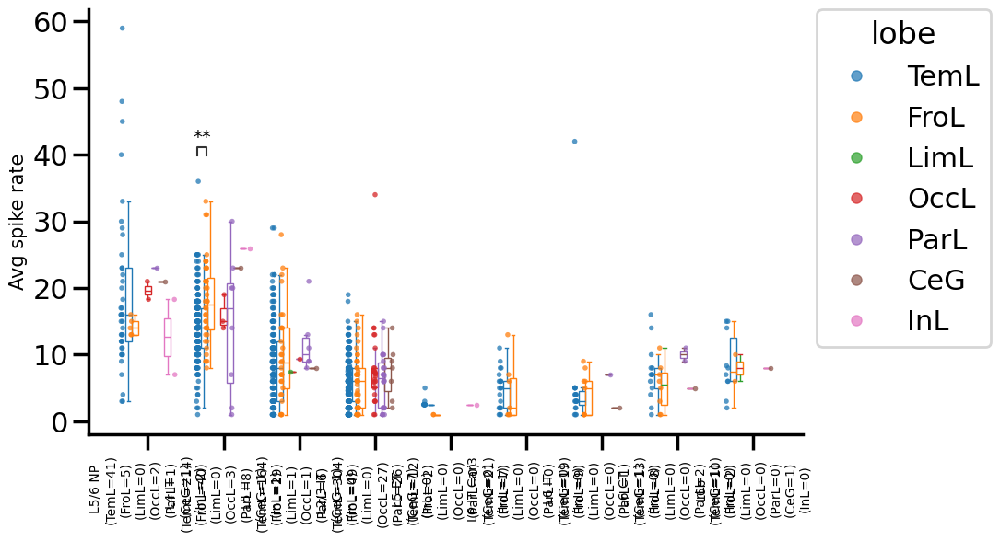

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L4 IT_TemL vs. L4 IT_FroL: Custom statistical test, P_val:5.568e-03


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


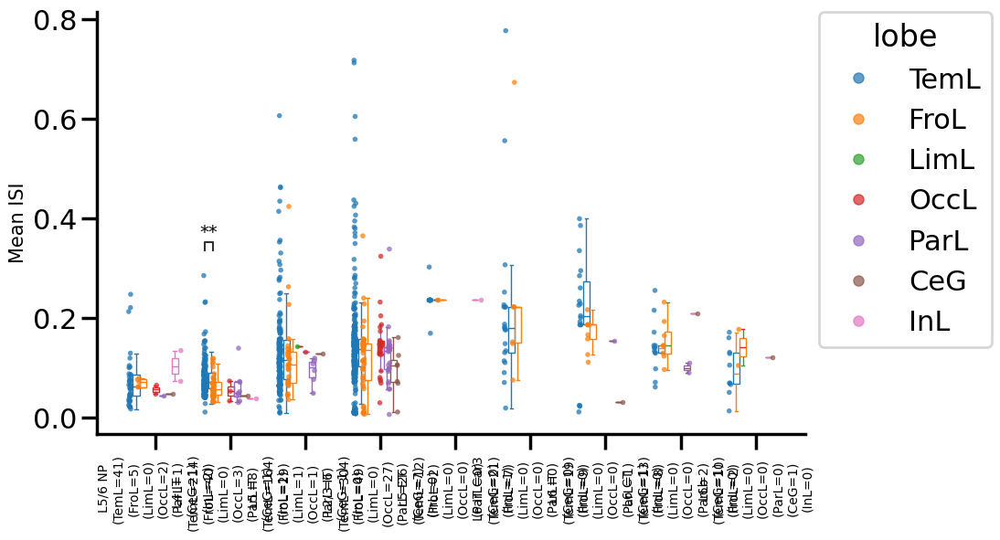

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


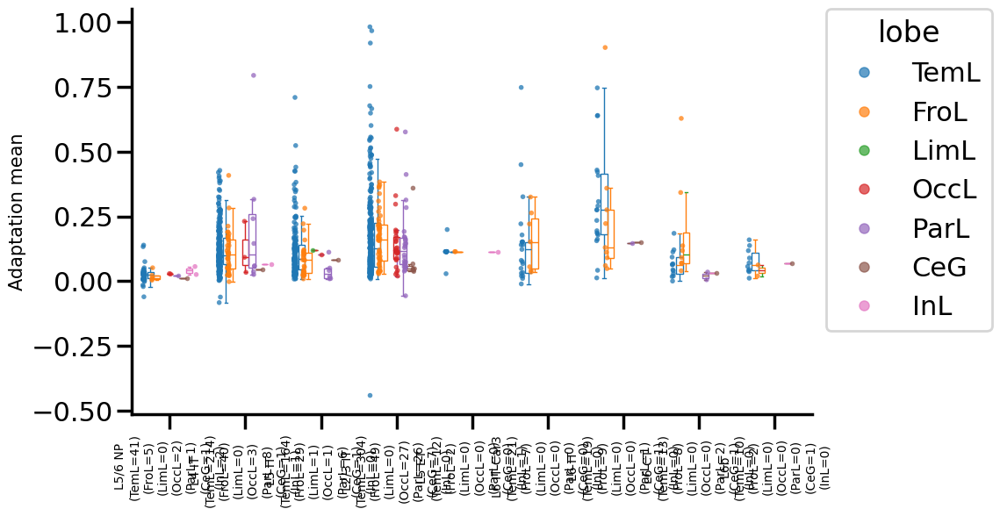

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


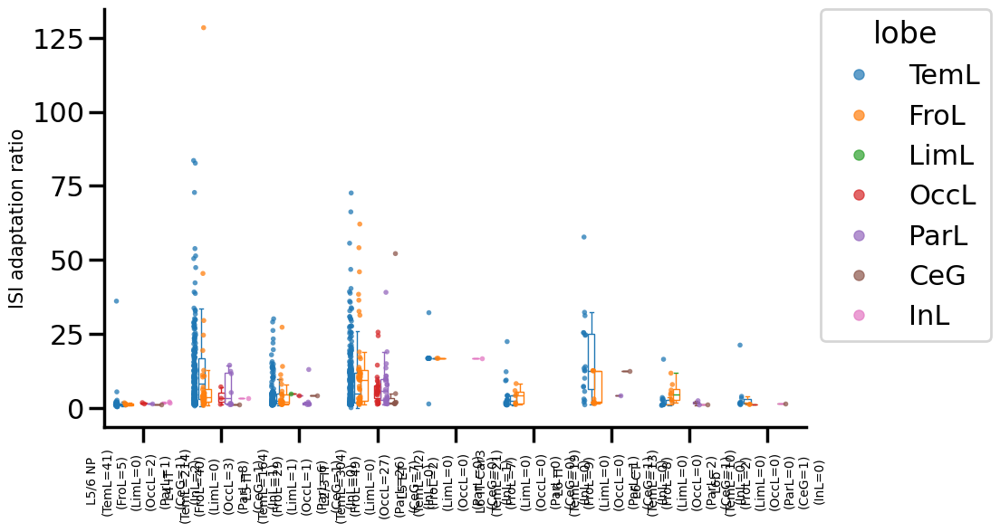

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


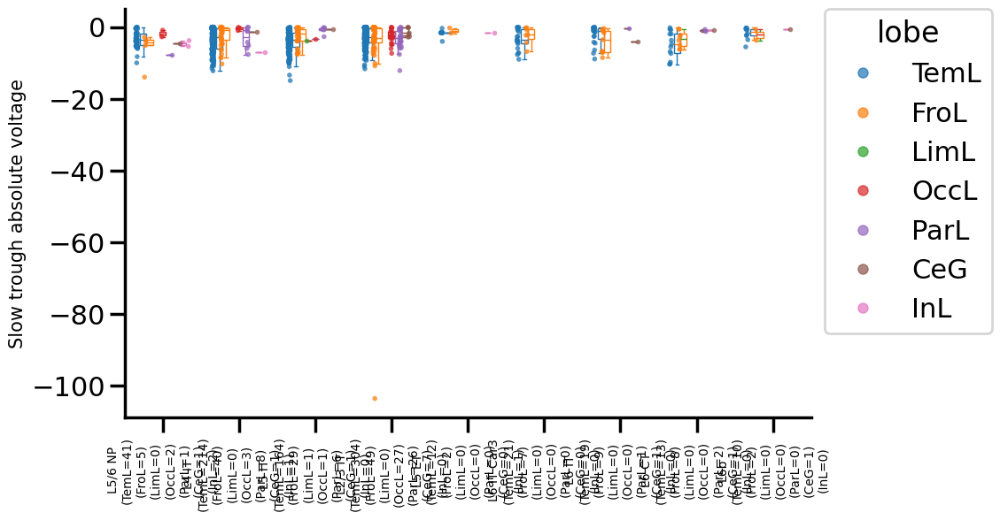

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

L2/3 IT_OccL vs. L2/3 IT_CeG: Custom statistical test, P_val:5.269e-03
L2/3 IT_FroL vs. L2/3 IT_OccL: Custom statistical test, P_val:2.162e-03
L2/3 IT_TemL vs. L2/3 IT_OccL: Custom statistical test, P_val:1.962e-04


/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


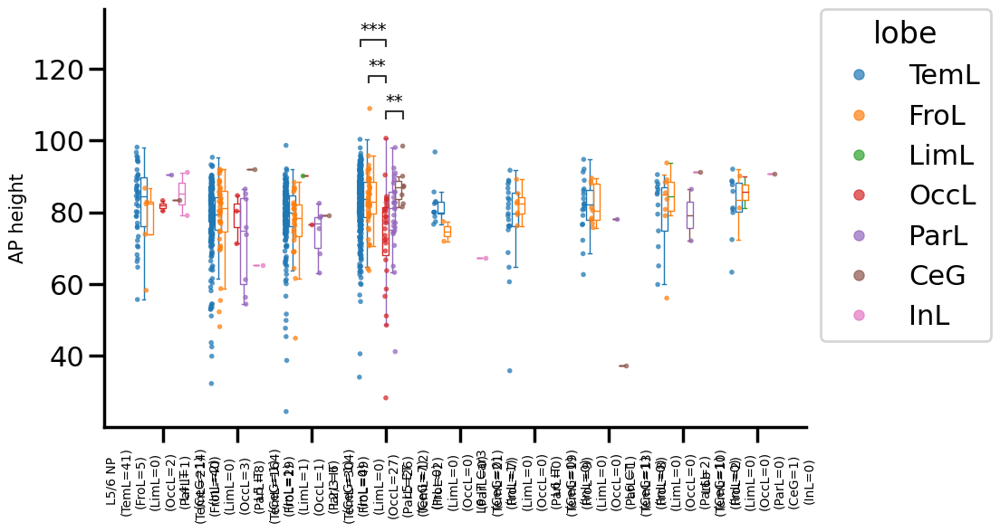

/tmp/ipykernel_1094812/1812076777.py:86: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/1812076777.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


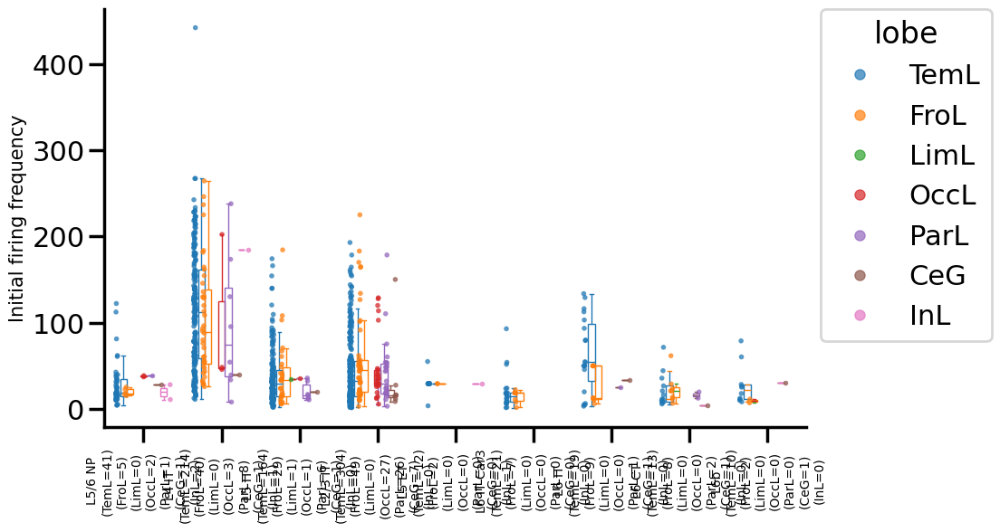

In [47]:
#compute KW - FDR - Dunn stats for all sexes (including unknown)

x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()
group_var = 'lobe'
group_order = sorted_clean_data[group_var].unique().tolist()
features = feature_cols.copy()

kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected, dunn_tables = compute_kw_stats(sorted_clean_data, x_var, x_var_order, group_var, group_order, features)

#save stats
kw_stats_df = get_kw_stats_df(kw_hvals, kw_pvals, kw_pvals_fdr, kw_rejected)
kw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.csv'), index=False)

dunn_stats_df = get_dunn_stats_df(dunn_tables)
dunn_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_Dunn_pairs.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_KW_Dunn_FDR.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette =  sns.color_palette("tab10", n_colors=len(group_order)) #color_dicts[hue_var]
plot_box_plots_with_kw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group_order, palette, dunn_tables, figsize=(10,6))


#### *group non-TemL as `Other`

1044


/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, alpha=0.25, dodge=True, size=5)
/tmp/ipykernel_1094812/2125135880.py:26: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  sns.boxplot(data=this_sorted_clean_data, x=x_var, y=y_var, hue=hue_var, palette=palette, order=x_order, saturation=1, linewidth=2, width=0.6, showfliers = False, legend=False)
/tmp/ipykernel_1094812/2125135880.py:69: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(new_x_tick_labels)
/tmp/ipykernel_1094812/2125135880.py:25: UserWarning: The palette list has more values (8) than needed (2), which may not be intended.
  strip = sns.stripplot(data=this_sorted_clean_data, x=x_var

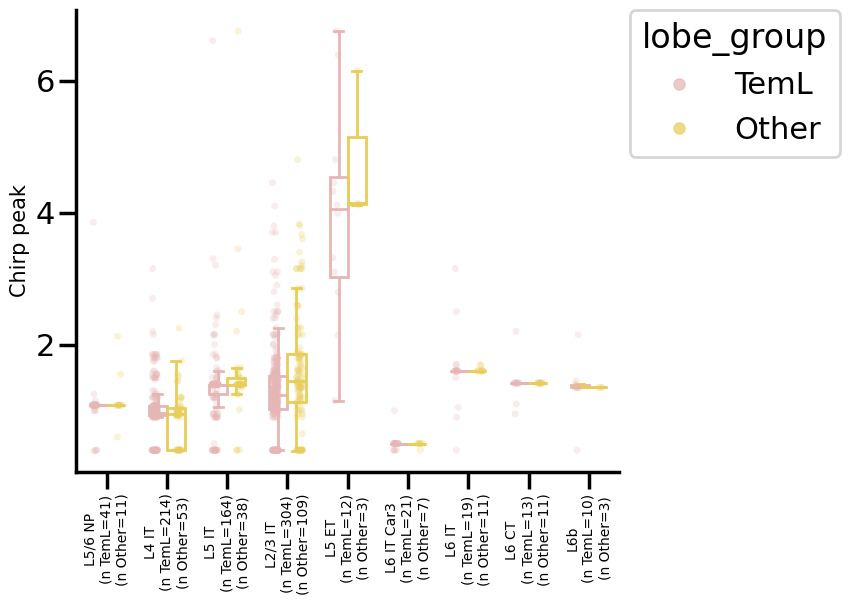

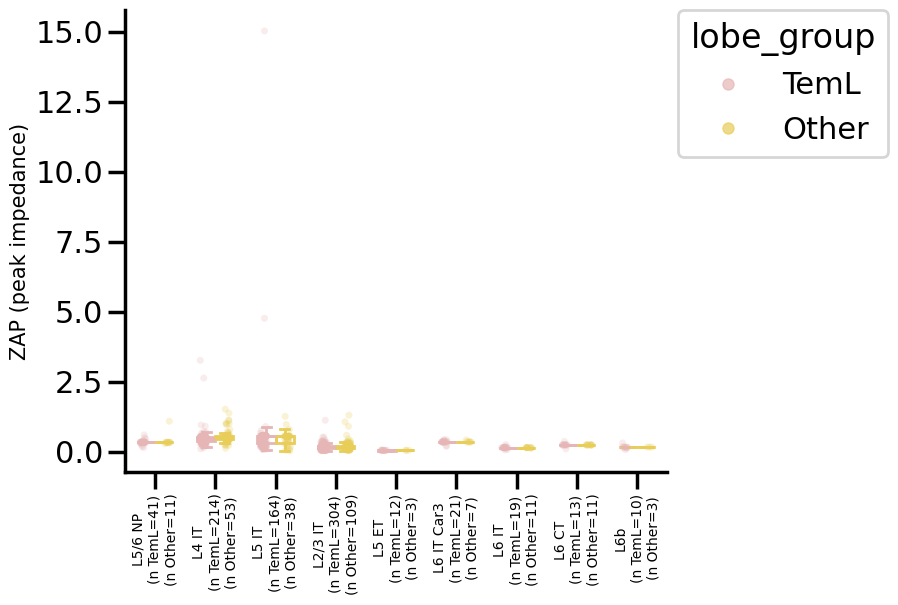

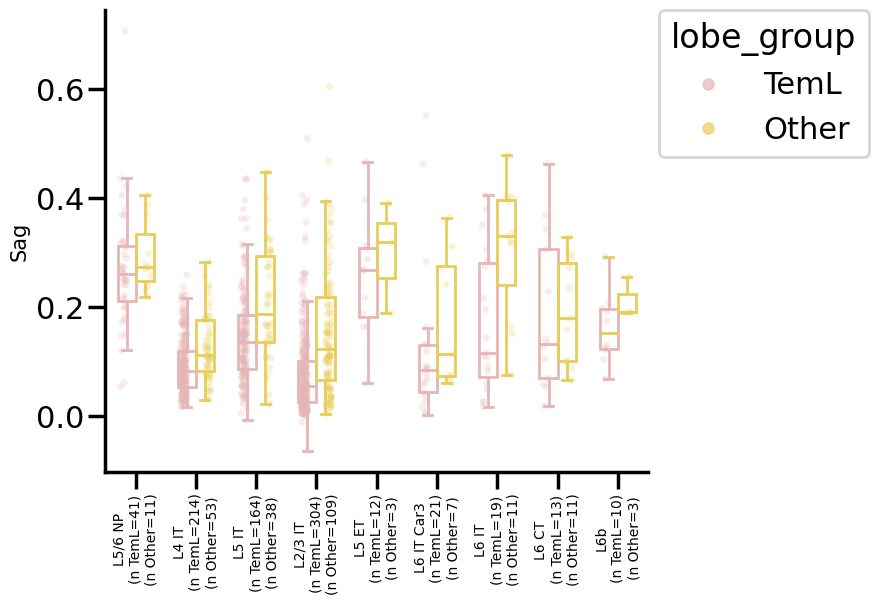

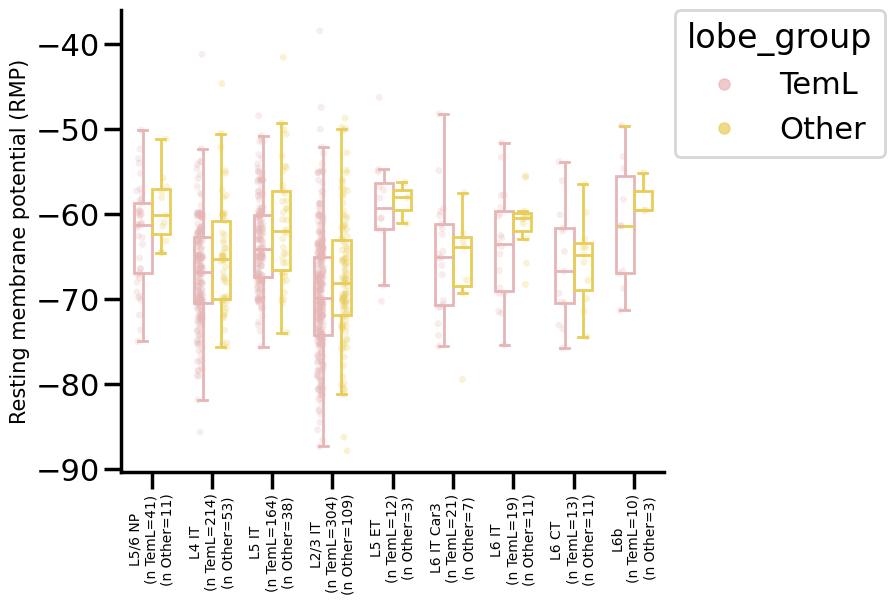

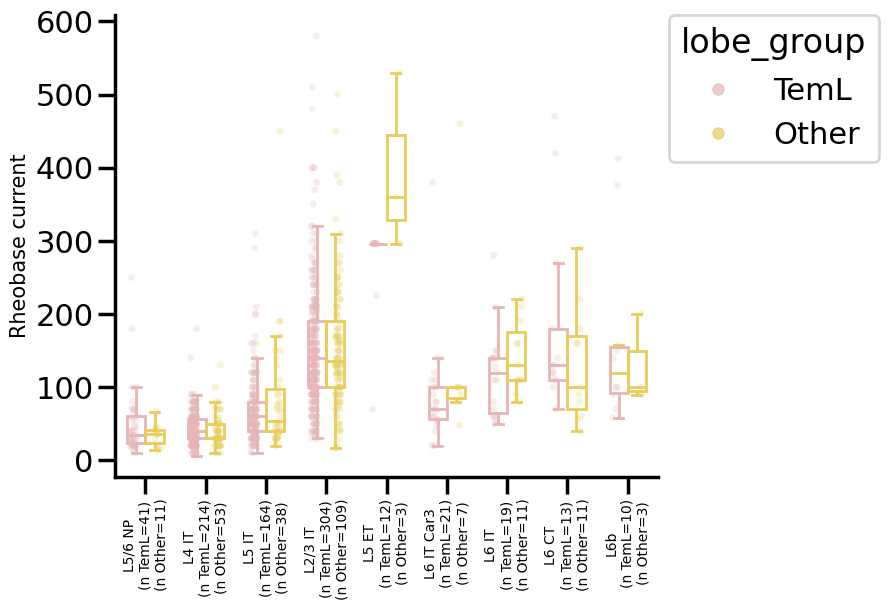

...

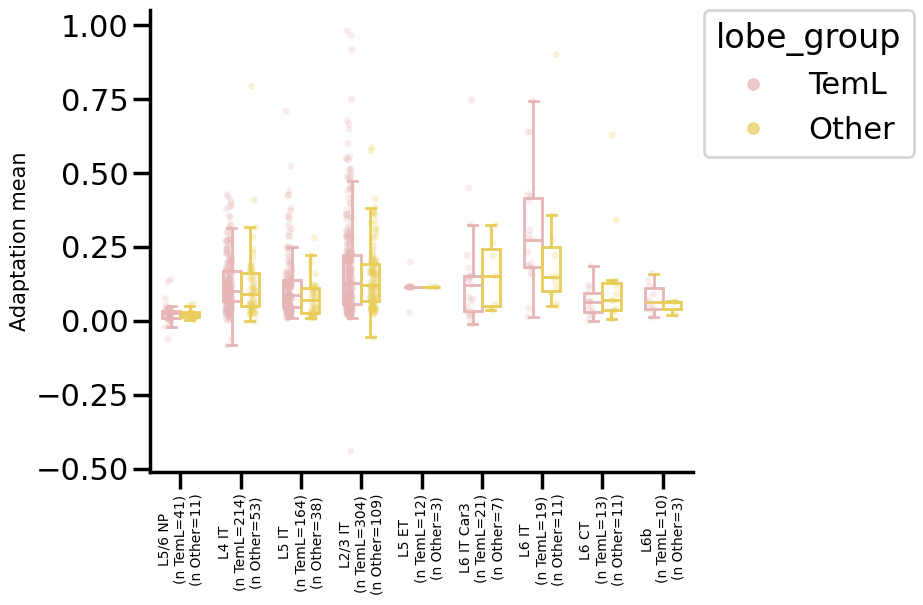

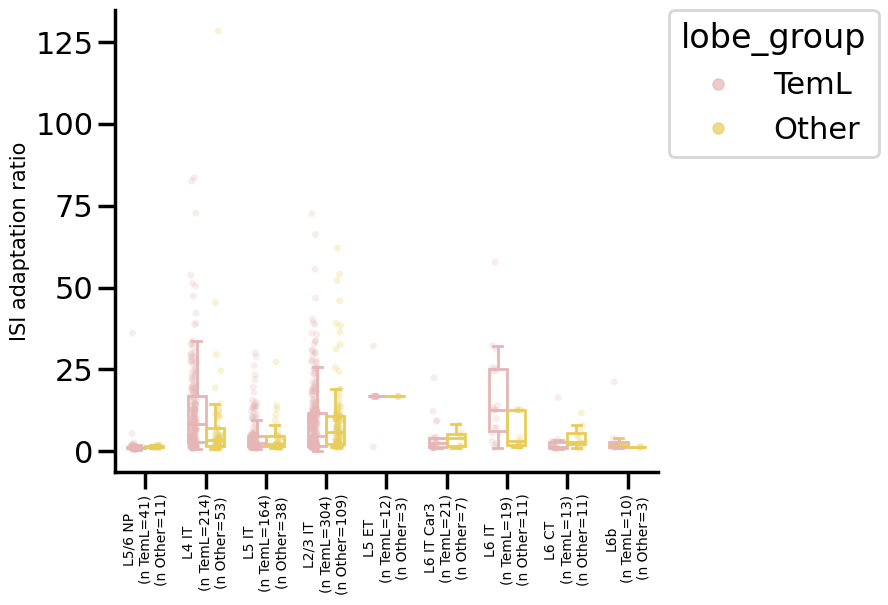

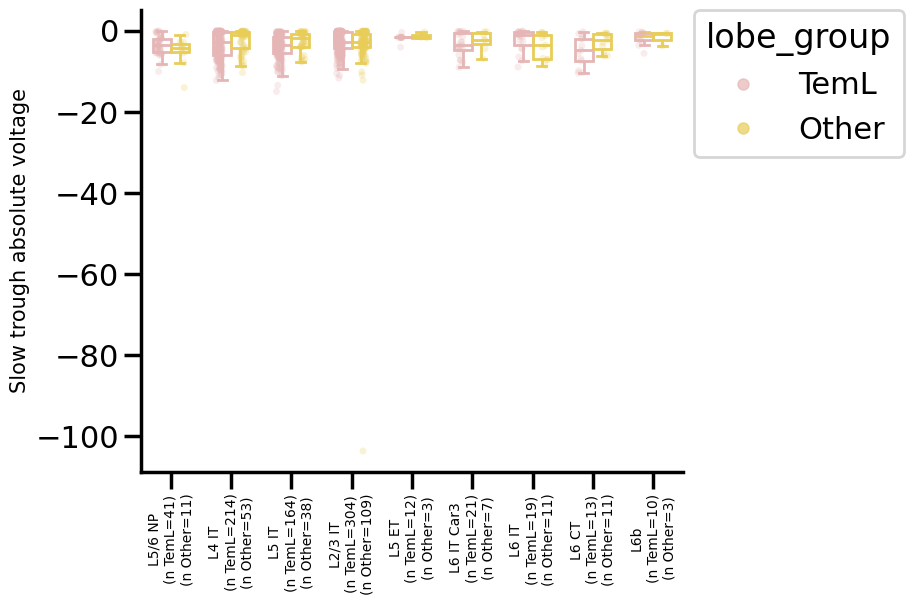

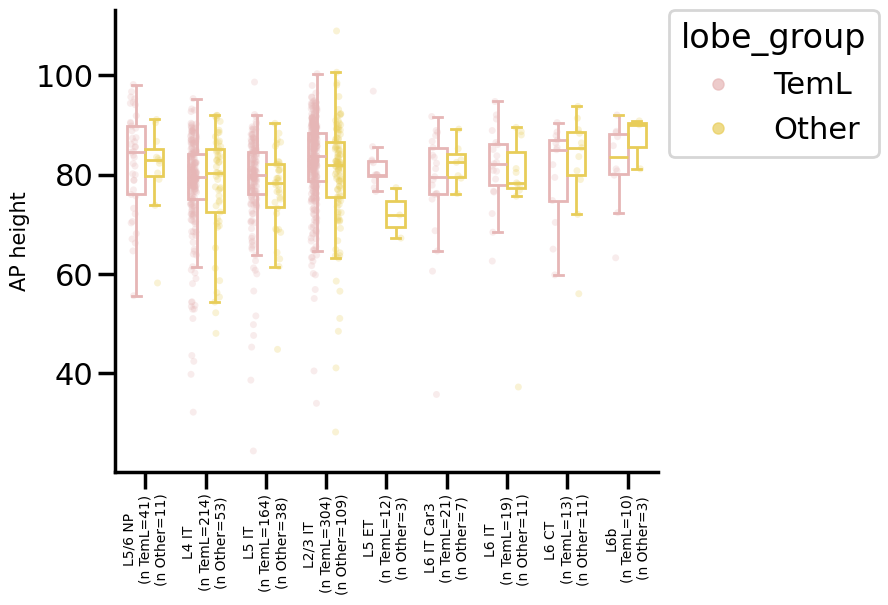

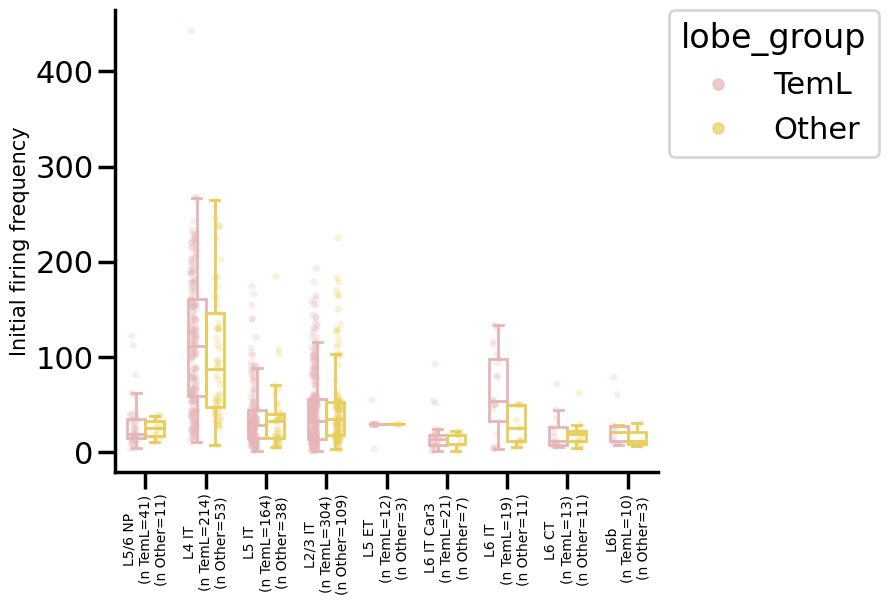

In [48]:
#compute MW - FDR stats for F and M sexes only 
x_var = 'subclass_label'
x_var_order = sorted_clean_data[x_var].unique().tolist()

group_var = 'lobe_group'
group1_label = 'TemL'
group2_label = 'Other'
suffix = '_groupNonTemL'
features = feature_cols.copy()
mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected = compute_mw_stats(sorted_clean_data, x_var, group1_label, group2_label, group_var, features)

#save stats
mw_stats_df = get_mw_stats_df(mw_stats, mw_pvals, mw_pvals_fdr, mw_rejected)
mw_stats_df.to_csv(os.path.join(output_dir, f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.csv'), index=False)

#plot box plots
fig_name = f'ephys_feature_box_plot_stats_{group_var}_{x_var}_MW_FDR{suffix}.pdf'
fig_path = os.path.join(output_dir, fig_name)
palette = list(color_dicts[group_var].values())
plot_box_plots_with_mw_dunn_stats(fig_path, sorted_clean_data, x_var, x_var_order, features, group_var, group1_label, group2_label, palette, mw_pvals_fdr, mw_rejected)
